<a href="https://www.kaggle.com/code/buiquanghuy2801/01-medvqa-baseline?scriptVersionId=373389820" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:

import torch
import sys

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU count:", torch.cuda.device_count())
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))
        print(
            "VRAM:",
            round(torch.cuda.get_device_properties(i).total_memory / 1024**3, 2),
            "GB"
        )
else:
    print("GPU chưa được kích hoạt!")


In [ ]:

%pip -q install datasets huggingface_hub open_clip_torch


In [ ]:

from datasets import load_dataset

ds = load_dataset("acbbb/SLAKE")

print("Available splits:", list(ds.keys()))

for split in ds.keys():
    print(f"{split}: {len(ds[split])} samples")

print("\nColumns:")
print(ds["train"].column_names)

print("\nFirst sample:")
print(ds["train"][0])


In [ ]:

from collections import Counter

train = ds["train"]
columns = train.column_names

if all(c in columns for c in ["q_lang", "question", "answer"]):
    en = train.filter(
        lambda row: row["q_lang"] == "en"
    )

    print("English training samples:", len(en))

    print("\nExample questions:")
    for row in en.select(range(min(5, len(en)))):
        print("Q:", row["question"])
        print("A:", row["answer"])
        print("---")

    print("\nMost common answers:")
    print(Counter(en["answer"]).most_common(10))
else:
    print("Cần kiểm tra lại tên cột:", columns)


In [ ]:

from collections import Counter

# Kiểm tra các split và cột dữ liệu
for split_name, split in ds.items():
    print(f"\n===== {split_name.upper()} =====")
    print("Rows:", len(split))
    print("Columns:", split.column_names)
    print("First sample:", split[0])

# Tìm cột định danh ảnh
possible_columns = [
    "img_name", "image_id", "img_id", "image"
]

image_col = next(
    (c for c in possible_columns
     if c in ds["train"].column_names),
    None
)

print("\nImage column:", image_col)

# Kiểm tra trùng lặp ảnh giữa các tập
if image_col is not None:
    image_sets = {}

    for split_name, split in ds.items():
        values = split[image_col]

        # Nếu image là đối tượng ảnh/dict,
        # cần xử lý định danh riêng
        if all(isinstance(v, (str, int)) for v in values):
            image_sets[split_name] = set(map(str, values))
            print(
                split_name,
                "unique images:",
                len(image_sets[split_name])
            )

    names = list(image_sets)

    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            overlap = (
                image_sets[names[i]]
                & image_sets[names[j]]
            )
            print(
                f"{names[i]} vs {names[j]}:",
                len(overlap),
                "overlapping images"
            )
else:
    print("Không tìm thấy cột định danh ảnh.")


In [ ]:

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# 1. Gộp metadata của ba split
# Chỉ dùng để tạo giao thức image-disjoint riêng.
dfs = []

for split_name in ds.keys():
    df = ds[split_name].to_pandas()
    df["original_split"] = split_name
    dfs.append(df)

df_all = pd.concat(dfs, ignore_index=True)

# 2. Chỉ lấy câu hỏi tiếng Anh
df_en = df_all[df_all["q_lang"] == "en"].copy()
df_en = df_en.reset_index(drop=True)

# 3. Kiểm tra định danh ảnh
assert df_en["img_name"].notna().all()
print("English QA:", len(df_en))
print("Unique images:", df_en["img_name"].nunique())

# 4. Chia train (70%) và phần còn lại (30%)
splitter1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    splitter1.split(
        df_en,
        groups=df_en["img_name"]
    )
)

train_df = df_en.iloc[train_idx].copy()
temp_df = df_en.iloc[temp_idx].copy()

# 5. Chia validation và test (mỗi phần 15%)
splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    splitter2.split(
        temp_df,
        groups=temp_df["img_name"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# 6. Kiểm tra không có ảnh trùng
train_imgs = set(train_df["img_name"])
val_imgs = set(val_df["img_name"])
test_imgs = set(test_df["img_name"])

assert train_imgs.isdisjoint(val_imgs)
assert train_imgs.isdisjoint(test_imgs)
assert val_imgs.isdisjoint(test_imgs)

# 7. Thống kê
for name, data in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(
        name,
        "| QA:", len(data),
        "| Images:", data["img_name"].nunique()
    )

print("\nSUCCESS: No overlapping images!")


In [ ]:

import os

SAVE_DIR = "/kaggle/working/slake_splits"
os.makedirs(SAVE_DIR, exist_ok=True)

train_df.to_csv(
    f"{SAVE_DIR}/train.csv",
    index=False
)

val_df.to_csv(
    f"{SAVE_DIR}/validation.csv",
    index=False
)

test_df.to_csv(
    f"{SAVE_DIR}/test.csv",
    index=False
)

print("Saved to:", SAVE_DIR)



In [ ]:

from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/buiquanghuy2801/slakedataset")
IMAGE_DIR = DATA_DIR / "Slake1.0"

print("Dataset exists:", DATA_DIR.exists())
print("Image folder exists:", IMAGE_DIR.exists())

image_files = [
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Total image files:", len(image_files))

print("\nFirst 5 images:")
for p in image_files[:5]:
    print(p)


In [ ]:

from pathlib import Path

IMAGE_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0/imgs"
)

print("Image folder:", IMAGE_DIR.exists())

for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    paths = [
        IMAGE_DIR / str(img_name)
        for img_name in df["img_name"]
    ]

    missing = [p for p in paths if not p.is_file()]

    print(
        f"{name}: {len(paths)} QA | "
        f"{len(missing)} missing images"
    )

    if missing:
        print("Example missing:", missing[:3])


In [ ]:

import torch
from torch.utils.data import Dataset
from PIL import Image

class SLAKEDataset(Dataset):
    def __init__(self, dataframe, image_dir):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = self.image_dir / str(row["img_name"])

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        question = str(row["question"])
        answer = str(row["answer"])

        return {
            "image": image,
            "question": question,
            "answer": answer,
            "img_name": str(row["img_name"])
        }

train_dataset = SLAKEDataset(train_df, IMAGE_DIR)
val_dataset = SLAKEDataset(val_df, IMAGE_DIR)
test_dataset = SLAKEDataset(test_df, IMAGE_DIR)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


In [ ]:

import matplotlib.pyplot as plt

sample = train_dataset[0]

print("Question:", sample["question"])
print("Answer:", sample["answer"])
print("Image:", sample["img_name"])
print("Image size:", sample["image"].size)

plt.figure(figsize=(6, 6))
plt.imshow(sample["image"])
plt.axis("off")
plt.title("SLAKE - First Training Sample")
plt.show()


In [ ]:

from torch.utils.data import DataLoader

def simple_collate(batch):
    return {
        "images": [item["image"] for item in batch],
        "questions": [item["question"] for item in batch],
        "answers": [item["answer"] for item in batch],
        "img_names": [item["img_name"] for item in batch]
    }

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    collate_fn=simple_collate
)

batch = next(iter(train_loader))

print("Batch size:", len(batch["images"]))
print("First question:", batch["questions"][0])
print("First answer:", batch["answers"][0])
print("First image size:", batch["images"][0].size)


In [ ]:

import torch
import importlib.util

print("=== GPU CHECK ===")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

print("\n=== LIBRARY CHECK ===")
for lib in ["open_clip", "transformers", "huggingface_hub", "timm"]:
    print(lib, ":", importlib.util.find_spec(lib) is not None)


In [ ]:

import requests

url = (
    "https://huggingface.co/"
    "microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"
    "/resolve/main/open_clip_config.json"
)

try:
    response = requests.get(url, timeout=12)
    print("HTTP status:", response.status_code)
    print("Content type:", response.headers.get("content-type"))

    if response.status_code == 200:
        print("Hugging Face connection: OK")
    else:
        print("Model file cannot be retrieved directly.")

except Exception as e:
    print("Connection failed:", str(e)[:300])


In [ ]:

import importlib.util

libraries = ["open_clip", "transformers", "timm"]

for lib in libraries:
    print(lib, importlib.util.find_spec(lib) is not None)


In [ ]:

import torch
import open_clip

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


In [ ]:

import torch
import open_clip

MODEL_ID = (
    "hf-hub:microsoft/"
    "BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Tải pretrained model và bộ tiền xử lý
model, preprocess_train, preprocess_val = (
    open_clip.create_model_and_transforms(MODEL_ID)
)

# Tải tokenizer
tokenizer = open_clip.get_tokenizer(MODEL_ID)

# Chuyển model sang GPU và đóng băng
model = model.to(device).eval()

for param in model.parameters():
    param.requires_grad = False

print("BiomedCLIP loaded successfully!")
print("Device:", device)
print("Parameters frozen:",
      all(not p.requires_grad for p in model.parameters()))


In [ ]:

# Lấy mẫu đầu tiên
sample = train_dataset[0]

image = sample["image"]
question = sample["question"]
answer = sample["answer"]

# Tiền xử lý ảnh và câu hỏi
image_tensor = (
    preprocess_val(image)
    .unsqueeze(0)
    .to(device)
)

text_tokens = tokenizer([question]).to(device)

# Trích xuất embeddings
with torch.inference_mode():
    image_features = model.encode_image(image_tensor)
    text_features = model.encode_text(text_tokens)

print("Question:", question)
print("Ground truth answer:", answer)
print("Image tensor:", image_tensor.shape)
print("Image embedding:", image_features.shape)
print("Text embedding:", text_features.shape)


In [ ]:

from collections import Counter

def normalize_answer(answer):
    return str(answer).strip().lower()

answer_counts = Counter(
    normalize_answer(a)
    for a in train_df["answer"]
)

# Ban đầu giữ toàn bộ đáp án xuất hiện trong Train
answer2id = {
    answer: idx
    for idx, answer in enumerate(sorted(answer_counts))
}

id2answer = {
    idx: answer
    for answer, idx in answer2id.items()
}

print("Number of answer classes:", len(answer2id))
print("Top 10 answers:", answer_counts.most_common(10))

for name, df in [("Validation", val_df), ("Test", test_df)]:
    unknown = sum(
        normalize_answer(a) not in answer2id
        for a in df["answer"]
    )
    print(
        f"{name} unseen answers: {unknown}/{len(df)} "
        f"({unknown/len(df):.1%})"
    )


In [ ]:

import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

def extract_embeddings(dataset, batch_size=16):
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        collate_fn=simple_collate
    )

    image_features_all = []
    text_features_all = []
    answers_all = []

    model.eval()

    with torch.inference_mode():
        for batch in tqdm(loader):
            images = torch.stack([
                preprocess_val(img)
                for img in batch["images"]
            ]).to(device)

            texts = tokenizer(
                batch["questions"]
            ).to(device)

            img_features = model.encode_image(images)
            txt_features = model.encode_text(texts)

            image_features_all.append(
                img_features.float().cpu()
            )

            text_features_all.append(
                txt_features.float().cpu()
            )

            answers_all.extend([
                normalize_answer(a)
                for a in batch["answers"]
            ])

    return {
        "image": torch.cat(image_features_all),
        "text": torch.cat(text_features_all),
        "answers": answers_all
    }

train_features = extract_embeddings(train_dataset)
val_features = extract_embeddings(val_dataset)
test_features = extract_embeddings(test_dataset)

print("Train image:", train_features["image"].shape)
print("Train text:", train_features["text"].shape)
print("Validation:", val_features["image"].shape)
print("Test:", test_features["image"].shape)


In [ ]:

from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/medvqa")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "train": train_features,
        "validation": val_features,
        "test": test_features,
        "answer2id": answer2id,
        "id2answer": id2answer
    },
    OUTPUT_DIR / "biomedclip_embeddings.pt"
)

print("Embeddings saved!")
print("Path:", OUTPUT_DIR / "biomedclip_embeddings.pt")


In [ ]:

import torch.nn as nn
import torch.nn.functional as F

class MedVQAClassifier(nn.Module):
    def __init__(self, num_answers, embed_dim=512):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(embed_dim * 3, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_answers)
        )

    def forward(self, image_features, text_features):
        image_features = F.normalize(image_features, dim=-1)
        text_features = F.normalize(text_features, dim=-1)

        fused = torch.cat([
            image_features,
            text_features,
            image_features * text_features
        ], dim=-1)

        return self.classifier(fused)

classifier = MedVQAClassifier(
    num_answers=len(answer2id)
).to(device)

print(classifier)
print(
    "Trainable parameters:",
    sum(p.numel() for p in classifier.parameters())
)


In [ ]:

def prepare_features(features, answer2id):
    x_img = features["image"]
    x_txt = features["text"]

    labels = torch.tensor([
        answer2id.get(a, -1)
        for a in features["answers"]
    ], dtype=torch.long)

    return x_img, x_txt, labels

X_train_img, X_train_txt, y_train = prepare_features(
    train_features, answer2id
)

X_val_img, X_val_txt, y_val = prepare_features(
    val_features, answer2id
)

print("Train labels:", y_train.shape)
print("Unknown train labels:", (y_train == -1).sum().item())
print("Unknown val labels:", (y_val == -1).sum().item())


In [ ]:

from torch.utils.data import TensorDataset, DataLoader
import copy

train_tensor_ds = TensorDataset(
    X_train_img, X_train_txt, y_train
)

train_feature_loader = DataLoader(
    train_tensor_ds,
    batch_size=64,
    shuffle=True
)

optimizer = torch.optim.AdamW(
    classifier.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()

best_val_acc = -1
best_state = None

for epoch in range(20):
    classifier.train()
    total_loss = 0

    for img, txt, labels in train_feature_loader:
        img = img.to(device)
        txt = txt.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = classifier(img, txt)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    classifier.eval()

    with torch.no_grad():
        val_logits = classifier(
            X_val_img.to(device),
            X_val_txt.to(device)
        )
        predictions = val_logits.argmax(dim=-1).cpu()

        val_acc = (
            (predictions == y_val).float().mean().item()
        )

    train_loss = total_loss / len(train_tensor_ds)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(classifier.state_dict())

classifier.load_state_dict(best_state)

torch.save(
    {
        "model_state_dict": best_state,
        "answer2id": answer2id,
        "best_val_accuracy": best_val_acc
    },
    OUTPUT_DIR / "baseline_classifier.pt"
)

print("\nBest Validation Accuracy:", best_val_acc)
print("Checkpoint saved!")


In [ ]:

import torch
import torch.nn as nn

class LanguageOnlyClassifier(nn.Module):
    def __init__(self, num_answers, embed_dim=512):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(embed_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_answers)
        )

    def forward(self, text_features):
        text_features = nn.functional.normalize(
            text_features, dim=-1
        )
        return self.net(text_features)

lang_model = LanguageOnlyClassifier(
    num_answers=len(answer2id)
).to(device)

print("Language-only parameters:",
      sum(p.numel() for p in lang_model.parameters()))


In [ ]:

import copy
from torch.utils.data import TensorDataset, DataLoader

lang_train_ds = TensorDataset(
    X_train_txt, y_train
)

lang_train_loader = DataLoader(
    lang_train_ds,
    batch_size=64,
    shuffle=True
)

optimizer_lang = torch.optim.AdamW(
    lang_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()

best_lang_acc = -1
best_lang_state = None
patience = 5
wait = 0

for epoch in range(30):
    lang_model.train()
    total_loss = 0

    for txt, labels in lang_train_loader:
        txt = txt.to(device)
        labels = labels.to(device)

        optimizer_lang.zero_grad()
        logits = lang_model(txt)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer_lang.step()

        total_loss += loss.item() * len(labels)

    lang_model.eval()

    with torch.no_grad():
        val_logits = lang_model(X_val_txt.to(device))
        val_pred = val_logits.argmax(dim=-1).cpu()
        val_acc = (val_pred == y_val).float().mean().item()

    train_loss = total_loss / len(lang_train_ds)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

    if val_acc > best_lang_acc:
        best_lang_acc = val_acc
        best_lang_state = copy.deepcopy(
            lang_model.state_dict()
        )
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        print("Early stopping!")
        break

lang_model.load_state_dict(best_lang_state)

print("\nBest Language-only Accuracy:", best_lang_acc)


In [ ]:

print("=== BASELINE COMPARISON ===")

print(f"Full Med-VQA: {best_val_acc:.2%}")
print(f"Language-only: {best_lang_acc:.2%}")

gap = best_val_acc - best_lang_acc

print(f"Accuracy gap: {gap*100:.2f} percentage points")

if gap > 0:
    print("Full model performs better than language-only.")
elif gap < 0:
    print("Language-only performs better than full model.")
else:
    print("Both models have equal validation accuracy.")


In [ ]:

import torch
import torch.nn.functional as F

classifier.eval()

X_val_img_gpu = X_val_img.to(device)
X_val_txt_gpu = X_val_txt.to(device)

with torch.inference_mode():
    original_logits = classifier(
        X_val_img_gpu,
        X_val_txt_gpu
    )

    original_pred = original_logits.argmax(dim=-1).cpu()

original_acc = (
    (original_pred == y_val).float().mean().item()
)

print(f"Original Accuracy: {original_acc:.4f}")


In [ ]:

import numpy as np

rng = np.random.default_rng(42)

# Image names phải cùng thứ tự với val_features
names = val_df["img_name"].astype(str).tolist()
unique_names = np.array(sorted(set(names)))

# Tạo ánh xạ ảnh -> ảnh khác
permutation = rng.permutation(len(unique_names))

# Tránh ảnh bị tráo thành chính nó
if np.any(permutation == np.arange(len(unique_names))):
    permutation = np.roll(
        np.arange(len(unique_names)), 1
    )

mapping = dict(zip(
    unique_names,
    unique_names[permutation]
))

# Lấy embedding đại diện cho mỗi ảnh
name_to_idx = {}

for idx, name in enumerate(names):
    if name not in name_to_idx:
        name_to_idx[name] = idx

shuffled_indices = [
    name_to_idx[mapping[name]]
    for name in names
]

X_val_img_shuffled = X_val_img[
    shuffled_indices
].to(device)

with torch.inference_mode():
    shuffled_logits = classifier(
        X_val_img_shuffled,
        X_val_txt_gpu
    )

    shuffled_pred = shuffled_logits.argmax(dim=-1).cpu()

shuffled_acc = (
    (shuffled_pred == y_val).float().mean().item()
)

print(f"Shuffled Image Accuracy: {shuffled_acc:.4f}")


In [ ]:

with torch.inference_mode():
    zero_logits = classifier(
        torch.zeros_like(X_val_img_gpu),
        X_val_txt_gpu
    )

    zero_pred = zero_logits.argmax(dim=-1).cpu()

zero_acc = (
    (zero_pred == y_val).float().mean().item()
)

print(f"Zero Image Accuracy: {zero_acc:.4f}")


In [ ]:

print("=== VISUAL SENSITIVITY TEST ===")

print(f"Original:       {original_acc:.2%}")
print(f"Shuffled Image: {shuffled_acc:.2%}")
print(f"Zero Image:     {zero_acc:.2%}")

print(
    "Shuffled drop:",
    f"{(original_acc-shuffled_acc)*100:.2f} pp"
)

print(
    "Zero drop:",
    f"{(original_acc-zero_acc)*100:.2f} pp"
)

print(
    "Prediction change (shuffled):",
    f"{(original_pred != shuffled_pred).float().mean():.2%}"
)

print(
    "Prediction change (zero):",
    f"{(original_pred != zero_pred).float().mean():.2%}"
)


In [ ]:

print("Content types:")
print(val_df["content_type"].value_counts())

print("\nAnswer types:")
print(val_df["answer_type"].value_counts())


In [ ]:

import pandas as pd
import numpy as np

# Bảo đảm nhãn và dự đoán cùng thứ tự validation
assert len(val_df) == len(y_val)
assert len(original_pred) == len(y_val)
assert len(shuffled_pred) == len(y_val)
assert len(zero_pred) == len(y_val)

results_df = val_df.reset_index(drop=True).copy()

results_df["correct_original"] = (
    original_pred.numpy() == y_val.numpy()
)

results_df["correct_shuffled"] = (
    shuffled_pred.numpy() == y_val.numpy()
)

results_df["correct_zero"] = (
    zero_pred.numpy() == y_val.numpy()
)

summary = (
    results_df.groupby("content_type")
    .agg(
        samples=("correct_original", "size"),
        original_acc=("correct_original", "mean"),
        shuffled_acc=("correct_shuffled", "mean"),
        zero_acc=("correct_zero", "mean")
    )
    .reset_index()
)

summary["shuffled_drop"] = (
    summary["original_acc"] - summary["shuffled_acc"]
)

summary["zero_drop"] = (
    summary["original_acc"] - summary["zero_acc"]
)

percentage_cols = [
    "original_acc",
    "shuffled_acc",
    "zero_acc",
    "shuffled_drop",
    "zero_drop"
]

summary[percentage_cols] = (
    summary[percentage_cols] * 100
).round(2)

print(summary.to_string(index=False))


In [ ]:

answer_summary = (
    results_df.groupby("answer_type")
    .agg(
        samples=("correct_original", "size"),
        original_acc=("correct_original", "mean"),
        shuffled_acc=("correct_shuffled", "mean"),
        zero_acc=("correct_zero", "mean")
    )
    .reset_index()
)

answer_summary["shuffled_drop"] = (
    answer_summary["original_acc"]
    - answer_summary["shuffled_acc"]
)

for col in [
    "original_acc",
    "shuffled_acc",
    "zero_acc",
    "shuffled_drop"
]:
    answer_summary[col] = (
        answer_summary[col] * 100
    ).round(2)

print(answer_summary.to_string(index=False))


In [ ]:

import torch
import pandas as pd

lang_model.eval()

with torch.inference_mode():
    lang_logits = lang_model(
        X_val_txt.to(device)
    )
    lang_pred = lang_logits.argmax(dim=-1).cpu()

comparison_df = val_df.reset_index(drop=True).copy()

comparison_df["full_correct"] = (
    original_pred.numpy() == y_val.numpy()
)

comparison_df["lang_correct"] = (
    lang_pred.numpy() == y_val.numpy()
)

comparison = (
    comparison_df.groupby("answer_type")
    .agg(
        samples=("full_correct", "size"),
        full_acc=("full_correct", "mean"),
        lang_acc=("lang_correct", "mean")
    )
    .reset_index()
)

comparison["gap_pp"] = (
    comparison["full_acc"] - comparison["lang_acc"]
) * 100

for col in ["full_acc", "lang_acc"]:
    comparison[col] = (
        comparison[col] * 100
    ).round(2)

comparison["gap_pp"] = comparison["gap_pp"].round(2)

print(comparison.to_string(index=False))


In [ ]:

import pandas as pd
from collections import Counter

closed_mask = (
    val_df.reset_index(drop=True)["answer_type"]
    .eq("CLOSED")
    .to_numpy()
)

closed_true = [
    normalize_answer(a)
    for a in val_df.reset_index(drop=True)
    .loc[closed_mask, "answer"]
]

closed_full_pred = [
    id2answer[int(i)]
    for i in original_pred.numpy()[closed_mask]
]

closed_lang_pred = [
    id2answer[int(i)]
    for i in lang_pred.numpy()[closed_mask]
]

print("=== CLOSED QUESTION ANALYSIS ===")

for name, answers in [
    ("Ground truth", closed_true),
    ("Full model", closed_full_pred),
    ("Language-only", closed_lang_pred)
]:
    print(f"\n{name}:")
    print(Counter(answers).most_common(10))

    yes_rate = sum(a == "yes" for a in answers) / len(answers)
    no_rate = sum(a == "no" for a in answers) / len(answers)

    print(f"Yes rate: {yes_rate:.2%}")
    print(f"No rate: {no_rate:.2%}")


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np

# Chỉ giữ các mẫu có nhãn đúng Yes/No
binary_mask = np.isin(
    [normalize_answer(a) for a in val_df["answer"]],
    ["yes", "no"]
)

true_binary = np.array([
    normalize_answer(a)
    for a in val_df["answer"]
])[binary_mask]

full_binary = np.array([
    id2answer[int(i)] for i in original_pred.numpy()
])[binary_mask]

lang_binary = np.array([
    id2answer[int(i)] for i in lang_pred.numpy()
])[binary_mask]

print("Binary samples:", len(true_binary))

for name, pred in [
    ("Full Med-VQA", full_binary),
    ("Language-only", lang_binary)
]:
    print("\n===", name, "===")

    print(classification_report(
        true_binary,
        pred,
        labels=["yes", "no"],
        zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(
        true_binary,
        pred,
        labels=["yes", "no"]
    ))


In [ ]:

import numpy as np
import torch
import matplotlib.pyplot as plt

# Chọn mẫu Yes/No được Full Model dự đoán đúng
val_data = val_df.reset_index(drop=True)

correct_mask = (
    original_pred.numpy() == y_val.numpy()
)

binary_mask = (
    val_data["answer"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["yes", "no"])
    .to_numpy()
)

candidate_indices = np.where(
    correct_mask & binary_mask
)[0]

assert len(candidate_indices) > 0

sample_idx = int(candidate_indices[0])

sample = val_dataset[sample_idx]

print("Sample index:", sample_idx)
print("Question:", sample["question"])
print("Ground truth:", sample["answer"])
print("Image:", sample["img_name"])

plt.figure(figsize=(5, 5))
plt.imshow(sample["image"])
plt.axis("off")
plt.show()


In [ ]:

import torch
import torch.nn.functional as F
from PIL import Image
import numpy as np

model.eval()
classifier.eval()

image = sample["image"].convert("RGB")
question = sample["question"]
answer = normalize_answer(sample["answer"])

answer_id = answer2id[answer]

# Tiền xử lý ảnh gốc
original_image_tensor = (
    preprocess_val(image)
    .unsqueeze(0)
    .to(device)
)

question_tokens = tokenizer([question]).to(device)

with torch.inference_mode():
    original_image_features = model.encode_image(
        original_image_tensor
    )

    question_features = model.encode_text(
        question_tokens
    )

    original_logits = classifier(
        original_image_features,
        question_features
    )

    original_prob = F.softmax(
        original_logits, dim=-1
    )[0, answer_id].item()

# Tạo 49 ảnh bằng cách che từng patch
grid_size = 7
image_np = np.array(image)
height, width = image_np.shape[:2]

patches = []

for row in range(grid_size):
    for col in range(grid_size):
        occluded = image_np.copy()

        y1 = row * height // grid_size
        y2 = (row + 1) * height // grid_size
        x1 = col * width // grid_size
        x2 = (col + 1) * width // grid_size

        # Thay vùng ảnh bằng mức xám
        occluded[y1:y2, x1:x2] = 128

        patches.append(
            Image.fromarray(occluded)
        )

# Chạy theo batch để tiết kiệm VRAM
probabilities = []

with torch.inference_mode():
    for start in range(0, len(patches), 8):
        batch_patches = patches[start:start+8]

        batch_tensor = torch.stack([
            preprocess_val(img)
            for img in batch_patches
        ]).to(device)

        image_features = model.encode_image(
            batch_tensor
        )

        text_features = question_features.expand(
            len(batch_patches), -1
        )

        logits = classifier(
            image_features,
            text_features
        )

        probs = F.softmax(
            logits, dim=-1
        )[:, answer_id]

        probabilities.extend(
            probs.cpu().numpy()
        )

# Positive = xác suất đáp án đúng giảm sau che
sensitivity = (
    original_prob - np.array(probabilities)
).reshape(grid_size, grid_size)

print("Original answer probability:", round(original_prob, 4))
print("Max sensitivity:", round(float(sensitivity.max()), 4))
print("Min sensitivity:", round(float(sensitivity.min()), 4))


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.imshow(image)
plt.imshow(
    sensitivity,
    cmap="jet",
    alpha=0.45,
    interpolation="bilinear",
    extent=(0, image.width, image.height, 0)
)

plt.colorbar(label="Probability drop after occlusion")
plt.title(
    f"Occlusion Sensitivity\n"
    f"Q: {question}\n"
    f"Answer: {answer}"
)
plt.axis("off")
plt.show()


In [ ]:

from PIL import Image, ImageFilter
import numpy as np
import torch
import torch.nn.functional as F

blurred_image = image.filter(
    ImageFilter.GaussianBlur(radius=12)
)

image_np = np.array(image)
blur_np = np.array(blurred_image)

blur_patches = []

for row in range(grid_size):
    for col in range(grid_size):
        occluded = image_np.copy()

        y1 = row * height // grid_size
        y2 = (row + 1) * height // grid_size
        x1 = col * width // grid_size
        x2 = (col + 1) * width // grid_size

        occluded[y1:y2, x1:x2] = blur_np[y1:y2, x1:x2]

        blur_patches.append(Image.fromarray(occluded))

blur_probs = []

with torch.inference_mode():
    for start in range(0, len(blur_patches), 8):
        batch_images = blur_patches[start:start+8]

        batch_tensor = torch.stack([
            preprocess_val(img)
            for img in batch_images
        ]).to(device)

        img_features = model.encode_image(batch_tensor)

        txt_features = question_features.expand(
            len(batch_images), -1
        )

        logits = classifier(
            img_features,
            txt_features
        )

        probs = F.softmax(
            logits, dim=-1
        )[:, answer_id]

        blur_probs.extend(probs.cpu().numpy())

blur_sensitivity = (
    original_prob - np.array(blur_probs)
).reshape(grid_size, grid_size)

print("Blur Max:", blur_sensitivity.max())
print("Blur Min:", blur_sensitivity.min())


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

scale = max(
    np.abs(sensitivity).max(),
    np.abs(blur_sensitivity).max()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, heatmap, title in zip(
    axes,
    [sensitivity, blur_sensitivity],
    ["Gray Masking", "Gaussian Blur"]
):
    ax.imshow(image)

    im = ax.imshow(
        heatmap,
        cmap="coolwarm",
        alpha=0.5,
        interpolation="nearest",
        extent=(0, image.width, image.height, 0),
        vmin=-scale,
        vmax=scale
    )

    ax.set_title(title)
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes,
    label="Probability drop after occlusion"
)

plt.show()

# So sánh tương quan hai bản đồ
corr = np.corrcoef(
    sensitivity.flatten(),
    blur_sensitivity.flatten()
)[0, 1]

print("Map correlation:", round(float(corr), 4))


In [ ]:

from pathlib import Path
import numpy as np
import json

SAVE_DIR = Path("/kaggle/working/medvqa/occlusion")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Kiểm tra dữ liệu
assert sensitivity.shape == blur_sensitivity.shape
assert sensitivity.shape == (7, 7)

# Lưu heatmap
np.savez_compressed(
    SAVE_DIR / "occlusion_sample.npz",
    gray=sensitivity,
    blur=blur_sensitivity,
    sample_idx=sample_idx,
    image_name=sample["img_name"],
    question=question,
    answer=answer
)

# Lưu metadata
metadata = {
    "sample_idx": int(sample_idx),
    "image_name": str(sample["img_name"]),
    "question": str(question),
    "answer": str(answer),
    "map_correlation": float(
        np.corrcoef(
            sensitivity.flatten(),
            blur_sensitivity.flatten()
        )[0, 1]
    ),
    "gray_min": float(sensitivity.min()),
    "gray_max": float(sensitivity.max()),
    "blur_min": float(blur_sensitivity.min()),
    "blur_max": float(blur_sensitivity.max())
}

with open(
    SAVE_DIR / "occlusion_sample.json",
    "w"
) as f:
    json.dump(metadata, f, indent=2)

print("Saved occlusion experiment!")
print(json.dumps(metadata, indent=2))


In [ ]:

import numpy as np
import pandas as pd

# Kiểm tra các biến cần thiết
required = [
    "val_dataset", "val_df",
    "original_pred", "y_val",
    "model", "classifier"
]

missing = [v for v in required if v not in globals()]
assert not missing, f"Missing variables: {missing}"

# Chọn các mẫu Yes/No được dự đoán đúng
val_data = val_df.reset_index(drop=True)

binary_mask = (
    val_data["answer"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["yes", "no"])
    .to_numpy()
)

correct_mask = (
    original_pred.numpy() == y_val.numpy()
)

candidate_indices = np.where(
    binary_mask & correct_mask
)[0]

# Chọn 30 ảnh khác nhau, tránh nhiều QA cùng ảnh
rng = np.random.default_rng(42)
rng.shuffle(candidate_indices)

selected = []
seen_images = set()

for idx in candidate_indices:
    img_name = val_data.iloc[idx]["img_name"]

    if img_name not in seen_images:
        selected.append(int(idx))
        seen_images.add(img_name)

    if len(selected) == 30:
        break

print("Selected samples:", len(selected))
print("Unique images:", len(seen_images))


In [ ]:

selected_df = val_data.iloc[selected][
    ["img_name", "question", "answer", "answer_type"]
].copy()

print(selected_df.to_string(index=False))


In [ ]:

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image, ImageFilter

model.eval()
classifier.eval()

def get_answer_probability(images, question, answer_id, batch_size=8):
    """Trả về xác suất đáp án đích cho danh sách ảnh."""
    probs_all = []

    with torch.inference_mode():
        text_tokens = tokenizer([question]).to(device)
        text_features = model.encode_text(text_tokens)

        for start in range(0, len(images), batch_size):
            batch = images[start:start + batch_size]

            pixel_values = torch.stack([
                preprocess_val(im) for im in batch
            ]).to(device)

            image_features = model.encode_image(pixel_values)
            repeated_text = text_features.expand(len(batch), -1)

            logits = classifier(image_features, repeated_text)
            probs = F.softmax(logits, dim=-1)[:, answer_id]

            probs_all.extend(probs.cpu().tolist())

    return np.array(probs_all, dtype=np.float64)


def make_occlusion_map(image, question, answer_id,
                       method="gray", grid_size=7):

    image = image.convert("RGB")
    original = np.array(image)
    height, width = original.shape[:2]

    if method == "blur":
        replacement = np.array(
            image.filter(ImageFilter.GaussianBlur(radius=12))
        )
    else:
        replacement = np.full_like(original, 128)

    occluded_images = []

    for row in range(grid_size):
        for col in range(grid_size):
            modified = original.copy()

            y1 = row * height // grid_size
            y2 = (row + 1) * height // grid_size
            x1 = col * width // grid_size
            x2 = (col + 1) * width // grid_size

            modified[y1:y2, x1:x2] = (
                replacement[y1:y2, x1:x2]
            )

            occluded_images.append(Image.fromarray(modified))

    all_probs = get_answer_probability(
        [image] + occluded_images,
        question,
        answer_id
    )

    original_prob = all_probs[0]
    heatmap = (
        original_prob - all_probs[1:]
    ).reshape(grid_size, grid_size)

    return original_prob, heatmap


In [ ]:

import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

SAVE_DIR = Path("/kaggle/working/medvqa/pilot_occlusion")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

results = []

for idx in tqdm(selected, desc="Occlusion pilot"):
    sample = val_dataset[int(idx)]

    question = sample["question"]
    answer = normalize_answer(sample["answer"])
    answer_id = answer2id[answer]
    image = sample["image"]

    p_original, gray_map = make_occlusion_map(
        image, question, answer_id, method="gray"
    )

    _, blur_map = make_occlusion_map(
        image, question, answer_id, method="blur"
    )

    # Tương quan Pearson trên 49 patches
    if (
        np.std(gray_map) > 1e-10
        and np.std(blur_map) > 1e-10
    ):
        correlation = float(np.corrcoef(
            gray_map.ravel(),
            blur_map.ravel()
        )[0, 1])
    else:
        correlation = np.nan

    # Chọn 20% patches theo Gray Masking
    gray_flat = gray_map.ravel()
    blur_flat = blur_map.ravel()

    k = max(1, round(0.2 * len(gray_flat)))
    order = np.argsort(gray_flat)

    top_idx = order[-k:]
    bottom_idx = order[:k]

    # Điểm nhạy của vùng quan trọng và ít quan trọng
    necessity_score = float(
        blur_flat[top_idx].mean()
    )

    background_change = float(
        np.abs(blur_flat[bottom_idx]).mean()
    )

    row = {
        "sample_idx": int(idx),
        "img_name": sample["img_name"],
        "question": question,
        "answer": answer,
        "original_probability": float(p_original),
        "map_correlation": correlation,
        "necessity_score": necessity_score,
        "background_change": background_change,
        "gray_min": float(gray_map.min()),
        "gray_max": float(gray_map.max()),
        "blur_min": float(blur_map.min()),
        "blur_max": float(blur_map.max())
    }

    results.append(row)

    # Lưu bản đồ từng mẫu
    np.savez_compressed(
        SAVE_DIR / f"sample_{idx}.npz",
        gray=gray_map,
        blur=blur_map
    )

    # Lưu CSV liên tục
    pd.DataFrame(results).to_csv(
        SAVE_DIR / "pilot_results.csv",
        index=False
    )

print("Completed:", len(results), "samples")
print("Saved to:", SAVE_DIR)


In [ ]:

results_df = pd.read_csv(
    SAVE_DIR / "pilot_results.csv"
)

print("=== PILOT OCCLUSION RESULTS ===")
print("Number of samples:", len(results_df))

metrics = [
    "map_correlation",
    "necessity_score",
    "background_change"
]

print(
    results_df[metrics]
    .agg(["mean", "std", "median", "min", "max"])
    .round(4)
)

print("\nPositive necessity rate:")
print(
    f"{(results_df['necessity_score'] > 0).mean():.2%}"
)

print("\nMean necessity - background change:")
print(
    round(
        results_df["necessity_score"].mean()
        - results_df["background_change"].mean(),
        4
    )
)


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

SAVE_DIR = Path("/kaggle/working/medvqa/pilot_occlusion")

files = sorted(SAVE_DIR.glob("sample_*.npz"))

print("Number of saved heatmaps:", len(files))

assert len(files) > 0, "Không tìm thấy heatmap đã lưu"

with np.load(files[0]) as data:
    print("Available arrays:", data.files)
    print("Gray shape:", data["gray"].shape)
    print("Blur shape:", data["blur"].shape)


In [ ]:

rng = np.random.default_rng(42)

results_control = []

for file in files:
    with np.load(file) as data:
        gray = data["gray"].flatten()
        blur = data["blur"].flatten()

    k = max(1, round(0.2 * len(gray)))

    order = np.argsort(gray)
    top_idx = order[-k:]
    bottom_idx = order[:k]

    # Đánh giá trên Blur map
    top_score = blur[top_idx].mean()
    bottom_score = blur[bottom_idx].mean()

    random_scores = []

    for _ in range(100):
        random_idx = rng.choice(
            len(gray),
            size=k,
            replace=False
        )

        random_scores.append(
            blur[random_idx].mean()
        )

    random_score = np.mean(random_scores)

    results_control.append({
        "sample": file.stem,
        "top": float(top_score),
        "random": float(random_score),
        "bottom": float(bottom_score),
        "top_minus_random": float(
            top_score - random_score
        ),
        "top_minus_bottom": float(
            top_score - bottom_score
        )
    })

control_df = pd.DataFrame(results_control)

print("=== PATCH CONTROL RESULTS ===")

print(
    control_df[
        ["top", "random", "bottom",
         "top_minus_random", "top_minus_bottom"]
    ].agg(["mean", "std", "median"]).round(5)
)

control_df.to_csv(
    SAVE_DIR / "patch_control_results.csv",
    index=False
)

print("\nSaved patch control results!")


In [ ]:

from scipy.stats import wilcoxon
import numpy as np

difference = (
    control_df["top"] - control_df["random"]
).to_numpy()

print("Mean difference:", round(difference.mean(), 5))
print("Median difference:", round(np.median(difference), 5))
print("Positive difference rate:",
      f"{(difference > 0).mean():.2%}")

if np.any(difference != 0):
    result = wilcoxon(
        difference,
        alternative="greater"
    )
    print("Wilcoxon statistic:", result.statistic)
    print("P-value:", result.pvalue)
else:
    print("All differences are zero.")

# Bootstrap CI theo mẫu ảnh
rng = np.random.default_rng(123)
boot_means = []

for _ in range(5000):
    sampled = rng.choice(
        difference,
        size=len(difference),
        replace=True
    )
    boot_means.append(sampled.mean())

lower, upper = np.percentile(
    boot_means, [2.5, 97.5]
)

print(
    "95% bootstrap CI:",
    round(float(lower), 5),
    round(float(upper), 5)
)


In [ ]:

import numpy as np
from PIL import Image, ImageFilter

def mask_multiple_patches(image, patch_indices, grid_size=7):
    image = image.convert("RGB")
    original = np.array(image)

    blurred = np.array(
        image.filter(ImageFilter.GaussianBlur(radius=12))
    )

    h, w = original.shape[:2]
    modified = original.copy()

    for idx in patch_indices:
        row, col = divmod(int(idx), grid_size)

        y1 = row * h // grid_size
        y2 = (row + 1) * h // grid_size
        x1 = col * w // grid_size
        x2 = (col + 1) * w // grid_size

        modified[y1:y2, x1:x2] = blurred[y1:y2, x1:x2]

    return Image.fromarray(modified)


In [ ]:

from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd

SAVE_DIR = Path("/kaggle/working/medvqa/pilot_occlusion")
files = sorted(SAVE_DIR.glob("sample_*.npz"))

assert len(files) > 0, "Không tìm thấy heatmap"
assert "val_dataset" in globals(), "Cần khôi phục val_dataset"
assert "get_answer_probability" in globals(), (
    "Cần chạy lại cell định nghĩa get_answer_probability"
)

rng = np.random.default_rng(42)
multi_results = []

for file in tqdm(files, desc="Multi-patch test"):
    idx = int(file.stem.split("_")[-1])
    sample = val_dataset[idx]

    image = sample["image"]
    question = sample["question"]
    answer = normalize_answer(sample["answer"])
    answer_id = answer2id[answer]

    with np.load(file) as data:
        gray_map = data["gray"].flatten()

    k = round(0.2 * len(gray_map))
    order = np.argsort(gray_map)

    top_idx = order[-k:]
    bottom_idx = order[:k]

    # 20 random controls cho mỗi mẫu
    random_indices = [
        rng.choice(len(gray_map), size=k, replace=False)
        for _ in range(20)
    ]

    images = [
        image,
        mask_multiple_patches(image, top_idx),
        mask_multiple_patches(image, bottom_idx),
    ] + [
        mask_multiple_patches(image, indices)
        for indices in random_indices
    ]

    probabilities = get_answer_probability(
        images, question, answer_id, batch_size=8
    )

    p_original = probabilities[0]
    top_drop = p_original - probabilities[1]
    bottom_drop = p_original - probabilities[2]
    random_drops = p_original - probabilities[3:]

    multi_results.append({
        "sample_idx": idx,
        "answer": answer,
        "original_prob": float(p_original),
        "top_drop": float(top_drop),
        "bottom_drop": float(bottom_drop),
        "random_drop": float(random_drops.mean()),
        "top_minus_random": float(
            top_drop - random_drops.mean()
        ),
        "top_minus_bottom": float(
            top_drop - bottom_drop
        ),
        "background_abs_change": float(abs(bottom_drop))
    })

    pd.DataFrame(multi_results).to_csv(
        SAVE_DIR / "multipatch_results.csv",
        index=False
    )

print("Completed:", len(multi_results))


In [ ]:

multi_df = pd.read_csv(
    SAVE_DIR / "multipatch_results.csv"
)

columns = [
    "top_drop",
    "random_drop",
    "bottom_drop",
    "top_minus_random",
    "top_minus_bottom",
    "background_abs_change"
]

print("=== MULTI-PATCH RESULTS ===")
print(
    multi_df[columns]
    .agg(["mean", "std", "median", "min", "max"])
    .round(5)
)

print("\nTop > Random rate:",
      f"{(multi_df['top_minus_random'] > 0).mean():.2%}")

print("Top > Bottom rate:",
      f"{(multi_df['top_minus_bottom'] > 0).mean():.2%}")


In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

multi_df = pd.read_csv(
    "/kaggle/working/medvqa/pilot_occlusion/"
    "multipatch_results.csv"
)

rng = np.random.default_rng(42)

def evaluate_difference(values, name, n_boot=5000):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    bootstrap_means = np.array([
        rng.choice(
            values,
            size=len(values),
            replace=True
        ).mean()
        for _ in range(n_boot)
    ])

    ci_low, ci_high = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    p_value = wilcoxon(
        values,
        alternative="greater"
    ).pvalue

    print(f"\n=== {name} ===")
    print("N:", len(values))
    print("Mean:", round(values.mean(), 5))
    print("Median:", round(np.median(values), 5))
    print("Positive rate:", f"{(values > 0).mean():.2%}")
    print("Wilcoxon p-value:", p_value)
    print(
        "95% Bootstrap CI:",
        round(float(ci_low), 5),
        round(float(ci_high), 5)
    )

evaluate_difference(
    multi_df["top_minus_random"],
    "TOP vs RANDOM"
)

evaluate_difference(
    multi_df["top_minus_bottom"],
    "TOP vs BOTTOM"
)


In [ ]:

from pathlib import Path

multi_df = pd.read_csv(
    "/kaggle/working/medvqa/pilot_occlusion/"
    "multipatch_results.csv"
)

failure_df = multi_df[
    (multi_df["top_minus_random"] <= 0)
    | (multi_df["top_minus_bottom"] <= 0)
].copy()

print("=== FAILURE CASES ===")
print("Number of failure cases:", len(failure_df))

print(
    failure_df[
        [
            "sample_idx",
            "answer",
            "top_drop",
            "random_drop",
            "bottom_drop",
            "top_minus_random",
            "top_minus_bottom"
        ]
    ].to_string(index=False)
)

# Bổ sung câu hỏi và tên ảnh từ validation metadata
if "val_df" in globals():
    metadata = val_df.reset_index(drop=True)

    for idx in failure_df["sample_idx"]:
        row = metadata.iloc[int(idx)]

        print("\nSample:", idx)
        print("Image:", row["img_name"])
        print("Question:", row["question"])
        print("Answer:", row["answer"])


In [ ]:

import pandas as pd

multi_df = pd.read_csv(
    "/kaggle/working/medvqa/pilot_occlusion/"
    "multipatch_results.csv"
)

summary = (
    multi_df.groupby("answer")
    .agg(
        samples=("top_drop", "size"),
        mean_top_drop=("top_drop", "mean"),
        mean_random_drop=("random_drop", "mean"),
        mean_bottom_drop=("bottom_drop", "mean"),
        mean_top_random=("top_minus_random", "mean"),
        mean_top_bottom=("top_minus_bottom", "mean"),
        top_random_win=("top_minus_random",
                        lambda x: (x > 0).mean()),
        top_bottom_win=("top_minus_bottom",
                        lambda x: (x > 0).mean())
    )
    .round(5)
)

print("=== YES VS NO ANALYSIS ===")
print(summary.to_string())


In [ ]:

multi_df["failure"] = (
    (multi_df["top_minus_random"] <= 0)
    | (multi_df["top_minus_bottom"] <= 0)
)

failure_summary = (
    multi_df.groupby("answer")["failure"]
    .agg(["sum", "count", "mean"])
)

print("=== FAILURE RATE BY ANSWER ===")
print(failure_summary)

print("\nFailure rate (%):")
print((failure_summary["mean"] * 100).round(2))


In [ ]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

data_yes = multi_df.loc[
    multi_df["answer"] == "yes",
    "top_minus_random"
]

data_no = multi_df.loc[
    multi_df["answer"] == "no",
    "top_minus_random"
]

ax.boxplot(
    [data_yes, data_no],
    tick_labels=["Yes", "No"]
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_ylabel("Top - Random probability drop")
ax.set_title("Evidence Sensitivity by Answer Polarity")

plt.show()


In [ ]:

import pandas as pd
import numpy as np

multi_df = pd.read_csv(
    "/kaggle/working/medvqa/pilot_occlusion/"
    "multipatch_results.csv"
)

metadata = val_df.reset_index(drop=True)

multi_df["question"] = multi_df["sample_idx"].apply(
    lambda i: str(metadata.iloc[int(i)]["question"])
)

def classify_question(question):
    q = question.lower()

    # Ưu tiên dạng Presence
    presence_patterns = [
        "contain",
        "appear in",
        "exist in",
        "belong to"
    ]

    abnormal_patterns = [
        "abnormal",
        "normal",
        "healthy",
        "infiltration",
        "lesion"
    ]

    if any(p in q for p in presence_patterns):
        return "Organ Presence"

    if any(p in q for p in abnormal_patterns):
        return "Abnormality"

    return "Other"

multi_df["question_group"] = (
    multi_df["question"].apply(classify_question)
)

multi_df["failure"] = (
    (multi_df["top_minus_random"] <= 0)
    | (multi_df["top_minus_bottom"] <= 0)
)

print(
    multi_df[
        ["question", "answer", "question_group", "failure"]
    ].to_string(index=False)
)


In [ ]:

group_summary = (
    multi_df.groupby("question_group")
    .agg(
        samples=("failure", "size"),
        failures=("failure", "sum"),
        failure_rate=("failure", "mean"),
        mean_top_random=("top_minus_random", "mean"),
        mean_top_bottom=("top_minus_bottom", "mean")
    )
    .reset_index()
)

group_summary["failure_rate"] *= 100

print("=== QUESTION GROUP ANALYSIS ===")
print(group_summary.round(4).to_string(index=False))


In [ ]:

import pandas as pd
import numpy as np

val_data = val_df.reset_index(drop=True).copy()

val_data["answer_norm"] = (
    val_data["answer"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Chỉ lấy câu hỏi có nhãn Yes/No
binary_df = val_data[
    val_data["answer_norm"].isin(["yes", "no"])
].copy()

print("Binary QA:", len(binary_df))
print("Unique images:", binary_df["img_name"].nunique())

# Chọn tối đa một câu hỏi trên mỗi ảnh
# Không sử dụng correctness để lựa chọn
selected_df = (
    binary_df.sample(
        frac=1,
        random_state=42
    )
    .drop_duplicates(subset=["img_name"])
    .copy()
)

selected_df = selected_df.sort_index()

selected_indices = selected_df.index.tolist()

print("\nSelected samples:", len(selected_indices))
print("Unique images:", selected_df["img_name"].nunique())

print("\nAnswer distribution:")
print(selected_df["answer_norm"].value_counts())


In [ ]:

from pathlib import Path

EVAL_DIR = Path(
    "/kaggle/working/medvqa/extended_evaluation"
)

EVAL_DIR.mkdir(parents=True, exist_ok=True)

selected_df.to_csv(
    EVAL_DIR / "evaluation_samples.csv",
    index=True,
    index_label="sample_idx"
)

print("Saved evaluation protocol!")
print("Path:", EVAL_DIR / "evaluation_samples.csv")


In [ ]:

import pandas as pd
from pathlib import Path

EVAL_DIR = Path(
    "/kaggle/working/medvqa/extended_evaluation"
)

eval_df = pd.read_csv(
    EVAL_DIR / "evaluation_samples.csv"
)

selected_indices = eval_df["sample_idx"].astype(int).tolist()

print("Evaluation samples:", len(selected_indices))
print("Unique images:", eval_df["img_name"].nunique())

assert len(selected_indices) == 96
assert eval_df["img_name"].nunique() == 96


In [ ]:

import numpy as np
import torch
import pandas as pd
from tqdm.auto import tqdm

required = [
    "val_dataset",
    "model",
    "classifier",
    "answer2id",
    "id2answer",
    "make_occlusion_map",
    "get_answer_probability",
    "mask_multiple_patches"
]

missing = [name for name in required if name not in globals()]
assert not missing, f"Missing variables: {missing}"

model.eval()
classifier.eval()

rng = np.random.default_rng(42)

rows = []

for idx in tqdm(selected_indices, desc="Extended evaluation"):
    sample = val_dataset[int(idx)]
    image = sample["image"]
    question = sample["question"]
    answer = normalize_answer(sample["answer"])
    answer_id = answer2id[answer]

    # Single-patch maps
    p_original, gray_map = make_occlusion_map(
        image, question, answer_id, method="gray"
    )

    _, blur_map = make_occlusion_map(
        image, question, answer_id, method="blur"
    )

    gray_flat = gray_map.ravel()
    blur_flat = blur_map.ravel()

    k = round(0.2 * len(gray_flat))
    order = np.argsort(gray_flat)

    top_idx = order[-k:]
    bottom_idx = order[:k]

    # 20 random controls
    random_indices = [
        rng.choice(len(gray_flat), size=k, replace=False)
        for _ in range(20)
    ]

    images = [
        image,
        mask_multiple_patches(image, top_idx),
        mask_multiple_patches(image, bottom_idx)
    ] + [
        mask_multiple_patches(image, r)
        for r in random_indices
    ]

    probabilities = get_answer_probability(
        images, question, answer_id, batch_size=8
    )

    p0 = probabilities[0]
    top_drop = p0 - probabilities[1]
    bottom_drop = p0 - probabilities[2]
    random_drop = (p0 - probabilities[3:]).mean()

    # Đánh giá correctness trên ảnh gốc
    with torch.inference_mode():
        image_tensor = (
            preprocess_val(image)
            .unsqueeze(0)
            .to(device)
        )

        tokens = tokenizer([question]).to(device)

        image_embedding = model.encode_image(image_tensor)
        question_embedding = model.encode_text(tokens)

        logits = classifier(
            image_embedding,
            question_embedding
        )

        predicted_id = int(logits.argmax(dim=-1).item())

    correlation = (
        float(np.corrcoef(gray_flat, blur_flat)[0, 1])
        if np.std(gray_flat) > 1e-10
        and np.std(blur_flat) > 1e-10
        else np.nan
    )

    rows.append({
        "sample_idx": int(idx),
        "img_name": sample["img_name"],
        "question": question,
        "answer": answer,
        "prediction_correct": int(predicted_id == answer_id),
        "map_correlation": correlation,
        "original_probability": float(p0),
        "top_drop": float(top_drop),
        "random_drop": float(random_drop),
        "bottom_drop": float(bottom_drop),
        "top_minus_random": float(top_drop - random_drop),
        "top_minus_bottom": float(top_drop - bottom_drop),
        "background_abs_change": float(abs(bottom_drop))
    })

    # Lưu sau từng mẫu
    pd.DataFrame(rows).to_csv(
        EVAL_DIR / "extended_results.csv",
        index=False
    )

print("\nCompleted:", len(rows))
print("Saved extended_results.csv")


In [ ]:

from scipy.stats import wilcoxon

results = pd.read_csv(
    EVAL_DIR / "extended_results.csv"
)

print("=== EXTENDED EVALUATION RESULTS ===")
print("N:", len(results))

metrics = [
    "map_correlation",
    "top_drop",
    "random_drop",
    "bottom_drop",
    "top_minus_random",
    "top_minus_bottom",
    "background_abs_change"
]

print(
    results[metrics]
    .agg(["mean", "std", "median"])
    .round(5)
)

print("\nTop > Random:",
      f"{(results['top_minus_random'] > 0).mean():.2%}")

print("Top > Bottom:",
      f"{(results['top_minus_bottom'] > 0).mean():.2%}")

print("\nBy prediction correctness:")
print(
    results.groupby("prediction_correct")[
        ["top_minus_random", "top_minus_bottom"]
    ].agg(["count", "mean", "std"]).round(5)
)

for metric in ["top_minus_random", "top_minus_bottom"]:
    values = results[metric].dropna().to_numpy()

    if len(values) > 0 and np.any(values != 0):
        p = wilcoxon(values, alternative="greater").pvalue
        print(f"{metric} p-value:", p)


In [ ]:

import pandas as pd
import numpy as np
from scipy.stats import wilcoxon

results = pd.read_csv(
    "/kaggle/working/medvqa/extended_evaluation/"
    "extended_results.csv"
)

# Phân nhóm theo đáp án và correctness
results["group"] = (
    results["answer"].str.lower()
    + " | "
    + results["prediction_correct"].map({
        1: "Correct",
        0: "Incorrect"
    })
)

summary = (
    results.groupby("group")
    .agg(
        n=("top_minus_random", "size"),
        correlation=("map_correlation", "mean"),
        top_random=("top_minus_random", "mean"),
        top_bottom=("top_minus_bottom", "mean"),
        background_change=("background_abs_change", "mean"),
        top_random_win=("top_minus_random",
                        lambda x: (x > 0).mean())
    )
    .round(5)
)

print("=== GROUPED EVIDENCE ANALYSIS ===")
print(summary.to_string())


In [ ]:

failures = results[
    (results["top_minus_random"] <= 0)
    | (results["top_minus_bottom"] <= 0)
].copy()

print("Failure samples:", len(failures))

print(
    failures[
        [
            "img_name",
            "question",
            "answer",
            "prediction_correct",
            "map_correlation",
            "top_minus_random",
            "top_minus_bottom"
        ]
    ].sort_values("top_minus_random")
    .to_string(index=False)
)


In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np

IMAGE_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0/imgs"
)

samples_to_check = [
    "xmlab247/source.jpg",
    "xmlab31/source.jpg",
    "xmlab60/source.jpg",
    "xmlab431/source.jpg"
]

for image_name in samples_to_check:
    image_path = IMAGE_DIR / image_name
    mask_path = image_path.parent / "mask.png"

    print("\nImage:", image_name)
    print("Image exists:", image_path.exists())
    print("Mask exists:", mask_path.exists())

    if mask_path.exists():
        mask = Image.open(mask_path)
        arr = np.array(mask)

        print("Mask mode:", mask.mode)
        print("Mask shape:", arr.shape)
        print("Unique values:", np.unique(arr)[:30])
        print("Number of unique values:", len(np.unique(arr)))


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(
    len(samples_to_check), 2,
    figsize=(10, 4 * len(samples_to_check))
)

for i, image_name in enumerate(samples_to_check):
    image_path = IMAGE_DIR / image_name
    mask_path = image_path.parent / "mask.png"

    image = Image.open(image_path).convert("RGB")
    mask = Image.open(mask_path)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(image_name)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, interpolation="nearest")
    axes[i, 1].set_title(f"Mask — mode {mask.mode}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from PIL import Image
import numpy as np
from collections import Counter

samples_to_check = [
    "xmlab247/source.jpg",
    "xmlab31/source.jpg",
    "xmlab60/source.jpg",
    "xmlab431/source.jpg"
]

for image_name in samples_to_check:
    mask_path = (
        IMAGE_DIR / image_name
    ).parent / "mask.png"

    mask = Image.open(mask_path).convert("RGBA")
    arr = np.array(mask)

    pixels = arr.reshape(-1, 4)

    colors, counts = np.unique(
        pixels,
        axis=0,
        return_counts=True
    )

    order = np.argsort(counts)[::-1]

    print("\n============================")
    print("Image:", image_name)
    print("Number of unique RGBA colors:", len(colors))

    print("Most frequent colors:")
    for i in order[:10]:
        print(
            tuple(colors[i]),
            "Pixels:", int(counts[i]),
            "Percentage:",
            round(counts[i] / len(pixels) * 100, 2)
        )


In [ ]:

import json
from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)

print("=== TOP LEVEL FILES ===")

for p in DATA_DIR.iterdir():
    print(p.name, "DIR" if p.is_dir() else "FILE")

print("\n=== JSON FILES ===")

json_files = list(DATA_DIR.rglob("*.json"))

for p in json_files[:30]:
    print(p.relative_to(DATA_DIR))


In [ ]:

train_json_path = DATA_DIR / "train.json"

with open(train_json_path, "r", encoding="utf-8") as f:
    train_json = json.load(f)

print("Data type:", type(train_json))

if isinstance(train_json, list):
    print("Number of records:", len(train_json))
    print("First record:")
    print(json.dumps(
        train_json[0],
        indent=2,
        ensure_ascii=False
    ))

elif isinstance(train_json, dict):
    print("Top-level keys:", list(train_json.keys())[:30])


In [ ]:

from PIL import Image
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

records = []

for mask_path in tqdm(
    sorted(IMAGE_DIR.rglob("mask.png")),
    desc="Checking segmentation masks"
):
    mask = np.array(Image.open(mask_path).convert("RGB"))

    # SLAKE masks đang quan sát có R=G=B
    # Dùng toàn bộ RGB để tránh giả định chỉ có grayscale
    foreground = np.any(mask != 0, axis=2)

    unique_colors = np.unique(
        mask.reshape(-1, 3),
        axis=0
    )

    records.append({
        "image_id": mask_path.parent.name,
        "num_colors": len(unique_colors),
        "foreground_ratio": float(foreground.mean()),
        "has_foreground": bool(foreground.any())
    })

mask_stats = pd.DataFrame(records)

print("=== MASK DATASET SUMMARY ===")
print("Total masks:", len(mask_stats))
print("Masks with foreground:",
      mask_stats["has_foreground"].sum())
print("Empty masks:",
      (~mask_stats["has_foreground"]).sum())

print("\nForeground ratio statistics:")
print(mask_stats["foreground_ratio"].describe())

print("\nColor count distribution:")
print(mask_stats["num_colors"].value_counts().sort_index())


In [ ]:

from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)

mask_txt_path = DATA_DIR / "mask.txt"

with open(mask_txt_path, "r", encoding="utf-8") as f:
    mask_text = f.read()

print("=== MASK.TXT ===")
print("Total characters:", len(mask_text))
print(mask_text[:10000])


In [ ]:

import json

image_ids = [
    "xmlab31",
    "xmlab60",
    "xmlab247",
    "xmlab431"
]

for image_id in image_ids:
    print("\n" + "=" * 60)
    print("IMAGE:", image_id)

    for filename in ["detection.json", "question.json"]:
        path = DATA_DIR / "imgs" / image_id / filename

        print(f"\n--- {filename} ---")

        if not path.exists():
            print("File not found")
            continue

        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        print("Data type:", type(data).__name__)

        if isinstance(data, dict):
            print("Keys:", list(data.keys()))

        elif isinstance(data, list):
            print("Number of entries:", len(data))

        text = json.dumps(
            data,
            indent=2,
            ensure_ascii=False
        )

        print(text[:5000])


In [ ]:

import pandas as pd
import json

with open(DATA_DIR / "train.json", encoding="utf-8") as f:
    train_json = json.load(f)

train_meta = pd.DataFrame(train_json)

english_meta = train_meta[
    train_meta["q_lang"] == "en"
].copy()

print("=== CONTENT TYPE DISTRIBUTION ===")
print(
    english_meta["content_type"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== EXAMPLE QUESTIONS BY CONTENT TYPE ===")

for content_type, group in english_meta.groupby("content_type"):
    print(f"\n[{content_type}]")

    for question in group["question"].drop_duplicates().head(3):
        print("-", question)


In [ ]:

import json
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)

RESULT_PATH = Path(
    "/kaggle/working/medvqa/"
    "extended_evaluation/extended_results.csv"
)

results = pd.read_csv(RESULT_PATH)

# Đọc metadata của toàn bộ các split gốc
records = []

for filename in [
    "train.json",
    "validate.json",
    "test.json"
]:
    with open(DATA_DIR / filename, encoding="utf-8") as f:
        records.extend(json.load(f))

metadata = pd.DataFrame(records)
metadata = metadata[
    metadata["q_lang"] == "en"
].copy()

# Chuẩn hóa để ghép
for df in [results, metadata]:
    df["question_key"] = (
        df["question"].astype(str).str.strip()
    )
    df["answer_key"] = (
        df["answer"].astype(str).str.strip().str.lower()
    )

# Loại bỏ trùng metadata cho cùng một ảnh/câu hỏi/đáp án
metadata_unique = metadata.drop_duplicates(
    subset=["img_name", "question_key", "answer_key"]
)

results = results.merge(
    metadata_unique[
        ["img_name", "question_key", "answer_key",
         "content_type"]
    ],
    on=["img_name", "question_key", "answer_key"],
    how="left",
    validate="many_to_one"
)

print("Total samples:", len(results))
print("Missing content_type:",
      results["content_type"].isna().sum())

print("\nContent type distribution:")
print(results["content_type"].value_counts(dropna=False))

assert len(results) == 96


In [ ]:
from pathlib import Path

print("=== KAGGLE WORKING ===")
print(list(Path("/kaggle/working").iterdir()))

print("\n=== SEARCH EXTENDED RESULTS ===")

search_roots = [
    Path("/kaggle/working"),
    Path("/kaggle/input")
]

found_files = []

for root in search_roots:
    for file in root.rglob("extended_results.csv"):
        found_files.append(file)
        print("FOUND:", file)

if not found_files:
    print("Không tìm thấy extended_results.csv")

In [ ]:
for name in [
    "results",
    "rows",
    "val_df",
    "model",
    "classifier"
]:
    print(name, ":", name in globals())

In [ ]:
from pathlib import Path
import pandas as pd

files = list(
    Path("/kaggle/input").rglob("extended_results.csv")
)

print("Found files:")
for f in files:
    print(f)

if files:
    RESULT_PATH = files[0]
    results = pd.read_csv(RESULT_PATH)

    print("\nRestored successfully!")
    print("Number of samples:", len(results))
    print("Columns:", results.columns.tolist())
else:
    print("Chưa thấy file. Kiểm tra Add Input.")
    RESULT_PATH = (
    DEST_DIR / "extended_results.csv"
)

In [ ]:
from pathlib import Path
import shutil
import pandas as pd

SOURCE = Path(
    "/kaggle/input/notebooks/buiquanghuy2801/"
    "01-medvqa-baseline/medvqa/extended_evaluation"
)

DEST = Path(
    "/kaggle/working/medvqa/extended_evaluation"
)

DEST.mkdir(parents=True, exist_ok=True)

for name in ["extended_results.csv", "evaluation_samples.csv"]:
    src = SOURCE / name
    if src.exists():
        shutil.copy2(src, DEST / name)
        print("Restored:", name)

RESULT_PATH = DEST / "extended_results.csv"
results = pd.read_csv(RESULT_PATH)

assert len(results) == 96
print("Successfully loaded:", len(results), "samples")

In [ ]:
import json
import pandas as pd

DATA_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)

records = []

for filename in ["train.json", "validate.json", "test.json"]:
    with open(DATA_DIR / filename, encoding="utf-8") as f:
        records.extend(json.load(f))

metadata = pd.DataFrame(records)
metadata = metadata[metadata["q_lang"] == "en"].copy()

for df in [results, metadata]:
    df["question_key"] = df["question"].astype(str).str.strip()
    df["answer_key"] = (
        df["answer"].astype(str).str.strip().str.lower()
    )

metadata_unique = metadata[
    ["img_name", "question_key", "answer_key", "content_type"]
].drop_duplicates()

# Kiểm tra khóa có ánh xạ duy nhất tới content_type
conflicts = (
    metadata_unique.groupby(
        ["img_name", "question_key", "answer_key"]
    )["content_type"].nunique().gt(1).sum()
)
print("Conflicting content types:", conflicts)
assert conflicts == 0

metadata_unique = metadata_unique.drop_duplicates(
    ["img_name", "question_key", "answer_key"]
)

results = results.merge(
    metadata_unique,
    on=["img_name", "question_key", "answer_key"],
    how="left",
    validate="many_to_one"
)

print("Number of samples:", len(results))
print("Missing content_type:", results["content_type"].isna().sum())
print("\nContent type distribution:")
print(results["content_type"].value_counts(dropna=False))

In [ ]:
results["failure"] = (
    (results["top_minus_random"] <= 0)
    | (results["top_minus_bottom"] <= 0)
)

analysis = (
    results.groupby("content_type", dropna=False)
    .agg(
        n=("failure", "size"),
        failures=("failure", "sum"),
        failure_rate=("failure", "mean"),
        map_correlation=("map_correlation", "mean"),
        top_random=("top_minus_random", "mean"),
        top_bottom=("top_minus_bottom", "mean"),
        background_change=("background_abs_change", "mean")
    )
    .sort_values("n", ascending=False)
)

print("=== OFFICIAL CONTENT TYPE ANALYSIS ===")
print(analysis.round(4).to_string())

results.to_csv(
    DEST / "extended_results_with_type.csv",
    index=False
)

print("\nSaved extended_results_with_type.csv")

In [ ]:
import shutil

shutil.make_archive(
    "/kaggle/working/medvqa_recovered_backup",
    "zip",
    "/kaggle/working/medvqa"
)

print("Created medvqa_recovered_backup.zip")

In [ ]:
from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)

mask_path = DATA_DIR / "mask.txt"

with open(mask_path, "r", encoding="utf-8") as f:
    mask_text = f.read()

print("=== MASK.TXT ===")
print(mask_text[:12000])

In [ ]:
import json

for image_id in ["xmlab31", "xmlab60", "xmlab431"]:
    path = DATA_DIR / "imgs" / image_id / "detection.json"

    print(f"\n=== {image_id}/detection.json ===")

    if path.exists():
        with open(path, encoding="utf-8") as f:
            data = json.load(f)

        print(json.dumps(
            data,
            indent=2,
            ensure_ascii=False
        )[:6000])
    else:
        print("File not found")

In [ ]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
from PIL import Image

DATA_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)

MASK_LABELS = {}

with open(DATA_DIR / "mask.txt", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if ":" not in line:
            continue

        value, label = line.split(":", 1)

        MASK_LABELS[int(value)] = label.strip()

print("Number of segmentation labels:", len(MASK_LABELS))

for value, label in sorted(MASK_LABELS.items()):
    print(value, "->", label)


In [ ]:

import re

# Các tên thường xuất hiện trong câu hỏi
ALIASES = {
    "brian": "brain",
}

def extract_organ(question):
    question = question.strip().lower()

    match = re.fullmatch(
        r"does the picture contain (.+?)\?",
        question
    )

    if not match:
        return None

    organ = match.group(1).strip()
    organ = ALIASES.get(organ, organ)

    return organ

results["target_organ"] = (
    results["question"].apply(extract_organ)
)

print("Questions matching the pattern:",
      results["target_organ"].notna().sum())

print(
    results[
        results["target_organ"].notna()
    ][["question", "answer", "target_organ"]]
    .to_string(index=False)
)


In [ ]:

ORGAN_TO_MASK_LABELS = {
    "liver": ["Liver"],
    "spleen": ["Spleen"],
    "heart": ["Heart"],
    "kidney": ["Left Kidney", "Right Kidney"],
    "lung": ["Left Lung", "Right Lung"],
    "rectum": ["Rectum"],
    "stomach": ["Stomach"],
    "bladder": ["Bladder"],
    "trachea": ["Trachea"],
    "esophagus": ["Esophagus"],
    "mandible": ["Left Mandible", "Right Mandible"],
    "eye": ["Left Eye", "Right Eye"],
}

label_to_value = {
    label: value
    for value, label in MASK_LABELS.items()
}

def get_target_mask(img_name, organ):
    if organ not in ORGAN_TO_MASK_LABELS:
        return None

    mask_path = (
        DATA_DIR / "imgs" /
        Path(img_name).parent /
        "mask.png"
    )

    if not mask_path.exists():
        return None

    image = Image.open(mask_path).convert("RGB")
    arr = np.array(image)

    # Các mask đã kiểm tra đều mã hóa grayscale
    gray = arr[:, :, 0]

    if not np.array_equal(arr[:, :, 0], arr[:, :, 1]) or \
       not np.array_equal(arr[:, :, 1], arr[:, :, 2]):
        return None

    values = [
        label_to_value[label]
        for label in ORGAN_TO_MASK_LABELS[organ]
        if label in label_to_value
    ]

    if not values:
        return None

    target = np.isin(gray, values)

    if not target.any():
        return None

    return target

grounding_rows = []

for _, row in results.iterrows():
    organ = row["target_organ"]

    if row["answer"].lower() != "yes":
        continue

    if organ is None:
        continue

    target_mask = get_target_mask(
        row["img_name"], organ
    )

    if target_mask is None:
        continue

    grounding_rows.append({
        "sample_idx": int(row["sample_idx"]),
        "img_name": row["img_name"],
        "question": row["question"],
        "organ": organ,
        "mask_area": float(target_mask.mean())
    })

grounding_df = pd.DataFrame(grounding_rows)

print("=== GROUNDING-EVALUABLE SAMPLES ===")
print("Number of samples:", len(grounding_df))

if not grounding_df.empty:
    print(
        grounding_df[
            ["sample_idx", "organ", "mask_area"]
        ].to_string(index=False)
    )


In [ ]:
from pathlib import Path
import pandas as pd

candidates = list(
    Path("/kaggle/input").rglob("validation.csv")
)

print("Found validation files:")
for path in candidates:
    print(path)

assert candidates, "Không tìm thấy validation.csv"

val_df = pd.read_csv(candidates[0]).reset_index(drop=True)

print("Validation QA:", len(val_df))
print("Unique images:", val_df["img_name"].nunique())
print("Columns:", val_df.columns.tolist())

In [ ]:
import pandas as pd

assert "extract_organ" in globals()
assert "get_target_mask" in globals()

grounding_rows = []

for idx, row in val_df.iterrows():
    question = str(row["question"])
    answer = str(row["answer"]).strip().lower()

    # Chỉ xét câu hỏi xác nhận sự hiện diện của cơ quan
    if answer != "yes":
        continue

    organ = extract_organ(question)

    if organ is None:
        continue

    target_mask = get_target_mask(
        row["img_name"], organ
    )

    if target_mask is None:
        continue

    grounding_rows.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "question": question,
        "answer": answer,
        "organ": organ,
        "mask_area": float(target_mask.mean())
    })

grounding_extended = pd.DataFrame(grounding_rows)

print("=== EXTENDED GROUNDING SUBSET ===")
print("Number of QA:", len(grounding_extended))

if not grounding_extended.empty:
    print(
        "Unique images:",
        grounding_extended["img_name"].nunique()
    )

    print("\nOrgan distribution:")
    print(grounding_extended["organ"].value_counts())

    print("\nMask area:")
    print(grounding_extended["mask_area"].describe())

    grounding_extended.to_csv(
        "/kaggle/working/medvqa/extended_evaluation/"
        "grounding_subset.csv",
        index=False
    )

In [ ]:
required = [
    "grounding_extended",
    "val_dataset",
    "model",
    "classifier",
    "make_occlusion_map",
    "get_target_mask"
]

for name in required:
    print(name, name in globals())

In [ ]:
from pathlib import Path
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

INPUT_ROOT = Path("/kaggle/input")

checkpoints = list(INPUT_ROOT.rglob("baseline_classifier.pt"))

print("\nCheckpoints found:")
for p in checkpoints:
    print(p)

assert checkpoints, "Không tìm thấy baseline_classifier.pt"

CHECKPOINT_PATH = checkpoints[0]

In [ ]:
import sys
import subprocess

try:
    import open_clip
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "open_clip_torch"
    ])
    import open_clip

MODEL_ID = (
    "hf-hub:microsoft/"
    "BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"
)

model, preprocess_train, preprocess_val = (
    open_clip.create_model_and_transforms(MODEL_ID)
)

tokenizer = open_clip.get_tokenizer(MODEL_ID)

model = model.to(device).eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print("BiomedCLIP restored!")

In [ ]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("First keys:")
    print(list(checkpoint.keys())[:20])

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class MedVQAClassifier(nn.Module):
    def __init__(self, embed_dim=512, num_answers=205):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(embed_dim * 3, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_answers)
        )

    def forward(self, image_emb, text_emb):
        image_emb = F.normalize(image_emb, dim=-1)
        text_emb = F.normalize(text_emb, dim=-1)

        fused = torch.cat(
            [
                image_emb,
                text_emb,
                image_emb * text_emb
            ],
            dim=-1
        )

        return self.net(fused)


classifier = MedVQAClassifier(
    embed_dim=512,
    num_answers=205
).to(device)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MedVQAClassifier(nn.Module):
    def __init__(self, embed_dim=512, num_answers=205):
        super().__init__()

        # Phải là self.classifier, không phải self.net
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim * 3, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_answers)
        )

    def forward(self, image_emb, text_emb):
        image_emb = F.normalize(image_emb, dim=-1)
        text_emb = F.normalize(text_emb, dim=-1)

        fused = torch.cat(
            [
                image_emb,
                text_emb,
                image_emb * text_emb
            ],
            dim=-1
        )

        return self.classifier(fused)

In [ ]:
answer2id = checkpoint["answer2id"]
id2answer = {v: k for k, v in answer2id.items()}

classifier = MedVQAClassifier(
    embed_dim=512,
    num_answers=len(answer2id)
).to(device)

classifier.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

classifier.eval()

print("Classifier restored successfully!")
print("Number of classes:", len(answer2id))
print(
    "Checkpoint validation accuracy:",
    checkpoint["best_val_accuracy"]
)

In [ ]:
print("Checkpoint path:", CHECKPOINT_PATH)

print("\nCheckpoint layers:")
for key, value in checkpoint["model_state_dict"].items():
    print(key, tuple(value.shape))

In [ ]:
required = [
    "model",
    "classifier",
    "tokenizer",
    "preprocess_val",
    "val_dataset",
    "answer2id",
    "results"
]

for name in required:
    print(
        name,
        "READY" if name in globals() else "MISSING"
    )

In [ ]:

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset
import pandas as pd

# Tìm validation split đã lưu
split_files = sorted(
    Path("/kaggle/input").rglob("validation.csv")
)

print("Validation files found:")
for p in split_files:
    print(p)

assert split_files, "Không tìm thấy validation.csv"

# Ưu tiên split thuộc notebook đã khôi phục
preferred = [
    p for p in split_files
    if "01-medvqa-baseline" in str(p)
]

split_path = preferred[0] if preferred else split_files[0]

val_df = pd.read_csv(split_path).reset_index(drop=True)

IMAGE_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0/imgs"
)

class SLAKEDataset(Dataset):
    def __init__(self, dataframe, image_dir):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[int(idx)]

        image = Image.open(
            self.image_dir / row["img_name"]
        ).convert("RGB")

        return {
            "image": image,
            "question": str(row["question"]),
            "answer": str(row["answer"]).strip().lower(),
            "img_name": str(row["img_name"])
        }

val_dataset = SLAKEDataset(val_df, IMAGE_DIR)

print("\n=== DATASET RECOVERY ===")
print("Validation QA:", len(val_dataset))
print("Unique images:", val_df["img_name"].nunique())

assert len(val_dataset) == 1078
assert val_df["img_name"].nunique() == 96

# Xác minh sample_idx vẫn trỏ đúng ảnh và câu hỏi
for _, row in results.iterrows():
    sample = val_dataset[int(row["sample_idx"])]

    assert sample["img_name"] == row["img_name"]
    assert sample["question"] == row["question"]

print("All 96 sample indices verified!")
print("val_dataset restored successfully!")


In [ ]:

import torch
import numpy as np
import pandas as pd

model.eval()
classifier.eval()

comparison = []

# Kiểm tra 10 mẫu trải đều trong 96 mẫu
check_df = results.iloc[
    np.linspace(0, len(results) - 1, 10, dtype=int)
]

with torch.inference_mode():
    for _, row in check_df.iterrows():
        idx = int(row["sample_idx"])
        sample = val_dataset[idx]

        assert sample["img_name"] == row["img_name"]
        assert sample["question"] == row["question"]

        image_tensor = (
            preprocess_val(sample["image"])
            .unsqueeze(0)
            .to(device)
        )

        tokens = tokenizer(
            [sample["question"]]
        ).to(device)

        image_emb = model.encode_image(image_tensor)
        text_emb = model.encode_text(tokens)

        logits = classifier(image_emb, text_emb)
        probabilities = torch.softmax(
            logits.float(), dim=-1
        )

        answer_id = answer2id[
            sample["answer"].strip().lower()
        ]

        current_prob = float(
            probabilities[0, answer_id].item()
        )

        saved_prob = float(
            row["original_probability"]
        )

        comparison.append({
            "sample_idx": idx,
            "saved_prob": saved_prob,
            "current_prob": current_prob,
            "abs_difference": abs(
                saved_prob - current_prob
            )
        })

comparison_df = pd.DataFrame(comparison)

print("=== CHECKPOINT CONSISTENCY TEST ===")
print(comparison_df.round(6).to_string(index=False))

print(
    "\nMean absolute difference:",
    comparison_df["abs_difference"].mean()
)

print(
    "Maximum absolute difference:",
    comparison_df["abs_difference"].max()
)


In [ ]:
import numpy as np

def evaluate_pointing(heatmap, target_mask):
    """
    heatmap: 2D array (7x7)
    target_mask: 2D bool array (H x W)
    """
    heatmap = np.asarray(heatmap)
    target_mask = np.asarray(target_mask, dtype=bool)

    gh, gw = heatmap.shape
    h, w = target_mask.shape

    # Patch có sensitivity lớn nhất
    max_idx = int(np.argmax(heatmap))
    row, col = divmod(max_idx, gw)

    y1 = row * h // gh
    y2 = (row + 1) * h // gh
    x1 = col * w // gw
    x2 = (col + 1) * w // gw

    cy = min((y1 + y2) // 2, h - 1)
    cx = min((x1 + x2) // 2, w - 1)

    center_hit = int(target_mask[cy, cx])
    overlap_hit = int(target_mask[y1:y2, x1:x2].any())

    # Random baseline: xác suất một patch bất kỳ hit mask
    center_hits = []
    overlap_hits = []

    for r in range(gh):
        for c in range(gw):
            yy1 = r * h // gh
            yy2 = (r + 1) * h // gh
            xx1 = c * w // gw
            xx2 = (c + 1) * w // gw

            yy = min((yy1 + yy2) // 2, h - 1)
            xx = min((xx1 + xx2) // 2, w - 1)

            center_hits.append(int(target_mask[yy, xx]))
            overlap_hits.append(int(target_mask[yy1:yy2, xx1:xx2].any()))

    return {
        "center_hit": center_hit,
        "overlap_hit": overlap_hit,
        "random_center": float(np.mean(center_hits)),
        "random_overlap": float(np.mean(overlap_hits)),
        "top_patch_row": row,
        "top_patch_col": col,
    }

In [ ]:

import numpy as np
import torch
from PIL import Image, ImageFilter

def get_answer_probability(
    images, question, answer_id, batch_size=8
):
    model.eval()
    classifier.eval()

    tokens = tokenizer([question]).to(device)
    probabilities = []

    with torch.inference_mode():
        text_embedding = model.encode_text(tokens)

        for start in range(0, len(images), batch_size):
            batch = images[start:start + batch_size]

            image_tensor = torch.stack([
                preprocess_val(img)
                for img in batch
            ]).to(device)

            image_embeddings = model.encode_image(
                image_tensor
            )

            text_embeddings = text_embedding.expand(
                len(batch), -1
            )

            logits = classifier(
                image_embeddings,
                text_embeddings
            )

            probs = torch.softmax(
                logits.float(), dim=-1
            )[:, answer_id]

            probabilities.extend(
                probs.cpu().numpy().tolist()
            )

    return np.asarray(probabilities)


def make_occlusion_map(
    image,
    question,
    answer_id,
    method="gray",
    grid_size=7
):
    image = image.convert("RGB")
    arr = np.array(image)

    h, w = arr.shape[:2]

    if method == "gray":
        replacement = np.full_like(arr, 128)

    elif method == "blur":
        replacement = np.array(
            image.filter(
                ImageFilter.GaussianBlur(radius=12)
            )
        )

    else:
        raise ValueError(
            "method must be 'gray' or 'blur'"
        )

    occluded_images = []

    for row in range(grid_size):
        for col in range(grid_size):
            modified = arr.copy()

            y1 = row * h // grid_size
            y2 = (row + 1) * h // grid_size

            x1 = col * w // grid_size
            x2 = (col + 1) * w // grid_size

            modified[y1:y2, x1:x2] = (
                replacement[y1:y2, x1:x2]
            )

            occluded_images.append(
                Image.fromarray(modified)
            )

    all_probs = get_answer_probability(
        [image] + occluded_images,
        question,
        answer_id,
        batch_size=8
    )

    original_prob = float(all_probs[0])

    heatmap = (
        original_prob - all_probs[1:]
    ).reshape(grid_size, grid_size)

    return original_prob, heatmap


print("Occlusion functions restored!")


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")
GROUNDING_DIR.mkdir(parents=True, exist_ok=True)

grounding_results = []

for _, row in tqdm(grounding_extended.iterrows(), total=len(grounding_extended), desc="Grounding pilot"):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    assert sample["img_name"] == row["img_name"]
    assert sample["question"] == row["question"]

    organ = row["organ"]
    target_mask = get_target_mask(sample["img_name"], organ)

    if target_mask is None:
        continue

    # Vì grounding subset này đều là câu hỏi organ-presence với answer = yes
    answer_id = answer2id["yes"]

    original_prob, gray_map = make_occlusion_map(
        sample["image"],
        sample["question"],
        answer_id,
        method="gray",
        grid_size=7
    )

    metrics = evaluate_pointing(gray_map, target_mask)

    grounding_results.append({
        "sample_idx": idx,
        "img_name": sample["img_name"],
        "question": sample["question"],
        "organ": organ,
        "mask_area": float(target_mask.mean()),
        "original_probability": float(original_prob),
        "gray_max": float(gray_map.max()),
        "gray_min": float(gray_map.min()),
        **metrics
    })

    pd.DataFrame(grounding_results).to_csv(
        GROUNDING_DIR / "grounding_results.csv",
        index=False
    )

    np.save(GROUNDING_DIR / f"gray_map_{idx}.npy", gray_map)

grounding_results_df = pd.DataFrame(grounding_results)

print("Completed:", len(grounding_results_df))
print("Saved to:", GROUNDING_DIR)

In [ ]:
print("=== GROUNDING PILOT (QA LEVEL) ===")

summary = grounding_results_df[
    ["center_hit", "overlap_hit", "random_center", "random_overlap"]
].mean().round(4)

print(summary)

print("\nDetailed results:")
print(
    grounding_results_df[
        ["sample_idx", "organ", "mask_area", "center_hit", "overlap_hit", "random_center", "random_overlap"]
    ].to_string(index=False)
)

In [ ]:
print("=== GROUNDING BY ORGAN ===")

organ_summary = grounding_results_df.groupby("organ")[
    ["center_hit", "overlap_hit", "random_center", "random_overlap"]
].agg(["count", "mean"]).round(4)

print(organ_summary)

In [ ]:
image_level = (
    grounding_results_df
    .groupby("img_name")[["center_hit", "overlap_hit", "random_center", "random_overlap"]]
    .mean()
    .reset_index()
)

print("=== GROUNDING PILOT (IMAGE LEVEL) ===")
print(image_level[["center_hit", "overlap_hit", "random_center", "random_overlap"]].mean().round(4))
print("\nNumber of unique images:", len(image_level))

In [ ]:

print("=== BIOMEDCLIP PREPROCESS ===")
print(preprocess_val)

print("\n=== IMAGE AND MASK SIZES ===")

from PIL import Image
from pathlib import Path

for _, row in grounding_extended.head(10).iterrows():
    image_path = IMAGE_DIR / row["img_name"]
    mask_path = image_path.parent / "mask.png"

    image = Image.open(image_path)
    mask = Image.open(mask_path)

    processed = preprocess_val(image.convert("RGB"))

    print(
        row["img_name"],
        "image:", image.size,
        "mask:", mask.size,
        "model input:", tuple(processed.shape)
    )


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.patches import Rectangle

GROUNDING_DIR = Path(
    "/kaggle/working/medvqa/grounding"
)

def show_grounding_case(sample_idx):
    row = grounding_extended[
        grounding_extended["sample_idx"] == sample_idx
    ].iloc[0]

    sample = val_dataset[int(sample_idx)]
    image = sample["image"]

    target_mask = get_target_mask(
        sample["img_name"],
        row["organ"]
    )

    heatmap = np.load(
        GROUNDING_DIR / f"gray_map_{sample_idx}.npy"
    )

    h, w = target_mask.shape
    gh, gw = heatmap.shape

    top_idx = np.argmax(heatmap)
    r, c = divmod(int(top_idx), gw)

    x1 = c * w // gw
    x2 = (c + 1) * w // gw
    y1 = r * h // gh
    y2 = (r + 1) * h // gh

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    axes[0].imshow(image)
    axes[0].set_title("Original image")

    axes[1].imshow(image)
    axes[1].imshow(
        target_mask,
        alpha=np.where(target_mask, 0.5, 0),
        cmap="Reds"
    )
    axes[1].set_title("Anatomical mask")

    axes[2].imshow(image)
    axes[2].add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="lime",
            linewidth=3
        )
    )
    axes[2].set_title("Top sensitivity patch")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"{row['organ']} | {sample['question']}",
        fontsize=11
    )

    plt.tight_layout()
    plt.show()

show_grounding_case(104)
show_grounding_case(180)
show_grounding_case(593)


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

GROUNDING_DIR = Path(
    "/kaggle/working/medvqa/grounding"
)

edge_rows = []

for _, sample in grounding_extended.iterrows():
    idx = int(sample["sample_idx"])

    heatmap = np.load(
        GROUNDING_DIR / f"gray_map_{idx}.npy"
    )

    h, w = heatmap.shape

    top_idx = int(np.argmax(heatmap))
    row, col = divmod(top_idx, w)

    is_edge = (
        row == 0 or row == h - 1
        or col == 0 or col == w - 1
    )

    edge_rows.append({
        "sample_idx": idx,
        "organ": sample["organ"],
        "top_row": row,
        "top_col": col,
        "is_edge": int(is_edge),
        "max_sensitivity": float(heatmap.max())
    })

edge_df = pd.DataFrame(edge_rows)

print("=== EDGE BIAS ANALYSIS ===")
print("Samples:", len(edge_df))
print("Edge Top Patches:", edge_df["is_edge"].sum())

print(
    "Edge Top Rate:",
    f"{edge_df['is_edge'].mean():.2%}"
)

print(
    "Random Edge Rate:",
    f"{24 / 49:.2%}"
)

print("\nDetailed positions:")
print(edge_df.to_string(index=False))


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

position_count = np.zeros((7, 7), dtype=int)

for _, row in edge_df.iterrows():
    position_count[
        int(row["top_row"]),
        int(row["top_col"])
    ] += 1

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(position_count, cmap="Blues")

for r in range(7):
    for c in range(7):
        ax.text(
            c, r,
            str(position_count[r, c]),
            ha="center",
            va="center",
            color="black"
        )

ax.set_title("Top Sensitivity Patch Distribution")
ax.set_xlabel("Patch column")
ax.set_ylabel("Patch row")

plt.colorbar(im, ax=ax, label="Number of samples")
plt.show()


In [ ]:

from scipy.stats import binomtest

n_edge = int(edge_df["is_edge"].sum())
n_total = len(edge_df)

result = binomtest(
    n_edge,
    n_total,
    p=24/49,
    alternative="greater"
)

print("=== EDGE BIAS TEST ===")
print("Observed edge rate:", n_edge / n_total)
print("Random edge probability:", 24/49)
print("Binomial p-value:", result.pvalue)


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")
GROUNDING_DIR.mkdir(parents=True, exist_ok=True)

blur_results = []

for _, row in tqdm(
    grounding_extended.iterrows(),
    total=len(grounding_extended),
    desc="Blur Grounding"
):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    target_mask = get_target_mask(
        sample["img_name"],
        row["organ"]
    )

    if target_mask is None:
        continue

    p_original, blur_map = make_occlusion_map(
        sample["image"],
        sample["question"],
        answer2id["yes"],
        method="blur",
        grid_size=7
    )

    metrics = evaluate_pointing(
        blur_map,
        target_mask
    )

    blur_results.append({
        "sample_idx": idx,
        "img_name": sample["img_name"],
        "organ": row["organ"],
        "mask_area": float(target_mask.mean()),
        "original_probability": float(p_original),
        "blur_max": float(blur_map.max()),
        "blur_min": float(blur_map.min()),
        **metrics
    })

    np.save(
        GROUNDING_DIR / f"blur_map_{idx}.npy",
        blur_map
    )

    pd.DataFrame(blur_results).to_csv(
        GROUNDING_DIR / "blur_grounding_results.csv",
        index=False
    )

blur_df = pd.DataFrame(blur_results)

print("=== BLUR GROUNDING RESULTS ===")

print(
    blur_df[
        ["center_hit", "overlap_hit",
         "random_center", "random_overlap"]
    ].mean().round(4)
)


In [ ]:

gray_df = pd.read_csv(
    GROUNDING_DIR / "grounding_results.csv"
)

blur_df = pd.read_csv(
    GROUNDING_DIR / "blur_grounding_results.csv"
)

comparison = (
    gray_df[
        ["sample_idx", "center_hit", "overlap_hit"]
    ]
    .merge(
        blur_df[
            ["sample_idx", "center_hit", "overlap_hit"]
        ],
        on="sample_idx",
        suffixes=("_gray", "_blur"),
        validate="one_to_one"
    )
)

print("=== GRAY VS BLUR GROUNDING ===")

for metric in ["center_hit", "overlap_hit"]:
    gray_score = comparison[f"{metric}_gray"].mean()
    blur_score = comparison[f"{metric}_blur"].mean()

    print(f"\n{metric}")
    print("Gray:", round(gray_score, 4))
    print("Blur:", round(blur_score, 4))
    print("Blur - Gray:", round(blur_score-gray_score, 4))

print("\nPer-sample comparison:")
print(comparison.to_string(index=False))

comparison.to_csv(
    GROUNDING_DIR / "gray_vs_blur_grounding.csv",
    index=False
)


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")
TOP_K_VALUES = [1, 3, 5, 10]

def topk_grounding_scores(heatmap, target_mask, ks=TOP_K_VALUES):
    heatmap = np.asarray(heatmap)
    mask = np.asarray(target_mask, dtype=bool)

    gh, gw = heatmap.shape
    h, w = mask.shape

    # Xác định mỗi patch có giao với mask hay không
    patch_hit = []

    for r in range(gh):
        for c in range(gw):
            y1 = r * h // gh
            y2 = (r + 1) * h // gh
            x1 = c * w // gw
            x2 = (c + 1) * w // gw

            patch_hit.append(
                mask[y1:y2, x1:x2].any()
            )

    patch_hit = np.asarray(patch_hit, dtype=bool)
    order = np.argsort(heatmap.ravel())[::-1]

    n = len(patch_hit)
    m = int(patch_hit.sum())

    scores = {}

    for k in ks:
        # Ít nhất một patch Top-k giao với mask
        scores[f"hit_at_{k}"] = int(
            patch_hit[order[:k]].any()
        )

        # Kỳ vọng Random Hit@k chính xác
        # P(ít nhất một patch trúng mask)
        if k > n - m:
            random_hit = 1.0
        else:
            from math import comb
            random_hit = 1 - comb(n - m, k) / comb(n, k)

        scores[f"random_hit_at_{k}"] = random_hit

    return scores


In [ ]:

rows = []

for _, row in grounding_extended.iterrows():
    idx = int(row["sample_idx"])

    target_mask = get_target_mask(
        row["img_name"],
        row["organ"]
    )

    for method in ["gray", "blur"]:
        heatmap = np.load(
            GROUNDING_DIR / f"{method}_map_{idx}.npy"
        )

        scores = topk_grounding_scores(
            heatmap,
            target_mask
        )

        rows.append({
            "sample_idx": idx,
            "img_name": row["img_name"],
            "organ": row["organ"],
            "method": method,
            **scores
        })

topk_df = pd.DataFrame(rows)

print("=== TOP-K ANATOMICAL GROUNDING ===")

columns = [
    f"{prefix}_at_{k}"
    for k in TOP_K_VALUES
    for prefix in ["hit", "random_hit"]
]

print(
    topk_df.groupby("method")[columns]
    .mean()
    .round(4)
    .to_string()
)

topk_df.to_csv(
    GROUNDING_DIR / "topk_grounding.csv",
    index=False
)


In [ ]:

print("=== TOP-K GROUNDING ADVANTAGE ===")

for method, group in topk_df.groupby("method"):
    print(f"\nMethod: {method}")

    for k in TOP_K_VALUES:
        actual = group[f"hit_at_{k}"].mean()
        random = group[f"random_hit_at_{k}"].mean()

        print(
            f"Top-{k}:",
            f"actual={actual:.2%},",
            f"random={random:.2%},",
            f"difference={actual-random:+.2%}"
        )


In [ ]:

import torch
import numpy as np

model.eval()
classifier.eval()

sample_idx = int(grounding_extended.iloc[0]["sample_idx"])
sample = val_dataset[sample_idx]

image_tensor = (
    preprocess_val(sample["image"])
    .unsqueeze(0)
    .to(device)
    .detach()
    .requires_grad_(True)
)

tokens = tokenizer([sample["question"]]).to(device)

# Không sử dụng inference_mode hoặc no_grad ở cell này
with torch.enable_grad():
    image_emb = model.encode_image(image_tensor)

    # Text encoder có thể chạy không gradient
    with torch.no_grad():
        text_emb = model.encode_text(tokens)

    logits = classifier(image_emb, text_emb)

    answer_id = answer2id["yes"]
    target_logit = logits[0, answer_id]

    grad = torch.autograd.grad(
        target_logit,
        image_tensor,
        retain_graph=False
    )[0]

print("Input shape:", tuple(image_tensor.shape))
print("Gradient shape:", tuple(grad.shape))
print("Gradient min:", float(grad.min()))
print("Gradient max:", float(grad.max()))
print("Gradient finite:", bool(torch.isfinite(grad).all()))


In [ ]:

import torch
import torch.nn.functional as F
import numpy as np

def make_input_gradient_map(
    image, question, answer_id, grid_size=7
):
    model.eval()
    classifier.eval()

    image_tensor = (
        preprocess_val(image)
        .unsqueeze(0)
        .to(device)
        .detach()
        .requires_grad_(True)
    )

    tokens = tokenizer([question]).to(device)

    # Chỉ cần gradient qua nhánh ảnh
    with torch.no_grad():
        text_embedding = model.encode_text(tokens)

    with torch.enable_grad():
        image_embedding = model.encode_image(
            image_tensor
        )

        logits = classifier(
            image_embedding,
            text_embedding
        )

        target_logit = logits[0, answer_id]

        gradient = torch.autograd.grad(
            target_logit,
            image_tensor
        )[0]

        # Input x Gradient (signed)
        attribution = (
            image_tensor * gradient
        ).sum(dim=1, keepdim=True)

        # Chỉ giữ đóng góp dương
        positive_map = attribution.clamp(min=0)

        # Tổng hợp về lưới 7x7
        pooled = F.adaptive_avg_pool2d(
            positive_map,
            (grid_size, grid_size)
        )

    heatmap = (
        pooled[0, 0]
        .detach()
        .float()
        .cpu()
        .numpy()
    )

    return heatmap


In [ ]:

from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd
import numpy as np

GROUNDING_DIR = Path(
    "/kaggle/working/medvqa/grounding"
)
GROUNDING_DIR.mkdir(parents=True, exist_ok=True)

gradient_results = []

for _, row in tqdm(
    grounding_extended.iterrows(),
    total=len(grounding_extended),
    desc="Input x Gradient"
):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    target_mask = get_target_mask(
        sample["img_name"],
        row["organ"]
    )

    if target_mask is None:
        continue

    heatmap = make_input_gradient_map(
        sample["image"],
        sample["question"],
        answer2id["yes"],
        grid_size=7
    )

    metrics = evaluate_pointing(
        heatmap,
        target_mask
    )

    gradient_results.append({
        "sample_idx": idx,
        "img_name": sample["img_name"],
        "organ": row["organ"],
        "mask_area": float(target_mask.mean()),
        **metrics
    })

    np.save(
        GROUNDING_DIR / f"gradient_map_{idx}.npy",
        heatmap
    )

    pd.DataFrame(gradient_results).to_csv(
        GROUNDING_DIR / "gradient_grounding_results.csv",
        index=False
    )

gradient_df = pd.DataFrame(gradient_results)

print("=== INPUT x GRADIENT GROUNDING ===")
print(
    gradient_df[
        [
            "center_hit",
            "overlap_hit",
            "random_center",
            "random_overlap"
        ]
    ].mean().round(4)
)


In [ ]:

gray_df = pd.read_csv(
    GROUNDING_DIR / "grounding_results.csv"
)

blur_df = pd.read_csv(
    GROUNDING_DIR / "blur_grounding_results.csv"
)

gradient_df = pd.read_csv(
    GROUNDING_DIR / "gradient_grounding_results.csv"
)

methods = {
    "Gray": gray_df,
    "Blur": blur_df,
    "Input x Gradient": gradient_df
}

comparison_rows = []

for method_name, df in methods.items():
    comparison_rows.append({
        "method": method_name,
        "n": len(df),
        "center_hit": df["center_hit"].mean(),
        "overlap_hit": df["overlap_hit"].mean(),
        "random_center": df["random_center"].mean(),
        "random_overlap": df["random_overlap"].mean()
    })

comparison = pd.DataFrame(comparison_rows)

print("=== GROUNDING METHOD COMPARISON ===")
print(comparison.round(4).to_string(index=False))

comparison.to_csv(
    GROUNDING_DIR / "method_comparison.csv",
    index=False
)


In [ ]:

topk_rows = []

for _, row in grounding_extended.iterrows():
    idx = int(row["sample_idx"])

    target_mask = get_target_mask(
        row["img_name"],
        row["organ"]
    )

    heatmap = np.load(
        GROUNDING_DIR / f"gradient_map_{idx}.npy"
    )

    scores = topk_grounding_scores(
        heatmap,
        target_mask
    )

    topk_rows.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "organ": row["organ"],
        **scores
    })

gradient_topk = pd.DataFrame(topk_rows)

print("=== INPUT x GRADIENT TOP-K ===")

for k in [1, 3, 5, 10]:
    actual = gradient_topk[f"hit_at_{k}"].mean()
    random = gradient_topk[f"random_hit_at_{k}"].mean()

    print(
        f"Top-{k}:",
        f"actual={actual:.2%},",
        f"random={random:.2%},",
        f"difference={actual-random:+.2%}"
    )

gradient_topk.to_csv(
    GROUNDING_DIR / "gradient_topk.csv",
    index=False
)


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

GROUNDING_DIR = Path(
    "/kaggle/working/medvqa/grounding"
)

tie_rows = []

for _, row in grounding_extended.iterrows():
    idx = int(row["sample_idx"])

    heatmap = np.load(
        GROUNDING_DIR / f"gradient_map_{idx}.npy"
    )

    values = heatmap.flatten()

    tie_rows.append({
        "sample_idx": idx,
        "organ": row["organ"],
        "zero_patches": int(np.sum(values == 0)),
        "positive_patches": int(np.sum(values > 0)),
        "max_ties": int(np.sum(values == values.max())),
        "unique_values": int(len(np.unique(values))),
        "max_value": float(values.max())
    })

tie_df = pd.DataFrame(tie_rows)

print("=== GRADIENT ATTRIBUTION TIE ANALYSIS ===")
print(tie_df.to_string(index=False))

print("\n=== SUMMARY ===")
print(
    tie_df[
        ["zero_patches", "positive_patches",
         "max_ties", "unique_values"]
    ].agg(["mean", "min", "max"])
    .round(2)
)


In [ ]:

import numpy as np
import pandas as pd

correlation_rows = []

for _, row in grounding_extended.iterrows():
    idx = int(row["sample_idx"])

    gray = np.load(
        GROUNDING_DIR / f"gray_map_{idx}.npy"
    ).flatten()

    blur = np.load(
        GROUNDING_DIR / f"blur_map_{idx}.npy"
    ).flatten()

    grad = np.load(
        GROUNDING_DIR / f"gradient_map_{idx}.npy"
    ).flatten()

    def safe_corr(a, b):
        if np.std(a) < 1e-12 or np.std(b) < 1e-12:
            return np.nan
        return float(np.corrcoef(a, b)[0, 1])

    correlation_rows.append({
        "sample_idx": idx,
        "organ": row["organ"],
        "gradient_gray": safe_corr(grad, gray),
        "gradient_blur": safe_corr(grad, blur),
        "gray_blur": safe_corr(gray, blur)
    })

corr_df = pd.DataFrame(correlation_rows)

print("=== ATTRIBUTION MAP CORRELATION ===")
print(
    corr_df[
        ["gradient_gray", "gradient_blur", "gray_blur"]
    ].agg(["mean", "std", "median", "min", "max"])
    .round(4)
)

corr_df.to_csv(
    GROUNDING_DIR / "attribution_correlations.csv",
    index=False
)


In [ ]:

import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image

def make_reference_gradient_map(
    image, question, answer_id, grid_size=7
):
    model.eval()
    classifier.eval()

    x = (
        preprocess_val(image)
        .unsqueeze(0)
        .to(device)
        .detach()
        .requires_grad_(True)
    )

    # Baseline RGB 128, cùng kích thước ảnh gốc
    reference_image = Image.new(
        "RGB", image.size, (128, 128, 128)
    )

    x_ref = (
        preprocess_val(reference_image)
        .unsqueeze(0)
        .to(device)
    )

    tokens = tokenizer([question]).to(device)

    with torch.no_grad():
        text_embedding = model.encode_text(tokens)

    with torch.enable_grad():
        image_embedding = model.encode_image(x)

        logits = classifier(
            image_embedding,
            text_embedding
        )

        target_logit = logits[0, answer_id]

        gradient = torch.autograd.grad(
            target_logit, x
        )[0]

        # Reference-based Input x Gradient
        attribution = (
            (x - x_ref) * gradient
        ).sum(dim=1, keepdim=True)

        # Giữ phần đóng góp dương
        positive_map = attribution.clamp(min=0)

        pooled = F.adaptive_avg_pool2d(
            positive_map,
            (grid_size, grid_size)
        )

    return pooled[0, 0].detach().cpu().numpy()


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

GROUNDING_DIR = Path(
    "/kaggle/working/medvqa/grounding"
)

reference_rows = []

for _, row in tqdm(
    grounding_extended.iterrows(),
    total=len(grounding_extended),
    desc="Reference Gradient"
):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    target_mask = get_target_mask(
        sample["img_name"],
        row["organ"]
    )

    ref_map = make_reference_gradient_map(
        sample["image"],
        sample["question"],
        answer2id["yes"]
    )

    metrics = evaluate_pointing(
        ref_map,
        target_mask
    )

    gray_map = np.load(
        GROUNDING_DIR / f"gray_map_{idx}.npy"
    )

    def safe_corr(a, b):
        a = a.ravel()
        b = b.ravel()

        if np.std(a) < 1e-12 or np.std(b) < 1e-12:
            return np.nan

        return float(np.corrcoef(a, b)[0, 1])

    reference_rows.append({
        "sample_idx": idx,
        "organ": row["organ"],
        "center_hit": metrics["center_hit"],
        "overlap_hit": metrics["overlap_hit"],
        "corr_with_gray": safe_corr(ref_map, gray_map),
        "zero_patches": int(np.sum(ref_map == 0))
    })

    np.save(
        GROUNDING_DIR / f"reference_gradient_{idx}.npy",
        ref_map
    )

    pd.DataFrame(reference_rows).to_csv(
        GROUNDING_DIR / "reference_gradient_results.csv",
        index=False
    )

reference_df = pd.DataFrame(reference_rows)

print("=== REFERENCE GRADIENT RESULTS ===")
print(reference_df[
    ["center_hit", "overlap_hit",
     "corr_with_gray", "zero_patches"]
].agg(["mean", "std", "median"]).round(4))


In [ ]:

gradient_df = pd.read_csv(
    GROUNDING_DIR / "gradient_grounding_results.csv"
)

comparison = {
    "Original Input x Gradient": {
        "center": gradient_df["center_hit"].mean(),
        "overlap": gradient_df["overlap_hit"].mean()
    },
    "Gray-Referenced Gradient": {
        "center": reference_df["center_hit"].mean(),
        "overlap": reference_df["overlap_hit"].mean()
    }
}

print("=== GRADIENT BASELINE COMPARISON ===")

for method, values in comparison.items():
    print(method)
    print("Center Hit:", round(values["center"], 4))
    print("Overlap Hit:", round(values["overlap"], 4))
    print()


In [ ]:


# ============================================================
# CELL 131 — RESTORE VALIDATION METADATA (FIXED)
# ============================================================

import pandas as pd
from pathlib import Path

VAL_PATH = Path(
    "/kaggle/input/notebooks/"
    "buiquanghuy2801/01-medvqa-baseline/"
    "slake_splits/validation.csv"
)

# 1. Load original validation metadata
assert VAL_PATH.exists(), (
    f"Validation CSV not found: {VAL_PATH}"
)

val_meta = pd.read_csv(
    VAL_PATH,
    keep_default_na=False
).reset_index(drop=True)

# 2. Validate required columns
required_columns = [
    "img_name",
    "question",
    "answer",
    "content_type"
]

missing = [
    col for col in required_columns
    if col not in val_meta.columns
]

assert not missing, (
    f"Missing validation columns: {missing}"
)

# 3. Summary
print("=== VALIDATION CONTENT TYPES ===")
print(
    val_meta["content_type"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== VALIDATION SUMMARY ===")
print("Validation QA:", len(val_meta))
print("Unique images:", val_meta["img_name"].nunique())

# 4. Verify expected dataset sizes
assert len(val_meta) == 1078, (
    f"Expected 1078 QA, got {len(val_meta)}"
)

assert val_meta["img_name"].nunique() == 96, (
    "Expected 96 unique validation images, got "
    f"{val_meta['img_name'].nunique()}"
)

# 5. Preserve row-aligned validation indices
val_meta["sample_idx"] = range(len(val_meta))

print("\n=== VALIDATION METADATA ===")
print("Columns:", val_meta.columns.tolist())
print("Sample indices:", val_meta["sample_idx"].min(),
      "to", val_meta["sample_idx"].max())

print("\nMetadata restored successfully!")
# ============================================================



In [ ]:

import pandas as pd
from pathlib import Path

# Load the original validation CSV directly.
# No dependency on variables from previous cells.
VAL_PATH = Path(
    "/kaggle/input/notebooks/"
    "buiquanghuy2801/01-medvqa-baseline/"
    "slake_splits/validation.csv"
)

val_meta = pd.read_csv(
    VAL_PATH,
    keep_default_na=False
).reset_index(drop=True)

print("=== VALIDATION CONTENT TYPES ===")
print(
    val_meta["content_type"]
    .value_counts(dropna=False)
    .to_string()
)

print("\n=== VALIDATION SUMMARY ===")
print("Validation QA:", len(val_meta))
print("Unique images:", val_meta["img_name"].nunique())
print("Columns:", val_meta.columns.tolist())

assert len(val_meta) == 1078
assert val_meta["img_name"].nunique() == 96

print("\nMetadata restored successfully!")


In [ ]:
for content_type in ["Position", "Abnormality"]:

    subset = val_meta[
        val_meta["content_type"] == content_type
    ]

    print(f"\n=== {content_type.upper()} ===")
    print("Number of QA:", len(subset))
    print("Unique images:", subset["img_name"].nunique())

    print("\nTop 30 question patterns:")
    print(
        subset["question"]
        .value_counts()
        .head(30)
        .to_string()
    )

In [ ]:
from pathlib import Path

output_dir = Path("/kaggle/working/medvqa/grounding")
output_dir.mkdir(parents=True, exist_ok=True)

val_meta.to_csv(
    output_dir / "validation_with_content_type.csv",
    index=False
)

print("Metadata saved successfully!")

In [ ]:

import re
import pandas as pd
import numpy as np

# mask.txt đã được đọc thành MASK_LABELS
label_names = sorted(
    set(MASK_LABELS.values()),
    key=len,
    reverse=True
)

ALIASES_GROUNDING = {
    "brian": "brain",
    "kidneys": "kidney",
    "lungs": "lung",
    "eyes": "eye",
    "mandibles": "mandible"
}

def match_anatomical_target(question):
    q = str(question).lower().strip()

    # Tránh ánh xạ disease/organ bằng substring không kiểm soát
    for label in label_names:
        label_lower = label.lower()

        if re.search(
            r"\b" + re.escape(label_lower) + r"\b",
            q
        ):
            return label

    for alias, canonical in ALIASES_GROUNDING.items():
        if re.search(r"\b" + re.escape(alias) + r"\b", q):
            return canonical.title()

    return None

print("Segmentation labels:", len(label_names))
print("Example labels:", label_names[:10])


In [ ]:

candidate_rows = []

for idx, row in val_meta.iterrows():
    question = str(row["question"])
    answer = str(row["answer"]).strip().lower()
    q_lower = question.lower().strip()

    content_type = row["content_type"]

    candidate_type = None

    if (
        content_type == "Organ"
        and q_lower.startswith("does the picture contain")
        and answer == "yes"
    ):
        candidate_type = "Organ Presence"

    elif (
        content_type == "Position"
        and q_lower.startswith(("where is ", "where are "))
    ):
        candidate_type = "Explicit Localization"

    elif (
        content_type == "Abnormality"
        and answer == "yes"
        and (
            q_lower.startswith("does the patient have")
            or q_lower.startswith("can ")
        )
    ):
        candidate_type = "Disease Presence"

    if candidate_type is None:
        continue

    target = match_anatomical_target(question)

    candidate_rows.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "question": question,
        "answer": answer,
        "content_type": content_type,
        "candidate_type": candidate_type,
        "target": target
    })

candidate_df = pd.DataFrame(candidate_rows)

print("=== CANDIDATE GROUNDING QUESTIONS ===")
print("Total candidates:", len(candidate_df))

print("\nBy candidate type:")
print(candidate_df["candidate_type"].value_counts())

print("\nMatched target labels:")
print(candidate_df["target"].value_counts(dropna=False).head(30))


In [ ]:

from pathlib import Path
from PIL import Image

label_to_value = {
    label.lower(): value
    for value, label in MASK_LABELS.items()
}

def target_values(target):
    if target is None:
        return []

    name = target.lower().strip()

    values = []

    if name in label_to_value:
        values.append(label_to_value[name])

    # Hợp nhất cấu trúc trái/phải khi câu hỏi không phân biệt bên
    for side in ["left ", "right "]:
        side_name = side + name
        if side_name in label_to_value:
            values.append(label_to_value[side_name])

    return sorted(set(values))

def candidate_mask_area(img_name, target):
    values = target_values(target)

    if not values:
        return 0.0

    path = DATA_DIR / "imgs" / Path(img_name).parent / "mask.png"

    if not path.exists():
        return 0.0

    arr = np.asarray(Image.open(path).convert("RGB"))

    if not (
        np.array_equal(arr[:,:,0], arr[:,:,1])
        and np.array_equal(arr[:,:,1], arr[:,:,2])
    ):
        return np.nan

    target_mask = np.isin(arr[:,:,0], values)

    return float(target_mask.mean())

candidate_df["mask_area"] = candidate_df.apply(
    lambda row: candidate_mask_area(
        row["img_name"], row["target"]
    ),
    axis=1
)

candidate_df["has_target_mask"] = (
    candidate_df["mask_area"] > 0
)

eligible_candidates = candidate_df[
    candidate_df["has_target_mask"]
].copy()

print("=== GROUNDING CANDIDATE SUMMARY ===")
print("Total candidates:", len(candidate_df))
print("Candidates with target mask:", len(eligible_candidates))
print("Unique images:", eligible_candidates["img_name"].nunique())

print("\nBy candidate type:")
print(eligible_candidates["candidate_type"].value_counts())

print("\nExamples:")
print(
    eligible_candidates[
        ["sample_idx", "candidate_type", "question",
         "answer", "target", "mask_area"]
    ].to_string(index=False)
)

output_dir = Path("/kaggle/working/medvqa/grounding")
output_dir.mkdir(parents=True, exist_ok=True)

eligible_candidates.to_csv(
    output_dir / "grounding_candidates_for_review.csv",
    index=False
)


In [ ]:

import pandas as pd
import numpy as np

eligible = eligible_candidates.copy()

print("=== MASK AREA ANALYSIS ===")

print(
    eligible.groupby("candidate_type")["mask_area"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(5)
)

print("\nVery small masks (<0.1% image):")

small = eligible[
    eligible["mask_area"] < 0.001
]

print(
    small[
        ["sample_idx", "target", "question", "mask_area"]
    ].to_string(index=False)
)

print("\nUnique target distribution:")

print(
    eligible["target"]
    .value_counts()
    .to_string()
)


In [ ]:

eligible["answer_norm"] = (
    eligible["answer"].astype(str)
    .str.strip()
    .str.lower()
)

eligible["answer_in_vocab"] = (
    eligible["answer_norm"].isin(answer2id)
)

print("=== ANSWER VOCABULARY CHECK ===")

print("Total candidates:", len(eligible))

print(
    "Answer in vocabulary:",
    eligible["answer_in_vocab"].sum()
)

print(
    "Missing answers:",
    (~eligible["answer_in_vocab"]).sum()
)

print("\nMissing answer details:")

print(
    eligible.loc[
        ~eligible["answer_in_vocab"],
        ["sample_idx", "question", "answer", "target"]
    ].to_string(index=False)
)


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")
GROUNDING_DIR.mkdir(parents=True, exist_ok=True)

# Giữ thứ tự sample_idx gốc
eval46 = (
    eligible_candidates
    .sort_values("sample_idx")
    .reset_index(drop=True)
    .copy()
)

assert len(eval46) == 46
assert eval46["sample_idx"].is_unique
assert eval46["answer"].str.lower().isin(answer2id).all()

# Xác nhận index và kích thước ảnh/mask
for _, row in eval46.iterrows():
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    assert sample["img_name"] == row["img_name"]
    assert sample["question"] == row["question"]

    target_mask = candidate_mask_area(
        row["img_name"], row["target"]
    )
    assert np.isfinite(target_mask) and target_mask > 0

    mask_path = IMAGE_DIR / Path(row["img_name"]).parent / "mask.png"
    with Image.open(mask_path) as m:
        assert sample["image"].size == m.size

    # Pipeline hiện tại chia lưới trực tiếp trên ảnh gốc.
    # Với ảnh vuông, Resize(224) + CenterCrop(224) giữ tỷ lệ tọa độ.
    assert sample["image"].width == sample["image"].height, (
        f"Non-square image: {row['img_name']}"
    )

print("Validation checks passed!")
print("QA:", len(eval46))
print("Unique images:", eval46["img_name"].nunique())

eval46.to_csv(
    GROUNDING_DIR / "evaluation46_manifest.csv",
    index=False
)


In [ ]:

label_to_value = {
    label.lower(): value
    for value, label in MASK_LABELS.items()
}

def get_candidate_target_mask(img_name, target):
    values = target_values(target)

    if not values:
        raise ValueError(f"No mask label mapping: {target}")

    mask_path = (
        IMAGE_DIR / Path(img_name).parent / "mask.png"
    )

    mask_rgb = np.asarray(
        Image.open(mask_path).convert("RGB")
    )

    assert np.array_equal(
        mask_rgb[:, :, 0], mask_rgb[:, :, 1]
    )
    assert np.array_equal(
        mask_rgb[:, :, 1], mask_rgb[:, :, 2]
    )

    target_mask = np.isin(mask_rgb[:, :, 0], values)

    if not target_mask.any():
        raise ValueError(
            f"Empty target mask: {img_name}, {target}"
        )

    return target_mask


In [ ]:

from tqdm.auto import tqdm
import numpy as np
import pandas as pd

METHODS = ["gray", "blur", "gradient", "reference_gradient"]

def heatmap_path(method, idx):
    names = {
        "gray": f"gray_map_{idx}.npy",
        "blur": f"blur_map_{idx}.npy",
        "gradient": f"gradient_map_{idx}.npy",
        "reference_gradient": f"reference_gradient_{idx}.npy"
    }
    return GROUNDING_DIR / names[method]

def compute_heatmap(method, sample, answer_id):
    if method in ("gray", "blur"):
        _, heatmap = make_occlusion_map(
            sample["image"],
            sample["question"],
            answer_id,
            method=method,
            grid_size=7
        )
    elif method == "gradient":
        heatmap = make_input_gradient_map(
            sample["image"],
            sample["question"],
            answer_id,
            grid_size=7
        )
    elif method == "reference_gradient":
        heatmap = make_reference_gradient_map(
            sample["image"],
            sample["question"],
            answer_id,
            grid_size=7
        )
    else:
        raise ValueError(method)

    heatmap = np.asarray(heatmap, dtype=np.float32)

    assert heatmap.shape == (7, 7)
    assert np.isfinite(heatmap).all()

    return heatmap

all_rows = []
RESULT_CSV = GROUNDING_DIR / "grounding46_results.csv"

for _, row in tqdm(
    eval46.iterrows(),
    total=len(eval46),
    desc="46-QA grounding"
):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    answer = str(row["answer"]).strip().lower()
    answer_id = answer2id[answer]

    target_mask = get_candidate_target_mask(
        row["img_name"], row["target"]
    )

    for method in METHODS:
        path = heatmap_path(method, idx)

        # Không tính lại nếu heatmap đã tồn tại
        if path.exists():
            heatmap = np.load(path)
        else:
            heatmap = compute_heatmap(
                method, sample, answer_id
            )
            np.save(path, heatmap)

        metrics = evaluate_pointing(
            heatmap, target_mask
        )

        topk = topk_grounding_scores(
            heatmap, target_mask,
            ks=[1, 3, 5, 10]
        )

        all_rows.append({
            "sample_idx": idx,
            "img_name": row["img_name"],
            "candidate_type": row["candidate_type"],
            "target": row["target"],
            "answer": answer,
            "method": method,
            "mask_area": float(target_mask.mean()),
            **metrics,
            **topk
        })

    # Lưu sau mỗi QA để tránh mất tiến độ
    pd.DataFrame(all_rows).to_csv(
        RESULT_CSV, index=False
    )

print("\n=== EVALUATION COMPLETE ===")
print("Rows:", len(all_rows))
print("Expected rows:", len(eval46) * len(METHODS))
print("Saved:", RESULT_CSV)


In [ ]:

grounding46 = pd.read_csv(
    GROUNDING_DIR / "grounding46_results.csv"
)

metrics = [
    "center_hit",
    "overlap_hit",
    "hit_at_1",
    "hit_at_3",
    "hit_at_5",
    "hit_at_10"
]

print("=== 46-QA GROUNDING COMPARISON ===")

print(
    grounding46.groupby("method")[metrics]
    .mean()
    .round(4)
    .to_string()
)

print("\n=== BY QUESTION TYPE ===")

print(
    grounding46.groupby(
        ["candidate_type", "method"]
    )["overlap_hit"]
    .agg(["count", "mean"])
    .round(4)
    .to_string()
)

print("\n=== BY MASK SIZE ===")

grounding46["mask_size_group"] = np.where(
    grounding46["mask_area"] < 0.001,
    "Tiny (<0.1%)",
    "Larger (>=0.1%)"
)

print(
    grounding46.groupby(
        ["mask_size_group", "method"]
    )["overlap_hit"]
    .agg(["count", "mean"])
    .round(4)
    .to_string()
)


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")

df = pd.read_csv(
    GROUNDING_DIR / "grounding46_results.csv"
)

methods = [
    "gray", "blur",
    "gradient", "reference_gradient"
]

assert len(df) == 184
assert df["sample_idx"].nunique() == 46
assert df["img_name"].nunique() == 31

assert not df.duplicated(
    ["sample_idx", "method"]
).any()

assert set(df["method"]) == set(methods)

print("=== RANDOM BASELINE ===")
print("Random Center:", df["random_center"].mean())
print("Random Overlap:", df["random_overlap"].mean())

print("\n=== OVERLAP ADVANTAGE ===")

summary = (
    df.assign(
        advantage=df["overlap_hit"] - df["random_overlap"]
    )
    .groupby("method")
    .agg(
        n=("overlap_hit", "size"),
        overlap=("overlap_hit", "mean"),
        random=("random_overlap", "mean"),
        advantage=("advantage", "mean")
    )
)

print(summary.round(4).to_string())


In [ ]:

from numpy.random import default_rng

wide = df.pivot(
    index=["sample_idx", "img_name"],
    columns="method",
    values="overlap_hit"
).reset_index()

assert len(wide) == 46
assert wide[methods].notna().all().all()

# Chênh lệch giữa các phương pháp
wide["grad_minus_blur"] = (
    wide["gradient"] - wide["blur"]
)

wide["ref_minus_blur"] = (
    wide["reference_gradient"] - wide["blur"]
)

wide["grad_minus_gray"] = (
    wide["gradient"] - wide["gray"]
)

wide["ref_minus_grad"] = (
    wide["reference_gradient"] - wide["gradient"]
)

# Mỗi ảnh có trọng số ngang nhau
image_scores = (
    wide.groupby("img_name")[
        [
            "grad_minus_blur",
            "ref_minus_blur",
            "grad_minus_gray",
            "ref_minus_grad"
        ]
    ]
    .mean()
)

rng = default_rng(42)

print("=== IMAGE-LEVEL BOOTSTRAP ===")
print("Number of images:", len(image_scores))

for metric in image_scores.columns:
    values = image_scores[metric].to_numpy()

    boot = np.array([
        rng.choice(
            values,
            size=len(values),
            replace=True
        ).mean()
        for _ in range(10000)
    ])

    low, high = np.percentile(boot, [2.5, 97.5])

    print(f"\n{metric}")
    print("Image-level mean:", round(values.mean(), 4))
    print(
        "95% bootstrap CI:",
        (round(low, 4), round(high, 4))
    )
    print(
        "Positive image rate:",
        round((values > 0).mean(), 4)
    )

image_scores.to_csv(
    GROUNDING_DIR / "image_level_differences.csv"
)


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")

rng = np.random.default_rng(42)

verification_rows = []

for _, row in tqdm(
    eval46.iterrows(),
    total=len(eval46),
    desc="Gradient-guided verification"
):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    answer = str(row["answer"]).strip().lower()
    answer_id = answer2id[answer]

    grad_map = np.load(
        GROUNDING_DIR / f"gradient_map_{idx}.npy"
    ).flatten()

    k = 10
    top_idx = np.argsort(grad_map)[-k:]

    random_sets = [
        rng.choice(49, size=k, replace=False)
        for _ in range(20)
    ]

    images = [
        sample["image"],
        mask_multiple_patches(
            sample["image"], top_idx
        )
    ] + [
        mask_multiple_patches(
            sample["image"], indices
        )
        for indices in random_sets
    ]

    probs = get_answer_probability(
        images,
        sample["question"],
        answer_id,
        batch_size=8
    )

    p0 = probs[0]

    top_drop = p0 - probs[1]
    random_drop = np.mean(p0 - probs[2:])

    verification_rows.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "candidate_type": row["candidate_type"],
        "top_drop": float(top_drop),
        "random_drop": float(random_drop),
        "top_minus_random": float(
            top_drop - random_drop
        )
    })

    pd.DataFrame(verification_rows).to_csv(
        GROUNDING_DIR / "gradient_guided_verification.csv",
        index=False
    )

verification_df = pd.DataFrame(
    verification_rows
)

print("=== GRADIENT-GUIDED VERIFICATION ===")
print(
    verification_df[
        ["top_drop", "random_drop", "top_minus_random"]
    ].agg(["mean", "std", "median"]).round(5)
)

print(
    "\nTop > Random rate:",
    f"{(verification_df['top_minus_random'] > 0).mean():.2%}"
)


In [ ]:

import numpy as np
from PIL import Image, ImageFilter

def mask_multiple_patches(
    image,
    patch_indices,
    grid_size=7,
    blur_radius=12
):
    """
    Blur đồng thời nhiều patch trên ảnh gốc.

    patch_indices: chỉ số patch 0..48,
                   theo thứ tự row-major.
    """
    image = image.convert("RGB")
    width, height = image.size

    # Blur toàn bộ ảnh một lần, sau đó chỉ
    # thay những vùng patch được chọn
    blurred = image.filter(
        ImageFilter.GaussianBlur(radius=blur_radius)
    )

    output = image.copy()

    for idx in np.asarray(patch_indices).flatten():
        idx = int(idx)

        if not 0 <= idx < grid_size * grid_size:
            raise ValueError(f"Invalid patch index: {idx}")

        row = idx // grid_size
        col = idx % grid_size

        x1 = int(col * width / grid_size)
        x2 = int((col + 1) * width / grid_size)

        y1 = int(row * height / grid_size)
        y2 = int((row + 1) * height / grid_size)

        patch = blurred.crop((x1, y1, x2, y2))
        output.paste(patch, (x1, y1))

    return output

print("mask_multiple_patches() restored!")


In [ ]:

import numpy as np
import pandas as pd

from numpy.random import default_rng

verification = pd.read_csv(
    "/kaggle/working/medvqa/grounding/"
    "gradient_guided_verification.csv"
)

assert len(verification) == 46
assert verification["img_name"].nunique() == 31

verification["difference"] = (
    verification["top_drop"]
    - verification["random_drop"]
)

print("=== QA-LEVEL ANALYSIS ===")

d = verification["difference"]

print("Top > Random:", int((d > 0).sum()))
print("Top < Random:", int((d < 0).sum()))
print("Top = Random:", int((d == 0).sum()))

print("\n=== BY QUESTION TYPE ===")

print(
    verification.groupby("candidate_type")[
        ["top_drop", "random_drop", "difference"]
    ].agg(["count", "mean", "median"])
    .round(5)
    .to_string()
)

# Một ảnh là một cụm thống kê
image_diff = (
    verification.groupby("img_name")["difference"]
    .mean()
    .to_numpy()
)

rng = default_rng(42)
n_boot = 10000

boot = np.array([
    rng.choice(
        image_diff,
        size=len(image_diff),
        replace=True
    ).mean()
    for _ in range(n_boot)
])

ci = np.quantile(boot, [0.025, 0.975])

print("\n=== IMAGE-LEVEL BOOTSTRAP ===")
print("Images:", len(image_diff))
print("Mean difference:", round(image_diff.mean(), 6))
print("95% bootstrap CI:", np.round(ci, 6))
print("Positive images:", int((image_diff > 0).sum()))
print("Negative images:", int((image_diff < 0).sum()))
print("Zero images:", int((image_diff == 0).sum()))


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")
OUTPUT = GROUNDING_DIR / "gradient_verification_k135.csv"

K_VALUES = [1, 3, 5]
N_RANDOM = 20

# Random generator cố định để tái lập kết quả
rng = np.random.default_rng(42)

rows = []

for _, row in tqdm(
    eval46.iterrows(),
    total=len(eval46),
    desc="Gradient verification k=1,3,5"
):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    answer = str(row["answer"]).strip().lower()
    answer_id = answer2id[answer]

    grad_map = np.load(
        GROUNDING_DIR / f"gradient_map_{idx}.npy"
    ).reshape(-1)

    # Thứ tự patch từ relevance cao xuống thấp
    ranked = np.argsort(-grad_map)

    for k in K_VALUES:
        top_idx = ranked[:k]

        random_sets = [
            rng.choice(49, size=k, replace=False)
            for _ in range(N_RANDOM)
        ]

        images = [sample["image"]]

        images.append(
            mask_multiple_patches(
                sample["image"],
                top_idx,
                grid_size=7,
                blur_radius=12
            )
        )

        images.extend([
            mask_multiple_patches(
                sample["image"],
                indices,
                grid_size=7,
                blur_radius=12
            )
            for indices in random_sets
        ])

        probs = np.asarray(
            get_answer_probability(
                images,
                sample["question"],
                answer_id,
                batch_size=8
            ),
            dtype=float
        ).reshape(-1)

        assert len(probs) == N_RANDOM + 2

        original_prob = probs[0]
        top_prob = probs[1]
        random_probs = probs[2:]

        top_drop = original_prob - top_prob
        random_drop = np.mean(
            original_prob - random_probs
        )

        rows.append({
            "sample_idx": idx,
            "img_name": row["img_name"],
            "candidate_type": row["candidate_type"],
            "k": k,
            "answer": answer,
            "original_probability": original_prob,
            "top_probability": top_prob,
            "top_drop": top_drop,
            "random_drop": random_drop,
            "top_minus_random": top_drop - random_drop
        })

        # Lưu ngay sau mỗi mức k
        pd.DataFrame(rows).to_csv(
            OUTPUT, index=False
        )

print("Saved:", OUTPUT)
print("Total rows:", len(rows))


In [ ]:

from numpy.random import default_rng

res = pd.read_csv(
    GROUNDING_DIR / "gradient_verification_k135.csv"
)

assert len(res) == 46 * 3
assert not res.duplicated(["sample_idx", "k"]).any()

print("=== GRADIENT VERIFICATION BY K ===")

summary = (
    res.groupby("k")
    .agg(
        n=("top_drop", "size"),
        top_drop=("top_drop", "mean"),
        random_drop=("random_drop", "mean"),
        difference=("top_minus_random", "mean"),
        top_wins=("top_minus_random", lambda x: (x > 0).mean())
    )
)

print(summary.round(5).to_string())

print("\n=== IMAGE-LEVEL BOOTSTRAP BY K ===")

rng = default_rng(42)

for k in [1, 3, 5]:
    subset = res[res["k"] == k]

    image_differences = (
        subset.groupby("img_name")["top_minus_random"]
        .mean()
        .to_numpy()
    )

    bootstrap = np.array([
        rng.choice(
            image_differences,
            size=len(image_differences),
            replace=True
        ).mean()
        for _ in range(10000)
    ])

    ci = np.quantile(bootstrap, [0.025, 0.975])

    print(
        f"k={k}: "
        f"image_mean={image_differences.mean():+.5f}, "
        f"95% CI=[{ci[0]:+.5f}, {ci[1]:+.5f}]"
    )


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")
OUTPUT = GROUNDING_DIR / "gradient_verification_k135.csv"

K_VALUES = [1, 3, 5]
N_RANDOM = 20

# Random generator cố định để tái lập kết quả
rng = np.random.default_rng(42)

rows = []

for _, row in tqdm(
    eval46.iterrows(),
    total=len(eval46),
    desc="Gradient verification k=1,3,5"
):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    answer = str(row["answer"]).strip().lower()
    answer_id = answer2id[answer]

    grad_map = np.load(
        GROUNDING_DIR / f"gradient_map_{idx}.npy"
    ).reshape(-1)

    # Thứ tự patch từ relevance cao xuống thấp
    ranked = np.argsort(-grad_map)

    for k in K_VALUES:
        top_idx = ranked[:k]

        random_sets = [
            rng.choice(49, size=k, replace=False)
            for _ in range(N_RANDOM)
        ]

        images = [sample["image"]]

        images.append(
            mask_multiple_patches(
                sample["image"],
                top_idx,
                grid_size=7,
                blur_radius=12
            )
        )

        images.extend([
            mask_multiple_patches(
                sample["image"],
                indices,
                grid_size=7,
                blur_radius=12
            )
            for indices in random_sets
        ])

        probs = np.asarray(
            get_answer_probability(
                images,
                sample["question"],
                answer_id,
                batch_size=8
            ),
            dtype=float
        ).reshape(-1)

        assert len(probs) == N_RANDOM + 2

        original_prob = probs[0]
        top_prob = probs[1]
        random_probs = probs[2:]

        top_drop = original_prob - top_prob
        random_drop = np.mean(
            original_prob - random_probs
        )

        rows.append({
            "sample_idx": idx,
            "img_name": row["img_name"],
            "candidate_type": row["candidate_type"],
            "k": k,
            "answer": answer,
            "original_probability": original_prob,
            "top_probability": top_prob,
            "top_drop": top_drop,
            "random_drop": random_drop,
            "top_minus_random": top_drop - random_drop
        })

        # Lưu ngay sau mỗi mức k
        pd.DataFrame(rows).to_csv(
            OUTPUT, index=False
        )

print("Saved:", OUTPUT)
print("Total rows:", len(rows))


In [ ]:

import torch
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")
id2answer = {int(v): k for k, v in answer2id.items()}

@torch.no_grad()
def get_model_prediction(image, question):
    model.eval()
    classifier.eval()

    image_tensor = (
        preprocess_val(image)
        .unsqueeze(0)
        .to(device)
    )

    tokens = tokenizer([question]).to(device)

    image_features = model.encode_image(image_tensor)
    text_features = model.encode_text(tokens)

    logits = classifier(image_features, text_features)
    probs = torch.softmax(logits, dim=-1)

    pred_id = int(probs.argmax(dim=-1).item())
    pred_prob = float(probs[0, pred_id].item())

    return pred_id, pred_prob

prediction_rows = []

for _, row in tqdm(
    eval46.iterrows(),
    total=len(eval46),
    desc="Checking predictions"
):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    pred_id, pred_prob = get_model_prediction(
        sample["image"],
        sample["question"]
    )

    target_id = answer2id[
        str(row["answer"]).strip().lower()
    ]

    prediction_rows.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "candidate_type": row["candidate_type"],
        "ground_truth": row["answer"],
        "predicted_answer": id2answer[pred_id],
        "predicted_id": pred_id,
        "prediction_correct": pred_id == target_id,
        "predicted_probability": pred_prob
    })

prediction_df = pd.DataFrame(prediction_rows)

prediction_df.to_csv(
    GROUNDING_DIR / "grounding46_predictions.csv",
    index=False
)

print("=== MODEL PREDICTION CHECK ===")
print("Total:", len(prediction_df))
print("Correct:", prediction_df["prediction_correct"].sum())
print("Incorrect:", (~prediction_df["prediction_correct"]).sum())
print(
    "Accuracy:",
    round(prediction_df["prediction_correct"].mean(), 4)
)


In [ ]:

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

K = 5
N_RANDOM = 20
output_csv = (
    GROUNDING_DIR /
    "predicted_answer_verification_k5.csv"
)

verification_rows = []

for _, row in tqdm(
    prediction_df.iterrows(),
    total=len(prediction_df),
    desc="Predicted-answer verification"
):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]
    pred_id = int(row["predicted_id"])

    if bool(row["prediction_correct"]):
        grad_path = (
            GROUNDING_DIR / f"gradient_map_{idx}.npy"
        )
    else:
        grad_path = (
            GROUNDING_DIR /
            f"predicted_gradient_map_{idx}.npy"
        )

    if grad_path.exists():
        grad_map = np.load(grad_path)
    else:
        grad_map = make_input_gradient_map(
            sample["image"],
            sample["question"],
            pred_id,
            grid_size=7
        )
        np.save(grad_path, grad_map)

    grad_map = np.asarray(grad_map).reshape(-1)
    assert grad_map.shape == (49,)

    top_indices = np.argsort(-grad_map)[:K]

    # Seed riêng từng QA, tránh phụ thuộc thứ tự chạy
    rng = np.random.default_rng(42 + idx)

    random_sets = [
        rng.choice(49, size=K, replace=False)
        for _ in range(N_RANDOM)
    ]

    images = [
        sample["image"],
        mask_multiple_patches(
            sample["image"],
            top_indices,
            grid_size=7,
            blur_radius=12
        )
    ]

    images.extend(
        mask_multiple_patches(
            sample["image"],
            patch_set,
            grid_size=7,
            blur_radius=12
        )
        for patch_set in random_sets
    )

    probs = np.asarray(
        get_answer_probability(
            images,
            sample["question"],
            pred_id,
            batch_size=8
        ),
        dtype=float
    ).reshape(-1)

    assert len(probs) == N_RANDOM + 2

    p0 = float(probs[0])
    p_top = float(probs[1])
    p_random = probs[2:]

    top_drop = p0 - p_top
    random_drop = float(
        np.mean(p0 - p_random)
    )

    verification_rows.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "candidate_type": row["candidate_type"],
        "prediction_correct": bool(
            row["prediction_correct"]
        ),
        "predicted_answer": row["predicted_answer"],
        "k": K,
        "original_probability": p0,
        "top_probability": p_top,
        "top_drop": top_drop,
        "random_drop": random_drop,
        "top_minus_random": top_drop - random_drop
    })

    pd.DataFrame(verification_rows).to_csv(
        output_csv,
        index=False
    )

print("Saved:", output_csv)
print("Rows:", len(verification_rows))


In [ ]:

from numpy.random import default_rng
import pandas as pd
import numpy as np

pred_verify = pd.read_csv(
    GROUNDING_DIR /
    "predicted_answer_verification_k5.csv"
)

print("=== PREDICTED-ANSWER VERIFICATION ===")

print(
    pred_verify[
        ["top_drop", "random_drop", "top_minus_random"]
    ].agg(["mean", "median", "std"])
    .round(5)
    .to_string()
)

print("\n=== CORRECT VS INCORRECT ===")

print(
    pred_verify.groupby("prediction_correct")
    .agg(
        n=("top_minus_random", "size"),
        top_drop=("top_drop", "mean"),
        random_drop=("random_drop", "mean"),
        difference=("top_minus_random", "mean"),
        top_wins=(
            "top_minus_random",
            lambda x: (x > 0).mean()
        )
    )
    .round(5)
    .to_string()
)

image_values = (
    pred_verify.groupby("img_name")[
        "top_minus_random"
    ]
    .mean()
    .to_numpy()
)

rng = default_rng(42)

boot = np.array([
    rng.choice(
        image_values,
        size=len(image_values),
        replace=True
    ).mean()
    for _ in range(10000)
])

print("\n=== IMAGE-LEVEL BOOTSTRAP ===")
print("Images:", len(image_values))
print("Mean:", round(image_values.mean(), 6))
print(
    "95% CI:",
    np.round(
        np.quantile(boot, [0.025, 0.975]),
        6
    )
)


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")

gt = pd.read_csv(
    GROUNDING_DIR / "gradient_verification_k135.csv"
)
gt = gt[gt["k"] == 5].copy()

pred = pd.read_csv(
    GROUNDING_DIR / "predicted_answer_verification_k5.csv"
)

cols = [
    "sample_idx", "img_name", "prediction_correct",
    "predicted_answer", "original_probability",
    "top_drop", "random_drop", "top_minus_random"
]

paired = gt.merge(
    pred[cols],
    on=["sample_idx", "img_name"],
    how="inner",
    suffixes=("_gt", "_pred"),
    validate="one_to_one"
)

assert len(paired) == 46

paired["target_switch_effect"] = (
    paired["top_minus_random_pred"]
    - paired["top_minus_random_gt"]
)

paired["top_drop_switch"] = (
    paired["top_drop_pred"]
    - paired["top_drop_gt"]
)

print("=== PAIRED TARGET-SWITCH ANALYSIS ===")

print(
    paired.groupby("prediction_correct")
    .agg(
        n=("sample_idx", "size"),
        gt_difference=("top_minus_random_gt", "mean"),
        predicted_difference=("top_minus_random_pred", "mean"),
        switch_effect=("target_switch_effect", "mean"),
        top_drop_switch=("top_drop_switch", "mean")
    )
    .round(5)
    .to_string()
)

# Khi prediction đúng, cùng target, cùng heatmap và cùng
# Top-5 Blur: top_drop phải trùng nhau gần như tuyệt đối.
correct = paired[paired["prediction_correct"] == True]

print("\n=== SANITY CHECK ===")
print(
    "Max |Top-drop difference| on correct predictions:",
    np.abs(correct["top_drop_switch"]).max()
)

paired.to_csv(
    GROUNDING_DIR / "paired_target_switch_k5.csv",
    index=False
)


In [ ]:

from numpy.random import default_rng

incorrect = paired[
    paired["prediction_correct"] == False
].copy()

image_level = (
    incorrect.groupby("img_name")[
        ["target_switch_effect", "top_drop_switch"]
    ]
    .mean()
)

rng = default_rng(42)

print("=== INCORRECT-PREDICTION TARGET SWITCH ===")
print("QA:", len(incorrect))
print("Images:", len(image_level))

for metric in image_level.columns:
    values = image_level[metric].to_numpy()

    boot = np.array([
        rng.choice(
            values,
            size=len(values),
            replace=True
        ).mean()
        for _ in range(10000)
    ])

    low, high = np.quantile(boot, [0.025, 0.975])

    print(f"\n{metric}")
    print("Mean:", round(values.mean(), 6))
    print(
        "95% bootstrap CI:",
        [round(low, 6), round(high, 6)]
    )
    print(
        "Positive images:",
        int((values > 0).sum()),
        "/", len(values)
    )


In [ ]:

import numpy as np
import torch

@torch.no_grad()
def predict_probabilities_batch(
    images, question, batch_size=8
):
    model.eval()
    classifier.eval()

    tokens = tokenizer([question]).to(device)
    text_feature = model.encode_text(tokens)

    all_probs = []

    for start in range(0, len(images), batch_size):
        batch_images = images[start:start + batch_size]

        image_tensor = torch.stack([
            preprocess_val(img)
            for img in batch_images
        ]).to(device)

        image_features = model.encode_image(image_tensor)

        text_features = text_feature.expand(
            len(batch_images), -1
        )

        logits = classifier(
            image_features,
            text_features
        )

        probs = torch.softmax(
            logits, dim=-1
        )

        all_probs.append(
            probs.cpu().numpy()
        )

    return np.concatenate(all_probs, axis=0)


In [ ]:

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

K = 5
N_RANDOM = 20

incorrect_df = prediction_df[
    ~prediction_df["prediction_correct"]
].copy()

rows = []

for _, row in tqdm(
    incorrect_df.iterrows(),
    total=len(incorrect_df),
    desc="Same-metric counterfactual check"
):
    idx = int(row["sample_idx"])
    sample = val_dataset[idx]

    gt_answer = str(sample["answer"]).strip().lower()
    gt_id = answer2id[gt_answer]
    pred_id = int(row["predicted_id"])

    gt_map = np.load(
        GROUNDING_DIR / f"gradient_map_{idx}.npy"
    ).reshape(-1)

    pred_map = np.load(
        GROUNDING_DIR /
        f"predicted_gradient_map_{idx}.npy"
    ).reshape(-1)

    gt_indices = np.argsort(-gt_map)[:K]
    pred_indices = np.argsort(-pred_map)[:K]

    rng = np.random.default_rng(42 + idx)

    random_sets = [
        rng.choice(49, K, replace=False)
        for _ in range(N_RANDOM)
    ]

    patch_sets = [
        ("original", None),
        ("pred_top5", pred_indices),
        ("gt_top5", gt_indices)
    ] + [
        ("random", x) for x in random_sets
    ]

    images = []

    for condition, indices in patch_sets:
        if indices is None:
            images.append(sample["image"])
        else:
            images.append(
                mask_multiple_patches(
                    sample["image"],
                    indices,
                    grid_size=7,
                    blur_radius=12
                )
            )

    probs = predict_probabilities_batch(
        images,
        sample["question"],
        batch_size=8
    )

    original_gt = float(probs[0, gt_id])
    original_pred = float(probs[0, pred_id])
    original_margin = original_gt - original_pred

    # Xác nhận checkpoint và nhãn dự đoán nhất quán
    assert int(probs[0].argmax()) == pred_id

    for i, (condition, _) in enumerate(patch_sets[1:], 1):
        gt_prob = float(probs[i, gt_id])
        pred_prob = float(probs[i, pred_id])

        margin = gt_prob - pred_prob

        rows.append({
            "sample_idx": idx,
            "img_name": row["img_name"],
            "candidate_type": row["candidate_type"],
            "condition": condition,
            "gt_probability_change": gt_prob - original_gt,
            "pred_probability_drop": original_pred - pred_prob,
            "margin_improvement": margin - original_margin,
            "original_margin": original_margin,
            "new_margin": margin,
            "became_correct": int(probs[i].argmax()) == gt_id
        })

    pd.DataFrame(rows).to_csv(
        GROUNDING_DIR / "same_metric_counterfactual.csv",
        index=False
    )

print("Saved:", len(rows), "interventions")


In [ ]:

cf = pd.read_csv(
    GROUNDING_DIR / "same_metric_counterfactual.csv"
)

per_qa = (
    cf.groupby(
        ["sample_idx", "img_name", "condition"],
        as_index=False
    )[
        [
            "gt_probability_change",
            "pred_probability_drop",
            "margin_improvement",
            "became_correct"
        ]
    ]
    .mean()
)

print("=== SAME-METRIC COUNTERFACTUAL RESULTS ===")

print(
    per_qa.groupby("condition")
    .agg(
        n=("sample_idx", "size"),
        gt_change=("gt_probability_change", "mean"),
        pred_drop=("pred_probability_drop", "mean"),
        margin_gain=("margin_improvement", "mean"),
        correct_rate=("became_correct", "mean")
    )
    .round(5)
    .to_string()
)

wide = per_qa.pivot(
    index=["sample_idx", "img_name"],
    columns="condition",
    values="margin_improvement"
).reset_index()

wide["pred_minus_random"] = (
    wide["pred_top5"] - wide["random"]
)

wide["pred_minus_gt"] = (
    wide["pred_top5"] - wide["gt_top5"]
)

print("\n=== PAIRED MARGIN COMPARISON ===")
print(
    wide[
        ["pred_minus_random", "pred_minus_gt"]
    ]
    .agg(["mean", "median", "std"])
    .round(5)
)

print("\n=== IMAGE-LEVEL BOOTSTRAP ===")

rng = np.random.default_rng(42)

for metric in ["pred_minus_random", "pred_minus_gt"]:
    values = (
        wide.groupby("img_name")[metric]
        .mean()
        .to_numpy()
    )

    boots = np.array([
        rng.choice(
            values,
            size=len(values),
            replace=True
        ).mean()
        for _ in range(10000)
    ])

    ci = np.quantile(boots, [0.025, 0.975])

    print(
        metric,
        "mean =", round(values.mean(), 6),
        "95% CI =", np.round(ci, 6)
    )


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

GROUNDING_DIR = Path(
    "/kaggle/working/medvqa/grounding"
)

cf = pd.read_csv(
    GROUNDING_DIR / "same_metric_counterfactual.csv"
)

# Mỗi QA có một Pred-Top5 và một GT-Top5.
# Random gồm 20 lần nên tổng hợp theo QA trước.
qa = (
    cf.groupby(
        ["sample_idx", "img_name", "condition"],
        as_index=False
    )
    .agg(
        original_margin=("original_margin", "first"),
        margin_gain=("margin_improvement", "mean"),
        new_margin=("new_margin", "mean"),
        became_correct=("became_correct", "mean")
    )
)

pred = qa[qa["condition"] == "pred_top5"].copy()
gt = qa[qa["condition"] == "gt_top5"].copy()
rnd = qa[qa["condition"] == "random"].copy()

comparison = (
    pred[[
        "sample_idx", "img_name",
        "original_margin", "margin_gain",
        "new_margin", "became_correct"
    ]]
    .rename(columns={
        "margin_gain": "pred_gain",
        "new_margin": "pred_margin",
        "became_correct": "pred_correct"
    })
    .merge(
        gt[["sample_idx", "margin_gain"]]
        .rename(columns={"margin_gain": "gt_gain"}),
        on="sample_idx",
        validate="one_to_one"
    )
    .merge(
        rnd[["sample_idx", "margin_gain"]]
        .rename(columns={"margin_gain": "random_gain"}),
        on="sample_idx",
        validate="one_to_one"
    )
)

comparison["pred_beats_random"] = (
    comparison["pred_gain"] > comparison["random_gain"]
)
comparison["pred_beats_gt"] = (
    comparison["pred_gain"] > comparison["gt_gain"]
)
comparison["margin_crossed_zero"] = (
    comparison["pred_margin"] > 0
)

print("=== MARGIN DIAGNOSTICS ===")
print("QA:", len(comparison))
print("Images:", comparison["img_name"].nunique())

print("\nOriginal margin:")
print(
    comparison["original_margin"]
    .describe()
    .round(5)
)

print("\nAfter Pred-Top5:")
print(
    comparison["pred_margin"]
    .describe()
    .round(5)
)

print("\n=== PAIRED WIN RATES ===")
print(
    "Pred > Random:",
    f"{comparison['pred_beats_random'].mean():.2%}"
)
print(
    "Pred > GT:",
    f"{comparison['pred_beats_gt'].mean():.2%}"
)
print(
    "Margin crossed zero:",
    int(comparison["margin_crossed_zero"].sum())
)
print(
    "Prediction corrected:",
    int(comparison["pred_correct"].sum())
)

print("\n=== TOP 10 MARGIN IMPROVEMENTS ===")
print(
    comparison.sort_values(
        "pred_gain", ascending=False
    )[
        [
            "sample_idx", "img_name",
            "original_margin", "pred_gain",
            "pred_margin", "pred_correct"
        ]
    ]
    .head(10)
    .round(5)
    .to_string(index=False)
)

comparison.to_csv(
    GROUNDING_DIR / "margin_diagnostics.csv",
    index=False
)


In [ ]:

from pathlib import Path

roots = [
    Path("/kaggle/working"),
    Path("/kaggle/input")
]

print("=== AVAILABLE SPLIT FILES ===")

for root in roots:
    if not root.exists():
        continue

    for path in sorted(root.rglob("*.csv")):
        if path.name.lower() in {
            "train.csv",
            "validation.csv",
            "validate.csv",
            "test.csv"
        }:
            print(path)


In [ ]:
print("=== EXISTING VALIDATION DATA ===")
print("QA:", len(val_df))
print("Images:", val_df["img_name"].nunique())

print("\nColumns:")
print(val_df.columns.tolist())

print("\nOriginal split distribution:")
print(val_df["original_split"].value_counts())

In [ ]:

import pandas as pd
from pathlib import Path

SPLIT_DIR = Path(
    "/kaggle/input/notebooks/"
    "buiquanghuy2801/01-medvqa-baseline/slake_splits"
)

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_check = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

train_images = set(train_df["img_name"])
val_images = set(val_check["img_name"])
test_images = set(test_df["img_name"])

assert train_images.isdisjoint(val_images)
assert train_images.isdisjoint(test_images)
assert val_images.isdisjoint(test_images)

assert len(train_df) == 4927
assert len(val_check) == 1078
assert len(test_df) == 1028

assert len(train_images) == 449
assert len(val_images) == 96
assert len(test_images) == 97

# Xác nhận validation hiện tại đúng với split đã lưu.
assert set(val_df["qid"]) == set(val_check["qid"]), (
    "Current val_df differs from saved validation split"
)

print("=== IMAGE-DISJOINT TEST CHECK ===")
print("Train:", len(train_df), "QA /", len(train_images), "images")
print("Validation:", len(val_check), "QA /", len(val_images), "images")
print("Test:", len(test_df), "QA /", len(test_images), "images")

print("\nValidation matches saved split: YES")
print("Image leakage across splits: NONE")

print("\n=== TEST CONTENT TYPES ===")
print(test_df["content_type"].value_counts())


In [ ]:

import numpy as np
import pandas as pd

test_candidates = []

for idx, row in test_df.reset_index(drop=True).iterrows():
    question = str(row["question"])
    q = question.lower().strip()
    answer = str(row["answer"]).strip().lower()
    content_type = row["content_type"]

    candidate_type = None

    if (
        content_type == "Organ"
        and q.startswith("does the picture contain")
        and answer == "yes"
    ):
        candidate_type = "Organ Presence"

    elif (
        content_type == "Position"
        and q.startswith(("where is ", "where are "))
    ):
        candidate_type = "Explicit Localization"

    elif (
        content_type == "Abnormality"
        and answer == "yes"
        and (
            q.startswith("does the patient have")
            or q.startswith("can ")
        )
    ):
        candidate_type = "Disease Presence"

    if candidate_type is None:
        continue

    target = match_anatomical_target(question)

    if target is None:
        continue

    mask_area = candidate_mask_area(
        row["img_name"], target
    )

    if not np.isfinite(mask_area) or mask_area <= 0:
        continue

    if answer not in answer2id:
        continue

    test_candidates.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "question": question,
        "answer": answer,
        "content_type": content_type,
        "candidate_type": candidate_type,
        "target": target,
        "mask_area": mask_area
    })

test_cohort = pd.DataFrame(test_candidates)

print("=== HELD-OUT TEST COHORT ===")
print("Eligible QA:", len(test_cohort))

if len(test_cohort) > 0:
    print("Unique images:", test_cohort["img_name"].nunique())

    print("\nBy question type:")
    print(test_cohort["candidate_type"].value_counts())

    print("\nTarget distribution:")
    print(test_cohort["target"].value_counts())

    print("\nMask area statistics:")
    print(test_cohort["mask_area"].describe().round(5))

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")
GROUNDING_DIR.mkdir(parents=True, exist_ok=True)

test_cohort.to_csv(
    GROUNDING_DIR / "heldout_test_cohort.csv",
    index=False
)

print("\nCohort saved.")


In [ ]:
val_grounding_images = set(
    eligible_candidates["img_name"]
)

test_grounding_images = set(
    test_cohort["img_name"]
)

overlap = val_grounding_images & test_grounding_images

print("=== GROUNDING COHORT LEAKAGE CHECK ===")
print("Validation grounding images:", len(val_grounding_images))
print("Test grounding images:", len(test_grounding_images))
print("Overlapping images:", len(overlap))

assert len(overlap) == 0

print("Grounding validation/test image-disjoint: PASS")

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

TEST_DIR = Path(
    "/kaggle/working/medvqa/grounding/heldout_test"
)
TEST_DIR.mkdir(parents=True, exist_ok=True)

test_eval = test_cohort.copy().reset_index(drop=True)

assert len(test_eval) == 47
assert test_eval["img_name"].nunique() == 34
assert test_eval["sample_idx"].is_unique

def load_test_image(img_name):
    path = IMAGE_DIR / img_name

    if not path.exists():
        raise FileNotFoundError(path)

    return Image.open(path).convert("RGB")

test_predictions = []

for _, row in tqdm(
    test_eval.iterrows(),
    total=len(test_eval),
    desc="Held-out baseline inference"
):
    image = load_test_image(row["img_name"])

    probs = predict_probabilities_batch(
        [image], row["question"], batch_size=1
    )[0]

    gt_id = answer2id[
        str(row["answer"]).strip().lower()
    ]
    pred_id = int(np.argmax(probs))

    test_predictions.append({
        "sample_idx": int(row["sample_idx"]),
        "img_name": row["img_name"],
        "candidate_type": row["candidate_type"],
        "ground_truth": row["answer"],
        "gt_id": gt_id,
        "pred_id": pred_id,
        "prediction_correct": pred_id == gt_id,
        "gt_probability": float(probs[gt_id]),
        "pred_probability": float(probs[pred_id])
    })

test_pred_df = pd.DataFrame(test_predictions)

test_pred_df.to_csv(
    TEST_DIR / "test_predictions.csv",
    index=False
)

print("=== HELD-OUT BASELINE ===")
print("Total QA:", len(test_pred_df))
print("Correct:", int(test_pred_df["prediction_correct"].sum()))
print("Incorrect:", int((~test_pred_df["prediction_correct"]).sum()))
print(
    "Accuracy:",
    round(test_pred_df["prediction_correct"].mean(), 4)
)
print(
    "Incorrect images:",
    test_pred_df.loc[
        ~test_pred_df["prediction_correct"], "img_name"
    ].nunique()
)


In [ ]:

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

K = 5
N_RANDOM = 20

incorrect_test = test_pred_df.loc[
    ~test_pred_df["prediction_correct"]
].copy()

output_path = TEST_DIR / "test_counterfactual_results.csv"

all_rows = []

for _, row in tqdm(
    incorrect_test.iterrows(),
    total=len(incorrect_test),
    desc="Held-out counterfactual evaluation"
):
    idx = int(row["sample_idx"])

    item = test_eval.loc[
        test_eval["sample_idx"] == idx
    ].iloc[0]

    image = load_test_image(row["img_name"])
    question = item["question"]

    gt_id = int(row["gt_id"])
    pred_id = int(row["pred_id"])

    # Tách riêng heatmap test khỏi validation
    pred_path = TEST_DIR / f"pred_gradient_{idx}.npy"
    gt_path = TEST_DIR / f"gt_gradient_{idx}.npy"

    if pred_path.exists():
        pred_map = np.load(pred_path)
    else:
        pred_map = make_input_gradient_map(
            image, question, pred_id, grid_size=7
        )
        np.save(pred_path, pred_map)

    if gt_path.exists():
        gt_map = np.load(gt_path)
    else:
        gt_map = make_input_gradient_map(
            image, question, gt_id, grid_size=7
        )
        np.save(gt_path, gt_map)

    pred_top = np.argsort(
        -np.asarray(pred_map).reshape(-1)
    )[:K]

    gt_top = np.argsort(
        -np.asarray(gt_map).reshape(-1)
    )[:K]

    # Đúng quy tắc seed đã dùng ở validation
    rng = np.random.default_rng(42 + idx)

    random_sets = [
        rng.choice(49, size=K, replace=False)
        for _ in range(N_RANDOM)
    ]

    conditions = (
        [("original", None)]
        + [("pred_top5", pred_top)]
        + [("gt_top5", gt_top)]
        + [("random", x) for x in random_sets]
    )

    images = [
        image if indices is None else
        mask_multiple_patches(
            image,
            indices,
            grid_size=7,
            blur_radius=12
        )
        for _, indices in conditions
    ]

    probs = predict_probabilities_batch(
        images, question, batch_size=8
    )

    # Bảo đảm checkpoint không thay đổi
    assert int(np.argmax(probs[0])) == pred_id

    original_gt = float(probs[0, gt_id])
    original_pred = float(probs[0, pred_id])
    original_margin = original_gt - original_pred

    for i, (condition, _) in enumerate(conditions[1:], 1):
        new_gt = float(probs[i, gt_id])
        new_pred = float(probs[i, pred_id])

        new_margin = new_gt - new_pred

        all_rows.append({
            "sample_idx": idx,
            "img_name": row["img_name"],
            "candidate_type": row["candidate_type"],
            "condition": condition,
            "original_margin": original_margin,
            "new_margin": new_margin,
            "margin_improvement": (
                new_margin - original_margin
            ),
            "gt_probability_change": (
                new_gt - original_gt
            ),
            "pred_probability_drop": (
                original_pred - new_pred
            ),
            "became_correct": int(
                np.argmax(probs[i]) == gt_id
            )
        })

    # Lưu sau mỗi QA
    pd.DataFrame(all_rows).to_csv(
        output_path, index=False
    )

print("=== HELD-OUT EVALUATION COMPLETE ===")
print("Incorrect QA:", len(incorrect_test))
print("Intervention rows:", len(all_rows))
print("Saved:", output_path)


In [ ]:

import numpy as np
import pandas as pd

cf = pd.read_csv(
    TEST_DIR / "test_counterfactual_results.csv"
)

# Trung bình 20 random trials trong từng QA
per_qa = (
    cf.groupby(
        ["sample_idx", "img_name", "condition"],
        as_index=False
    )
    .agg(
        margin_gain=("margin_improvement", "mean"),
        gt_change=("gt_probability_change", "mean"),
        pred_drop=("pred_probability_drop", "mean"),
        correct_rate=("became_correct", "mean")
    )
)

print("=== HELD-OUT COUNTERFACTUAL RESULTS ===")

print(
    per_qa.groupby("condition")
    .agg(
        n=("sample_idx", "size"),
        gt_change=("gt_change", "mean"),
        pred_drop=("pred_drop", "mean"),
        margin_gain=("margin_gain", "mean"),
        correct_rate=("correct_rate", "mean")
    )
    .round(6)
    .to_string()
)

wide = per_qa.pivot(
    index=["sample_idx", "img_name"],
    columns="condition",
    values="margin_gain"
).reset_index()

wide["pred_minus_random"] = (
    wide["pred_top5"] - wide["random"]
)

wide["pred_minus_gt"] = (
    wide["pred_top5"] - wide["gt_top5"]
)

print("\n=== HELD-OUT PAIRED COMPARISON ===")

for metric in ["pred_minus_random", "pred_minus_gt"]:
    values = wide[metric]

    print(
        metric,
        "mean =", round(values.mean(), 6),
        "wins =", int((values > 0).sum()),
        "/", len(values)
    )

print("\n=== HELD-OUT IMAGE-LEVEL BOOTSTRAP ===")

for metric in ["pred_minus_random", "pred_minus_gt"]:
    image_values = (
        wide.groupby("img_name")[metric]
        .mean()
        .to_numpy()
    )

    rng = np.random.default_rng(42)

    bootstrap = np.array([
        rng.choice(
            image_values,
            size=len(image_values),
            replace=True
        ).mean()
        for _ in range(10000)
    ])

    ci = np.quantile(bootstrap, [0.025, 0.975])

    print(f"\n{metric}")
    print("Images:", len(image_values))
    print("Image-level mean:", round(image_values.mean(), 6))
    print("95% bootstrap CI:", np.round(ci, 6))

wide.to_csv(
    TEST_DIR / "test_paired_comparison.csv",
    index=False
)


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

GROUNDING_DIR = Path(
    "/kaggle/working/medvqa/grounding"
)

predictions = pd.read_csv(
    GROUNDING_DIR / "grounding46_predictions.csv"
)

verification = pd.read_csv(
    GROUNDING_DIR / "predicted_answer_verification_k5.csv"
)

# Chỉ giữ các cột cần thiết để tránh trùng tên
verification = verification[
    [
        "sample_idx",
        "top_drop",
        "random_drop",
        "top_minus_random"
    ]
]

diagnostics = predictions.merge(
    verification,
    on="sample_idx",
    how="inner",
    validate="one_to_one"
)

assert len(diagnostics) == 46
assert diagnostics["img_name"].nunique() == 31

diagnostics["is_error"] = (
    ~diagnostics["prediction_correct"].astype(bool)
).astype(int)

diagnostics["uncertainty"] = (
    1.0 - diagnostics["predicted_probability"]
)

diagnostics["intervention_sensitivity"] = (
    diagnostics["top_minus_random"]
)

print("=== RELIABILITY DATASET ===")
print("Total QA:", len(diagnostics))
print("Images:", diagnostics["img_name"].nunique())
print("Correct:", (diagnostics["is_error"] == 0).sum())
print("Incorrect:", diagnostics["is_error"].sum())

print("\n=== PREVIEW ===")
print(
    diagnostics[
        [
            "sample_idx",
            "prediction_correct",
            "predicted_probability",
            "intervention_sensitivity"
        ]
    ].head(10).round(5).to_string(index=False)
)


In [ ]:

from sklearn.metrics import roc_auc_score

y = diagnostics["is_error"].to_numpy()

signals = {
    "Confidence-based uncertainty":
        diagnostics["uncertainty"].to_numpy(),

    "Intervention sensitivity":
        diagnostics["intervention_sensitivity"].to_numpy(),

    "Top-5 probability drop":
        diagnostics["top_drop"].to_numpy(),

    "Random-5 probability drop":
        diagnostics["random_drop"].to_numpy(),
}

print("=== ERROR DETECTION AUROC ===")

for name, scores in signals.items():
    auc = roc_auc_score(y, scores)

    print(f"{name:32s}: {auc:.4f}")

print("\n=== GROUP MEANS ===")

print(
    diagnostics.groupby("prediction_correct")[
        [
            "predicted_probability",
            "top_drop",
            "random_drop",
            "intervention_sensitivity"
        ]
    ].agg(["mean", "median", "std"])
    .round(5)
    .to_string()
)

print("\n=== SIGNAL CORRELATION ===")

corr = diagnostics[
    [
        "uncertainty",
        "intervention_sensitivity",
        "top_drop",
        "random_drop"
    ]
].corr(method="spearman")

print(corr.round(4).to_string())

diagnostics.to_csv(
    GROUNDING_DIR / "reliability_diagnostics.csv",
    index=False
)


In [ ]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

df = pd.read_csv(
    GROUNDING_DIR / "reliability_diagnostics.csv"
)

y = df["is_error"].astype(int).to_numpy()
groups = df["img_name"].to_numpy()

features = {
    "confidence_only": ["uncertainty"],
    "intervention_only": ["intervention_sensitivity"],
    "confidence_plus_intervention": [
        "uncertainty",
        "intervention_sensitivity"
    ]
}

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(
    cv.split(df, y, groups)
)

oof_predictions = pd.DataFrame({
    "sample_idx": df["sample_idx"],
    "img_name": df["img_name"],
    "is_error": y
})

for method, columns in features.items():
    X = df[columns].to_numpy(dtype=float)
    oof = np.full(len(df), np.nan)

    for train_idx, val_idx in folds:
        assert set(groups[train_idx]).isdisjoint(
            set(groups[val_idx])
        )

        model_reliability = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=1.0,
                max_iter=1000,
                random_state=42
            )
        )

        model_reliability.fit(
            X[train_idx],
            y[train_idx]
        )

        oof[val_idx] = (
            model_reliability.predict_proba(
                X[val_idx]
            )[:, 1]
        )

    assert np.isfinite(oof).all()
    oof_predictions[method] = oof

print("=== GROUP-AWARE RELIABILITY AUROC ===")

for method in features:
    auc = roc_auc_score(
        y, oof_predictions[method]
    )

    ap = average_precision_score(
        y, oof_predictions[method]
    )

    print(
        f"{method:32s} "
        f"AUROC={auc:.4f} "
        f"AP={ap:.4f}"
    )

oof_predictions.to_csv(
    GROUNDING_DIR / "reliability_oof_predictions.csv",
    index=False
)


In [ ]:

from sklearn.metrics import roc_auc_score
import numpy as np

oof = oof_predictions.copy()

rng = np.random.default_rng(42)

unique_images = oof["img_name"].unique()

image_indices = {
    name: np.flatnonzero(
        oof["img_name"].to_numpy() == name
    )
    for name in unique_images
}

differences = []

for _ in range(5000):
    selected_images = rng.choice(
        unique_images,
        size=len(unique_images),
        replace=True
    )

    indices = np.concatenate([
        image_indices[name]
        for name in selected_images
    ])

    sampled = oof.iloc[indices]

    if sampled["is_error"].nunique() < 2:
        continue

    auc_combined = roc_auc_score(
        sampled["is_error"],
        sampled["confidence_plus_intervention"]
    )

    auc_confidence = roc_auc_score(
        sampled["is_error"],
        sampled["confidence_only"]
    )

    differences.append(
        auc_combined - auc_confidence
    )

differences = np.asarray(differences)

point_difference = (
    roc_auc_score(
        oof["is_error"],
        oof["confidence_plus_intervention"]
    )
    -
    roc_auc_score(
        oof["is_error"],
        oof["confidence_only"]
    )
)

ci = np.quantile(
    differences, [0.025, 0.975]
)

print("=== INCREMENTAL RELIABILITY VALUE ===")
print("Combined minus confidence AUROC:")
print(round(point_difference, 4))

print("\n95% image-cluster bootstrap CI:")
print(np.round(ci, 4))

print("\nBootstrap samples:", len(differences))


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

diag = pd.read_csv(
    GROUNDING_DIR / "reliability_diagnostics.csv"
)

oof = pd.read_csv(
    GROUNDING_DIR / "reliability_oof_predictions.csv"
)

comparison = diag[
    ["sample_idx", "img_name", "is_error", "uncertainty"]
].merge(
    oof[
        [
            "sample_idx", "img_name",
            "is_error",
            "confidence_only",
            "intervention_only",
            "confidence_plus_intervention"
        ]
    ],
    on=["sample_idx", "img_name", "is_error"],
    validate="one_to_one"
)

assert len(comparison) == 46
assert comparison["img_name"].nunique() == 31

y = comparison["is_error"].to_numpy()

signals = {
    "raw_uncertainty": "uncertainty",
    "confidence_only_oof": "confidence_only",
    "intervention_only_oof": "intervention_only",
    "combined_oof": "confidence_plus_intervention"
}

print("=== FAIR BASELINE COMPARISON ===")

for name, column in signals.items():
    score = comparison[column].to_numpy()

    print(
        f"{name:25s}",
        f"AUROC={roc_auc_score(y, score):.4f}",
        f"AP={average_precision_score(y, score):.4f}"
    )

print("\n=== INCREMENTAL VALUE OVER RAW CONFIDENCE ===")

raw_auc = roc_auc_score(
    y, comparison["uncertainty"]
)

combined_auc = roc_auc_score(
    y, comparison["confidence_plus_intervention"]
)

print("Raw confidence AUROC:", round(raw_auc, 4))
print("Combined OOF AUROC:", round(combined_auc, 4))
print("Delta AUROC:", round(combined_auc - raw_auc, 4))


In [ ]:

import numpy as np
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(42)

image_groups = {
    name: group.index.to_numpy()
    for name, group in comparison.groupby("img_name")
}

image_names = np.array(list(image_groups.keys()))

deltas = []

for _ in range(10000):
    sampled_images = rng.choice(
        image_names,
        size=len(image_names),
        replace=True
    )

    indices = np.concatenate([
        image_groups[name] for name in sampled_images
    ])

    sampled = comparison.loc[indices]

    if sampled["is_error"].nunique() < 2:
        continue

    auc_combined = roc_auc_score(
        sampled["is_error"],
        sampled["confidence_plus_intervention"]
    )

    auc_raw = roc_auc_score(
        sampled["is_error"],
        sampled["uncertainty"]
    )

    deltas.append(auc_combined - auc_raw)

deltas = np.asarray(deltas)

print("=== COMBINED VS RAW CONFIDENCE ===")
print("AUROC difference:", round(combined_auc - raw_auc, 4))
print(
    "95% image-cluster bootstrap CI:",
    np.round(np.quantile(deltas, [0.025, 0.975]), 4)
)
print("Valid bootstrap samples:", len(deltas))

comparison.to_csv(
    GROUNDING_DIR / "fair_reliability_comparison.csv",
    index=False
)


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

def build_grounding_candidates(split_df):
    rows = []

    for idx, row in split_df.reset_index(drop=True).iterrows():
        question = str(row["question"])
        q = question.lower().strip()
        answer = str(row["answer"]).strip().lower()
        content_type = row["content_type"]

        candidate_type = None

        if (
            content_type == "Organ"
            and q.startswith("does the picture contain")
            and answer == "yes"
        ):
            candidate_type = "Organ Presence"

        elif (
            content_type == "Position"
            and q.startswith(("where is ", "where are "))
        ):
            candidate_type = "Explicit Localization"

        elif (
            content_type == "Abnormality"
            and answer == "yes"
            and (
                q.startswith("does the patient have")
                or q.startswith("can ")
            )
        ):
            candidate_type = "Disease Presence"

        if candidate_type is None:
            continue

        target = match_anatomical_target(question)

        if target is None:
            continue

        area = candidate_mask_area(
            row["img_name"], target
        )

        if not np.isfinite(area) or area <= 0:
            continue

        if answer not in answer2id:
            continue

        rows.append({
            "sample_idx": idx,
            "img_name": row["img_name"],
            "question": question,
            "answer": answer,
            "candidate_type": candidate_type,
            "target": target,
            "mask_area": area
        })

    return pd.DataFrame(rows)

train_cohort = build_grounding_candidates(train_df)

print("=== TRAIN GROUNDING COHORT ===")
print("Eligible QA:", len(train_cohort))

if not train_cohort.empty:
    print("Unique images:", train_cohort["img_name"].nunique())

    print("\nBy question type:")
    print(train_cohort["candidate_type"].value_counts())

    print("\nTarget distribution:")
    print(train_cohort["target"].value_counts())

    print("\nMask area:")
    print(train_cohort["mask_area"].describe().round(5))

    print("\nQA per image:")
    print(
        train_cohort.groupby("img_name")
        .size().describe().round(2)
    )

    output = Path(
        "/kaggle/working/medvqa/grounding/"
        "train_grounding_cohort.csv"
    )
    train_cohort.to_csv(output, index=False)
    print("\nSaved:", output)


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

GROUNDING_DIR = Path("/kaggle/working/medvqa/grounding")
GROUNDING_DIR.mkdir(parents=True, exist_ok=True)

K = 5
GRID = 7

def patch_mask_coverage(target_mask, grid_size=7):
    """
    Tỷ lệ pixel thuộc target mask trong từng patch.
    Sử dụng cùng quy tắc chia lưới với mask_multiple_patches.
    """
    h, w = target_mask.shape
    coverage = []

    for row in range(grid_size):
        y1 = int(row * h / grid_size)
        y2 = int((row + 1) * h / grid_size)

        for col in range(grid_size):
            x1 = int(col * w / grid_size)
            x2 = int((col + 1) * w / grid_size)

            patch = target_mask[y1:y2, x1:x2]
            coverage.append(float(patch.mean()))

    return np.asarray(coverage)


manifest_rows = []

for _, row in tqdm(
    train_cohort.iterrows(),
    total=len(train_cohort),
    desc="Building training counterfactual manifest"
):
    idx = int(row["sample_idx"])

    mask = get_candidate_target_mask(
        row["img_name"],
        row["target"]
    )

    coverage = patch_mask_coverage(mask)

    assert coverage.shape == (49,)

    # Chỉ coi patch hoàn toàn không giao mask là background.
    background_candidates = np.flatnonzero(
        coverage == 0
    )

    if len(background_candidates) < K:
        continue

    # Seed ổn định theo index của custom train split.
    rng = np.random.default_rng(2026 + idx)

    background_idx = rng.choice(
        background_candidates,
        size=K,
        replace=False
    )

    random_idx = rng.choice(
        49,
        size=K,
        replace=False
    )

    target_idx = np.argsort(-coverage)[:K]

    assert np.all(coverage[background_idx] == 0)
    assert coverage[target_idx[0]] > 0

    manifest_rows.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "question": row["question"],
        "answer": row["answer"],
        "candidate_type": row["candidate_type"],
        "target": row["target"],
        "mask_area": row["mask_area"],
        "background_patches": background_idx.tolist(),
        "random_patches": random_idx.tolist(),
        "target_patches": target_idx.tolist(),
        "n_target_patches": int(
            np.sum(coverage > 0)
        ),
        "n_background_patches": int(
            np.sum(coverage == 0)
        )
    })

cf_manifest = pd.DataFrame(manifest_rows)

print("=== COUNTERFACTUAL TRAINING MANIFEST ===")
print("Original QA:", len(train_cohort))
print("Eligible QA:", len(cf_manifest))
print("Unique images:", cf_manifest["img_name"].nunique())

print("\nBy question type:")
print(cf_manifest["candidate_type"].value_counts())

print("\nTarget patch coverage:")
print(
    cf_manifest[
        ["n_target_patches", "n_background_patches"]
    ].describe().round(2)
)

cf_manifest.to_json(
    GROUNDING_DIR / "training_counterfactual_manifest.json",
    orient="records",
    indent=2
)

print("\nManifest saved.")


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

row = cf_manifest.iloc[0]

image = Image.open(
    IMAGE_DIR / row["img_name"]
).convert("RGB")

mask = get_candidate_target_mask(
    row["img_name"],
    row["target"]
)

background_blur = mask_multiple_patches(
    image,
    row["background_patches"],
    grid_size=7,
    blur_radius=12
)

target_blur = mask_multiple_patches(
    image,
    row["target_patches"],
    grid_size=7,
    blur_radius=12
)

random_blur = mask_multiple_patches(
    image,
    row["random_patches"],
    grid_size=7,
    blur_radius=12
)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

images_to_show = [
    image,
    mask,
    background_blur,
    random_blur,
    target_blur
]

titles = [
    "Original",
    "Target Mask",
    "Background Blur",
    "Random Blur",
    "Target Blur"
]

for ax, img, title in zip(axes, images_to_show, titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"{row['target']} | {row['question']}",
    fontsize=12
)

plt.tight_layout()
plt.show()


In [ ]:

import json
import torch
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

GROUNDING_DIR = Path(
    "/kaggle/working/medvqa/grounding"
)

CACHE_DIR = Path(
    "/kaggle/working/medvqa/consistency_cache"
)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

with open(
    GROUNDING_DIR / "training_counterfactual_manifest.json",
    encoding="utf-8"
) as f:
    manifest = pd.DataFrame(json.load(f))

assert len(manifest) == 242
assert manifest["sample_idx"].is_unique
assert manifest["img_name"].nunique() == 163

train_reset = train_df.reset_index(drop=True)

for _, row in manifest.iterrows():
    idx = int(row["sample_idx"])
    original = train_reset.iloc[idx]

    assert original["img_name"] == row["img_name"]
    assert original["question"] == row["question"]

    bg = np.asarray(row["background_patches"], dtype=int)
    rnd = np.asarray(row["random_patches"], dtype=int)

    assert len(bg) == len(rnd) == 5
    assert len(np.unique(bg)) == 5
    assert len(np.unique(rnd)) == 5
    assert np.all((bg >= 0) & (bg < 49))
    assert np.all((rnd >= 0) & (rnd < 49))

print("=== CACHE PREPARATION ===")
print("Train QA:", len(train_reset))
print("Train images:", train_reset["img_name"].nunique())
print("Counterfactual QA:", len(manifest))
print("Cache directory:", CACHE_DIR)
print("Manifest integrity: PASS")


In [ ]:

import torch
from PIL import Image
from tqdm.auto import tqdm

model.eval()

for parameter in model.parameters():
    parameter.requires_grad_(False)

BATCH_SIZE = 8

def image_embeddings_from_pil(images):
    outputs = []

    with torch.no_grad():
        for start in range(0, len(images), BATCH_SIZE):
            batch = images[start:start + BATCH_SIZE]

            tensors = torch.stack([
                preprocess_val(img)
                for img in batch
            ]).to(device)

            embeddings = model.encode_image(tensors)

            outputs.append(
                embeddings.detach().float().cpu()
            )

    return torch.cat(outputs, dim=0)

def text_embeddings_from_questions(questions):
    outputs = []

    with torch.no_grad():
        for start in range(0, len(questions), BATCH_SIZE):
            batch = questions[start:start + BATCH_SIZE]

            tokens = tokenizer(batch).to(device)
            embeddings = model.encode_text(tokens)

            outputs.append(
                embeddings.detach().float().cpu()
            )

    return torch.cat(outputs, dim=0)

# Cache ảnh gốc theo img_name, tránh tính lại cho
# nhiều QA cùng sử dụng một ảnh.
image_cache_path = CACHE_DIR / "original_images.pt"

if image_cache_path.exists():
    image_cache = torch.load(
        image_cache_path,
        map_location="cpu",
        weights_only=True
    )
else:
    image_cache = {}

image_names = train_reset["img_name"].unique().tolist()

for start in tqdm(
    range(0, len(image_names), BATCH_SIZE),
    desc="Caching original images"
):
    names = [
        n for n in image_names[start:start + BATCH_SIZE]
        if n not in image_cache
    ]

    if not names:
        continue

    images = []

    for name in names:
        with Image.open(IMAGE_DIR / name) as img:
            images.append(img.convert("RGB"))

    embeddings = image_embeddings_from_pil(images)

    for name, embedding in zip(names, embeddings):
        image_cache[name] = embedding.clone()

    # Lưu từng batch để có thể tiếp tục nếu kernel ngắt
    torch.save(image_cache, image_cache_path)

question_cache_path = CACHE_DIR / "questions.pt"

if question_cache_path.exists():
    question_cache = torch.load(
        question_cache_path,
        map_location="cpu",
        weights_only=True
    )
else:
    question_cache = {}

questions = train_reset["question"].unique().tolist()

for start in tqdm(
    range(0, len(questions), BATCH_SIZE),
    desc="Caching questions"
):
    batch = [
        q for q in questions[start:start + BATCH_SIZE]
        if q not in question_cache
    ]

    if not batch:
        continue

    embeddings = text_embeddings_from_questions(batch)

    for q, embedding in zip(batch, embeddings):
        question_cache[q] = embedding.clone()

    torch.save(question_cache, question_cache_path)

print("=== ORIGINAL EMBEDDING CACHE ===")
print("Images cached:", len(image_cache))
print("Questions cached:", len(question_cache))

assert len(image_cache) == len(image_names)
assert len(question_cache) == len(questions)

print("Cache complete!")


In [ ]:

import torch
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

aug_cache_path = CACHE_DIR / "counterfactual_images.pt"

if aug_cache_path.exists():
    aug_cache = torch.load(
        aug_cache_path,
        map_location="cpu",
        weights_only=True
    )
else:
    aug_cache = {}

for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Caching counterfactual embeddings"
):
    idx = int(row["sample_idx"])

    if (
        f"{idx}_random" in aug_cache
        and f"{idx}_background" in aug_cache
    ):
        continue

    with Image.open(IMAGE_DIR / row["img_name"]) as img:
        image = img.convert("RGB")

    random_image = mask_multiple_patches(
        image,
        row["random_patches"],
        grid_size=7,
        blur_radius=12
    )

    background_image = mask_multiple_patches(
        image,
        row["background_patches"],
        grid_size=7,
        blur_radius=12
    )

    embeddings = image_embeddings_from_pil([
        random_image,
        background_image
    ])

    aug_cache[f"{idx}_random"] = embeddings[0].clone()
    aug_cache[f"{idx}_background"] = embeddings[1].clone()

    if len(aug_cache) % 50 == 0:
        torch.save(aug_cache, aug_cache_path)

torch.save(aug_cache, aug_cache_path)

print("=== COUNTERFACTUAL EMBEDDING CACHE ===")
print("Original train images:", len(image_cache))
print("Questions:", len(question_cache))
print("Augmented embeddings:", len(aug_cache))
print("Expected augmentations:", 242 * 2)

assert len(aug_cache) == 484
assert all(
    torch.isfinite(x).all()
    for x in aug_cache.values()
)

print("Counterfactual cache complete!")


In [ ]:

import pandas as pd

print("=== ANSWER DIAGNOSTICS ===")

print("Total QA:", len(train_df))
print("Missing answers:", train_df["answer"].isna().sum())

print("\nRows with missing answers:")
print(
    train_df.loc[
        train_df["answer"].isna(),
        ["img_name", "question", "answer", "qid"]
    ].to_string(index=False)
)

normalized = (
    train_df["answer"]
    .astype("string")
    .str.strip()
    .str.lower()
)

missing_vocab = (
    normalized.notna()
    & ~normalized.isin(answer2id)
)

print("\nNon-missing answers outside vocabulary:")
print(
    train_df.loc[
        missing_vocab,
        ["img_name", "question", "answer", "qid"]
    ].to_string(index=False)
)


In [ ]:

import pandas as pd
from pathlib import Path

SPLIT_DIR = Path(
    "/kaggle/input/notebooks/buiquanghuy2801/"
    "01-medvqa-baseline/slake_splits"
)

train_fixed = pd.read_csv(
    SPLIT_DIR / "train.csv",
    keep_default_na=False
)

val_fixed = pd.read_csv(
    SPLIT_DIR / "validation.csv",
    keep_default_na=False
)

print("=== RAW ANSWER RECOVERY ===")

missing_indices = train_df.index[
    train_df["answer"].isna()
]

recovered = train_fixed.loc[
    missing_indices,
    ["qid", "question", "answer"]
].copy()

print("Previously missing:", len(missing_indices))

print("\nRecovered answer distribution:")
print(
    recovered["answer"]
    .map(repr)
    .value_counts()
    .to_string()
)

print("\nFirst 10 recovered rows:")
print(recovered.head(10).to_string(index=False))

print("\n=== VOCABULARY CHECK ===")

def normalize_answer(x):
    return str(x).strip().lower()

print(
    "Recovered answers in vocabulary:",
    recovered["answer"]
    .map(normalize_answer)
    .isin(answer2id)
    .sum(),
    "/",
    len(recovered)
)

unknown = ~train_fixed["answer"].map(
    normalize_answer
).isin(answer2id)

print(
    "Total answers outside vocabulary:",
    int(unknown.sum())
)

if unknown.any():
    print(
        train_fixed.loc[
            unknown,
            ["qid", "question", "answer"]
        ].head(20).to_string(index=False)
    )


In [ ]:

import torch

assert len(train_fixed) == len(train_df) == 4927

# Kiểm tra thứ tự dòng không thay đổi
assert (
    train_fixed["qid"].astype(str).tolist()
    == train_df["qid"].astype(str).tolist()
), "Training row order changed!"

train_df = train_fixed.copy()
val_df = val_fixed.copy()

train_reset = train_df.reset_index(drop=True)
val_reset = val_df.reset_index(drop=True)

train_y = torch.tensor(
    [
        answer2id[normalize_answer(answer)]
        for answer in train_reset["answer"]
    ],
    dtype=torch.long
)

assert len(train_y) == 4927

print("=== TRAIN LABELS READY ===")
print("Total labels:", len(train_y))
print("Unique classes:", train_y.unique().numel())
print("All labels valid:", bool(
    ((train_y >= 0) & (train_y < len(answer2id))).all()
))


In [ ]:
import copy
import random
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import TensorDataset, DataLoader

CACHE_DIR = Path(
    "/kaggle/working/medvqa/consistency_cache"
)

OUTPUT_DIR = Path(
    "/kaggle/working/medvqa/consistency_training"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Giữ nguyên checkpoint baseline đã khôi phục
INITIAL_STATE = copy.deepcopy({
    k: v.detach().cpu().clone()
    for k, v in classifier.state_dict().items()
})

# Cache đã tạo
image_cache = torch.load(
    CACHE_DIR / "original_images.pt",
    map_location="cpu",
    weights_only=True
)
question_cache = torch.load(
    CACHE_DIR / "questions.pt",
    map_location="cpu",
    weights_only=True
)
aug_cache = torch.load(
    CACHE_DIR / "counterfactual_images.pt",
    map_location="cpu",
    weights_only=True
)

train_reset = train_df.reset_index(drop=True)
val_reset = val_df.reset_index(drop=True)

def normalize_answer(x):
    return str(x).strip().lower()

# Toàn bộ 4.927 QA
train_image_x = torch.stack([
    image_cache[name].reshape(-1).float()
    for name in train_reset["img_name"]
])

train_question_x = torch.stack([
    question_cache[q].reshape(-1).float()
    for q in train_reset["question"]
])

train_y = torch.tensor([
    answer2id[normalize_answer(a)]
    for a in train_reset["answer"]
], dtype=torch.long)

assert train_image_x.shape == (4927, 512)
assert train_question_x.shape == (4927, 512)

# Hai loại counterfactual cho đúng 242 QA.
# Các dòng ngoài cohort chỉ có placeholder,
# và sẽ KHÔNG được dùng tính KL.
random_x = torch.zeros_like(train_image_x)
background_x = torch.zeros_like(train_image_x)
has_mask = torch.zeros(len(train_reset), dtype=torch.bool)

for _, row in manifest.iterrows():
    idx = int(row["sample_idx"])

    assert (
        train_reset.iloc[idx]["img_name"] == row["img_name"]
    )

    random_x[idx] = (
        aug_cache[f"{idx}_random"].reshape(-1).float()
    )
    background_x[idx] = (
        aug_cache[f"{idx}_background"].reshape(-1).float()
    )
    has_mask[idx] = True

assert has_mask.sum().item() == 242

train_data = TensorDataset(
    train_image_x,
    train_question_x,
    train_y,
    torch.arange(len(train_reset))
)

print("=== TRAIN TENSORS READY ===")
print("Image:", tuple(train_image_x.shape))
print("Question:", tuple(train_question_x.shape))
print("Labels:", tuple(train_y.shape))
print("Consistency samples:", int(has_mask.sum()))


In [ ]:

val_image_cache_path = CACHE_DIR / "validation_images.pt"
val_question_cache_path = CACHE_DIR / "validation_questions.pt"

if val_image_cache_path.exists():
    val_image_cache = torch.load(
        val_image_cache_path,
        map_location="cpu",
        weights_only=True
    )
else:
    val_image_cache = {}

if val_question_cache_path.exists():
    val_question_cache = torch.load(
        val_question_cache_path,
        map_location="cpu",
        weights_only=True
    )
else:
    val_question_cache = {}

val_names = val_reset["img_name"].unique().tolist()
val_questions = val_reset["question"].unique().tolist()

BATCH_SIZE = 8

for start in tqdm(
    range(0, len(val_names), BATCH_SIZE),
    desc="Validation image embeddings"
):
    names = [
        name
        for name in val_names[start:start + BATCH_SIZE]
        if name not in val_image_cache
    ]

    if not names:
        continue

    images = []
    for name in names:
        with Image.open(IMAGE_DIR / name) as img:
            images.append(img.convert("RGB"))

    embeddings = image_embeddings_from_pil(images)

    for name, emb in zip(names, embeddings):
        val_image_cache[name] = emb.clone()

    torch.save(val_image_cache, val_image_cache_path)

for start in tqdm(
    range(0, len(val_questions), BATCH_SIZE),
    desc="Validation question embeddings"
):
    questions = [
        q for q in val_questions[start:start + BATCH_SIZE]
        if q not in val_question_cache
    ]

    if not questions:
        continue

    embeddings = text_embeddings_from_questions(questions)

    for q, emb in zip(questions, embeddings):
        val_question_cache[q] = emb.clone()

    torch.save(
        val_question_cache,
        val_question_cache_path
    )

val_image_x = torch.stack([
    val_image_cache[name].reshape(-1).float()
    for name in val_reset["img_name"]
])

val_question_x = torch.stack([
    val_question_cache[q].reshape(-1).float()
    for q in val_reset["question"]
])

# -1 nghĩa là đáp án không có trong vocabulary.
# Những QA này được tính là dự đoán sai.
val_y = torch.tensor([
    answer2id.get(normalize_answer(a), -1)
    for a in val_reset["answer"]
], dtype=torch.long)

print("=== VALIDATION TENSORS READY ===")
print("QA:", len(val_y))
print("Images:", len(val_image_cache))
print("Questions:", len(val_question_cache))
print("Answers outside vocabulary:", int((val_y == -1).sum()))

assert len(val_y) == 1078
assert val_image_x.shape[1] == 512
assert val_question_x.shape[1] == 512


In [ ]:

import torch
import torch.nn.functional as F
from torch.optim import AdamW

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def evaluate_classifier():
    classifier.eval()

    predictions = []

    for start in range(0, len(val_y), 256):
        end = start + 256

        v = val_image_x[start:end].to(device)
        q = val_question_x[start:end].to(device)

        logits = classifier(v, q)
        predictions.append(
            logits.argmax(dim=-1).cpu()
        )

    predictions = torch.cat(predictions)

    return float((predictions == val_y).float().mean())

# Kiểm tra baseline gốc trước khi fine-tune
classifier.load_state_dict(INITIAL_STATE)
classifier.to(device)

baseline_val_accuracy = evaluate_classifier()

print("=== BASELINE CHECK ===")
print("Original validation accuracy:",
      round(baseline_val_accuracy, 5))
print("Expected restored checkpoint: approximately 0.54731")

# Chỉ tiếp tục nếu đúng checkpoint đã xác minh trước đây
assert abs(baseline_val_accuracy - 0.54731) < 0.005, (
    "Baseline accuracy mismatch. "
    "Check classifier checkpoint and cached embeddings."
)

def train_one_experiment(
    experiment,
    epochs=8,
    lr=1e-4,
    weight_decay=0.01,
    batch_size=64,
    lambda_kl=0.5,
    patience=3
):
    assert experiment in [
        "ce_only", "random", "background"
    ]

    set_seed(42)

    classifier.load_state_dict(INITIAL_STATE)
    classifier.to(device)

    optimizer = AdamW(
        classifier.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    loader = DataLoader(
        train_data,
        batch_size=batch_size,
        shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )

    best_accuracy = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, epochs + 1):
        classifier.train()

        total_ce = 0.0
        total_kl = 0.0
        total_examples = 0
        total_consistency_examples = 0

        for v, q, y, indices in loader:
            v = v.to(device)
            q = q.to(device)
            y = y.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = classifier(v, q)
            ce_loss = F.cross_entropy(logits, y)

            kl_loss = torch.zeros(
                (), device=device
            )

            if experiment != "ce_only":
                mask = has_mask[indices]

                if bool(mask.any()):
                    selected_v = v[mask.to(device)]
                    selected_q = q[mask.to(device)]
                    selected_indices = indices[mask]

                    if experiment == "random":
                        augmented_v = random_x[
                            selected_indices
                        ]
                    else:
                        augmented_v = background_x[
                            selected_indices
                        ]

                    augmented_v = augmented_v.to(device)

                    # Cùng classifier, không dropout cho
                    # cả teacher và augmented student.
                    classifier.eval()

                    with torch.no_grad():
                        teacher_logits = classifier(
                            selected_v,
                            selected_q
                        )
                        teacher_probs = F.softmax(
                            teacher_logits, dim=-1
                        )

                    augmented_logits = classifier(
                        augmented_v,
                        selected_q
                    )

                    kl_loss = F.kl_div(
                        F.log_softmax(
                            augmented_logits, dim=-1
                        ),
                        teacher_probs,
                        reduction="batchmean"
                    )

                    classifier.train()

                    total_consistency_examples += (
                        len(selected_indices)
                    )

            # KL chỉ có gradient khi có masked examples.
            # Giữ lambda cố định giữa random/background.
            loss = ce_loss + lambda_kl * kl_loss

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                classifier.parameters(), 1.0
            )

            optimizer.step()

            batch_n = len(y)
            total_examples += batch_n
            total_ce += float(ce_loss.item()) * batch_n
            total_kl += float(kl_loss.item()) * batch_n

        val_acc = evaluate_classifier()

        history.append({
            "experiment": experiment,
            "epoch": epoch,
            "train_ce": total_ce / total_examples,
            "train_kl_batch_weighted": (
                total_kl / total_examples
            ),
            "consistency_examples": (
                total_consistency_examples
            ),
            "val_accuracy": val_acc
        })

        print(
            f"{experiment:12s} | "
            f"Epoch {epoch:02d} | "
            f"CE={total_ce / total_examples:.4f} | "
            f"KL={total_kl / total_examples:.5f} | "
            f"ValAcc={val_acc:.4f}"
        )

        if val_acc > best_accuracy:
            best_accuracy = val_acc
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save({
                "model_state_dict": classifier.state_dict(),
                "experiment": experiment,
                "best_epoch": epoch,
                "best_val_accuracy": val_acc,
                "lambda_kl": (
                    0.0 if experiment == "ce_only"
                    else lambda_kl
                )
            }, OUTPUT_DIR / f"{experiment}_best.pt")

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping: {experiment}")
            break

    pd.DataFrame(history).to_csv(
        OUTPUT_DIR / f"{experiment}_history.csv",
        index=False
    )

    return {
        "experiment": experiment,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_accuracy
    }


In [ ]:

experiments = [
    "ce_only",
    "random",
    "background"
]

training_results = []

for experiment in experiments:
    print("\n" + "=" * 50)
    print("TRAINING:", experiment.upper())
    print("=" * 50)

    result = train_one_experiment(
        experiment=experiment,
        epochs=8,
        lr=1e-4,
        weight_decay=0.01,
        batch_size=64,
        lambda_kl=0.5,
        patience=3
    )

    training_results.append(result)

results_df = pd.DataFrame(training_results)

baseline_row = pd.DataFrame([{
    "experiment": "original_baseline",
    "best_epoch": 0,
    "best_val_accuracy": baseline_val_accuracy
}])

comparison_df = pd.concat(
    [baseline_row, results_df],
    ignore_index=True
)

print("\n=== CONSISTENCY TRAINING COMPARISON ===")
print(
    comparison_df.sort_values(
        "best_val_accuracy",
        ascending=False
    ).round(5).to_string(index=False)
)

comparison_df.to_csv(
    OUTPUT_DIR / "consistency_comparison.csv",
    index=False
)

# Khôi phục checkpoint gốc sau khi chạy
# để không ảnh hưởng tới các thí nghiệm cũ.
classifier.load_state_dict(INITIAL_STATE)
classifier.to(device)
classifier.eval()

print("\nBaseline classifier restored.")
print("Checkpoints saved to:", OUTPUT_DIR)


In [ ]:

import numpy as np
import pandas as pd
import torch
from pathlib import Path

OUTPUT_DIR = Path(
    "/kaggle/working/medvqa/consistency_training"
)

@torch.no_grad()
def predict_validation_state(state_dict, batch_size=256):
    classifier.load_state_dict(state_dict)
    classifier.to(device)
    classifier.eval()

    all_predictions = []
    all_confidences = []

    for start in range(0, len(val_y), batch_size):
        end = start + batch_size

        image_x = val_image_x[start:end].to(device)
        question_x = val_question_x[start:end].to(device)

        probs = torch.softmax(
            classifier(image_x, question_x),
            dim=-1
        )

        confidence, prediction = probs.max(dim=-1)

        all_predictions.append(prediction.cpu())
        all_confidences.append(confidence.cpu())

    return (
        torch.cat(all_predictions).numpy(),
        torch.cat(all_confidences).numpy()
    )

# Lưu checkpoint hiện tại để không ảnh hưởng notebook.
restore_state = {
    k: v.detach().cpu().clone()
    for k, v in classifier.state_dict().items()
}

states = {
    "original": INITIAL_STATE
}

for name in ["ce_only", "random", "background"]:
    checkpoint = torch.load(
        OUTPUT_DIR / f"{name}_best.pt",
        map_location="cpu",
        weights_only=True
    )
    states[name] = checkpoint["model_state_dict"]

prediction_table = val_reset[
    ["img_name", "question", "answer", "answer_type", "content_type"]
].copy()

prediction_table["true_id"] = val_y.numpy()

for name, state in states.items():
    pred, confidence = predict_validation_state(state)

    prediction_table[f"{name}_pred"] = pred
    prediction_table[f"{name}_confidence"] = confidence
    prediction_table[f"{name}_correct"] = (
        pred == prediction_table["true_id"].to_numpy()
    ).astype(int)

classifier.load_state_dict(restore_state)
classifier.to(device)
classifier.eval()

print("=== PAIRED ACCURACY ===")

for name in states:
    correct = prediction_table[f"{name}_correct"].sum()
    accuracy = prediction_table[f"{name}_correct"].mean()

    print(
        f"{name:12s}: "
        f"{correct:4d}/1078 = {accuracy:.5f}"
    )

print("\n=== PAIRED CHANGES ===")

for name in ["random", "background"]:
    base = prediction_table["ce_only_correct"]
    new = prediction_table[f"{name}_correct"]

    fixed = int(((base == 0) & (new == 1)).sum())
    broken = int(((base == 1) & (new == 0)).sum())

    print(
        f"{name:12s} | "
        f"Fixed={fixed:3d} | "
        f"Broken={broken:3d} | "
        f"Net={fixed - broken:+d}"
    )

print("\n=== BACKGROUND VS RANDOM ===")

random_correct = prediction_table["random_correct"]
background_correct = prediction_table["background_correct"]

print(
    "Background wins:",
    int(((random_correct == 0) & (background_correct == 1)).sum())
)
print(
    "Random wins:",
    int(((random_correct == 1) & (background_correct == 0)).sum())
)

prediction_table.to_csv(
    OUTPUT_DIR / "paired_validation_predictions.csv",
    index=False
)


In [ ]:

import numpy as np

rng = np.random.default_rng(42)

groups = {
    img: group.index.to_numpy()
    for img, group in prediction_table.groupby("img_name")
}

image_names = np.array(list(groups.keys()))

comparisons = [
    ("background", "ce_only"),
    ("background", "random"),
    ("random", "ce_only")
]

print("=== IMAGE-CLUSTER BOOTSTRAP ===")

for model_a, model_b in comparisons:

    difference = (
        prediction_table[f"{model_a}_correct"].to_numpy()
        -
        prediction_table[f"{model_b}_correct"].to_numpy()
    )

    observed = difference.mean()
    bootstrap = []

    for _ in range(10000):
        sampled_images = rng.choice(
            image_names,
            size=len(image_names),
            replace=True
        )

        sampled_indices = np.concatenate([
            groups[img]
            for img in sampled_images
        ])

        bootstrap.append(
            difference[sampled_indices].mean()
        )

    ci = np.quantile(
        bootstrap, [0.025, 0.975]
    )

    print(
        f"{model_a} - {model_b}: "
        f"delta={observed:+.5f}, "
        f"95% CI=[{ci[0]:+.5f}, {ci[1]:+.5f}]"
    )

print("\n=== ACCURACY BY QUESTION TYPE ===")

for column in ["answer_type", "content_type"]:
    print(f"\n{column}")

    result = prediction_table.groupby(column).agg(
        n=("true_id", "size"),
        ce_only=("ce_only_correct", "mean"),
        random=("random_correct", "mean"),
        background=("background_correct", "mean")
    )

    print(
        result.round(4).to_string()
    )


In [ ]:

import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

# Không dùng validation để cập nhật gradient.
# Chỉ đo trên các QA đã đủ điều kiện grounding.
val_cohort = build_grounding_candidates(val_df)

assert len(val_cohort) > 0

print("Validation grounding QA:", len(val_cohort))
print("Unique images:", val_cohort["img_name"].nunique())

conditions = ["background", "random", "target"]

cf_images = {c: [] for c in conditions}
cf_indices = []
cf_metadata = []

for _, row in tqdm(
    val_cohort.iterrows(),
    total=len(val_cohort),
    desc="Preparing validation interventions"
):
    idx = int(row["sample_idx"])

    with Image.open(IMAGE_DIR / row["img_name"]) as img:
        image = img.convert("RGB")

    target_mask = get_candidate_target_mask(
        row["img_name"],
        row["target"]
    )

    coverage = patch_mask_coverage(
        target_mask,
        grid_size=7
    )

    bg_candidates = np.flatnonzero(coverage == 0)
    assert len(bg_candidates) >= 5

    rng = np.random.default_rng(30000 + idx)

    patch_sets = {
        "background": rng.choice(
            bg_candidates, 5, replace=False
        ).tolist(),

        "random": rng.choice(
            49, 5, replace=False
        ).tolist(),

        "target": np.argsort(-coverage)[:5].tolist()
    }

    for condition in conditions:
        modified = mask_multiple_patches(
            image,
            patch_sets[condition],
            grid_size=7,
            blur_radius=12
        )

        cf_images[condition].append(modified)

    cf_indices.append(idx)

    cf_metadata.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "target": row["target"],
        "mask_area": row["mask_area"]
    })

cf_embeddings = {}

for condition in conditions:
    cf_embeddings[condition] = image_embeddings_from_pil(
        cf_images[condition]
    ).float()

print("\n=== VALIDATION INTERVENTIONS READY ===")

for condition in conditions:
    print(condition, tuple(cf_embeddings[condition].shape))

print("Unique images:", len(set(
    row["img_name"] for row in cf_metadata
)))


In [ ]:

import torch.nn.functional as F

@torch.no_grad()
def evaluate_interventions(state_dict):
    classifier.load_state_dict(state_dict)
    classifier.to(device)
    classifier.eval()

    indices = torch.tensor(cf_indices, dtype=torch.long)

    v = val_image_x[indices].to(device)
    q = val_question_x[indices].to(device)
    y = val_y[indices].to(device)

    original_logits = classifier(v, q)
    original_probs = F.softmax(original_logits, dim=-1)

    pred_id = original_probs.argmax(dim=-1)

    records = []

    for condition in conditions:
        aug_v = cf_embeddings[condition].to(device)

        aug_logits = classifier(aug_v, q)
        aug_probs = F.softmax(aug_logits, dim=-1)

        kl = F.kl_div(
            F.log_softmax(aug_logits, dim=-1),
            original_probs,
            reduction="none"
        ).sum(dim=-1)

        pred_before = original_probs.gather(
            1, pred_id.unsqueeze(1)
        ).squeeze(1)

        pred_after = aug_probs.gather(
            1, pred_id.unsqueeze(1)
        ).squeeze(1)

        predicted_drop = pred_before - pred_after

        changed = (
            aug_probs.argmax(dim=-1) != pred_id
        )

        correct_after = (
            aug_probs.argmax(dim=-1) == y
        )

        for j, meta in enumerate(cf_metadata):
            records.append({
                **meta,
                "condition": condition,
                "kl": float(kl[j].cpu()),
                "predicted_drop": float(
                    predicted_drop[j].cpu()
                ),
                "prediction_changed": int(
                    changed[j].cpu()
                ),
                "correct_after": int(
                    correct_after[j].cpu()
                ),
                "correct_before": int(
                    (pred_id[j] == y[j]).cpu()
                )
            })

    return pd.DataFrame(records)


all_results = []

for experiment in ["ce_only", "random", "background"]:
    checkpoint = torch.load(
        OUTPUT_DIR / f"{experiment}_best.pt",
        map_location="cpu",
        weights_only=True
    )

    result = evaluate_interventions(
        checkpoint["model_state_dict"]
    )

    result["experiment"] = experiment
    all_results.append(result)

invariance_df = pd.concat(
    all_results,
    ignore_index=True
)

# Khôi phục baseline
classifier.load_state_dict(INITIAL_STATE)
classifier.to(device)
classifier.eval()

summary = invariance_df.groupby(
    ["experiment", "condition"]
).agg(
    n=("kl", "size"),
    mean_kl=("kl", "mean"),
    mean_pred_drop=("predicted_drop", "mean"),
    change_rate=("prediction_changed", "mean"),
    accuracy_after=("correct_after", "mean")
).reset_index()

print("=== EVIDENCE INVARIANCE ===")
print(summary.round(5).to_string(index=False))

# So sánh target KL với background KL trên cùng QA
wide = invariance_df.pivot(
    index=["experiment", "sample_idx", "img_name"],
    columns="condition",
    values="kl"
).reset_index()

wide["selectivity"] = (
    wide["target"] - wide["background"]
)

print("\n=== EVIDENCE SELECTIVITY ===")

print(
    wide.groupby("experiment")[
        ["background", "random", "target", "selectivity"]
    ].mean().round(5).to_string()
)

invariance_df.to_csv(
    OUTPUT_DIR / "evidence_invariance_results.csv",
    index=False
)

wide.to_csv(
    OUTPUT_DIR / "evidence_selectivity_results.csv",
    index=False
)


In [ ]:

import numpy as np
import pandas as pd

# Dữ liệu từ thí nghiệm vừa hoàn thành
df = invariance_df.copy()

# Kiểm tra mỗi QA có đủ ba loại can thiệp
assert (
    df.groupby(["experiment", "sample_idx"])["condition"]
      .nunique()
      .eq(3)
      .all()
)

# Chuyển từ long format sang một dòng / QA / model
wide_eval = df.pivot(
    index=["experiment", "sample_idx", "img_name"],
    columns="condition",
    values=[
        "kl",
        "prediction_changed",
        "correct_after"
    ]
)

wide_eval.columns = [
    f"{metric}_{condition}"
    for metric, condition in wide_eval.columns
]

wide_eval = wide_eval.reset_index()

clean = (
    df.drop_duplicates(["experiment", "sample_idx"])
      [["experiment", "sample_idx", "correct_before"]]
)

wide_eval = wide_eval.merge(
    clean,
    on=["experiment", "sample_idx"],
    validate="one_to_one"
)

wide_eval["selectivity"] = (
    wide_eval["kl_target"]
    - wide_eval["kl_background"]
)

wide_eval["background_accuracy_loss"] = (
    wide_eval["correct_before"]
    - wide_eval["correct_after_background"]
)

print("=== CLEAN VS PERTURBED ACCURACY ===")

summary = wide_eval.groupby("experiment").agg(
    n=("sample_idx", "size"),
    clean_accuracy=("correct_before", "mean"),
    background_accuracy=("correct_after_background", "mean"),
    random_accuracy=("correct_after_random", "mean"),
    target_accuracy=("correct_after_target", "mean"),
    background_change_rate=("prediction_changed_background", "mean"),
    target_change_rate=("prediction_changed_target", "mean"),
    background_accuracy_loss=("background_accuracy_loss", "mean"),
    selectivity=("selectivity", "mean")
)

print(summary.round(5).to_string())

wide_eval.to_csv(
    OUTPUT_DIR / "paired_evidence_evaluation.csv",
    index=False
)


In [ ]:

import numpy as np
from sklearn.utils import check_random_state

metrics = [
    "kl_background",
    "kl_target",
    "selectivity",
    "background_accuracy_loss",
    "prediction_changed_background"
]

paired = {}

for metric in metrics:
    table = wide_eval.pivot(
        index=["sample_idx", "img_name"],
        columns="experiment",
        values=metric
    ).reset_index()

    paired[metric] = table

rng = np.random.default_rng(42)

print("=== PAIRED IMAGE-CLUSTER BOOTSTRAP ===")

for metric in metrics:
    table = paired[metric].copy()

    assert len(table) == 46
    assert table["img_name"].nunique() == 31

    # So sánh Background Consistency với CE-only
    difference = (
        table["background"].to_numpy()
        - table["ce_only"].to_numpy()
    )

    images = table["img_name"].unique()

    image_indices = {
        img: np.flatnonzero(
            table["img_name"].to_numpy() == img
        )
        for img in images
    }

    boot = []

    for _ in range(5000):
        sampled_images = rng.choice(
            images,
            size=len(images),
            replace=True
        )

        selected_idx = np.concatenate([
            image_indices[img]
            for img in sampled_images
        ])

        boot.append(
            difference[selected_idx].mean()
        )

    low, high = np.quantile(
        boot, [0.025, 0.975]
    )

    print(
        f"{metric:34s} "
        f"delta={difference.mean():+.5f} "
        f"CI=[{low:+.5f}, {high:+.5f}]"
    )


In [ ]:

import numpy as np
import pandas as pd

audit_rows = []

for _, row in val_cohort.iterrows():
    idx = int(row["sample_idx"])

    mask = get_candidate_target_mask(
        row["img_name"],
        row["target"]
    )

    coverage = patch_mask_coverage(mask, grid_size=7)

    rng = np.random.default_rng(30000 + idx)

    bg_candidates = np.flatnonzero(coverage == 0)

    background_idx = rng.choice(
        bg_candidates, size=5, replace=False
    )

    random_idx = rng.choice(
        49, size=5, replace=False
    )

    target_idx = np.argsort(-coverage)[:5]

    audit_rows.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "target": row["target"],
        "mask_area": float(row["mask_area"]),
        "n_positive_target_patches": int(
            np.sum(coverage[target_idx] > 0)
        ),
        "target_mean_coverage": float(
            coverage[target_idx].mean()
        ),
        "random_mean_coverage": float(
            coverage[random_idx].mean()
        ),
        "background_mean_coverage": float(
            coverage[background_idx].mean()
        ),
        "target_includes_background": bool(
            np.any(coverage[target_idx] == 0)
        )
    })

audit_df = pd.DataFrame(audit_rows)

print("=== EVIDENCE PATCH QUALITY ===")
print("Total QA:", len(audit_df))

print(
    "Target Top-5 includes empty-mask patches:",
    int(audit_df["target_includes_background"].sum())
)

print("\nPositive target patches in Top-5:")
print(
    audit_df["n_positive_target_patches"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nPatch coverage:")
print(
    audit_df[
        [
            "target_mean_coverage",
            "random_mean_coverage",
            "background_mean_coverage"
        ]
    ].describe().round(5).to_string()
)

print("\nSmall masks:")
print(
    audit_df.nsmallest(10, "mask_area")[
        [
            "sample_idx",
            "target",
            "mask_area",
            "n_positive_target_patches",
            "target_mean_coverage"
        ]
    ].round(5).to_string(index=False)
)

audit_df.to_csv(
    OUTPUT_DIR / "evidence_patch_quality.csv",
    index=False
)


In [ ]:

from scipy.stats import spearmanr

# Dùng CE-only để tránh ảnh hưởng của consistency training.
ce = wide_eval[
    wide_eval["experiment"] == "ce_only"
].copy()

analysis_df = ce.merge(
    audit_df,
    on=["sample_idx", "img_name"],
    validate="one_to_one"
)

print("=== PATCH QUALITY VS MODEL RESPONSE ===")

for feature in [
    "mask_area",
    "n_positive_target_patches",
    "target_mean_coverage"
]:
    for metric in [
        "kl_target",
        "selectivity"
    ]:
        rho, p = spearmanr(
            analysis_df[feature],
            analysis_df[metric]
        )

        print(
            f"{feature:30s} vs {metric:14s} "
            f"rho={rho:+.4f}, p={p:.4f}"
        )

print("\n=== SELECTIVITY BY TARGET PATCH QUALITY ===")

analysis_df["patch_quality_group"] = pd.cut(
    analysis_df["n_positive_target_patches"],
    bins=[0, 2, 4, 5],
    labels=["1-2 patches", "3-4 patches", "5 patches"],
    include_lowest=True
)

summary = analysis_df.groupby(
    "patch_quality_group",
    observed=True
).agg(
    n=("sample_idx", "size"),
    target_kl=("kl_target", "mean"),
    background_kl=("kl_background", "mean"),
    selectivity=("selectivity", "mean")
)

print(summary.round(5).to_string())


In [ ]:

import numpy as np
from PIL import Image, ImageFilter

def prepare_binary_mask(mask, image_size):
    """Align segmentation mask to original image size."""
    mask = np.asarray(mask).astype(bool)

    pil_mask = Image.fromarray(
        (mask.astype(np.uint8) * 255)
    )

    if pil_mask.size != image_size:
        pil_mask = pil_mask.resize(
            image_size,
            Image.Resampling.NEAREST
        )

    return np.asarray(pil_mask) > 0


def shift_mask_to_background(mask, rng, max_attempts=500):
    """
    Translate the same mask shape to a nonoverlapping
    location, without wrapping or changing its area.
    """
    h, w = mask.shape
    ys, xs = np.where(mask)

    if len(xs) == 0:
        return None

    y_min, y_max = ys.min(), ys.max()
    x_min, x_max = xs.min(), xs.max()

    shape_h = y_max - y_min + 1
    shape_w = x_max - x_min + 1

    cropped = mask[
        y_min:y_max + 1,
        x_min:x_max + 1
    ]

    for _ in range(max_attempts):
        new_y = int(rng.integers(0, h - shape_h + 1))
        new_x = int(rng.integers(0, w - shape_w + 1))

        shifted = np.zeros_like(mask, dtype=bool)

        shifted[
            new_y:new_y + shape_h,
            new_x:new_x + shape_w
        ] = cropped

        if not np.any(shifted & mask):
            assert shifted.sum() == mask.sum()
            return shifted

    return None


def apply_mask_blur(image, mask, blur_radius=12):
    """
    Blur ONLY the pixels selected by a binary mask.
    """
    blurred = image.filter(
        ImageFilter.GaussianBlur(radius=blur_radius)
    )

    binary_mask = Image.fromarray(
        mask.astype(np.uint8) * 255,
        mode="L"
    )

    return Image.composite(
        blurred,
        image,
        binary_mask
    )


In [ ]:

from tqdm.auto import tqdm
from PIL import Image
import pandas as pd
import numpy as np

N_BACKGROUND = 10

matched_images = []
matched_records = []
skipped = []

for _, row in tqdm(
    val_cohort.iterrows(),
    total=len(val_cohort),
    desc="Creating shape-matched interventions"
):
    idx = int(row["sample_idx"])
    rng = np.random.default_rng(41000 + idx)

    with Image.open(IMAGE_DIR / row["img_name"]) as f:
        image = f.convert("RGB")

    raw_mask = get_candidate_target_mask(
        row["img_name"],
        row["target"]
    )

    mask = prepare_binary_mask(raw_mask, image.size)

    background_masks = []
    seen_positions = set()

    for _ in range(N_BACKGROUND * 30):
        shifted = shift_mask_to_background(
            mask, rng, max_attempts=30
        )

        if shifted is None:
            break

        # Avoid repeated background positions
        signature = shifted.tobytes()
        if signature in seen_positions:
            continue

        seen_positions.add(signature)
        background_masks.append(shifted)

        if len(background_masks) == N_BACKGROUND:
            break

    if not background_masks:
        skipped.append(idx)
        continue

    # One target intervention
    matched_images.append(
        apply_mask_blur(image, mask)
    )

    matched_records.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "condition": "target",
        "replicate": 0,
        "mask_pixels": int(mask.sum())
    })

    # Up to 10 matched background interventions
    for j, bg_mask in enumerate(background_masks):
        matched_images.append(
            apply_mask_blur(image, bg_mask)
        )

        matched_records.append({
            "sample_idx": idx,
            "img_name": row["img_name"],
            "condition": "background",
            "replicate": j,
            "mask_pixels": int(bg_mask.sum())
        })

matched_manifest = pd.DataFrame(matched_records)

print("=== MATCHED INTERVENTION MANIFEST ===")
print("Original cohort:", len(val_cohort))
print(
    "Eligible QA:",
    matched_manifest["sample_idx"].nunique()
)
print("Skipped QA:", len(skipped))
print("Intervention images:", len(matched_images))

print("\nBy condition:")
print(
    matched_manifest["condition"].value_counts()
)

print("\nBackground replicates per QA:")
print(
    matched_manifest[
        matched_manifest["condition"] == "background"
    ].groupby("sample_idx").size().describe()
)

matched_manifest.to_csv(
    OUTPUT_DIR / "matched_intervention_manifest.csv",
    index=False
)

matched_embeddings = image_embeddings_from_pil(
    matched_images
).float()

print("\nEmbedding shape:", tuple(matched_embeddings.shape))
assert len(matched_embeddings) == len(matched_manifest)


In [ ]:

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd

checkpoint = torch.load(
    OUTPUT_DIR / "ce_only_best.pt",
    map_location="cpu",
    weights_only=True
)

classifier.load_state_dict(
    checkpoint["model_state_dict"]
)
classifier.to(device)
classifier.eval()

@torch.no_grad()
def batched_class_probs(vectors, questions, batch_size=128):
    results = []

    for start in range(0, len(vectors), batch_size):
        end = start + batch_size

        logits = classifier(
            vectors[start:end].to(device),
            questions[start:end].to(device)
        )

        results.append(
            F.softmax(logits, dim=-1).cpu()
        )

    return torch.cat(results)

# Reuse clean validation embeddings by sample_idx.
sample_indices = matched_manifest[
    "sample_idx"
].to_numpy(dtype=int)

original_img = val_image_x[sample_indices]
question_emb = val_question_x[sample_indices]

clean_probs = batched_class_probs(
    original_img,
    question_emb
)

modified_probs = batched_class_probs(
    matched_embeddings,
    question_emb
)

# KL(clean || modified)
kl = (
    clean_probs
    * (
        clean_probs.clamp_min(1e-12).log()
        - modified_probs.clamp_min(1e-12).log()
    )
).sum(dim=-1)

clean_pred = clean_probs.argmax(dim=-1)

pred_before = clean_probs.gather(
    1, clean_pred.unsqueeze(1)
).squeeze(1)

pred_after = modified_probs.gather(
    1, clean_pred.unsqueeze(1)
).squeeze(1)

result_df = matched_manifest.copy()

result_df["kl"] = kl.numpy()
result_df["predicted_drop"] = (
    pred_before - pred_after
).numpy()

result_df["changed"] = (
    modified_probs.argmax(dim=-1) != clean_pred
).numpy().astype(int)

result_df["correct_after"] = (
    modified_probs.argmax(dim=-1).numpy()
    == val_y[sample_indices].numpy()
).astype(int)

# Average background controls per QA before comparing.
by_qa = result_df.groupby(
    ["sample_idx", "img_name", "condition"]
).agg(
    mean_kl=("kl", "mean"),
    mean_pred_drop=("predicted_drop", "mean"),
    change_rate=("changed", "mean"),
    accuracy_after=("correct_after", "mean")
).reset_index()

wide_matched = by_qa.pivot(
    index=["sample_idx", "img_name"],
    columns="condition",
    values="mean_kl"
).reset_index()

wide_matched["target_minus_background"] = (
    wide_matched["target"]
    - wide_matched["background"]
)

print("=== MASK-MATCHED EVIDENCE VERIFICATION ===")

print(
    by_qa.groupby("condition")[
        [
            "mean_kl",
            "mean_pred_drop",
            "change_rate",
            "accuracy_after"
        ]
    ].mean().round(6).to_string()
)

print("\n=== PAIRED SELECTIVITY ===")
print(
    wide_matched[
        ["target", "background", "target_minus_background"]
    ].describe().round(6).to_string()
)

print("\nTarget KL > mean background KL:",
      int((
          wide_matched["target_minus_background"] > 0
      ).sum()),
      "/",
      len(wide_matched)
)

result_df.to_csv(
    OUTPUT_DIR / "mask_matched_interventions.csv",
    index=False
)

wide_matched.to_csv(
    OUTPUT_DIR / "mask_matched_selectivity.csv",
    index=False
)

# Restore original classifier
classifier.load_state_dict(INITIAL_STATE)
classifier.to(device)
classifier.eval()


In [ ]:

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

assert len(matched_images) == len(matched_manifest)
assert len(matched_embeddings) == len(matched_manifest)

# Tensor gốc sau preprocess, chỉ tạo một lần mỗi ảnh.
original_tensor_cache = {}

for name in matched_manifest["img_name"].unique():
    with Image.open(IMAGE_DIR / name) as f:
        original_tensor_cache[name] = (
            preprocess_val(f.convert("RGB"))
            .detach().float().cpu()
        )

input_changes = []

for row, modified_image in tqdm(
    zip(
        matched_manifest.itertuples(index=False),
        matched_images
    ),
    total=len(matched_manifest),
    desc="Measuring input perturbation"
):
    original_tensor = original_tensor_cache[row.img_name]

    modified_tensor = (
        preprocess_val(modified_image)
        .detach().float().cpu()
    )

    input_changes.append(
        float(
            (original_tensor - modified_tensor)
            .abs().mean()
        )
    )

# BiomedCLIP embedding change
indices = matched_manifest["sample_idx"].to_numpy(dtype=int)

original_emb = val_image_x[indices].float().cpu()
modified_emb = matched_embeddings.float().cpu()

embedding_l2 = torch.linalg.vector_norm(
    F.normalize(original_emb, dim=1)
    - F.normalize(modified_emb, dim=1),
    dim=1
)

strength_df = matched_manifest.copy()

strength_df["input_l1"] = input_changes
strength_df["embedding_l2"] = embedding_l2.numpy()

# Ghép với KL đã tính ở thí nghiệm trước
strength_df["kl"] = result_df["kl"].to_numpy()

print("=== INTERVENTION STRENGTH ===")

print(
    strength_df.groupby("condition").agg(
        n=("input_l1", "size"),
        input_l1=("input_l1", "mean"),
        embedding_l2=("embedding_l2", "mean"),
        model_kl=("kl", "mean")
    ).round(7).to_string()
)

# Trung bình background replicates trước khi so sánh,
# để mỗi QA có trọng số bằng nhau.
by_qa_strength = strength_df.groupby(
    ["sample_idx", "img_name", "condition"]
)[["input_l1", "embedding_l2", "kl"]].mean().reset_index()

print("\n=== QA-LEVEL INTERVENTION STRENGTH ===")

print(
    by_qa_strength.groupby("condition")[
        ["input_l1", "embedding_l2", "kl"]
    ].mean().round(7).to_string()
)

strength_df.to_csv(
    OUTPUT_DIR / "intervention_strength_audit.csv",
    index=False
)


In [ ]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

wide_strength = by_qa_strength.pivot(
    index=["sample_idx", "img_name"],
    columns="condition",
    values=["input_l1", "embedding_l2", "kl"]
)

wide_strength.columns = [
    f"{metric}_{condition}"
    for metric, condition in wide_strength.columns
]

wide_strength = wide_strength.reset_index()

metrics = ["input_l1", "embedding_l2", "kl"]

print("=== MATCHED INTERVENTION DIFFERENCES ===")

for metric in metrics:
    diff = (
        wide_strength[f"{metric}_target"].to_numpy()
        - wide_strength[f"{metric}_background"].to_numpy()
    )

    names = wide_strength["img_name"].to_numpy()
    images = np.unique(names)

    image_indices = {
        img: np.flatnonzero(names == img)
        for img in images
    }

    bootstrap = []

    for _ in range(5000):
        sampled_images = rng.choice(
            images,
            size=len(images),
            replace=True
        )

        selected = np.concatenate([
            image_indices[img]
            for img in sampled_images
        ])

        bootstrap.append(diff[selected].mean())

    low, high = np.quantile(
        bootstrap, [0.025, 0.975]
    )

    print(
        f"{metric:15s} "
        f"delta={diff.mean():+.7f} "
        f"CI=[{low:+.7f}, {high:+.7f}]"
    )

print("\n=== INPUT CHANGE VS MODEL KL ===")

from scipy.stats import spearmanr

for condition in ["target", "background"]:
    subset = by_qa_strength[
        by_qa_strength["condition"] == condition
    ]

    rho, _ = spearmanr(
        subset["input_l1"],
        subset["kl"]
    )

    print(
        f"{condition:12s}: Spearman rho={rho:+.4f}"
    )


In [ ]:

import numpy as np
import pandas as pd

# strength_df đã có từ thí nghiệm trước:
# sample_idx, img_name, condition, replicate,
# mask_pixels, input_l1, embedding_l2, kl

target_df = (
    strength_df[strength_df["condition"] == "target"]
    [["sample_idx", "img_name", "input_l1", "embedding_l2", "kl"]]
    .rename(columns={
        "input_l1": "target_input_l1",
        "embedding_l2": "target_embedding_l2",
        "kl": "target_kl"
    })
    .copy()
)

background_df = (
    strength_df[strength_df["condition"] == "background"]
    .merge(
        target_df[["sample_idx", "target_input_l1"]],
        on="sample_idx",
        validate="many_to_one"
    )
)

background_df["input_gap"] = (
    background_df["input_l1"]
    - background_df["target_input_l1"]
).abs()

# Chọn background có độ thay đổi input gần target nhất.
matched_background = (
    background_df.sort_values(
        ["sample_idx", "input_gap", "replicate"]
    )
    .drop_duplicates("sample_idx")
    .rename(columns={
        "input_l1": "background_input_l1",
        "embedding_l2": "background_embedding_l2",
        "kl": "background_kl"
    })
)

matched = target_df.merge(
    matched_background[
        [
            "sample_idx",
            "background_input_l1",
            "background_embedding_l2",
            "background_kl",
            "input_gap"
        ]
    ],
    on="sample_idx",
    validate="one_to_one"
)

matched["delta_input"] = (
    matched["target_input_l1"]
    - matched["background_input_l1"]
)

matched["delta_embedding"] = (
    matched["target_embedding_l2"]
    - matched["background_embedding_l2"]
)

matched["delta_kl"] = (
    matched["target_kl"]
    - matched["background_kl"]
)

assert len(matched) == 46
assert matched["img_name"].nunique() == 31

print("=== INPUT-STRENGTH MATCHING ===")

print("Matched QA:", len(matched))

print("\nBefore matching:")
print(
    "Mean Target Input L1:",
    round(target_df["target_input_l1"].mean(), 6)
)
print(
    "Mean Background Input L1:",
    round(
        strength_df.loc[
            strength_df["condition"] == "background",
            "input_l1"
        ].mean(), 6
    )
)

print("\nAfter matching:")
print(
    matched[
        [
            "target_input_l1",
            "background_input_l1",
            "input_gap",
            "target_embedding_l2",
            "background_embedding_l2",
            "target_kl",
            "background_kl"
        ]
    ].mean().round(6).to_string()
)

print("\n=== MATCH QUALITY ===")
print(
    matched["input_gap"]
    .describe(percentiles=[.25, .5, .75, .9])
    .round(6).to_string()
)

print("\n=== MATCHED DIFFERENCES ===")
print(
    matched[
        ["delta_input", "delta_embedding", "delta_kl"]
    ].mean().round(7).to_string()
)

print(
    "\nTarget KL > Matched Background KL:",
    int((matched["delta_kl"] > 0).sum()),
    "/", len(matched)
)

matched.to_csv(
    OUTPUT_DIR / "input_strength_matched_evidence.csv",
    index=False
)


In [ ]:

import numpy as np

rng = np.random.default_rng(42)

images = matched["img_name"].unique()

image_indices = {
    img: np.flatnonzero(
        matched["img_name"].to_numpy() == img
    )
    for img in images
}

print("=== STRENGTH-MATCHED BOOTSTRAP ===")

for metric in [
    "delta_input",
    "delta_embedding",
    "delta_kl"
]:
    values = matched[metric].to_numpy()

    boot = []

    for _ in range(10000):
        sampled_images = rng.choice(
            images,
            size=len(images),
            replace=True
        )

        selected = np.concatenate([
            image_indices[img]
            for img in sampled_images
        ])

        boot.append(values[selected].mean())

    low, high = np.quantile(
        boot, [0.025, 0.975]
    )

    print(
        f"{metric:20s} "
        f"mean={values.mean():+.7f} "
        f"CI=[{low:+.7f}, {high:+.7f}]"
    )

print("\n=== MATCHING COVERAGE ===")

# Chẩn đoán mức chênh còn lại; không chọn
# threshold dựa trên kết quả KL.
for tolerance in [0.001, 0.002, 0.005]:
    n = int((matched["input_gap"] <= tolerance).sum())
    print(
        f"Input gap <= {tolerance:.3f}: "
        f"{n}/{len(matched)} QA"
    )


In [ ]:

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from pathlib import Path

ATTR_DIR = Path(
    "/kaggle/working/medvqa/evidence_localization"
)
ATTR_DIR.mkdir(parents=True, exist_ok=True)

checkpoint = torch.load(
    OUTPUT_DIR / "ce_only_best.pt",
    map_location="cpu",
    weights_only=True
)

classifier.load_state_dict(
    checkpoint["model_state_dict"]
)
classifier.to(device).eval()
model.to(device).eval()

# Frozen BiomedCLIP: chỉ cần gradient theo pixel.
for param in model.parameters():
    param.requires_grad_(False)

for param in classifier.parameters():
    param.requires_grad_(False)


def predicted_answer_gradient(image, question):
    """
    Return:
      predicted answer index
      confidence
      Input×Gradient heatmap (7, 7)

    Không dùng ground-truth label.
    """
    x = preprocess_val(image).unsqueeze(0).to(device)
    x = x.detach().requires_grad_(True)

    tokens = tokenizer([str(question)]).to(device)

    with torch.no_grad():
        text_features = model.encode_text(tokens)

    image_features = model.encode_image(x)

    logits = classifier(
        image_features,
        text_features
    )

    probabilities = torch.softmax(logits, dim=-1)
    pred_id = int(probabilities.argmax(dim=-1).item())
    confidence = float(probabilities[0, pred_id].item())

    grad = torch.autograd.grad(
        outputs=logits[0, pred_id],
        inputs=x,
        retain_graph=False,
        create_graph=False
    )[0]

    relevance = (
        x.detach() * grad
    ).sum(dim=1, keepdim=True).clamp_min(0)

    heatmap = F.adaptive_avg_pool2d(
        relevance, (7, 7)
    )[0, 0].detach().float().cpu().numpy()

    assert heatmap.shape == (7, 7)
    assert np.isfinite(heatmap).all()

    return pred_id, confidence, heatmap


print("=== ATTRIBUTION GENERATOR READY ===")
print("Model: CE-only checkpoint")
print("Target: predicted-answer logit")
print("Method: Input x Gradient")
print("Grid: 7 x 7")


In [ ]:

from tqdm.auto import tqdm

metadata_path = ATTR_DIR / "train_evidence_metadata.csv"

if metadata_path.exists():
    existing = pd.read_csv(metadata_path)
    completed = set(
        existing["sample_idx"].astype(int)
    )
    records = existing.to_dict("records")
else:
    completed = set()
    records = []

# Đảm bảo đúng thứ tự dữ liệu
assert len(train_cohort) == 242

for _, row in tqdm(
    train_cohort.iterrows(),
    total=len(train_cohort),
    desc="Predicted-answer evidence localization"
):
    idx = int(row["sample_idx"])

    if idx in completed:
        continue

    with Image.open(IMAGE_DIR / row["img_name"]) as f:
        image = f.convert("RGB")

    pred_id, confidence, heatmap = (
        predicted_answer_gradient(
            image,
            row["question"]
        )
    )

    flat = heatmap.reshape(-1)
    top5 = np.argsort(-flat, kind="stable")[:5].tolist()

    np.save(
        ATTR_DIR / f"pred_gradient_{idx}.npy",
        heatmap
    )

    records.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "question": row["question"],
        "target": row["target"],
        "pred_id": pred_id,
        "pred_confidence": confidence,
        "top5_patches": str(top5),
        "heatmap_sum": float(flat.sum()),
        "heatmap_max": float(flat.max()),
        "heatmap_unique": int(
            len(np.unique(flat))
        )
    })

    if len(records) % 20 == 0:
        pd.DataFrame(records).to_csv(
            metadata_path,
            index=False
        )

pd.DataFrame(records).to_csv(
    metadata_path,
    index=False
)

evidence_df = pd.read_csv(metadata_path)

assert len(evidence_df) == 242
assert evidence_df["sample_idx"].is_unique

print("=== TRAIN EVIDENCE LOCALIZATION ===")
print("Total QA:", len(evidence_df))
print("Unique images:", evidence_df["img_name"].nunique())
print("Maps saved:", len(evidence_df))

print("\nHeatmap diagnostics:")
print(
    evidence_df[
        ["heatmap_sum", "heatmap_max", "heatmap_unique"]
    ].describe().round(6).to_string()
)

print("\nAll-zero maps:",
      int((evidence_df["heatmap_sum"] == 0).sum()))

print("Metadata:", metadata_path)


In [ ]:

import ast

grounding_records = []

for _, row in evidence_df.iterrows():
    mask = get_candidate_target_mask(
        row["img_name"],
        row["target"]
    )

    coverage = patch_mask_coverage(
        mask,
        grid_size=7
    )

    top5 = ast.literal_eval(
        row["top5_patches"]
    )

    grounding_records.append({
        "sample_idx": row["sample_idx"],
        "img_name": row["img_name"],
        "target": row["target"],
        "top1_hit": int(coverage[top5[0]] > 0),
        "top5_overlap_count": int(
            np.sum(coverage[top5] > 0)
        ),
        "top5_mean_coverage": float(
            coverage[top5].mean()
        ),
        "mask_positive_patches": int(
            (coverage > 0).sum()
        )
    })

grounding_train = pd.DataFrame(
    grounding_records
)

print("=== TRAIN EVIDENCE GROUNDING ===")
print("Total QA:", len(grounding_train))
print("Top-1 overlap hit:",
      round(grounding_train["top1_hit"].mean(), 4))
print("Mean Top-5 overlap count:",
      round(grounding_train["top5_overlap_count"].mean(), 4))

print("\n=== GROUNDING BY ANATOMY ===")

by_target = grounding_train.groupby("target").agg(
    n=("top1_hit", "size"),
    top1_hit=("top1_hit", "mean"),
    top5_overlap=("top5_overlap_count", "mean")
).sort_values("n", ascending=False)

print(by_target.round(4).to_string())

print("\n=== LIVER VS NON-LIVER ===")

grounding_train["group"] = np.where(
    grounding_train["target"] == "Liver",
    "Liver",
    "Non-Liver"
)

print(
    grounding_train.groupby("group").agg(
        n=("top1_hit", "size"),
        top1_hit=("top1_hit", "mean"),
        top5_overlap=("top5_overlap_count", "mean")
    ).round(4).to_string()
)

grounding_train.to_csv(
    ATTR_DIR / "train_evidence_grounding.csv",
    index=False
)


In [ ]:

import numpy as np
import pandas as pd

grounding = grounding_train.copy()

grounding["random_hit1_expected"] = (
    grounding["mask_positive_patches"] / 49
)

grounding["random_hitcount5_expected"] = (
    5 * grounding["mask_positive_patches"] / 49
)

grounding["hit1_advantage"] = (
    grounding["top1_hit"]
    - grounding["random_hit1_expected"]
)

grounding["hitcount5_advantage"] = (
    grounding["top5_overlap_count"]
    - grounding["random_hitcount5_expected"]
)

print("=== CHANCE-ADJUSTED GROUNDING ===")

print("QA:", len(grounding))
print("Images:", grounding["img_name"].nunique())

print(
    "Observed Hit@1:",
    round(grounding["top1_hit"].mean(), 5)
)
print(
    "Expected Random Hit@1:",
    round(grounding["random_hit1_expected"].mean(), 5)
)
print(
    "Hit@1 advantage:",
    round(grounding["hit1_advantage"].mean(), 5)
)

print(
    "\nObserved HitCount@5:",
    round(grounding["top5_overlap_count"].mean(), 5)
)
print(
    "Expected Random HitCount@5:",
    round(grounding["random_hitcount5_expected"].mean(), 5)
)
print(
    "HitCount@5 advantage:",
    round(grounding["hitcount5_advantage"].mean(), 5)
)

print("\n=== CHANCE-ADJUSTED BY ANATOMY GROUP ===")
print(
    grounding.groupby("group").agg(
        n=("top1_hit", "size"),
        observed_hit1=("top1_hit", "mean"),
        random_hit1=("random_hit1_expected", "mean"),
        hit1_advantage=("hit1_advantage", "mean"),
        hitcount5_advantage=("hitcount5_advantage", "mean")
    ).round(5).to_string()
)

# Cluster bootstrap by image
rng = np.random.default_rng(42)
names = grounding["img_name"].to_numpy()
unique_images = np.unique(names)

indices_by_image = {
    name: np.flatnonzero(names == name)
    for name in unique_images
}

for metric in ["hit1_advantage", "hitcount5_advantage"]:
    values = grounding[metric].to_numpy()

    samples = []
    for _ in range(5000):
        chosen = rng.choice(
            unique_images,
            size=len(unique_images),
            replace=True
        )
        indices = np.concatenate([
            indices_by_image[name] for name in chosen
        ])
        samples.append(values[indices].mean())

    ci = np.quantile(samples, [0.025, 0.975])

    print(
        f"\n{metric}: "
        f"{values.mean():+.5f} "
        f"95% image-bootstrap CI "
        f"[{ci[0]:+.5f}, {ci[1]:+.5f}]"
    )

grounding.to_csv(
    ATTR_DIR / "train_chance_adjusted_grounding.csv",
    index=False
)


In [ ]:

import ast
import copy
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

VERIFY_DIR = Path(
    "/kaggle/working/medvqa/evidence_verification_v1"
)
VERIFY_DIR.mkdir(parents=True, exist_ok=True)

verification_path = (
    VERIFY_DIR / "train_verification_scores.csv"
)

# Preserve currently loaded classifier.
restore_state = copy.deepcopy({
    k: v.detach().cpu().clone()
    for k, v in classifier.state_dict().items()
})

checkpoint = torch.load(
    OUTPUT_DIR / "ce_only_best.pt",
    map_location="cpu",
    weights_only=True
)

classifier.load_state_dict(
    checkpoint["model_state_dict"]
)
classifier.to(device).eval()
model.to(device).eval()

for p in classifier.parameters():
    p.requires_grad_(False)

N_RANDOM = 10
K = 5

@torch.no_grad()
def classifier_probs_from_embeddings(
    image_embeddings,
    question_embedding,
    batch_size=32
):
    results = []

    for start in range(
        0, len(image_embeddings), batch_size
    ):
        end = start + batch_size

        image_batch = (
            image_embeddings[start:end]
            .to(device).float()
        )

        question_batch = (
            question_embedding
            .unsqueeze(0)
            .expand(len(image_batch), -1)
            .to(device).float()
        )

        probs = F.softmax(
            classifier(image_batch, question_batch),
            dim=-1
        )

        results.append(probs.cpu())

    return torch.cat(results, dim=0)


if verification_path.exists():
    existing = pd.read_csv(verification_path)
    completed = set(
        existing["sample_idx"].astype(int)
    )
    records = existing.to_dict("records")
else:
    completed = set()
    records = []

for _, row in tqdm(
    evidence_df.iterrows(),
    total=len(evidence_df),
    desc="Verifying predicted-answer evidence"
):
    idx = int(row["sample_idx"])

    if idx in completed:
        continue

    img_name = row["img_name"]
    question = row["question"]

    top5 = ast.literal_eval(
        row["top5_patches"]
    )

    assert len(top5) == K
    assert len(set(top5)) == K

    rng = np.random.default_rng(52000 + idx)

    random_sets = [
        rng.choice(49, K, replace=False).tolist()
        for _ in range(N_RANDOM)
    ]

    with Image.open(IMAGE_DIR / img_name) as f:
        original_image = f.convert("RGB")

    modified_images = [
        mask_multiple_patches(
            original_image,
            patches,
            grid_size=7,
            blur_radius=12
        )
        for patches in [top5] + random_sets
    ]

    # Original embedding comes from cache.
    original_embedding = (
        image_cache[img_name].reshape(1, -1).float()
    )

    modified_embeddings = (
        image_embeddings_from_pil(
            modified_images
        ).float()
    )

    all_embeddings = torch.cat([
        original_embedding,
        modified_embeddings
    ], dim=0)

    q_embedding = (
        question_cache[question].reshape(-1).float()
    )

    probs = classifier_probs_from_embeddings(
        all_embeddings,
        q_embedding
    ).numpy()

    clean_probs = probs[0]
    perturbed_probs = probs[1:]

    pred_id = int(clean_probs.argmax())

    assert pred_id == int(row["pred_id"]), (
        f"Prediction mismatch at sample {idx}; "
        "check checkpoint and embedding cache."
    )

    clean_pred_p = float(clean_probs[pred_id])

    pred_drops = (
        clean_pred_p
        - perturbed_probs[:, pred_id]
    )

    p = np.clip(clean_probs, 1e-12, 1.0)
    q = np.clip(perturbed_probs, 1e-12, 1.0)

    kls = np.sum(
        p[None, :] * (
            np.log(p[None, :]) - np.log(q)
        ),
        axis=1
    )

    # Fixed top-2 classes from original prediction.
    top2 = np.argsort(-clean_probs)[:2]
    runner_up = int(top2[1])

    clean_margin = (
        clean_probs[pred_id]
        - clean_probs[runner_up]
    )

    modified_margins = (
        perturbed_probs[:, pred_id]
        - perturbed_probs[:, runner_up]
    )

    margin_drops = (
        clean_margin - modified_margins
    )

    records.append({
        "sample_idx": idx,
        "img_name": img_name,
        "target": row["target"],
        "pred_id": pred_id,
        "confidence": clean_pred_p,

        "top_drop": float(pred_drops[0]),
        "random_drop": float(
            pred_drops[1:].mean()
        ),
        "relative_drop": float(
            pred_drops[0] - pred_drops[1:].mean()
        ),

        "top_kl": float(kls[0]),
        "random_kl": float(kls[1:].mean()),
        "relative_kl": float(
            kls[0] - kls[1:].mean()
        ),

        "top_margin_drop": float(
            margin_drops[0]
        ),
        "random_margin_drop": float(
            margin_drops[1:].mean()
        ),
        "relative_margin_drop": float(
            margin_drops[0]
            - margin_drops[1:].mean()
        ),

        "top_prediction_changed": int(
            perturbed_probs[0].argmax() != pred_id
        ),
        "random_prediction_change_rate": float(
            np.mean(
                perturbed_probs[1:].argmax(axis=1)
                != pred_id
            )
        )
    })

    if len(records) % 10 == 0:
        pd.DataFrame(records).to_csv(
            verification_path,
            index=False
        )

pd.DataFrame(records).to_csv(
    verification_path,
    index=False
)

verification_df = pd.read_csv(
    verification_path
)

assert len(verification_df) == 242
assert verification_df["sample_idx"].is_unique

# Restore original classifier.
classifier.load_state_dict(restore_state)
classifier.to(device).eval()

print("=== TRAIN EVIDENCE VERIFICATION V1 ===")
print("QA:", len(verification_df))
print("Images:", verification_df["img_name"].nunique())

print("\nVerification statistics:")
print(
    verification_df[
        [
            "top_drop",
            "random_drop",
            "relative_drop",
            "top_kl",
            "random_kl",
            "relative_kl",
            "relative_margin_drop"
        ]
    ].describe().round(6).to_string()
)

print("\nTop-5 outperforms Random-5:")
print(
    "Predicted probability drop:",
    round(
        (verification_df["relative_drop"] > 0).mean(),
        4
    )
)
print(
    "Distribution KL:",
    round(
        (verification_df["relative_kl"] > 0).mean(),
        4
    )
)

print("\nSaved:", verification_path)


In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

verification = pd.read_csv(
    VERIFY_DIR / "train_verification_scores.csv"
)

grounding = pd.read_csv(
    ATTR_DIR / "train_evidence_grounding.csv"
)

train_rows = train_df.reset_index(drop=True)

# Lấy nhãn đúng chỉ để đánh giá phân tích.
# Không sử dụng nhãn đúng làm input verifier.
reference = train_cohort[
    ["sample_idx", "img_name", "answer"]
].copy()

reference["true_id"] = reference["answer"].map(
    lambda a: answer2id[
        str(a).strip().lower()
    ]
)

analysis = verification.merge(
    reference[
        ["sample_idx", "img_name", "true_id"]
    ],
    on=["sample_idx", "img_name"],
    validate="one_to_one"
).merge(
    grounding[
        [
            "sample_idx",
            "img_name",
            "top1_hit",
            "top5_overlap_count",
            "mask_positive_patches"
        ]
    ],
    on=["sample_idx", "img_name"],
    validate="one_to_one"
)

analysis["correct"] = (
    analysis["pred_id"] == analysis["true_id"]
)

analysis["hit1_advantage"] = (
    analysis["top1_hit"]
    - analysis["mask_positive_patches"] / 49
)

analysis["non_liver"] = (
    analysis["target"] != "Liver"
)

assert len(analysis) == 242
assert analysis["sample_idx"].is_unique
assert analysis["img_name"].nunique() == 163

print("=== VERIFICATION ANALYSIS COHORT ===")
print("QA:", len(analysis))
print("Images:", analysis["img_name"].nunique())
print("Correct:", int(analysis["correct"].sum()))
print("Incorrect:", int((~analysis["correct"]).sum()))

metrics = [
    "confidence",
    "relative_drop",
    "relative_kl",
    "relative_margin_drop",
    "top1_hit",
    "hit1_advantage"
]

print("\n=== VERIFICATION BY CORRECTNESS ===")

print(
    analysis.groupby("correct")[metrics]
    .agg(["mean", "median"])
    .round(5).to_string()
)

print("\n=== VERIFICATION BY ANATOMICAL HIT ===")

print(
    analysis.groupby("top1_hit")[
        [
            "relative_drop",
            "relative_kl",
            "relative_margin_drop"
        ]
    ].agg(["mean", "median"])
    .round(5).to_string()
)

print("\n=== CORRELATIONS ===")

for x in ["relative_kl", "relative_drop",
          "relative_margin_drop"]:
    for y in ["top1_hit", "hit1_advantage"]:
        rho, _ = spearmanr(
            analysis[x], analysis[y]
        )
        print(
            f"{x:22s} vs {y:16s}: "
            f"rho={rho:+.4f}"
        )

analysis.to_csv(
    VERIFY_DIR / "train_verification_analysis.csv",
    index=False
)


In [ ]:

import numpy as np

rng = np.random.default_rng(42)

images = analysis["img_name"].unique()

image_indices = {
    img: np.flatnonzero(
        analysis["img_name"].to_numpy() == img
    )
    for img in images
}

def bootstrap_statistic(statistic, n_boot=5000):
    values = []

    for _ in range(n_boot):
        sampled_images = rng.choice(
            images,
            size=len(images),
            replace=True
        )

        indices = np.concatenate([
            image_indices[img]
            for img in sampled_images
        ])

        sampled = analysis.iloc[indices]
        result = statistic(sampled)

        if np.isfinite(result):
            values.append(result)

    return np.quantile(values, [0.025, 0.975])


def incorrect_minus_correct(df, column):
    wrong = df.loc[~df["correct"], column]
    right = df.loc[df["correct"], column]

    if len(wrong) == 0 or len(right) == 0:
        return np.nan

    return wrong.mean() - right.mean()


print("=== VERIFICATION CLUSTER BOOTSTRAP ===")

for metric in [
    "relative_kl",
    "relative_drop",
    "relative_margin_drop"
]:
    overall = analysis[metric].mean()

    overall_ci = bootstrap_statistic(
        lambda d: d[metric].mean()
    )

    correctness_diff = incorrect_minus_correct(
        analysis, metric
    )

    diff_ci = bootstrap_statistic(
        lambda d: incorrect_minus_correct(d, metric)
    )

    print(f"\n{metric}")

    print(
        "Overall mean:",
        round(overall, 6),
        "CI:", np.round(overall_ci, 6)
    )

    print(
        "Incorrect - Correct:",
        round(correctness_diff, 6),
        "CI:", np.round(diff_ci, 6)
    )

print("\n=== LIVER VS NON-LIVER ===")

print(
    analysis.groupby("non_liver").agg(
        n=("sample_idx", "size"),
        mean_relative_kl=("relative_kl", "mean"),
        median_relative_kl=("relative_kl", "median"),
        mean_relative_drop=("relative_drop", "mean"),
        top1_hit=("top1_hit", "mean")
    ).round(5).to_string()
)


In [ ]:

import torch
import open_clip

print("=== BIOMEDCLIP ARCHITECTURE ===")
print("open_clip version:",
      getattr(open_clip, "__version__", "unknown"))

print("\nModel class:")
print(type(model).__name__)

print("\nVisual encoder class:")
print(type(model.visual).__name__)

print("\nVisual encoder:")
print(model.visual)

print("\n=== VISUAL TRANSFORMER COMPONENTS ===")

for name, module in model.visual.named_modules():
    name_lower = name.lower()

    if (
        "attention" in name_lower
        or "attn" in name_lower
        or "transformer" in name_lower
        or "blocks" in name_lower
    ):
        if len(name.split(".")) <= 5:
            print(
                f"{name:65s}",
                type(module).__name__
            )

print("\n=== VISUAL FORWARD METHODS ===")
print("Model visual:", type(model.visual))
print("encode_image available:", hasattr(model, "encode_image"))
print("forward_features available:",
      hasattr(model.visual, "forward_features"))
print("get_intermediate_layers available:",
      hasattr(model.visual, "get_intermediate_layers"))


In [ ]:

print("=== VISUAL TOKEN CONFIGURATION ===")

visual = model.visual

for attr in [
    "image_size",
    "patch_size",
    "grid_size",
    "num_features",
    "embed_dim",
    "num_prefix_tokens",
    "num_patches",
    "global_pool"
]:
    if hasattr(visual, attr):
        print(
            f"{attr:22s}:",
            getattr(visual, attr)
        )

if hasattr(visual, "patch_embed"):
    patch_embed = visual.patch_embed

    print("\n=== PATCH EMBEDDING ===")
    print(type(patch_embed).__name__)

    for attr in [
        "img_size",
        "patch_size",
        "grid_size",
        "num_patches"
    ]:
        if hasattr(patch_embed, attr):
            print(
                f"{attr:22s}:",
                getattr(patch_embed, attr)
            )

if hasattr(visual, "blocks"):
    print("\nTransformer blocks:", len(visual.blocks))

    print("\nFirst block:")
    print(visual.blocks[0])

print("\n=== MODEL INPUT / OUTPUT ===")

with torch.no_grad():
    dummy = torch.zeros(
        1, 3, 224, 224,
        device=device
    )

    features = model.encode_image(dummy)

print("Input:", tuple(dummy.shape))
print("Image features:", tuple(features.shape))


In [ ]:

import torch
import timm
import open_clip

visual = model.visual
trunk = visual.trunk

print("=== BIOMEDCLIP VISUAL TRUNK ===")
print("open_clip:", getattr(open_clip, "__version__", "unknown"))
print("timm:", timm.__version__)

print("Visual wrapper:", type(visual).__name__)
print("ViT trunk:", type(trunk).__name__)

print("Patch size:", trunk.patch_embed.patch_size)
print("Grid size:", trunk.patch_embed.grid_size)
print("Num patches:", trunk.patch_embed.num_patches)
print("Num blocks:", len(trunk.blocks))

print("CLS token:",
      tuple(trunk.cls_token.shape)
      if getattr(trunk, "cls_token", None) is not None
      else None)

print("Position embedding:",
      tuple(trunk.pos_embed.shape))

print("Visual projection:", visual.head)

assert trunk.patch_embed.num_patches == 196
assert len(trunk.blocks) == 12

print("\nArchitecture check: PASS")


In [ ]:

import copy
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

# Giữ nguyên trạng thái classifier trước khi kiểm tra.
original_state = copy.deepcopy({
    k: v.detach().cpu().clone()
    for k, v in classifier.state_dict().items()
})

ckpt = torch.load(
    OUTPUT_DIR / "ce_only_best.pt",
    map_location="cpu",
    weights_only=True
)

classifier.load_state_dict(ckpt["model_state_dict"])
classifier.to(device).eval()
model.to(device).eval()

for p in model.parameters():
    p.requires_grad_(False)

for p in classifier.parameters():
    p.requires_grad_(False)


def patch_gradient_attribution(image, question):
    captured = {}

    def capture_patch_output(module, inputs, output):
        # [B, 196, 768] for this ViT
        captured["patch_tokens"] = output

    hook = model.visual.trunk.patch_embed.register_forward_hook(
        capture_patch_output
    )

    try:
        x = (
            preprocess_val(image)
            .unsqueeze(0)
            .to(device)
            .detach()
            .requires_grad_(True)
        )

        tokens = tokenizer([str(question)]).to(device)

        with torch.no_grad():
            text_features = model.encode_text(tokens)

        with torch.enable_grad():
            image_features = model.encode_image(x)
            logits = classifier(image_features, text_features)

            probs = F.softmax(logits, dim=-1)
            pred_id = int(probs.argmax(dim=-1).item())
            confidence = float(probs[0, pred_id].item())

            patch_tokens = captured["patch_tokens"]

            grad = torch.autograd.grad(
                logits[0, pred_id],
                patch_tokens,
                retain_graph=False,
                create_graph=False
            )[0]

        assert patch_tokens.shape == (1, 196, 768)
        assert grad.shape == patch_tokens.shape

        scores = (
            patch_tokens.detach() * grad
        ).sum(dim=-1)

        scores = scores.clamp_min(0)

        map14 = (
            scores[0]
            .reshape(14, 14)
            .float()
        )

        map7 = F.adaptive_avg_pool2d(
            map14[None, None],
            (7, 7)
        )[0, 0]

        return {
            "pred_id": pred_id,
            "confidence": confidence,
            "heatmap14": map14.cpu().numpy(),
            "heatmap7": map7.cpu().numpy()
        }

    finally:
        hook.remove()


sample = train_cohort.iloc[0]

with Image.open(IMAGE_DIR / sample["img_name"]) as f:
    image = f.convert("RGB")

result = patch_gradient_attribution(
    image,
    sample["question"]
)

print("=== PATCH ATTRIBUTION SMOKE TEST ===")
print("Predicted class:", result["pred_id"])
print("Confidence:", round(result["confidence"], 5))
print("14x14 shape:", result["heatmap14"].shape)
print("7x7 shape:", result["heatmap7"].shape)
print("Heatmap sum:", result["heatmap7"].sum())
print("Finite values:", np.isfinite(result["heatmap7"]).all())
print("Unique values:", np.unique(result["heatmap7"]).size)

assert result["heatmap14"].shape == (14, 14)
assert result["heatmap7"].shape == (7, 7)
assert np.isfinite(result["heatmap7"]).all()
assert result["heatmap7"].sum() > 0

# Khôi phục trạng thái classifier.
classifier.load_state_dict(original_state)
classifier.to(device).eval()

print("\nPatch attribution smoke test: PASS")


In [ ]:

import matplotlib.pyplot as plt

heatmap14 = result["heatmap14"]
heatmap7 = result["heatmap7"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(image)
axes[0].set_title("Original image")

axes[1].imshow(image)
axes[1].imshow(
    heatmap14,
    cmap="jet",
    alpha=0.55,
    extent=(0, image.width, image.height, 0),
    interpolation="nearest"
)
axes[1].set_title("Patch Gradient 14×14")

axes[2].imshow(image)
axes[2].imshow(
    heatmap7,
    cmap="jet",
    alpha=0.55,
    extent=(0, image.width, image.height, 0),
    interpolation="nearest"
)
axes[2].set_title("Patch Gradient 7×7")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

%pip install -q lxt zennit


In [ ]:

import importlib
import inspect
import torch
import timm
import open_clip

import lxt
from lxt.efficient import monkey_patch

print("=== LXT ENVIRONMENT ===")

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("open_clip:", getattr(open_clip, "__version__", "unknown"))
print("LXT location:", lxt.__file__)

print("\n=== LXT PATCH INTERFACE ===")

print("monkey_patch signature:")
print(inspect.signature(monkey_patch))

# Xác định model modules hiện có
modules_to_check = [
    "lxt.efficient.models.vit",
    "lxt.efficient.models.timm",
    "lxt.efficient.models.openclip",
    "lxt.efficient.models.torchvision",
]

for name in modules_to_check:
    try:
        module = importlib.import_module(name)
        print(name, "AVAILABLE")
    except ImportError:
        print(name, "not available")

print("\n=== ACTUAL BIOMEDCLIP CLASSES ===")
print(type(model.visual))
print(type(model.visual.trunk))
print(type(model.visual.trunk.blocks[0].attn))
print(type(model.visual.trunk.blocks[0].norm1))
print(type(model.visual.trunk.blocks[0].mlp))

print("\nEnvironment inspection complete.")


In [ ]:
import transformers
import sys

print("Python:", sys.version)
print("Transformers:", transformers.__version__)

In [ ]:
%pip install -q "transformers==4.52.4"

In [1]:
import transformers
import importlib.metadata
import inspect

print("=== DEPENDENCY CHECK ===")
print("Transformers:", transformers.__version__)
print("LXT:", importlib.metadata.version("lxt"))

from transformers.pytorch_utils import (
    find_pruneable_heads_and_indices
)

print("Legacy Transformers API: OK")

from lxt.efficient import monkey_patch

print("LXT import: OK")
print("monkey_patch signature:", inspect.signature(monkey_patch))

=== DEPENDENCY CHECK ===
Transformers: 4.52.4
LXT: 2.1
Legacy Transformers API: OK


I0000 00:00:1795496358.591241     638 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


LXT import: OK
monkey_patch signature: (module, patch_map=None, verbose=False)


In [2]:

import sys
import subprocess

print("Python executable:", sys.executable)

result = subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--upgrade",
        "--force-reinstall",
        "--no-cache-dir",
        "transformers==4.52.4"
    ],
    capture_output=True,
    text=True
)

print("=== PIP INSTALL RESULT ===")
print("Return code:", result.returncode)

print("\nSTDOUT (last 3000 characters):")
print(result.stdout[-3000:])

print("\nSTDERR (last 3000 characters):")
print(result.stderr[-3000:])

if result.returncode != 0:
    print("\nINSTALLATION FAILED — do not restart yet.")
else:
    print("\nINSTALLATION SUCCEEDED — restart kernel now.")


Python executable: /usr/bin/python3
=== PIP INSTALL RESULT ===
Return code: 0

STDOUT (last 3000 characters):
fully uninstalled typing_extensions-4.16.0
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled tqdm-4.67.3
  Attempting uninstall: safetensors
    Found existing installation: safetensors 0.8.0
    Uninstalling safetensors-0.8.0:
      Successfully uninstalled safetensors-0.8.0
  Attempting uninstall: regex
    Found existing installation: regex 2025.11.3
    Uninstalling regex-2025.11.3:
      Successfully uninstalled regex-2025.11.3
  Attempting uninstall: pyyaml
    Found existing installation: PyYAML 6.0.3
    Uninstalling PyYAML-6.0.3:
      Successfully uninstalled PyYAML-6.0.3
  Attempting uninstall: packaging
    Found existing installation: packaging 26.3
    Uninstalling packaging-26.3:
      Successfully uninstalled packaging-26.3
  Attempting uninstall: numpy
    Found existing instal

In [3]:
import sys
import subprocess

result = subprocess.run(
    [
        sys.executable, "-m", "pip",
        "show", "transformers"
    ],
    capture_output=True,
    text=True,
    timeout=30
)

print("=== TRANSFORMERS STATUS ===")
print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

=== TRANSFORMERS STATUS ===
Return code: 0
Name: transformers
Version: 4.52.4
Summary: State-of-the-art Machine Learning for JAX, PyTorch and TensorFlow
Home-page: https://github.com/huggingface/transformers
Author: The Hugging Face team (past and future) with the help of all our contributors (https://github.com/huggingface/transformers/graphs/contributors)
Author-email: transformers@huggingface.co
License: Apache 2.0 License
Location: /usr/local/lib/python3.13/dist-packages
Requires: filelock, huggingface-hub, numpy, packaging, pyyaml, regex, requests, safetensors, tokenizers, tqdm
Required-by: kaggle-environments, lxt, peft, sentence-transformers




In [4]:
import transformers
import importlib.metadata
import inspect

print("=== DEPENDENCY CHECK ===")
print("Transformers:", transformers.__version__)
print("LXT:", importlib.metadata.version("lxt"))

assert transformers.__version__ == "4.52.4", (
    "Kernel vẫn đang sử dụng phiên bản Transformers cũ."
)

from transformers.pytorch_utils import (
    find_pruneable_heads_and_indices
)

print("Transformers legacy API: PASS")

from lxt.efficient import monkey_patch

print("LXT import: PASS")
print("Monkey patch signature:", inspect.signature(monkey_patch))

=== DEPENDENCY CHECK ===
Transformers: 4.52.4
LXT: 2.1
Transformers legacy API: PASS
LXT import: PASS
Monkey patch signature: (module, patch_map=None, verbose=False)


In [5]:
import inspect

print("=== TIMM ATTENTION ===")

attention = model.visual.trunk.blocks[0].attn

print("Attention class:", type(attention).__name__)
print("Fused attention:", getattr(attention, "fused_attn", None))

print("\nAttention forward:")
print(inspect.getsource(type(attention).forward))

print("\n=== LXT PATCH INTERFACE ===")
print(inspect.signature(monkey_patch))

=== TIMM ATTENTION ===


NameError: name 'model' is not defined

In [6]:
import torch
import open_clip

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_NAME = (
    "hf-hub:microsoft/"
    "BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"
)

print("Device:", device)

model, preprocess_train, preprocess_val = (
    open_clip.create_model_and_transforms(MODEL_NAME)
)

tokenizer = open_clip.get_tokenizer(MODEL_NAME)

model = model.to(device).eval()

print("\n=== BIOMEDCLIP RESTORED ===")
print("Model:", type(model).__name__)
print("Visual wrapper:", type(model.visual).__name__)
print("ViT trunk:", type(model.visual.trunk).__name__)
print("Transformer blocks:", len(model.visual.trunk.blocks))
print("Patch count:", model.visual.trunk.patch_embed.num_patches)

Device: cuda

=== BIOMEDCLIP RESTORED ===
Model: CustomTextCLIP
Visual wrapper: TimmModel
ViT trunk: VisionTransformer
Transformer blocks: 12
Patch count: 196


In [7]:
import inspect
import transformers
import importlib.metadata

print("=== DEPENDENCY CHECK ===")
print("Transformers:", transformers.__version__)
print("LXT:", importlib.metadata.version("lxt"))

from lxt.efficient import monkey_patch

print("LXT import: PASS")

print("\n=== TIMM ATTENTION ===")

attention = model.visual.trunk.blocks[0].attn

print("Attention class:", type(attention).__name__)
print(
    "Fused attention:",
    getattr(attention, "fused_attn", None)
)

print("\nAttention forward:")
print(inspect.getsource(type(attention).forward))

print("\n=== LXT PATCH INTERFACE ===")
print(inspect.signature(monkey_patch))

=== DEPENDENCY CHECK ===
Transformers: 4.52.4
LXT: 2.1
LXT import: PASS

=== TIMM ATTENTION ===
Attention class: Attention
Fused attention: True

Attention forward:
    def forward(
            self,
            x: torch.Tensor,
            attn_mask: Optional[torch.Tensor] = None,
            is_causal: bool = False,
    ) -> torch.Tensor:
        B, N, C = x.shape
        gate = self.gate(x).sigmoid() if self.gate is not None else None
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)
        q, k = self.q_norm(q), self.k_norm(k)

        if self.fused_attn:
            x = F.scaled_dot_product_attention(
                q, k, v,
                attn_mask=attn_mask,
                dropout_p=self.attn_drop.p if self.training else 0.,
                is_causal=is_causal,
            )
        else:
            q = q * self.scale
            attn = q @ k.transpose(-2, -1)
            attn_bias = resolve_self

In [8]:

import types
import torch
import torch.nn as nn
import torch.nn.functional as F

from contextlib import contextmanager
from lxt.efficient.rules import (
    divide_gradient,
    identity_rule_implicit
)
from lxt.efficient.patches import layer_norm_forward


def timm_lxt_attention_forward(
    self, x, attn_mask=None, is_causal=False
):
    """
    timm Attention forward with LXT-style
    Q/K/V gradient redistribution.

    Experimental adapter for timm 1.0.30.
    """
    B, N, C = x.shape

    gate = (
        self.gate(x).sigmoid()
        if self.gate is not None
        else None
    )

    qkv = self.qkv(x).reshape(
        B, N, 3, self.num_heads, self.head_dim
    ).permute(2, 0, 3, 1, 4)

    q, k, v = qkv.unbind(0)
    q, k = self.q_norm(q), self.k_norm(k)

    # LXT efficient attention redistribution.
    q = divide_gradient(q, 4)
    k = divide_gradient(k, 4)
    v = divide_gradient(v, 2)

    if self.fused_attn:
        x = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=attn_mask,
            dropout_p=(
                self.attn_drop.p
                if self.training else 0.0
            ),
            is_causal=is_causal
        )
    else:
        from timm.models.vision_transformer import (
            resolve_self_attn_mask,
            maybe_add_mask
        )

        q = q * self.scale
        scores = q @ k.transpose(-2, -1)

        bias = resolve_self_attn_mask(
            N, scores, attn_mask, is_causal
        )

        scores = maybe_add_mask(scores, bias)
        scores = self.attn_drop(
            scores.softmax(dim=-1)
        )

        x = scores @ v

    x = x.transpose(1, 2).reshape(
        B, N, self.attn_dim
    )

    x = self.norm(x)

    if gate is not None:
        x = x * gate

    x = self.proj(x)
    x = self.proj_drop(x)

    return x


@contextmanager
def experimental_timm_attnlrp(model):
    """
    Temporarily install LXT-style backward rules.

    Restores original forwards even on error.
    """
    trunk = model.visual.trunk
    attention_modules = [
        block.attn for block in trunk.blocks
    ]

    original_ln = nn.LayerNorm.forward
    original_gelu = nn.GELU.forward

    # Preserve instance-level overrides if present.
    old_attention = []

    def patched_gelu(self, x):
        return identity_rule_implicit(
            lambda z: original_gelu(self, z),
            x
        )

    try:
        nn.LayerNorm.forward = layer_norm_forward
        nn.GELU.forward = patched_gelu

        for attention in attention_modules:
            had_override = (
                "forward" in attention.__dict__
            )

            previous = (
                attention.__dict__.get("forward")
                if had_override else None
            )

            old_attention.append(
                (attention, had_override, previous)
            )

            attention.forward = types.MethodType(
                timm_lxt_attention_forward,
                attention
            )

        yield

    finally:
        for attention, had_override, previous in old_attention:
            if had_override:
                attention.forward = previous
            elif "forward" in attention.__dict__:
                del attention.forward

        nn.LayerNorm.forward = original_ln
        nn.GELU.forward = original_gelu


print("=== TIMM LXT ADAPTER READY ===")
print("Attention rule: Q/4, K/4, V/2")
print("LayerNorm: LXT identity-style rule")
print("GELU: LXT identity rule")
print("Mode: reversible experimental adapter")


=== TIMM LXT ADAPTER READY ===
Attention rule: Q/4, K/4, V/2
LayerNorm: LXT identity-style rule
GELU: LXT identity rule
Mode: reversible experimental adapter


In [10]:

import numpy as np
import torch

model.to(device).eval()

for p in model.parameters():
    p.requires_grad_(False)

# Một ảnh đầu vào cố định để kiểm tra.
# Không cần khôi phục classifier ở bước này.
torch.manual_seed(2026)

x = torch.randn(
    1, 3, 224, 224,
    device=device,
    dtype=torch.float32
).requires_grad_(True)


def get_patch_relevance(x):
    captured = {}

    def save_tokens(module, inputs, output):
        captured["tokens"] = output

    hook = (
        model.visual.trunk.patch_embed
        .register_forward_hook(save_tokens)
    )

    try:
        with torch.enable_grad():
            features = model.encode_image(x)

            # Technical probe only:
            # not an answer-conditioned explanation.
            scalar = features[0, 0]

            tokens = captured["tokens"]

            grads = torch.autograd.grad(
                scalar, tokens,
                retain_graph=False
            )[0]

            relevance = (
                tokens.detach() * grads
            ).sum(dim=-1)

        return (
            features.detach().float().cpu(),
            relevance.detach().float().cpu()
        )

    finally:
        hook.remove()


# Original computation
original_features, original_rel = (
    get_patch_relevance(x)
)

# Relevance rules active
with experimental_timm_attnlrp(model):
    patched_features, patched_rel = (
        get_patch_relevance(x)
    )

feature_diff = (
    original_features - patched_features
).abs().max().item()

relevance_diff = (
    original_rel - patched_rel
).abs().max().item()

print("=== TIMM ATTNLRP ADAPTER SMOKE TEST ===")

print("Embedding shape:", tuple(patched_features.shape))
print("Patch relevance shape:", tuple(patched_rel.shape))

print("Max forward difference:", feature_diff)
print("Max relevance difference:", relevance_diff)

print(
    "Original relevance sum:",
    float(original_rel.sum())
)
print(
    "Patched relevance sum:",
    float(patched_rel.sum())
)

print(
    "Patched relevance finite:",
    bool(torch.isfinite(patched_rel).all())
)

assert patched_features.shape == (1, 512)
assert patched_rel.shape == (1, 196)

assert torch.isfinite(patched_features).all()
assert torch.isfinite(patched_rel).all()

assert feature_diff < 1e-4, (
    "Forward equivalence failed."
)

assert relevance_diff > 1e-10, (
    "Backward rule may not have taken effect."
)

print("\nExperimental adapter smoke test: PASS")


=== TIMM ATTNLRP ADAPTER SMOKE TEST ===
Embedding shape: (1, 512)
Patch relevance shape: (1, 196)
Max forward difference: 0.0
Max relevance difference: 0.7195845246315002
Original relevance sum: -1.1467370986938477
Patched relevance sum: -1.4647595882415771
Patched relevance finite: True

Experimental adapter smoke test: PASS


In [11]:

import torch
import torch.nn as nn
from pathlib import Path

OUTPUT_DIR = Path(
    "/kaggle/working/medvqa/consistency_training"
)

class MedVQAClassifier(nn.Module):
    def __init__(self, num_classes=205):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(1536, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )

    def forward(self, image_features, question_features):
        # Phải trùng thứ tự fusion của notebook baseline.
        interaction = image_features * question_features

        fused = torch.cat(
            [
                image_features,
                question_features,
                interaction
            ],
            dim=-1
        )

        return self.classifier(fused)


classifier = MedVQAClassifier(205).to(device)

ckpt = torch.load(
    OUTPUT_DIR / "ce_only_best.pt",
    map_location="cpu",
    weights_only=True
)

classifier.load_state_dict(
    ckpt["model_state_dict"],
    strict=True
)

classifier.eval()
model.eval()

for p in model.parameters():
    p.requires_grad_(False)

for p in classifier.parameters():
    p.requires_grad_(False)

print("=== CLASSIFIER RESTORED ===")
print("Checkpoint: ce_only_best.pt")
print("Output classes: 205")
print("Classifier: eval mode")


=== CLASSIFIER RESTORED ===
Checkpoint: ce_only_best.pt
Output classes: 205
Classifier: eval mode


In [12]:

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image
from pathlib import Path
from contextlib import nullcontext

ATTR_DIR = Path(
    "/kaggle/working/medvqa/evidence_localization"
)

IMAGE_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0/imgs"
)

evidence_df = pd.read_csv(
    ATTR_DIR / "train_evidence_metadata.csv"
)


def explain_predicted_answer(image, question, use_lxt=False):
    captured = {}

    def capture_tokens(module, inputs, output):
        captured["tokens"] = output

    hook = (
        model.visual.trunk.patch_embed
        .register_forward_hook(capture_tokens)
    )

    context = (
        experimental_timm_attnlrp(model)
        if use_lxt
        else nullcontext()
    )

    try:
        x = (
            preprocess_val(image)
            .unsqueeze(0)
            .to(device)
            .detach()
            .requires_grad_(True)
        )

        tokens = tokenizer([str(question)]).to(device)

        with torch.no_grad():
            text_features = model.encode_text(tokens)

        with context:
            with torch.enable_grad():

                image_features = model.encode_image(x)

                logits = classifier(
                    image_features,
                    text_features
                )

                probabilities = F.softmax(
                    logits, dim=-1
                )

                pred_id = int(
                    probabilities.argmax(dim=-1).item()
                )

                confidence = float(
                    probabilities[0, pred_id].item()
                )

                patch_tokens = captured["tokens"]

                gradients = torch.autograd.grad(
                    logits[0, pred_id],
                    patch_tokens,
                    retain_graph=False,
                    create_graph=False
                )[0]

                # Signed relevance is preserved first.
                signed_relevance = (
                    patch_tokens.detach() * gradients
                ).sum(dim=-1)

                signed_map14 = (
                    signed_relevance[0]
                    .reshape(14, 14)
                    .detach()
                    .float()
                )

                # Positive evidence for Top-k selection.
                positive_map14 = signed_map14.clamp_min(0)

                positive_map7 = F.avg_pool2d(
                    positive_map14[None, None],
                    kernel_size=2,
                    stride=2
                )[0, 0]

        return {
            "pred_id": pred_id,
            "confidence": confidence,
            "logits": logits.detach().float().cpu(),
            "signed_map14": signed_map14.cpu().numpy(),
            "positive_map14": positive_map14.cpu().numpy(),
            "positive_map7": positive_map7.cpu().numpy()
        }

    finally:
        hook.remove()


sample = evidence_df.iloc[0]

with Image.open(
    IMAGE_DIR / sample["img_name"]
) as f:
    image = f.convert("RGB")

ordinary = explain_predicted_answer(
    image,
    sample["question"],
    use_lxt=False
)

experimental = explain_predicted_answer(
    image,
    sample["question"],
    use_lxt=True
)

logit_difference = (
    ordinary["logits"] - experimental["logits"]
).abs().max().item()

heatmap_difference = np.max(
    np.abs(
        ordinary["signed_map14"]
        - experimental["signed_map14"]
    )
)

print("=== PREDICTED-ANSWER RELEVANCE ===")

print("Expected pred_id:", int(sample["pred_id"]))
print("Ordinary pred_id:", ordinary["pred_id"])
print("Experimental pred_id:", experimental["pred_id"])

print("\nConfidence:")
print("Ordinary:", round(ordinary["confidence"], 6))
print("Experimental:", round(experimental["confidence"], 6))
print("Previously cached:", round(float(sample["pred_confidence"]), 6))

print("\nMax logit difference:", logit_difference)
print("Max signed relevance difference:", heatmap_difference)

print(
    "\nOrdinary positive heatmap sum:",
    ordinary["positive_map7"].sum()
)

print(
    "Experimental positive heatmap sum:",
    experimental["positive_map7"].sum()
)

print(
    "Experimental finite:",
    np.isfinite(
        experimental["signed_map14"]
    ).all()
)

# Verify restored classifier against the original metadata.
assert ordinary["pred_id"] == int(sample["pred_id"]), (
    "Classifier prediction differs from original cache. "
    "Check fusion order, checkpoint and preprocessing."
)

assert abs(
    ordinary["confidence"]
    - float(sample["pred_confidence"])
) < 1e-3, (
    "Confidence differs from original cache. "
    "Check classifier implementation."
)

assert ordinary["pred_id"] == experimental["pred_id"]
assert logit_difference < 1e-4
assert np.isfinite(experimental["signed_map14"]).all()
assert heatmap_difference > 1e-10

print("\nPredicted-answer adapter test: PASS")


=== PREDICTED-ANSWER RELEVANCE ===
Expected pred_id: 204
Ordinary pred_id: 204
Experimental pred_id: 204

Confidence:
Ordinary: 1.0
Experimental: 1.0
Previously cached: 0.758406

Max logit difference: 0.0
Max signed relevance difference: 99.3938

Ordinary positive heatmap sum: 191.40395
Experimental positive heatmap sum: 22.287052
Experimental finite: True


AssertionError: Confidence differs from original cache. Check classifier implementation.

In [13]:

import numpy as np

print("=== CHECKPOINT REPRODUCTION DIAGNOSTIC ===")

expected_pred = int(sample["pred_id"])
expected_conf = float(sample["pred_confidence"])

actual_pred = int(ordinary["pred_id"])
actual_conf = float(ordinary["confidence"])

print("Expected prediction:", expected_pred)
print("Actual prediction:", actual_pred)

print("\nExpected confidence:", expected_conf)
print("Actual confidence:", actual_conf)

print("\nAbsolute confidence difference:",
      abs(actual_conf - expected_conf))

print("\nOrdinary vs Experimental:")
print("Prediction equal:",
      ordinary["pred_id"] == experimental["pred_id"])

print("Confidence difference:",
      abs(
          ordinary["confidence"]
          - experimental["confidence"]
      ))

print("Max logit difference:",
      np.max(
          np.abs(
              ordinary["logits"].numpy()
              - experimental["logits"].numpy()
          )
      ))


=== CHECKPOINT REPRODUCTION DIAGNOSTIC ===
Expected prediction: 204
Actual prediction: 204

Expected confidence: 0.7584064602851868
Actual confidence: 1.0

Absolute confidence difference: 0.24159353971481323

Ordinary vs Experimental:
Prediction equal: True
Confidence difference: 0.0
Max logit difference: 0.0


In [14]:

import torch
import torch.nn.functional as F
from pathlib import Path
from PIL import Image

cache_path = Path(
    "/kaggle/working/medvqa/"
    "consistency_cache/original_images.pt"
)

print("=== IMAGE EMBEDDING REPRODUCTION ===")

print("Cache exists:", cache_path.exists())

if cache_path.exists():
    cached_images = torch.load(
        cache_path,
        map_location="cpu",
        weights_only=True
    )

    img_name = sample["img_name"]

    cached_embedding = (
        cached_images[img_name]
        .reshape(-1)
        .float()
        .cpu()
    )

    with Image.open(IMAGE_DIR / img_name) as f:
        image = f.convert("RGB")

    x = preprocess_val(image).unsqueeze(0).to(device)

    with torch.no_grad():
        current_embedding = (
            model.encode_image(x)
            .reshape(-1)
            .float()
            .cpu()
        )

    diff = current_embedding - cached_embedding

    print("Embedding dimensions:",
          current_embedding.shape)

    print("Max absolute difference:",
          diff.abs().max().item())

    print("Mean absolute difference:",
          diff.abs().mean().item())

    print(
        "Cosine similarity:",
        F.cosine_similarity(
            current_embedding.unsqueeze(0),
            cached_embedding.unsqueeze(0)
        ).item()
    )
else:
    print("Embedding cache unavailable.")


=== IMAGE EMBEDDING REPRODUCTION ===
Cache exists: True
Embedding dimensions: torch.Size([512])
Max absolute difference: 1.1205673217773438e-05
Mean absolute difference: 2.839602530002594e-06
Cosine similarity: 1.0


In [15]:

import torch
import torch.nn.functional as F
from pathlib import Path

question_cache_path = Path(
    "/kaggle/working/medvqa/"
    "consistency_cache/questions.pt"
)

print("=== QUESTION EMBEDDING REPRODUCTION ===")
print("Cache exists:", question_cache_path.exists())

if question_cache_path.exists():
    cached_questions = torch.load(
        question_cache_path,
        map_location="cpu",
        weights_only=True
    )

    question = str(sample["question"])

    cached_q = (
        cached_questions[question]
        .reshape(-1)
        .float()
        .cpu()
    )

    tokens = tokenizer([question]).to(device)

    with torch.no_grad():
        current_q = (
            model.encode_text(tokens)
            .reshape(-1)
            .float()
            .cpu()
        )

    q_diff = current_q - cached_q

    print("Max absolute difference:",
          q_diff.abs().max().item())

    print("Mean absolute difference:",
          q_diff.abs().mean().item())

    print(
        "Cosine similarity:",
        F.cosine_similarity(
            current_q.unsqueeze(0),
            cached_q.unsqueeze(0)
        ).item()
    )
else:
    print("Question cache unavailable.")


=== QUESTION EMBEDDING REPRODUCTION ===
Cache exists: True
Max absolute difference: 2.60770320892334e-07
Mean absolute difference: 7.152311809477396e-08
Cosine similarity: 1.0000001192092896


In [16]:

import torch
import torch.nn.functional as F
from pathlib import Path

CACHE_DIR = Path(
    "/kaggle/working/medvqa/consistency_cache"
)

cached_images = torch.load(
    CACHE_DIR / "original_images.pt",
    map_location="cpu",
    weights_only=True
)

cached_questions = torch.load(
    CACHE_DIR / "questions.pt",
    map_location="cpu",
    weights_only=True
)

image_vec = (
    cached_images[sample["img_name"]]
    .reshape(1, -1)
    .float()
    .to(device)
)

question_vec = (
    cached_questions[str(sample["question"])]
    .reshape(1, -1)
    .float()
    .to(device)
)

classifier.eval()

with torch.no_grad():
    logits = classifier(image_vec, question_vec)
    probs = F.softmax(logits, dim=-1)

print("=== CLASSIFIER SCALE DIAGNOSTIC ===")

print("Image norm:", image_vec.norm().item())
print("Question norm:", question_vec.norm().item())

print("Image range:",
      image_vec.min().item(),
      image_vec.max().item())

print("Question range:",
      question_vec.min().item(),
      question_vec.max().item())

print("\nLogit min:", logits.min().item())
print("Logit max:", logits.max().item())
print("Logit std:", logits.std().item())

print("\nPredicted class:", probs.argmax().item())
print("Predicted confidence:", probs.max().item())

print("\nExpected confidence:",
      float(sample["pred_confidence"]))

print("\nTop-5 logits:")
print(
    torch.topk(logits[0], k=5).values
    .detach().cpu().numpy()
)

print("\nTop-5 probabilities:")
print(
    torch.topk(probs[0], k=5).values
    .detach().cpu().numpy()
)


=== CLASSIFIER SCALE DIAGNOSTIC ===
Image norm: 83.80213165283203
Question norm: 3.744659423828125
Image range: -24.448070526123047 22.625566482543945
Question range: -0.6526700854301453 1.7460315227508545

Logit min: -940.4358520507812
Logit max: 263.84625244140625
Logit std: 222.3805694580078

Predicted class: 204
Predicted confidence: 1.0

Expected confidence: 0.7584064602851868

Top-5 logits:
[263.84625  237.19142  -12.111847 -21.743519 -36.045002]

Top-5 probabilities:
[1.0000000e+00 2.6543245e-12 0.0000000e+00 0.0000000e+00 0.0000000e+00]


In [17]:

import itertools
import torch
import torch.nn.functional as F
import pandas as pd

expected_pred = int(sample["pred_id"])
expected_conf = float(sample["pred_confidence"])

results = []

classifier.eval()

with torch.no_grad():

    for normalized in [False, True]:

        if normalized:
            v = F.normalize(image_vec, dim=-1)
            q = F.normalize(question_vec, dim=-1)
        else:
            v = image_vec
            q = question_vec

        interaction = v * q

        features = {
            "image": v,
            "question": q,
            "interaction": interaction
        }

        for order in itertools.permutations(
            ["image", "question", "interaction"]
        ):

            fused = torch.cat(
                [features[name] for name in order],
                dim=-1
            )

            logits = classifier.classifier(fused)
            probs = logits.softmax(dim=-1)

            pred = int(probs.argmax(dim=-1).item())
            conf = float(probs.max().item())

            results.append({
                "normalized": normalized,
                "fusion_order": " + ".join(order),
                "pred_id": pred,
                "confidence": conf,
                "confidence_error": abs(
                    conf - expected_conf
                ),
                "logit_max": float(logits.max().item()),
                "logit_min": float(logits.min().item())
            })

diagnostic_df = pd.DataFrame(results)

print("=== FUSION REPRODUCTION TEST ===")
print("Expected prediction:", expected_pred)
print("Expected confidence:", expected_conf)

print(
    diagnostic_df.sort_values(
        "confidence_error"
    ).round(6).to_string(index=False)
)


=== FUSION REPRODUCTION TEST ===
Expected prediction: 204
Expected confidence: 0.7584064602851868
 normalized                   fusion_order  pred_id  confidence  confidence_error  logit_max   logit_min
       True image + question + interaction      204    0.758406          0.000000  10.127816  -19.095116
      False image + interaction + question      204    0.985938          0.227531 148.467270 -824.315125
      False interaction + image + question      204    0.999998          0.241592 122.897789 -471.168060
      False image + question + interaction      204    1.000000          0.241594 263.846252 -940.435852
      False question + interaction + image      100    1.000000          0.241594  36.211395 -125.050644
      False question + image + interaction      204    1.000000          0.241594 172.039078 -555.997742
      False interaction + question + image      100    1.000000          0.241594  34.900360 -117.975266
       True interaction + question + image      204    0.41251

In [18]:

import types
import torch
import torch.nn.functional as F

def corrected_classifier_forward(
    self, image_features, question_features
):
    image_features = F.normalize(
        image_features, p=2, dim=-1
    )

    question_features = F.normalize(
        question_features, p=2, dim=-1
    )

    interaction = image_features * question_features

    fused = torch.cat(
        [
            image_features,
            question_features,
            interaction
        ],
        dim=-1
    )

    return self.classifier(fused)


classifier.forward = types.MethodType(
    corrected_classifier_forward,
    classifier
)

classifier.eval()

print("=== CLASSIFIER FORWARD FIXED ===")
print("Image normalization: L2")
print("Question normalization: L2")
print("Fusion: image + question + interaction")


=== CLASSIFIER FORWARD FIXED ===
Image normalization: L2
Question normalization: L2
Fusion: image + question + interaction


In [19]:

import torch
import torch.nn.functional as F

with torch.no_grad():
    logits = classifier(image_vec, question_vec)
    probabilities = F.softmax(logits, dim=-1)

pred_id = int(probabilities.argmax(dim=-1).item())
confidence = float(probabilities.max().item())

print("=== CLASSIFIER REPRODUCTION ===")
print("Expected pred_id:", int(sample["pred_id"]))
print("Restored pred_id:", pred_id)

print(
    "Expected confidence:",
    float(sample["pred_confidence"])
)
print(
    "Restored confidence:",
    confidence
)

print(
    "Absolute difference:",
    abs(
        confidence
        - float(sample["pred_confidence"])
    )
)

assert pred_id == int(sample["pred_id"])

assert abs(
    confidence
    - float(sample["pred_confidence"])
) < 1e-3

print("\nClassifier reproduction: PASS")


=== CLASSIFIER REPRODUCTION ===
Expected pred_id: 204
Restored pred_id: 204
Expected confidence: 0.7584064602851868
Restored confidence: 0.7584064602851868
Absolute difference: 0.0

Classifier reproduction: PASS


In [20]:

import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

BENCH_DIR = ATTR_DIR / "patch_relevance_benchmark"
BENCH_DIR.mkdir(parents=True, exist_ok=True)

records_path = BENCH_DIR / "benchmark_metadata.csv"

if records_path.exists():
    existing = pd.read_csv(records_path)
    completed = set(existing["sample_idx"].astype(int))
    records = existing.to_dict("records")
else:
    completed = set()
    records = []

classifier.eval()
model.eval()

for _, row in tqdm(
    evidence_df.iterrows(),
    total=len(evidence_df),
    desc="Patch relevance benchmark"
):
    idx = int(row["sample_idx"])

    grad_file = BENCH_DIR / f"gradient_{idx}.npy"
    lxt_file = BENCH_DIR / f"experimental_lxt_{idx}.npy"

    if (
        idx in completed
        and grad_file.exists()
        and lxt_file.exists()
    ):
        continue

    with Image.open(IMAGE_DIR / row["img_name"]) as f:
        img = f.convert("RGB")

    grad_result = explain_predicted_answer(
        img, row["question"], use_lxt=False
    )

    lxt_result = explain_predicted_answer(
        img, row["question"], use_lxt=True
    )

    expected_pred = int(row["pred_id"])
    expected_conf = float(row["pred_confidence"])

    # Check checkpoint reproduction on every QA.
    assert grad_result["pred_id"] == expected_pred, idx
    assert lxt_result["pred_id"] == expected_pred, idx

    assert abs(
        grad_result["confidence"] - expected_conf
    ) < 1e-3, idx

    logit_diff = (
        grad_result["logits"]
        - lxt_result["logits"]
    ).abs().max().item()

    assert logit_diff < 1e-4, (idx, logit_diff)

    grad_map = grad_result["positive_map7"]
    lxt_map = lxt_result["positive_map7"]

    assert grad_map.shape == (7, 7)
    assert lxt_map.shape == (7, 7)
    assert np.isfinite(grad_map).all()
    assert np.isfinite(lxt_map).all()

    np.save(grad_file, grad_map)
    np.save(lxt_file, lxt_map)

    # Replace existing record if file metadata was incomplete.
    records = [
        r for r in records
        if int(r["sample_idx"]) != idx
    ]

    records.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "target": row["target"],
        "pred_id": expected_pred,
        "confidence": grad_result["confidence"],
        "max_logit_diff": logit_diff,
        "gradient_sum": float(grad_map.sum()),
        "experimental_lxt_sum": float(lxt_map.sum()),
        "gradient_nonzero": int((grad_map > 0).sum()),
        "experimental_lxt_nonzero": int(
            (lxt_map > 0).sum()
        )
    })

    if len(records) % 10 == 0:
        pd.DataFrame(records).to_csv(
            records_path, index=False
        )

pd.DataFrame(records).to_csv(records_path, index=False)

bench_metadata = pd.read_csv(records_path)
bench_metadata = (
    bench_metadata.sort_values("sample_idx")
    .drop_duplicates("sample_idx", keep="last")
    .reset_index(drop=True)
)

assert len(bench_metadata) == len(evidence_df)

print("=== PATCH RELEVANCE BENCHMARK CACHE ===")
print("QA:", len(bench_metadata))
print("Images:", bench_metadata["img_name"].nunique())

print(
    "Max logit difference:",
    bench_metadata["max_logit_diff"].max()
)

print("\nMap diagnostics:")
print(
    bench_metadata[
        [
            "gradient_sum",
            "experimental_lxt_sum",
            "gradient_nonzero",
            "experimental_lxt_nonzero"
        ]
    ].describe().round(6).to_string()
)

print("\nCache:", BENCH_DIR)


Patch relevance benchmark:   0%|          | 0/242 [00:00<?, ?it/s]

=== PATCH RELEVANCE BENCHMARK CACHE ===
QA: 242
Images: 163
Max logit difference: 0.0

Map diagnostics:
       gradient_sum  experimental_lxt_sum  gradient_nonzero  experimental_lxt_nonzero
count    242.000000            242.000000        242.000000                242.000000
mean       0.680095              0.102758         44.822314                 45.380165
std        0.261455              0.040490          2.048539                  3.371238
min        0.092985              0.013595         37.000000                 30.000000
25%        0.487439              0.072271         44.000000                 44.000000
50%        0.681832              0.097594         45.000000                 46.000000
75%        0.836794              0.132637         46.000000                 48.000000
max        1.519800              0.228202         49.000000                 49.000000

Cache: /kaggle/working/medvqa/evidence_localization/patch_relevance_benchmark


In [29]:

import numpy as np
import pandas as pd

benchmark_rows = []

for _, row in bench_metadata.iterrows():
    idx = int(row["sample_idx"])

    mask = get_candidate_target_mask(
        row["img_name"], row["target"]
    )

    coverage = patch_mask_coverage(
        mask, grid_size=7
    )

    n_positive = int((coverage > 0).sum())

    maps = {
        "patch_gradient": np.load(
            BENCH_DIR / f"gradient_{idx}.npy"
        ),
        "experimental_lxt": np.load(
            BENCH_DIR / f"experimental_lxt_{idx}.npy"
        )
    }

    selections = {}

    for method, heatmap in maps.items():
        flat = heatmap.reshape(-1)

        top5 = np.argsort(
            -flat, kind="stable"
        )[:5]

        selections[method] = set(top5.tolist())

        benchmark_rows.append({
            "sample_idx": idx,
            "img_name": row["img_name"],
            "target": row["target"],
            "method": method,
            "top1_hit": int(coverage[top5[0]] > 0),
            "top5_hitcount": int(
                np.sum(coverage[top5] > 0)
            ),
            "top5_mean_coverage": float(
                coverage[top5].mean()
            ),
            "random_hit1": n_positive / 49,
            "random_hitcount5": 5 * n_positive / 49,
            "n_positive_patches": n_positive,
            "zero_map": int(flat.sum() <= 0)
        })

benchmark = pd.DataFrame(benchmark_rows)

benchmark["hit1_advantage"] = (
    benchmark["top1_hit"]
    - benchmark["random_hit1"]
)

benchmark["hitcount5_advantage"] = (
    benchmark["top5_hitcount"]
    - benchmark["random_hitcount5"]
)

print("=== PATCH RELEVANCE GROUNDING ===")

print(
    benchmark.groupby("method").agg(
        n=("sample_idx", "size"),
        hit1=("top1_hit", "mean"),
        hit1_advantage=("hit1_advantage", "mean"),
        hitcount5=("top5_hitcount", "mean"),
        hitcount5_advantage=(
            "hitcount5_advantage", "mean"
        ),
        mean_target_coverage=(
            "top5_mean_coverage", "mean"
        ),
        zero_maps=("zero_map", "sum")
    ).round(5).to_string()
)

benchmark["anatomy_group"] = np.where(
    benchmark["target"] == "Liver",
    "Liver", "Non-Liver"
)

print("\n=== GROUNDING BY ANATOMY ===")

print(
    benchmark.groupby(
        ["anatomy_group", "method"]
    ).agg(
        n=("sample_idx", "size"),
        hit1=("top1_hit", "mean"),
        hit1_advantage=("hit1_advantage", "mean"),
        hitcount5=("top5_hitcount", "mean")
    ).round(5).to_string()
)

benchmark.to_csv(
    BENCH_DIR / "grounding_results.csv",
    index=False
)


NameError: name 'get_candidate_target_mask' is not defined

In [30]:
import numpy as np

print("=== GROUNDING FUNCTIONS CHECK ===")

required_functions = [
    "target_values",
    "get_candidate_target_mask",
    "patch_mask_coverage"
]

missing = [
    name for name in required_functions
    if not callable(globals().get(name))
]

if missing:
    raise RuntimeError(
        f"Missing functions: {missing}"
    )

row = bench_metadata.iloc[0]

mask = get_candidate_target_mask(
    row["img_name"],
    row["target"]
)

coverage = patch_mask_coverage(
    mask,
    grid_size=7
)

print("Sample:", row["img_name"])
print("Target:", row["target"])
print("Mask shape:", np.asarray(mask).shape)
print("Coverage shape:", coverage.shape)
print("Positive patches:", int((coverage > 0).sum()))

assert coverage.shape == (49,)
assert np.isfinite(coverage).all()
assert (coverage > 0).any()

print("\nGrounding functions: PASS")

=== GROUNDING FUNCTIONS CHECK ===


RuntimeError: Missing functions: ['target_values', 'get_candidate_target_mask', 'patch_mask_coverage']

In [23]:
from pathlib import Path
import pandas as pd

BASE = Path("/kaggle/working/medvqa")
BENCH = BASE / "evidence_localization/patch_relevance_benchmark"

files = {
    "Benchmark metadata": BENCH / "benchmark_metadata.csv",
    "Grounding cũ": BASE / "evidence_localization/train_evidence_grounding.csv",
    "Gradient heatmaps": BENCH / "gradient_0.npy",
    "LXT heatmaps": BENCH / "experimental_lxt_0.npy",
}

print("=== SAVED FILES ===")
for name, path in files.items():
    print(f"{name}: {'EXISTS' if path.exists() else 'NOT FOUND'}")

if (BENCH / "benchmark_metadata.csv").exists():
    df = pd.read_csv(BENCH / "benchmark_metadata.csv")
    print("\nQA đã xử lý:", len(df))

print("Gradient maps:", len(list(BENCH.glob("gradient_*.npy"))))
print("LXT maps:", len(list(BENCH.glob("experimental_lxt_*.npy"))))

=== SAVED FILES ===
Benchmark metadata: EXISTS
Grounding cũ: EXISTS
Gradient heatmaps: NOT FOUND
LXT heatmaps: NOT FOUND

QA đã xử lý: 242
Gradient maps: 242
LXT maps: 242


In [24]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

BASE = Path("/kaggle/working/medvqa/evidence_localization")
BENCH = BASE / "patch_relevance_benchmark"

metadata = pd.read_csv(
    BENCH / "benchmark_metadata.csv"
)

rows = []

for _, r in metadata.iterrows():
    idx = int(r["sample_idx"])

    g = np.load(BENCH / f"gradient_{idx}.npy").reshape(-1)
    l = np.load(BENCH / f"experimental_lxt_{idx}.npy").reshape(-1)

    assert g.shape == l.shape == (49,)
    assert np.isfinite(g).all() and np.isfinite(l).all()

    top_g = np.argsort(-g, kind="stable")[:5]
    top_l = np.argsort(-l, kind="stable")[:5]

    rho, _ = spearmanr(g, l)

    rows.append({
        "sample_idx": idx,
        "img_name": r["img_name"],
        "target": r["target"],
        "top1_same": int(top_g[0] == top_l[0]),
        "top5_overlap": len(set(top_g) & set(top_l)),
        "rank_correlation": rho,
        "gradient_zero": int(g.sum() <= 0),
        "lxt_zero": int(l.sum() <= 0)
    })

comparison = pd.DataFrame(rows)

print("=== PATCH ATTRIBUTION COMPARISON ===")
print("QA:", len(comparison))
print("Images:", comparison["img_name"].nunique())

print("Same Top-1:", round(comparison["top1_same"].mean(), 4))
print("Mean Top-5 overlap:",
      round(comparison["top5_overlap"].mean(), 4))
print("Mean rank correlation:",
      round(comparison["rank_correlation"].mean(), 4))

print("\n=== TOP-5 OVERLAP DISTRIBUTION ===")
print(
    comparison["top5_overlap"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\n=== LIVER VS NON-LIVER ===")
comparison["group"] = np.where(
    comparison["target"] == "Liver",
    "Liver",
    "Non-Liver"
)

print(
    comparison.groupby("group").agg(
        n=("sample_idx", "size"),
        top1_agreement=("top1_same", "mean"),
        top5_overlap=("top5_overlap", "mean"),
        rank_corr=("rank_correlation", "mean")
    ).round(4).to_string()
)

print("\n=== ZERO MAPS ===")
print(
    comparison[["gradient_zero", "lxt_zero"]]
    .sum()
    .to_string()
)

comparison.to_csv(
    BENCH / "attribution_comparison.csv",
    index=False
)

print("\nSaved:", BENCH / "attribution_comparison.csv")


=== PATCH ATTRIBUTION COMPARISON ===
QA: 242
Images: 163
Same Top-1: 0.3264
Mean Top-5 overlap: 2.3471
Mean rank correlation: 0.5133

=== TOP-5 OVERLAP DISTRIBUTION ===
top5_overlap
0     6
1    39
2    95
3    73
4    25
5     4

=== LIVER VS NON-LIVER ===
             n  top1_agreement  top5_overlap  rank_corr
group                                                  
Liver      135          0.2889        2.3778     0.5083
Non-Liver  107          0.3738        2.3084     0.5196

=== ZERO MAPS ===
gradient_zero    0
lxt_zero         0

Saved: /kaggle/working/medvqa/evidence_localization/patch_relevance_benchmark/attribution_comparison.csv


In [25]:

from pathlib import Path
import numpy as np
import pandas as pd
import json

BENCH = Path(
    "/kaggle/working/medvqa/evidence_localization/"
    "patch_relevance_benchmark"
)

metadata = pd.read_csv(
    BENCH / "benchmark_metadata.csv"
)

def rank_scores(values):
    """Higher relevance -> higher normalized rank."""
    order = np.argsort(-values, kind="stable")
    scores = np.empty(len(values), dtype=float)
    scores[order] = np.linspace(1.0, 0.0, len(values))
    return scores

records = []

for _, row in metadata.iterrows():
    idx = int(row["sample_idx"])

    grad = np.load(
        BENCH / f"gradient_{idx}.npy"
    ).reshape(-1)

    lxt = np.load(
        BENCH / f"experimental_lxt_{idx}.npy"
    ).reshape(-1)

    assert grad.shape == lxt.shape == (49,)
    assert np.isfinite(grad).all()
    assert np.isfinite(lxt).all()

    grad_rank = rank_scores(grad)
    lxt_rank = rank_scores(lxt)

    # Equal-weight rank fusion; no labels used.
    consensus = (grad_rank + lxt_rank) / 2

    grad_top5 = np.argsort(
        -grad, kind="stable"
    )[:5].tolist()

    lxt_top5 = np.argsort(
        -lxt, kind="stable"
    )[:5].tolist()

    consensus_top5 = np.argsort(
        -consensus, kind="stable"
    )[:5].tolist()

    shared = sorted(set(grad_top5) & set(lxt_top5))

    records.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "target": row["target"],
        "gradient_top5": json.dumps(grad_top5),
        "lxt_top5": json.dumps(lxt_top5),
        "consensus_top5": json.dumps(consensus_top5),
        "shared_patches": json.dumps(shared),
        "agreement_count": len(shared)
    })

candidates = pd.DataFrame(records)

assert len(candidates) == 242
assert candidates["sample_idx"].is_unique

out = BENCH / "evidence_candidates_v1.csv"
candidates.to_csv(out, index=False)

print("=== EVIDENCE CANDIDATES V1 ===")
print("Total QA:", len(candidates))
print("Unique images:", candidates["img_name"].nunique())
print("Mean agreement:",
      round(candidates["agreement_count"].mean(), 4))

print("\nAgreement distribution:")
print(
    candidates["agreement_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nCandidate examples:")
print(
    candidates[
        [
            "sample_idx",
            "gradient_top5",
            "lxt_top5",
            "consensus_top5"
        ]
    ].head(5).to_string(index=False)
)

print("\nSaved:", out)


=== EVIDENCE CANDIDATES V1 ===
Total QA: 242
Unique images: 163
Mean agreement: 2.3471

Agreement distribution:
agreement_count
0     6
1    39
2    95
3    73
4    25
5     4

Candidate examples:
 sample_idx        gradient_top5             lxt_top5       consensus_top5
          3 [25, 31, 17, 37, 16] [17, 25, 24, 16, 32] [25, 17, 16, 24, 31]
          6 [31, 30, 11, 38, 17] [17, 31, 38, 10, 37] [31, 17, 38, 11, 37]
         37 [17, 36, 32, 31, 30]  [32, 25, 16, 0, 26] [32, 17, 25, 30, 26]
         39 [17, 36, 32, 31, 30]  [32, 0, 16, 25, 30] [32, 17, 30, 20, 33]
         40 [17, 36, 43, 15, 31] [36, 17, 18, 19, 15] [17, 36, 15, 11, 30]

Saved: /kaggle/working/medvqa/evidence_localization/patch_relevance_benchmark/evidence_candidates_v1.csv


In [26]:

from pathlib import Path
from PIL import Image, ImageDraw, ImageFilter
from tqdm.auto import tqdm
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

BASE = Path("/kaggle/working/medvqa")
BENCH = BASE / "evidence_localization/patch_relevance_benchmark"
OUT = BASE / "verification_v2"
OUT.mkdir(parents=True, exist_ok=True)

IMAGE_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0/imgs"
)

candidates = pd.read_csv(
    BENCH / "evidence_candidates_v1.csv"
)
evidence = pd.read_csv(
    BASE / "evidence_localization/train_evidence_metadata.csv"
)

data = candidates.merge(
    evidence[[
        "sample_idx", "question", "pred_id", "pred_confidence"
    ]],
    on="sample_idx",
    validate="one_to_one"
)

image_cache = torch.load(
    BASE / "consistency_cache/original_images.pt",
    map_location="cpu",
    weights_only=True
)
question_cache = torch.load(
    BASE / "consistency_cache/questions.pt",
    map_location="cpu",
    weights_only=True
)

assert len(data) == 242
assert data["sample_idx"].is_unique
assert "model" in globals() and "classifier" in globals()
assert "preprocess_val" in globals()

model.eval()
classifier.eval()

# Independent implementation: does not require old helper functions.
def blur_patches(image, indices, grid=7, radius=12):
    w, h = image.size
    overlay = image.filter(
        ImageFilter.GaussianBlur(radius=radius)
    )
    mask = Image.new("L", (w, h), 0)
    draw = ImageDraw.Draw(mask)

    for idx in indices:
        idx = int(idx)
        assert 0 <= idx < grid * grid
        row, col = divmod(idx, grid)

        x0 = int(round(col * w / grid))
        x1 = int(round((col + 1) * w / grid))
        y0 = int(round(row * h / grid))
        y1 = int(round((row + 1) * h / grid))

        draw.rectangle(
            (x0, y0, x1 - 1, y1 - 1),
            fill=255
        )

    return Image.composite(overlay, image, mask)


@torch.no_grad()
def encode_modified_images(images, batch_size=16):
    embeddings = []

    for start in range(0, len(images), batch_size):
        batch = torch.stack([
            preprocess_val(im)
            for im in images[start:start + batch_size]
        ]).to(device)

        embeddings.append(
            model.encode_image(batch).float().cpu()
        )

    return torch.cat(embeddings, dim=0)


@torch.no_grad()
def get_probabilities(image_embeddings, question_embedding):
    image_embeddings = image_embeddings.to(device).float()

    q = question_embedding.reshape(1, -1).to(device).float()
    q = q.expand(image_embeddings.shape[0], -1)

    return F.softmax(
        classifier(image_embeddings, q),
        dim=-1
    ).float().cpu().numpy()


def kl_from_clean(clean, modified):
    p = np.clip(clean, 1e-12, 1.0)
    q = np.clip(modified, 1e-12, 1.0)
    return float(np.sum(p * (np.log(p) - np.log(q))))


result_path = OUT / "train_verification_v2.csv"

if result_path.exists():
    previous = pd.read_csv(result_path)
    records = previous.to_dict("records")
    completed = set(previous["sample_idx"].astype(int))
else:
    records = []
    completed = set()

N_RANDOM = 10

for _, row in tqdm(
    data.iterrows(),
    total=len(data),
    desc="Counterfactual verification v2"
):
    idx = int(row["sample_idx"])
    if idx in completed:
        continue

    patch_sets = {
        "gradient": json.loads(row["gradient_top5"]),
        "experimental_lxt": json.loads(row["lxt_top5"]),
        "consensus": json.loads(row["consensus_top5"])
    }

    for patches in patch_sets.values():
        assert len(patches) == 5
        assert len(set(patches)) == 5

    rng = np.random.default_rng(62000 + idx)
    random_sets = [
        rng.choice(49, 5, replace=False).tolist()
        for _ in range(N_RANDOM)
    ]

    with Image.open(IMAGE_DIR / row["img_name"]) as f:
        original = f.convert("RGB")

    conditions = list(patch_sets.keys())
    all_sets = list(patch_sets.values()) + random_sets

    modified_images = [
        blur_patches(original, patches)
        for patches in all_sets
    ]

    modified_emb = encode_modified_images(modified_images)

    original_emb = (
        image_cache[row["img_name"]]
        .reshape(1, -1).float()
    )

    q_emb = (
        question_cache[str(row["question"])]
        .reshape(-1).float()
    )

    probabilities = get_probabilities(
        torch.cat([original_emb, modified_emb], dim=0),
        q_emb
    )

    clean = probabilities[0]
    perturbed = probabilities[1:]
    pred = int(clean.argmax())

    assert pred == int(row["pred_id"]), (
        f"Prediction mismatch at QA {idx}"
    )
    assert abs(
        float(clean[pred]) - float(row["pred_confidence"])
    ) < 1e-3, (
        f"Confidence mismatch at QA {idx}; "
        "check classifier normalization"
    )

    all_kl = np.array([
        kl_from_clean(clean, p) for p in perturbed
    ])

    all_drop = (
        clean[pred] - perturbed[:, pred]
    )

    # Fixed original runner-up.
    runner = int(np.argsort(-clean)[1])
    clean_margin = clean[pred] - clean[runner]
    modified_margin = (
        perturbed[:, pred] - perturbed[:, runner]
    )
    all_margin_drop = clean_margin - modified_margin

    random_kl = float(all_kl[3:].mean())
    random_drop = float(all_drop[3:].mean())
    random_margin_drop = float(
        all_margin_drop[3:].mean()
    )

    record = {
        "sample_idx": idx,
        "img_name": row["img_name"],
        "target": row["target"],
        "confidence": float(clean[pred]),
        "random_kl": random_kl,
        "random_drop": random_drop,
        "random_margin_drop": random_margin_drop
    }

    for j, condition in enumerate(conditions):
        record[f"{condition}_kl"] = float(all_kl[j])
        record[f"{condition}_relative_kl"] = (
            float(all_kl[j]) - random_kl
        )
        record[f"{condition}_relative_drop"] = (
            float(all_drop[j]) - random_drop
        )
        record[f"{condition}_relative_margin_drop"] = (
            float(all_margin_drop[j])
            - random_margin_drop
        )
        record[f"{condition}_changed"] = int(
            int(perturbed[j].argmax()) != pred
        )

    records.append(record)
    completed.add(idx)

    if len(records) % 10 == 0:
        pd.DataFrame(records).to_csv(
            result_path, index=False
        )

results = pd.DataFrame(records)
results.to_csv(result_path, index=False)

assert len(results) == 242
assert results["sample_idx"].is_unique

print("=== VERIFICATION V2 COMPLETE ===")
print("QA:", len(results))
print("Images:", results["img_name"].nunique())
print("Saved:", result_path)

print("\n=== CANDIDATE VERIFICATION SUMMARY ===")
for condition in [
    "gradient", "experimental_lxt", "consensus"
]:
    print(
        f"{condition:18s}",
        "KL:",
        round(results[f"{condition}_kl"].mean(), 6),
        "Relative KL:",
        round(
            results[f"{condition}_relative_kl"].mean(), 6
        ),
        "Positive Relative KL:",
        round(
            (
                results[f"{condition}_relative_kl"] > 0
            ).mean(), 4
        ),
        "Change rate:",
        round(
            results[f"{condition}_changed"].mean(), 4
        )
    )


Counterfactual verification v2:   0%|          | 0/242 [00:00<?, ?it/s]

=== VERIFICATION V2 COMPLETE ===
QA: 242
Images: 163
Saved: /kaggle/working/medvqa/verification_v2/train_verification_v2.csv

=== CANDIDATE VERIFICATION SUMMARY ===
gradient           KL: 0.019366 Relative KL: 0.014023 Positive Relative KL: 0.5579 Change rate: 0.1033
experimental_lxt   KL: 0.016736 Relative KL: 0.011393 Positive Relative KL: 0.5702 Change rate: 0.0909
consensus          KL: 0.016216 Relative KL: 0.010873 Positive Relative KL: 0.5455 Change rate: 0.0909


In [31]:

import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from PIL import Image, ImageDraw, ImageFilter
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/medvqa")
BENCH = ROOT / "evidence_localization/patch_relevance_benchmark"
VGCL_DIR = ROOT / "vgcl"
VGCL_DIR.mkdir(parents=True, exist_ok=True)

IMG_ROOT = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0/imgs"
)

candidates = pd.read_csv(
    BENCH / "evidence_candidates_v1.csv"
)

assert len(candidates) == 242
assert candidates["sample_idx"].is_unique

model.eval()

def blur_selected(image, indices, grid=7, radius=12):
    w, h = image.size
    blurred = image.filter(
        ImageFilter.GaussianBlur(radius)
    )
    mask = Image.new("L", (w, h), 0)
    draw = ImageDraw.Draw(mask)

    for idx in indices:
        r, c = divmod(int(idx), grid)
        x0 = round(c * w / grid)
        x1 = round((c + 1) * w / grid)
        y0 = round(r * h / grid)
        y1 = round((r + 1) * h / grid)

        draw.rectangle(
            (x0, y0, x1 - 1, y1 - 1),
            fill=255
        )

    return Image.composite(blurred, image, mask)


@torch.no_grad()
def encode_images(images):
    batch = torch.stack([
        preprocess_val(im) for im in images
    ]).to(device)

    return model.encode_image(batch).float().cpu()


cache_path = VGCL_DIR / "train_counterfactual_cache.pt"
manifest_path = VGCL_DIR / "train_counterfactual_manifest.csv"

# Each entry:
#   evidence: [512]
#   random: [3, 512]
cache = {}
manifest = []

for _, row in tqdm(
    candidates.iterrows(),
    total=len(candidates),
    desc="Caching VGCL counterfactuals"
):
    idx = int(row["sample_idx"])
    evidence_patches = json.loads(row["gradient_top5"])

    rng = np.random.default_rng(73000 + idx)

    random_patches = []
    while len(random_patches) < 3:
        patches = rng.choice(
            49, size=5, replace=False
        ).tolist()

        if set(patches) != set(evidence_patches):
            random_patches.append(patches)

    with Image.open(IMG_ROOT / row["img_name"]) as f:
        image = f.convert("RGB")

    images = [
        blur_selected(image, evidence_patches)
    ] + [
        blur_selected(image, patches)
        for patches in random_patches
    ]

    embeddings = encode_images(images)

    assert embeddings.shape == (4, 512)

    cache[idx] = {
        "evidence": embeddings[0].clone(),
        "random": embeddings[1:].clone()
    }

    manifest.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "evidence_patches": json.dumps(evidence_patches),
        "random_patches": json.dumps(random_patches)
    })

torch.save(cache, cache_path)
pd.DataFrame(manifest).to_csv(
    manifest_path, index=False
)

print("=== VGCL CACHE READY ===")
print("QA:", len(cache))
print("Evidence embeddings:", len(cache))
print("Random embeddings:", len(cache) * 3)
print("Evidence shape:", cache[next(iter(cache))]["evidence"].shape)
print("Random shape:", cache[next(iter(cache))]["random"].shape)
print("Cache:", cache_path)
print("Manifest:", manifest_path)


Caching VGCL counterfactuals:   0%|          | 0/242 [00:00<?, ?it/s]

=== VGCL CACHE READY ===
QA: 242
Evidence embeddings: 242
Random embeddings: 726
Evidence shape: torch.Size([512])
Random shape: torch.Size([3, 512])
Cache: /kaggle/working/medvqa/vgcl/train_counterfactual_cache.pt
Manifest: /kaggle/working/medvqa/vgcl/train_counterfactual_manifest.csv


In [32]:

from pathlib import Path
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path("/kaggle/working/medvqa")
CACHE = ROOT / "consistency_cache"
OUT = ROOT / "vgcl"
OUT.mkdir(parents=True, exist_ok=True)

SPLITS = Path(
    "/kaggle/input/notebooks/buiquanghuy2801/"
    "01-medvqa-baseline/slake_splits"
)

train_df = pd.read_csv(
    SPLITS / "train.csv", keep_default_na=False
)
val_df = pd.read_csv(
    SPLITS / "validation.csv", keep_default_na=False
)

assert len(train_df) == 4927
assert len(val_df) == 1078

def load_pt(path):
    return torch.load(
        path, map_location="cpu", weights_only=True
    )

train_imgs = load_pt(CACHE / "original_images.pt")
train_qs = load_pt(CACHE / "questions.pt")
val_imgs = load_pt(CACHE / "validation_images.pt")
val_qs = load_pt(CACHE / "validation_questions.pt")

def get_key_column(df):
    for name in ["img_name", "img_id"]:
        if name in df.columns:
            return name
    raise KeyError(f"Image column not found: {df.columns.tolist()}")

img_col = get_key_column(train_df)
val_img_col = get_key_column(val_df)

def build_embeddings(df, image_dict, question_dict, image_column):
    v = torch.stack([
        image_dict[str(name)].reshape(-1).float()
        for name in df[image_column]
    ])
    q = torch.stack([
        question_dict[str(question)].reshape(-1).float()
        for question in df["question"]
    ])
    return v, q

train_v, train_q = build_embeddings(
    train_df, train_imgs, train_qs, img_col
)
val_v, val_q = build_embeddings(
    val_df, val_imgs, val_qs, val_img_col
)

# Ưu tiên mapping gốc nếu đã khôi phục.
# Fallback chỉ được chấp nhận nếu kiểm tra accuracy bên dưới PASS.
if "answer2id" not in globals():
    train_answers = sorted(
        train_df["answer"].astype(str).str.strip().str.lower().unique()
    )
    answer2id = {
        answer: i for i, answer in enumerate(train_answers)
    }
    print("Using reconstructed sorted vocabulary; validating below.")

assert len(answer2id) == 205

def encode_labels(df):
    answers = (
        df["answer"].astype(str)
        .str.strip().str.lower()
    )
    return torch.tensor(
        [answer2id.get(a, -1) for a in answers],
        dtype=torch.long
    )

train_y = encode_labels(train_df)
val_y = encode_labels(val_df)

assert (train_y >= 0).all(), "Invalid train labels"

# Kiểm tra checkpoint trước khi train.
ckpt = load_pt(
    ROOT / "consistency_training/ce_only_best.pt"
)
classifier.load_state_dict(
    ckpt["model_state_dict"], strict=True
)
classifier.to(device).eval()


@torch.no_grad()
def evaluate(model_, v, q, y, batch_size=256):
    model_.eval()
    correct = 0

    for start in range(0, len(v), batch_size):
        end = min(start + batch_size, len(v))

        logits = model_(
            v[start:end].to(device),
            q[start:end].to(device)
        )

        preds = logits.argmax(dim=-1).cpu()
        labels = y[start:end]

        # Labels == -1 are always counted as incorrect.
        correct += int(
            (preds == labels).sum().item()
        )

    # Denominator includes all validation QA.
    return correct / len(y)


baseline_acc = evaluate(
    classifier, val_v, val_q, val_y
)

print("=== CORRECTED VGCL DATA CHECK ===")
print("Train QA:", len(train_df))
print("Val QA:", len(val_df))
print("Known validation labels:", int((val_y >= 0).sum()))
print("Unknown validation labels:", int((val_y < 0).sum()))
print("Correct predictions:", round(baseline_acc * len(val_y)))
print("CE-only val accuracy:", round(baseline_acc, 6))

assert abs(baseline_acc - 0.61688) < 0.001

INITIAL_VGCL_STATE = copy.deepcopy(
    classifier.state_dict()
)

print("\nBaseline reproduction: PASS")



Using reconstructed sorted vocabulary; validating below.
=== CORRECTED VGCL DATA CHECK ===
Train QA: 4927
Val QA: 1078
Known validation labels: 1061
Unknown validation labels: 17
Correct predictions: 665
CE-only val accuracy: 0.616883

Baseline reproduction: PASS


In [33]:

import torch

print("=== RESTORE CLASSIFIER GRADIENTS ===")

# Enable training gradients for the classifier.
for param in classifier.parameters():
    param.requires_grad_(True)

# BiomedCLIP remains frozen.
for param in model.parameters():
    param.requires_grad_(False)

classifier.train()
model.eval()

trainable = sum(
    p.numel()
    for p in classifier.parameters()
    if p.requires_grad
)

print("Trainable classifier parameters:", trainable)

assert trainable > 0

# Verify that the loss has a valid computation graph.
v_test = train_v[:4].to(device)
q_test = train_q[:4].to(device)
y_test = train_y[:4].to(device)

logits_test = classifier(v_test, q_test)
loss_test = torch.nn.functional.cross_entropy(
    logits_test, y_test
)

print("Logits require grad:", logits_test.requires_grad)
print("Loss requires grad:", loss_test.requires_grad)

assert logits_test.requires_grad
assert loss_test.requires_grad

print("\nClassifier gradient restoration: PASS")

classifier.eval()


=== RESTORE CLASSIFIER GRADIENTS ===
Trainable classifier parameters: 970957
Logits require grad: True
Loss requires grad: True

Classifier gradient restoration: PASS


MedVQAClassifier(
  (classifier): Sequential(
    (0): Linear(in_features=1536, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=205, bias=True)
  )
)

In [34]:

from tqdm.auto import tqdm

torch.manual_seed(2026)
np.random.seed(2026)

cf_cache = load_pt(
    OUT / "train_counterfactual_cache.pt"
)

n_train = len(train_df)

evidence_x = torch.zeros(n_train, 512)
random_x = torch.zeros(n_train, 3, 512)
has_cf = torch.zeros(n_train, dtype=torch.bool)

for idx, entry in cf_cache.items():
    idx = int(idx)
    assert 0 <= idx < n_train

    evidence_x[idx] = entry["evidence"].float()
    random_x[idx] = entry["random"].float()
    has_cf[idx] = True

assert int(has_cf.sum()) == 242

# ----- Teacher verification gate -----
classifier.load_state_dict(INITIAL_VGCL_STATE)
classifier.to(device).eval()

gate = torch.zeros(n_train, dtype=torch.bool)
gate_records = []

@torch.no_grad()
def teacher_probs(v, q):
    return F.softmax(
        classifier(v.to(device), q.to(device)),
        dim=-1
    ).cpu()

for idx in torch.where(has_cf)[0].tolist():
    v = train_v[idx:idx+1]
    q = train_q[idx:idx+1]

    clean = teacher_probs(v, q)[0]
    evidence = teacher_probs(
        evidence_x[idx:idx+1], q
    )[0]

    random_probs = teacher_probs(
        random_x[idx], q.expand(3, -1)
    )

    pred = int(clean.argmax())
    teacher_correct = pred == int(train_y[idx])

    pred_drop_e = float(
        clean[pred] - evidence[pred]
    )
    pred_drop_r = float(
        (clean[pred] - random_probs[:, pred]).mean()
    )

    def kl_from_clean(perturbed):
        p = clean.clamp_min(1e-12)
        q_ = perturbed.clamp_min(1e-12)
        return float((p * (p.log() - q_.log())).sum())

    kl_e = kl_from_clean(evidence)
    kl_r = float(np.mean([
        kl_from_clean(random_probs[j])
        for j in range(3)
    ]))

    accepted = (
        teacher_correct
        and pred_drop_e > pred_drop_r
        and kl_e > kl_r
    )

    gate[idx] = accepted

    gate_records.append({
        "sample_idx": idx,
        "teacher_correct": teacher_correct,
        "relative_drop": pred_drop_e - pred_drop_r,
        "relative_kl": kl_e - kl_r,
        "gate": accepted
    })

gate_df = pd.DataFrame(gate_records)
gate_df.to_csv(
    OUT / "verification_gate_v1.csv", index=False
)

print("=== VGCL VERIFICATION GATE ===")
print("Candidate QA:", int(has_cf.sum()))
print("Teacher correct:",
      int(gate_df["teacher_correct"].sum()))
print("Gate accepted:", int(gate.sum()))
print("Acceptance rate:", round(gate.float().mean().item(), 5),
      "(among all train QA)")
print("Candidate acceptance rate:",
      round(gate_df["gate"].mean(), 5))

# ----- Training -----
dataset = TensorDataset(
    train_v, train_q, train_y,
    torch.arange(n_train)
)

EPOCHS = 4
LR = 3e-5
LAMBDA_KL = 0.5
BATCH_SIZE = 64

def train_experiment(name, mode):
    torch.manual_seed(2026)

    classifier.load_state_dict(INITIAL_VGCL_STATE)
    classifier.to(device)

    optimizer = torch.optim.AdamW(
        classifier.parameters(),
        lr=LR, weight_decay=0.01
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(2026)
    )

    best_acc = -1
    history = []

    for epoch in range(1, EPOCHS + 1):
        classifier.train()

        ce_total = 0.0
        kl_total = 0.0
        selected_total = 0
        n_batches = 0

        for v, q, labels, indices in loader:
            v = v.to(device)
            q = q.to(device)
            labels = labels.to(device)

            logits = classifier(v, q)
            ce = F.cross_entropy(logits, labels)

            kl_loss = torch.zeros((), device=device)

            if mode != "ce":
                active = (
                    has_cf[indices]
                    if mode == "random"
                    else gate[indices]
                )

                if active.any():
                    positions = torch.where(active)[0]
                    cf_indices = indices[active]

                    v_aug = random_x[cf_indices].to(device)
                    q_aug = q[positions]

                    n_active = len(positions)

                    v_flat = v_aug.reshape(
                        n_active * 3, 512
                    )
                    q_flat = (
                        q_aug[:, None, :]
                        .expand(n_active, 3, 512)
                        .reshape(n_active * 3, 512)
                    )

                    # Detached original student distribution.
                    # Avoids forcing the original output to
                    # follow counterfactual predictions.
                    p_teacher = F.softmax(
                        logits[positions].detach(),
                        dim=-1
                    )

                    aug_logits = classifier(
                        v_flat, q_flat
                    ).reshape(n_active, 3, -1)

                    kl_loss = F.kl_div(
                        F.log_softmax(
                            aug_logits, dim=-1
                        ),
                        p_teacher[:, None, :].expand(
                            -1, 3, -1
                        ),
                        reduction="none"
                    ).sum(dim=-1).mean()

                    selected_total += n_active

            loss = ce + LAMBDA_KL * kl_loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            ce_total += float(ce.item())
            kl_total += float(kl_loss.item())
            n_batches += 1

        val_acc = evaluate(
            classifier, val_v, val_q, val_y
        )

        history.append({
            "experiment": name,
            "epoch": epoch,
            "train_ce": ce_total / n_batches,
            "train_kl": kl_total / n_batches,
            "active_samples": selected_total,
            "val_accuracy": val_acc
        })

        print(
            f"{name:12s} epoch={epoch} "
            f"CE={ce_total/n_batches:.4f} "
            f"KL={kl_total/n_batches:.5f} "
            f"active={selected_total} "
            f"val_acc={val_acc:.5f}"
        )

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(
                {
                    "model_state_dict":
                        copy.deepcopy(classifier.state_dict()),
                    "experiment": name,
                    "epoch": epoch,
                    "val_accuracy": val_acc
                },
                OUT / f"{name}_best.pt"
            )

    return pd.DataFrame(history)


histories = []

for name, mode in [
    ("ce_continue", "ce"),
    ("random_kl", "random"),
    ("vgcl_v1", "gated")
]:
    print(f"\n=== TRAINING {name.upper()} ===")

    hist = train_experiment(name, mode)
    histories.append(hist)

history_df = pd.concat(
    histories, ignore_index=True
)

history_df.to_csv(
    OUT / "vgcl_training_comparison.csv",
    index=False
)

print("\n=== VGCL TRAINING COMPARISON ===")
print(
    history_df.groupby("experiment").agg(
        best_val_accuracy=("val_accuracy", "max"),
        final_val_accuracy=("val_accuracy", "last")
    ).round(6).to_string()
)

print("\nSaved:", OUT / "vgcl_training_comparison.csv")


=== VGCL VERIFICATION GATE ===
Candidate QA: 242
Teacher correct: 147
Gate accepted: 32
Acceptance rate: 0.00649 (among all train QA)
Candidate acceptance rate: 0.13223

=== TRAINING CE_CONTINUE ===
ce_continue  epoch=1 CE=1.3329 KL=0.00000 active=0 val_acc=0.62616
ce_continue  epoch=2 CE=1.3335 KL=0.00000 active=0 val_acc=0.62616
ce_continue  epoch=3 CE=1.3172 KL=0.00000 active=0 val_acc=0.62987
ce_continue  epoch=4 CE=1.3068 KL=0.00000 active=0 val_acc=0.63173

=== TRAINING RANDOM_KL ===
random_kl    epoch=1 CE=1.3283 KL=0.10888 active=242 val_acc=0.62801
random_kl    epoch=2 CE=1.3270 KL=0.11783 active=242 val_acc=0.62152
random_kl    epoch=3 CE=1.3216 KL=0.10806 active=242 val_acc=0.62709
random_kl    epoch=4 CE=1.3097 KL=0.11276 active=242 val_acc=0.62616

=== TRAINING VGCL_V1 ===
vgcl_v1      epoch=1 CE=1.3346 KL=0.04859 active=32 val_acc=0.62616
vgcl_v1      epoch=2 CE=1.3207 KL=0.03982 active=32 val_acc=0.62801
vgcl_v1      epoch=3 CE=1.3134 KL=0.04388 active=32 val_acc=0.62709

In [35]:

import numpy as np
import pandas as pd
import torch

EXPERIMENTS = ["ce_continue", "random_kl", "vgcl_v1"]

@torch.no_grad()
def predict_validation(model_, images, questions, batch_size=256):
    model_.eval()
    outputs = []

    for start in range(0, len(images), batch_size):
        end = min(start + batch_size, len(images))

        logits = model_(
            images[start:end].to(device),
            questions[start:end].to(device)
        )

        outputs.append(logits.argmax(dim=-1).cpu())

    return torch.cat(outputs).numpy()


predictions = {}

for name in EXPERIMENTS:
    checkpoint = torch.load(
        OUT / f"{name}_best.pt",
        map_location="cpu",
        weights_only=True
    )

    classifier.load_state_dict(
        checkpoint["model_state_dict"]
    )
    classifier.to(device).eval()

    predictions[name] = predict_validation(
        classifier, val_v, val_q
    )

labels = val_y.numpy()
images = val_df["img_name"].astype(str).to_numpy()

correct = {
    name: (predictions[name] == labels)
    for name in EXPERIMENTS
}

print("=== PAIRED VALIDATION ACCURACY ===")

for name in EXPERIMENTS:
    print(
        f"{name:15s}",
        f"{correct[name].sum()}/{len(labels)}",
        f"= {correct[name].mean():.6f}"
    )

rng = np.random.default_rng(2026)
unique_images = np.unique(images)

indices_by_image = {
    name: np.flatnonzero(images == name)
    for name in unique_images
}

print("\n=== PAIRED DIFFERENCE VS CE ===")

for name in ["random_kl", "vgcl_v1"]:
    ce = correct["ce_continue"]
    other = correct[name]

    fixed = int((~ce & other).sum())
    broken = int((ce & ~other).sum())

    delta = other.astype(float) - ce.astype(float)
    bootstrap = []

    for _ in range(5000):
        sampled_images = rng.choice(
            unique_images,
            size=len(unique_images),
            replace=True
        )

        selected = np.concatenate([
            indices_by_image[img]
            for img in sampled_images
        ])

        bootstrap.append(delta[selected].mean())

    low, high = np.quantile(
        bootstrap, [0.025, 0.975]
    )

    print(f"\n{name}")
    print("Fixed CE errors:", fixed)
    print("Broke CE correct answers:", broken)
    print("Net correct answers:", fixed - broken)
    print(
        f"Accuracy delta: {delta.mean():+.6f}"
        f"  95% CI [{low:+.6f}, {high:+.6f}]"
    )

comparison = pd.DataFrame({
    "img_name": images,
    "label": labels,
    **{
        f"pred_{name}": predictions[name]
        for name in EXPERIMENTS
    },
    **{
        f"correct_{name}": correct[name].astype(int)
        for name in EXPERIMENTS
    }
})

comparison.to_csv(
    OUT / "vgcl_paired_validation.csv",
    index=False
)

print("\nSaved paired validation results.")


=== PAIRED VALIDATION ACCURACY ===
ce_continue     681/1078 = 0.631725
random_kl       677/1078 = 0.628015
vgcl_v1         677/1078 = 0.628015

=== PAIRED DIFFERENCE VS CE ===

random_kl
Fixed CE errors: 5
Broke CE correct answers: 9
Net correct answers: -4
Accuracy delta: -0.003711  95% CI [-0.009488, +0.001869]

vgcl_v1
Fixed CE errors: 7
Broke CE correct answers: 11
Net correct answers: -4
Accuracy delta: -0.003711  95% CI [-0.011404, +0.003824]

Saved paired validation results.


In [36]:

import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from pathlib import Path

ECCL_DIR = Path("/kaggle/working/medvqa/eccl_v2")
ECCL_DIR.mkdir(parents=True, exist_ok=True)

# Reuse the counterfactual embeddings already cached.
cf_cache = torch.load(
    "/kaggle/working/medvqa/vgcl/train_counterfactual_cache.pt",
    map_location="cpu",
    weights_only=True
)

N = len(train_y)

evidence_x = torch.zeros(N, 512)
random_x = torch.zeros(N, 3, 512)
has_cf = torch.zeros(N, dtype=torch.bool)

for idx, item in cf_cache.items():
    idx = int(idx)
    evidence_x[idx] = item["evidence"].float()
    random_x[idx] = item["random"].float()
    has_cf[idx] = True

assert has_cf.sum().item() == 242
assert (train_y >= 0).all()

# Enable classifier training; BiomedCLIP stays frozen.
for p in classifier.parameters():
    p.requires_grad_(True)

EPOCHS = 4
LR = 3e-5
BATCH_SIZE = 64
LAMBDA_AUG = 0.1
LAMBDA_CONTRAST = 0.1
MARGIN = 0.05

dataset = TensorDataset(
    train_v, train_q, train_y,
    torch.arange(N)
)

def run_eccl_experiment(name, mode):
    random.seed(2026)
    np.random.seed(2026)
    torch.manual_seed(2026)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(2026)

    classifier.load_state_dict(INITIAL_VGCL_STATE)
    classifier.to(device)

    optimizer = torch.optim.AdamW(
        classifier.parameters(),
        lr=LR,
        weight_decay=0.01
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(2026)
    )

    history = []
    best_accuracy = -1.0

    for epoch in range(1, EPOCHS + 1):
        classifier.train()

        ce_sum = 0.0
        aug_sum = 0.0
        contrast_sum = 0.0
        n_batches = 0

        for v, q, labels, indices in loader:
            v = v.to(device)
            q = q.to(device)
            labels = labels.to(device)

            # Clean CE: same for all 3 experiments.
            clean_logits = classifier(v, q)
            ce_loss = F.cross_entropy(clean_logits, labels)

            aug_loss = torch.zeros((), device=device)
            contrast_loss = torch.zeros((), device=device)

            if mode != "ce":
                active = has_cf[indices]

                if active.any():
                    pos = torch.where(active)[0]
                    ids = indices[active]
                    n_active = len(ids)

                    q_active = q[pos]
                    y_active = labels[pos]

                    # Random controls: [n_active, 3, 512]
                    rv = random_x[ids].to(device)

                    rv_flat = rv.reshape(-1, 512)
                    rq_flat = (
                        q_active[:, None, :]
                        .expand(-1, 3, -1)
                        .reshape(-1, 512)
                    )

                    # No dropout noise in counterfactual comparison.
                    classifier.eval()

                    try:
                        random_logits = classifier(
                            rv_flat, rq_flat
                        ).reshape(n_active, 3, -1)

                        random_targets = (
                            y_active[:, None]
                            .expand(-1, 3)
                        )

                        aug_loss = F.cross_entropy(
                            random_logits.reshape(-1, random_logits.shape[-1]),
                            random_targets.reshape(-1)
                        )

                        if mode == "eccl":
                            ev = evidence_x[ids].to(device)

                            evidence_logits = classifier(
                                ev, q_active
                            )

                            random_logp = F.log_softmax(
                                random_logits, dim=-1
                            )

                            evidence_logp = F.log_softmax(
                                evidence_logits, dim=-1
                            )

                            # Ground-truth log probabilities.
                            random_y = random_logp.gather(
                                2,
                                random_targets.unsqueeze(-1)
                            ).squeeze(-1).mean(dim=1)

                            evidence_y = evidence_logp.gather(
                                1,
                                y_active[:, None]
                            ).squeeze(1)

                            difference = random_y - evidence_y

                            contrast_loss = F.relu(
                                MARGIN - difference
                            ).mean()
                    finally:
                        classifier.train()

            loss = (
                ce_loss
                + LAMBDA_AUG * aug_loss
                + LAMBDA_CONTRAST * contrast_loss
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            ce_sum += ce_loss.item()
            aug_sum += aug_loss.item()
            contrast_sum += contrast_loss.item()
            n_batches += 1

        val_accuracy = evaluate(
            classifier, val_v, val_q, val_y
        )

        history.append({
            "experiment": name,
            "epoch": epoch,
            "train_ce": ce_sum / n_batches,
            "random_ce": aug_sum / n_batches,
            "contrast_loss": contrast_sum / n_batches,
            "val_accuracy": val_accuracy
        })

        print(
            f"{name:16s} epoch={epoch} "
            f"CE={ce_sum/n_batches:.4f} "
            f"Aug={aug_sum/n_batches:.4f} "
            f"Contrast={contrast_sum/n_batches:.4f} "
            f"Val={val_accuracy:.5f}"
        )

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy

            torch.save({
                "model_state_dict": copy.deepcopy(
                    classifier.state_dict()
                ),
                "experiment": name,
                "epoch": epoch,
                "val_accuracy": val_accuracy
            }, ECCL_DIR / f"{name}_best.pt")

    return pd.DataFrame(history)


all_histories = []

for name, mode in [
    ("ce_continue", "ce"),
    ("random_aug", "random"),
    ("eccl_v2", "eccl")
]:
    print(f"\n=== TRAINING {name.upper()} ===")

    history = run_eccl_experiment(name, mode)
    all_histories.append(history)

comparison = pd.concat(
    all_histories, ignore_index=True
)

comparison.to_csv(
    ECCL_DIR / "eccl_training_comparison.csv",
    index=False
)

print("\n=== ECCL V2 TRAINING COMPARISON ===")
print(
    comparison.groupby("experiment").agg(
        best_val_accuracy=("val_accuracy", "max"),
        final_val_accuracy=("val_accuracy", "last")
    ).round(6).to_string()
)

print("\nSaved:", ECCL_DIR)



=== TRAINING CE_CONTINUE ===
ce_continue      epoch=1 CE=1.3329 Aug=0.0000 Contrast=0.0000 Val=0.62616
ce_continue      epoch=2 CE=1.3335 Aug=0.0000 Contrast=0.0000 Val=0.62616
ce_continue      epoch=3 CE=1.3172 Aug=0.0000 Contrast=0.0000 Val=0.62987
ce_continue      epoch=4 CE=1.3068 Aug=0.0000 Contrast=0.0000 Val=0.63173

=== TRAINING RANDOM_AUG ===
random_aug       epoch=1 CE=1.3339 Aug=1.6168 Contrast=0.0000 Val=0.62059
random_aug       epoch=2 CE=1.3356 Aug=1.5482 Contrast=0.0000 Val=0.61874
random_aug       epoch=3 CE=1.3194 Aug=1.3849 Contrast=0.0000 Val=0.61410
random_aug       epoch=4 CE=1.3096 Aug=1.4526 Contrast=0.0000 Val=0.61688

=== TRAINING ECCL_V2 ===
eccl_v2          epoch=1 CE=1.3340 Aug=1.6162 Contrast=0.0631 Val=0.61967
eccl_v2          epoch=2 CE=1.3357 Aug=1.5470 Contrast=0.0586 Val=0.61596
eccl_v2          epoch=3 CE=1.3196 Aug=1.3842 Contrast=0.0548 Val=0.61503
eccl_v2          epoch=4 CE=1.3098 Aug=1.4516 Contrast=0.0528 Val=0.61596

=== ECCL V2 TRAINING COMPA

In [37]:

import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

PRIOR_DIR = Path("/kaggle/working/medvqa/language_prior")
PRIOR_DIR.mkdir(parents=True, exist_ok=True)

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Question-only head; no image features.
class QuestionOnlyPrior(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 205)
        )

    def forward(self, q):
        q = F.normalize(q, p=2, dim=-1)
        return self.net(q)

prior = QuestionOnlyPrior().to(device)

loader = DataLoader(
    TensorDataset(train_q, train_y),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

optimizer = torch.optim.AdamW(
    prior.parameters(),
    lr=1e-3,
    weight_decay=0.01
)

EPOCHS = 8

print("=== QUESTION-ONLY TRAINING ===")

for epoch in range(1, EPOCHS + 1):
    prior.train()
    total_loss = 0.0

    for q, y in loader:
        q = q.to(device)
        y = y.to(device)

        logits = prior(q)
        loss = F.cross_entropy(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch}: "
        f"train_loss={total_loss / len(loader):.4f}"
    )

# Fixed final-epoch model; no validation checkpoint selection.
prior.eval()
torch.save(
    prior.state_dict(),
    PRIOR_DIR / "question_only_final.pt"
)

@torch.no_grad()
def get_prior_probabilities(q, batch_size=256):
    outputs = []
    for start in range(0, len(q), batch_size):
        batch = q[start:start + batch_size].to(device)
        outputs.append(
            F.softmax(prior(batch), dim=-1).cpu()
        )
    return torch.cat(outputs)

prior_probs = get_prior_probabilities(val_q)
prior_pred = prior_probs.argmax(dim=-1)

# Unknown labels (-1) count as incorrect.
prior_correct = prior_pred == val_y
prior_acc = prior_correct.float().mean().item()

# Restore best CE continuation.
ce_ckpt = torch.load(
    "/kaggle/working/medvqa/vgcl/ce_continue_best.pt",
    map_location="cpu",
    weights_only=True
)

classifier.load_state_dict(ce_ckpt["model_state_dict"])
classifier.to(device).eval()

@torch.no_grad()
def get_visual_predictions(v, q, batch_size=256):
    outputs = []

    for start in range(0, len(v), batch_size):
        end = start + batch_size
        logits = classifier(
            v[start:end].to(device),
            q[start:end].to(device)
        )
        outputs.append(logits.argmax(dim=-1).cpu())

    return torch.cat(outputs)

visual_pred = get_visual_predictions(val_v, val_q)
visual_correct = visual_pred == val_y

print("\n=== LANGUAGE PRIOR DIAGNOSTIC ===")
print("Validation QA:", len(val_y))
print(
    "Question-only accuracy:",
    round(prior_acc, 6)
)
print(
    "Visual model accuracy:",
    round(visual_correct.float().mean().item(), 6)
)

print(
    "Both correct:",
    int((prior_correct & visual_correct).sum())
)
print(
    "Only visual correct:",
    int((~prior_correct & visual_correct).sum())
)
print(
    "Only question correct:",
    int((prior_correct & ~visual_correct).sum())
)
print(
    "Both wrong:",
    int((~prior_correct & ~visual_correct).sum())
)

diagnostic = pd.DataFrame({
    "img_name": val_df["img_name"].astype(str),
    "question": val_df["question"].astype(str),
    "true_id": val_y.numpy(),
    "prior_pred": prior_pred.numpy(),
    "prior_confidence": prior_probs.max(dim=1).values.numpy(),
    "prior_correct": prior_correct.numpy(),
    "visual_pred": visual_pred.numpy(),
    "visual_correct": visual_correct.numpy()
})

diagnostic.to_csv(
    PRIOR_DIR / "language_prior_diagnostic.csv",
    index=False
)

print("\nSaved:", PRIOR_DIR)


=== QUESTION-ONLY TRAINING ===
Epoch 1: train_loss=4.0790
Epoch 2: train_loss=2.8801
Epoch 3: train_loss=2.3390
Epoch 4: train_loss=2.0547
Epoch 5: train_loss=1.8539
Epoch 6: train_loss=1.7011
Epoch 7: train_loss=1.5909
Epoch 8: train_loss=1.4934

=== LANGUAGE PRIOR DIAGNOSTIC ===
Validation QA: 1078
Question-only accuracy: 0.514842
Visual model accuracy: 0.631725
Both correct: 481
Only visual correct: 200
Only question correct: 74
Both wrong: 323

Saved: /kaggle/working/medvqa/language_prior


In [38]:

import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from pathlib import Path

POE_DIR = Path("/kaggle/working/medvqa/poe_baseline")
POE_DIR.mkdir(parents=True, exist_ok=True)

SEED = 2026
EPOCHS = 4
LR = 3e-5
BETA = 0.5
BATCH_SIZE = 64

# Restore the frozen question-only expert.
# The prior model architecture must be the same as before.
prior.load_state_dict(
    torch.load(
        "/kaggle/working/medvqa/language_prior/question_only_final.pt",
        map_location="cpu",
        weights_only=True
    )
)

prior.to(device).eval()
for p in prior.parameters():
    p.requires_grad_(False)

# Start from the original CE-only checkpoint,
# not from an ECCL or VGCL checkpoint.
classifier.load_state_dict(INITIAL_VGCL_STATE)
classifier.to(device)

for p in classifier.parameters():
    p.requires_grad_(True)

base_acc = evaluate(classifier, val_v, val_q, val_y)
print("=== POE INITIAL CHECK ===")
print("CE-only starting accuracy:", round(base_acc, 6))

assert abs(base_acc - 0.616883) < 0.001

dataset = TensorDataset(train_v, train_q, train_y)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

optimizer = torch.optim.AdamW(
    classifier.parameters(),
    lr=LR,
    weight_decay=0.01
)

history = []
best_acc = -1

print("\n=== TRAINING POE BASELINE ===")

for epoch in range(1, EPOCHS + 1):
    classifier.train()
    prior.eval()

    total_loss = 0.0

    for v, q, y in loader:
        v = v.to(device)
        q = q.to(device)
        y = y.to(device)

        visual_logits = classifier(v, q)

        with torch.no_grad():
            prior_logits = prior(q)
            prior_logp = F.log_softmax(
                prior_logits, dim=-1
            )

        combined_logits = (
            visual_logits + BETA * prior_logp
        )

        loss = F.cross_entropy(
            combined_logits, y
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += float(loss.item())

    # IMPORTANT:
    # Evaluate the visual model alone.
    # The language expert is not used at inference.
    val_acc = evaluate(
        classifier, val_v, val_q, val_y
    )

    history.append({
        "epoch": epoch,
        "train_loss": total_loss / len(loader),
        "val_accuracy": val_acc,
        "beta": BETA
    })

    print(
        f"epoch={epoch} "
        f"loss={total_loss/len(loader):.4f} "
        f"val_acc={val_acc:.6f}"
    )

    if val_acc > best_acc:
        best_acc = val_acc

        torch.save(
            {
                "model_state_dict": copy.deepcopy(
                    classifier.state_dict()
                ),
                "epoch": epoch,
                "val_accuracy": val_acc,
                "beta": BETA,
                "method": "PoE"
            },
            POE_DIR / "poe_best.pt"
        )

history_df = pd.DataFrame(history)
history_df.to_csv(
    POE_DIR / "poe_training_history.csv",
    index=False
)

print("\n=== LANGUAGE DEBIASING PILOT ===")
print("Question-only:", round(555 / 1078, 6))
print("CE-only starting:", round(665 / 1078, 6))
print("CE continuation:", round(681 / 1078, 6))
print("PoE best:", round(best_acc, 6))
print("PoE best correct QA:", round(best_acc * 1078))

print("\nSaved:", POE_DIR)


=== POE INITIAL CHECK ===
CE-only starting accuracy: 0.616883

=== TRAINING POE BASELINE ===
epoch=1 loss=1.1202 val_acc=0.632653
epoch=2 loss=1.1037 val_acc=0.631725
epoch=3 loss=1.0876 val_acc=0.634508
epoch=4 loss=1.0761 val_acc=0.629870

=== LANGUAGE DEBIASING PILOT ===
Question-only: 0.514842
CE-only starting: 0.616883
CE continuation: 0.631725
PoE best: 0.634508
PoE best correct QA: 684

Saved: /kaggle/working/medvqa/poe_baseline


In [39]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch

ROOT = Path("/kaggle/working/medvqa")

checkpoints = {
    "ce": ROOT / "vgcl/ce_continue_best.pt",
    "poe": ROOT / "poe_baseline/poe_best.pt"
}

@torch.no_grad()
def predict_model(path):
    ckpt = torch.load(
        path, map_location="cpu", weights_only=True
    )
    classifier.load_state_dict(ckpt["model_state_dict"])
    classifier.to(device).eval()

    preds = []
    for start in range(0, len(val_y), 256):
        end = min(start + 256, len(val_y))
        logits = classifier(
            val_v[start:end].to(device),
            val_q[start:end].to(device)
        )
        preds.append(logits.argmax(-1).cpu().numpy())

    return np.concatenate(preds)

ce_pred = predict_model(checkpoints["ce"])
poe_pred = predict_model(checkpoints["poe"])

labels = val_y.numpy()
ce_ok = ce_pred == labels
poe_ok = poe_pred == labels

assert ce_ok.sum() == 681
assert poe_ok.sum() == 684

fixed = int((~ce_ok & poe_ok).sum())
broken = int((ce_ok & ~poe_ok).sum())

print("=== POE PAIRED EVALUATION ===")
print("CE correct:", int(ce_ok.sum()))
print("PoE correct:", int(poe_ok.sum()))
print("PoE fixed CE errors:", fixed)
print("PoE broke CE answers:", broken)
print("Net improvement:", fixed - broken)

# Image-level cluster bootstrap
images = val_df["img_name"].astype(str).to_numpy()
unique_images = np.unique(images)
groups = [
    np.flatnonzero(images == name)
    for name in unique_images
]

delta = poe_ok.astype(float) - ce_ok.astype(float)
rng = np.random.default_rng(2026)

boot = []
for _ in range(5000):
    chosen = rng.integers(
        0, len(groups), size=len(groups)
    )
    ids = np.concatenate([groups[i] for i in chosen])
    boot.append(delta[ids].mean())

lo, hi = np.quantile(boot, [0.025, 0.975])

print(
    f"Accuracy delta: {delta.mean():+.6f}"
)
print(
    f"Image-bootstrap 95% CI: [{lo:+.6f}, {hi:+.6f}]"
)

# Check language-prior strata
prior_df = pd.read_csv(
    ROOT / "language_prior/language_prior_diagnostic.csv"
)

assert len(prior_df) == len(labels)

# Verify row ordering, not just row count.
assert np.array_equal(
    prior_df["img_name"].astype(str).to_numpy(),
    images
)
assert np.array_equal(
    prior_df["question"].astype(str).to_numpy(),
    val_df["question"].astype(str).to_numpy()
)

prior_ok = (
    prior_df["prior_correct"]
    .astype(str).str.lower().eq("true")
    .to_numpy()
)

print("\n=== LANGUAGE PRIOR STRATA ===")
for name, mask in [
    ("Question-only correct", prior_ok),
    ("Question-only wrong", ~prior_ok)
]:
    print(
        f"{name}: n={mask.sum()} | "
        f"CE={ce_ok[mask].mean():.4f} | "
        f"PoE={poe_ok[mask].mean():.4f} | "
        f"Delta={delta[mask].mean():+.4f}"
    )

output = pd.DataFrame({
    "img_name": images,
    "question": val_df["question"].astype(str),
    "true_id": labels,
    "prior_correct": prior_ok,
    "ce_correct": ce_ok,
    "poe_correct": poe_ok,
    "ce_pred": ce_pred,
    "poe_pred": poe_pred
})

save_path = (
    ROOT / "poe_baseline/poe_paired_validation.csv"
)
output.to_csv(save_path, index=False)
print("\nSaved:", save_path)


=== POE PAIRED EVALUATION ===
CE correct: 681
PoE correct: 684
PoE fixed CE errors: 22
PoE broke CE answers: 19
Net improvement: 3
Accuracy delta: +0.002783
Image-bootstrap 95% CI: [-0.009796, +0.015963]

=== LANGUAGE PRIOR STRATA ===
Question-only correct: n=555 | CE=0.8667 | PoE=0.8559 | Delta=-0.0108
Question-only wrong: n=523 | CE=0.3824 | PoE=0.3996 | Delta=+0.0172

Saved: /kaggle/working/medvqa/poe_baseline/poe_paired_validation.csv


In [40]:

from pathlib import Path

root = Path("/kaggle/working/medvqa")
split_dir = Path(
    "/kaggle/input/notebooks/buiquanghuy2801/"
    "01-medvqa-baseline/slake_splits"
)

print("=== TEST DATA INVENTORY ===")

print("\nTest split:")
for name in ["test.csv", "test.json"]:
    path = split_dir / name
    print(name, "EXISTS" if path.exists() else "NOT FOUND")

print("\nSaved test embeddings / caches:")
matches = sorted({
    p for pattern in [
        "*test*.pt", "*test*.pth",
        "*test*.npy", "*test*.npz"
    ]
    for p in root.rglob(pattern)
})

if matches:
    for path in matches[:30]:
        print(path)
else:
    print("No saved test embedding files found.")

print("\nFrozen checkpoints:")
for relative in [
    "consistency_training/ce_only_best.pt",
    "vgcl/ce_continue_best.pt",
    "poe_baseline/poe_best.pt",
    "language_prior/question_only_final.pt"
]:
    path = root / relative
    print(relative, "EXISTS" if path.exists() else "NOT FOUND")


=== TEST DATA INVENTORY ===

Test split:
test.csv EXISTS
test.json NOT FOUND

Saved test embeddings / caches:
No saved test embedding files found.

Frozen checkpoints:
consistency_training/ce_only_best.pt EXISTS
vgcl/ce_continue_best.pt EXISTS
poe_baseline/poe_best.pt EXISTS
language_prior/question_only_final.pt EXISTS


In [41]:

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import open_clip

ROOT = Path("/kaggle/working/medvqa")
SPLIT_DIR = Path(
    "/kaggle/input/notebooks/buiquanghuy2801/"
    "01-medvqa-baseline/slake_splits"
)
IMAGE_DIR = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0/imgs"
)
TEST_DIR = ROOT / "test_evaluation"
TEST_DIR.mkdir(parents=True, exist_ok=True)

test_df = pd.read_csv(
    SPLIT_DIR / "test.csv",
    keep_default_na=False
)
assert len(test_df) == 1028
assert {"img_name", "question", "answer"} <= set(test_df.columns)

# Same label normalization used in training.
answers = (
    test_df["answer"].astype(str)
    .str.strip().str.lower()
)
test_y = torch.tensor(
    [answer2id.get(a, -1) for a in answers],
    dtype=torch.long
)

# The original pretrained encoder must remain frozen.
model.to(device).eval()
for p in model.parameters():
    p.requires_grad_(False)

# Verify the current classifier/mapping against the known
# validation baseline BEFORE accessing test predictions.
@torch.no_grad()
def predict_classifier(v, q, batch_size=256):
    classifier.eval()
    outputs = []
    for start in range(0, len(v), batch_size):
        end = min(start + batch_size, len(v))
        logits = classifier(
            v[start:end].to(device),
            q[start:end].to(device)
        )
        outputs.append(
            logits.argmax(-1).cpu()
        )
    return torch.cat(outputs)

ce_continue_ckpt = torch.load(
    ROOT / "vgcl/ce_continue_best.pt",
    map_location="cpu",
    weights_only=True
)
classifier.load_state_dict(
    ce_continue_ckpt["model_state_dict"]
)
classifier.to(device).eval()

val_pred_check = predict_classifier(val_v, val_q)
val_correct_check = int((val_pred_check == val_y).sum())

print("=== PRE-TEST VALIDATION CHECK ===")
print("CE continuation correct:", val_correct_check, "/ 1078")
assert val_correct_check == 681, (
    "Validation mismatch: check answer2id, "
    "classifier or embedding caches."
)
print("Validation reproduction: PASS")

# ---------------------------------------------------
# 1. Create test embeddings once (cache for reuse).
# ---------------------------------------------------
cache_file = TEST_DIR / "test_embeddings.pt"

if cache_file.exists():
    cache = torch.load(
        cache_file,
        map_location="cpu",
        weights_only=True
    )
    assert cache["img_names"] == (
        test_df["img_name"].astype(str).tolist()
    )
    assert cache["questions"] == (
        test_df["question"].astype(str).tolist()
    )
    test_v = cache["visual"].float()
    test_q = cache["question"].float()
    print("\nLoaded existing test embedding cache.")
else:
    tokenizer = open_clip.get_tokenizer(
        "hf-hub:microsoft/"
        "BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"
    )

    unique_images = list(dict.fromkeys(
        test_df["img_name"].astype(str)
    ))
    unique_questions = list(dict.fromkeys(
        test_df["question"].astype(str)
    ))

    image_features = {}
    question_features = {}

    @torch.no_grad()
    def encode_image_batch(names):
        tensors = []
        for name in names:
            with Image.open(IMAGE_DIR / name) as im:
                tensors.append(
                    preprocess_val(im.convert("RGB"))
                )
        batch = torch.stack(tensors).to(device)
        return model.encode_image(batch).float().cpu()

    @torch.no_grad()
    def encode_question_batch(questions):
        tokens = tokenizer(questions).to(device)
        return model.encode_text(tokens).float().cpu()

    print("\n=== ENCODING TEST IMAGES ===")
    for start in tqdm(range(0, len(unique_images), 16)):
        names = unique_images[start:start + 16]
        features = encode_image_batch(names)
        for name, feature in zip(names, features):
            image_features[name] = feature

    print("\n=== ENCODING TEST QUESTIONS ===")
    for start in tqdm(range(0, len(unique_questions), 32)):
        questions = unique_questions[start:start + 32]
        features = encode_question_batch(questions)
        for question, feature in zip(questions, features):
            question_features[question] = feature

    test_v = torch.stack([
        image_features[str(name)]
        for name in test_df["img_name"]
    ])
    test_q = torch.stack([
        question_features[str(question)]
        for question in test_df["question"]
    ])

    torch.save({
        "img_names": test_df["img_name"].astype(str).tolist(),
        "questions": test_df["question"].astype(str).tolist(),
        "visual": test_v,
        "question": test_q
    }, cache_file)

    print("\nSaved test embeddings:", cache_file)

assert test_v.shape == (1028, 512)
assert test_q.shape == (1028, 512)

# ---------------------------------------------------
# 2. Evaluate frozen visual checkpoints.
# ---------------------------------------------------
checkpoint_paths = {
    "ce_only": ROOT / "consistency_training/ce_only_best.pt",
    "ce_continue": ROOT / "vgcl/ce_continue_best.pt",
    "poe": ROOT / "poe_baseline/poe_best.pt"
}

predictions = {}
correct = {}

for name, path in checkpoint_paths.items():
    ckpt = torch.load(
        path, map_location="cpu", weights_only=True
    )
    classifier.load_state_dict(
        ckpt["model_state_dict"]
    )
    classifier.to(device).eval()

    pred = predict_classifier(test_v, test_q).numpy()
    predictions[name] = pred
    correct[name] = pred == test_y.numpy()

# ---------------------------------------------------
# 3. Question-only expert (same architecture).
# ---------------------------------------------------
class TestQuestionOnlyPrior(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 205)
        )

    def forward(self, q):
        return self.net(F.normalize(q, p=2, dim=-1))

prior_test = TestQuestionOnlyPrior().to(device)
prior_test.load_state_dict(
    torch.load(
        ROOT / "language_prior/question_only_final.pt",
        map_location="cpu",
        weights_only=True
    )
)
prior_test.eval()

prior_preds = []
with torch.no_grad():
    for start in range(0, len(test_q), 256):
        logits = prior_test(
            test_q[start:start + 256].to(device)
        )
        prior_preds.append(
            logits.argmax(-1).cpu()
        )

predictions["question_only"] = torch.cat(
    prior_preds
).numpy()
correct["question_only"] = (
    predictions["question_only"] == test_y.numpy()
)

print("\n=== SLAKE TEST ACCURACY ===")
print("Test QA:", len(test_df))
print("Unknown labels:", int((test_y < 0).sum()))
print("Unique images:", test_df["img_name"].nunique())

for name in [
    "question_only", "ce_only", "ce_continue", "poe"
]:
    n_correct = int(correct[name].sum())
    print(
        f"{name:16s}: "
        f"{n_correct}/{len(test_df)} "
        f"= {n_correct/len(test_df):.6f}"
    )

# ---------------------------------------------------
# 4. Paired PoE vs CE with image-cluster bootstrap.
# ---------------------------------------------------
ce_ok = correct["ce_continue"]
poe_ok = correct["poe"]
prior_ok = correct["question_only"]

fixed = int((~ce_ok & poe_ok).sum())
broken = int((ce_ok & ~poe_ok).sum())
delta = poe_ok.astype(float) - ce_ok.astype(float)

images = test_df["img_name"].astype(str).to_numpy()
unique_images = np.unique(images)
groups = [
    np.flatnonzero(images == name)
    for name in unique_images
]

rng = np.random.default_rng(2026)
boot = np.empty(5000)

for b in range(len(boot)):
    chosen = rng.integers(
        0, len(groups), size=len(groups)
    )
    ids = np.concatenate([groups[i] for i in chosen])
    boot[b] = delta[ids].mean()

lo, hi = np.quantile(boot, [0.025, 0.975])

print("\n=== TEST: POE VS CE CONTINUATION ===")
print("PoE fixed CE errors:", fixed)
print("PoE broke CE correct:", broken)
print("Net improvement:", fixed - broken)
print("Accuracy delta:", round(delta.mean(), 6))
print(
    "Image-bootstrap 95% CI:",
    f"[{lo:+.6f}, {hi:+.6f}]"
)

print("\n=== TEST: LANGUAGE PRIOR STRATA ===")
for name, mask in [
    ("Question-only correct", prior_ok),
    ("Question-only wrong", ~prior_ok)
]:
    print(
        f"{name}: n={int(mask.sum())} | "
        f"CE={ce_ok[mask].mean():.4f} | "
        f"PoE={poe_ok[mask].mean():.4f} | "
        f"Delta={delta[mask].mean():+.4f}"
    )

# ---------------------------------------------------
# 5. Save all QA-level predictions for reporting.
# ---------------------------------------------------
report = pd.DataFrame({
    "img_name": images,
    "question": test_df["question"].astype(str),
    "true_id": test_y.numpy()
})

for name in predictions:
    report[f"pred_{name}"] = predictions[name]
    report[f"correct_{name}"] = correct[name].astype(int)

report.to_csv(
    TEST_DIR / "slake_test_predictions.csv",
    index=False
)

print("\n=== TEST EVALUATION COMPLETE ===")
print("Saved:", TEST_DIR)


=== PRE-TEST VALIDATION CHECK ===
CE continuation correct: 681 / 1078
Validation reproduction: PASS

=== ENCODING TEST IMAGES ===


  0%|          | 0/7 [00:00<?, ?it/s]


=== ENCODING TEST QUESTIONS ===


  0%|          | 0/10 [00:00<?, ?it/s]


Saved test embeddings: /kaggle/working/medvqa/test_evaluation/test_embeddings.pt

=== SLAKE TEST ACCURACY ===
Test QA: 1028
Unknown labels: 12
Unique images: 97
question_only   : 507/1028 = 0.493191
ce_only         : 640/1028 = 0.622568
ce_continue     : 650/1028 = 0.632296
poe             : 665/1028 = 0.646887

=== TEST: POE VS CE CONTINUATION ===
PoE fixed CE errors: 34
PoE broke CE correct: 19
Net improvement: 15
Accuracy delta: 0.014591
Image-bootstrap 95% CI: [-0.000989, +0.030536]

=== TEST: LANGUAGE PRIOR STRATA ===
Question-only correct: n=507 | CE=0.8679 | PoE=0.8679 | Delta=+0.0000
Question-only wrong: n=521 | CE=0.4031 | PoE=0.4319 | Delta=+0.0288

=== TEST EVALUATION COMPLETE ===
Saved: /kaggle/working/medvqa/test_evaluation


In [42]:

from pathlib import Path
import re
import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working/medvqa")

SPLIT_DIR = Path(
    "/kaggle/input/notebooks/buiquanghuy2801/"
    "01-medvqa-baseline/slake_splits"
)

OUT = ROOT / "language_prior/prior_conflict"
OUT.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(
    SPLIT_DIR / "train.csv",
    keep_default_na=False
)

val = pd.read_csv(
    SPLIT_DIR / "validation.csv",
    keep_default_na=False
)

paired = pd.read_csv(
    ROOT / "poe_baseline/poe_paired_validation.csv"
)

assert len(train) == 4927
assert len(val) == len(paired) == 1078

# Verify that saved predictions match validation rows.
assert (
    val["img_name"].astype(str).to_numpy()
    == paired["img_name"].astype(str).to_numpy()
).all()

assert (
    val["question"].astype(str).to_numpy()
    == paired["question"].astype(str).to_numpy()
).all()

def normalize_question(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^\w\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def normalize_answer(text):
    return re.sub(
        r"\s+", " ", str(text).lower().strip()
    )

train["q_key"] = train["question"].map(
    normalize_question
)
train["a_key"] = train["answer"].map(
    normalize_answer
)

val["q_key"] = val["question"].map(
    normalize_question
)
val["a_key"] = val["answer"].map(
    normalize_answer
)

# Prior from TRAIN only.
counts = (
    train.groupby(["q_key", "a_key"])
    .size()
    .rename("answer_count")
    .reset_index()
)

counts = counts.sort_values(
    ["q_key", "answer_count", "a_key"],
    ascending=[True, False, True]
)

top_answers = counts.drop_duplicates(
    "q_key"
).rename(columns={
    "a_key": "prior_answer",
    "answer_count": "prior_count"
})

totals = (
    train.groupby("q_key")
    .size()
    .rename("train_support")
    .reset_index()
)

prior_table = top_answers.merge(
    totals, on="q_key", validate="one_to_one"
)

prior_table["prior_strength"] = (
    prior_table["prior_count"]
    / prior_table["train_support"]
)

# Predefined eligibility thresholds.
MIN_SUPPORT = 3
MIN_STRENGTH = 0.60

prior_table["eligible"] = (
    (prior_table["train_support"] >= MIN_SUPPORT)
    & (prior_table["prior_strength"] >= MIN_STRENGTH)
)

result = val.merge(
    prior_table[[
        "q_key", "prior_answer", "train_support",
        "prior_strength", "eligible"
    ]],
    on="q_key",
    how="left",
    validate="many_to_one"
)

result["prior_group"] = "unclassified"

eligible = result["eligible"].fillna(False)

result.loc[
    eligible & (
        result["a_key"] == result["prior_answer"]
    ),
    "prior_group"
] = "prior_aligned"

result.loc[
    eligible & (
        result["a_key"] != result["prior_answer"]
    ),
    "prior_group"
] = "prior_conflict"

for name in ["ce_correct", "poe_correct"]:
    result[name] = (
        paired[name].astype(str).str.lower()
        .eq("true").to_numpy()
    )

result["delta"] = (
    result["poe_correct"].astype(int)
    - result["ce_correct"].astype(int)
)

# Save a fully traceable QA-level benchmark.
save_path = OUT / "val_prior_conflict.csv"
result.to_csv(save_path, index=False)

print("=== PRIOR CONFLICT COVERAGE ===")
print("Train questions:", train["q_key"].nunique())
print("Validation QA:", len(result))
print("Minimum support:", MIN_SUPPORT)
print("Minimum prior strength:", MIN_STRENGTH)

print(
    result["prior_group"]
    .value_counts()
    .reindex([
        "prior_aligned",
        "prior_conflict",
        "unclassified"
    ], fill_value=0)
    .to_string()
)

print("\n=== PRIOR CONFLICT ACCURACY ===")

for group in [
    "prior_aligned",
    "prior_conflict",
    "unclassified"
]:
    subset = result[
        result["prior_group"] == group
    ]

    if len(subset) == 0:
        print(group, ": no samples")
        continue

    ce = subset["ce_correct"].mean()
    poe = subset["poe_correct"].mean()

    print(
        f"{group:16s} "
        f"n={len(subset):4d} "
        f"images={subset['img_name'].nunique():3d} "
        f"CE={ce:.4f} "
        f"PoE={poe:.4f} "
        f"Delta={poe-ce:+.4f}"
    )

print("\n=== PAIRED CHANGE BY GROUP ===")

for group in [
    "prior_aligned",
    "prior_conflict",
    "unclassified"
]:
    s = result[result["prior_group"] == group]
    if s.empty:
        continue

    fixed = int(
        ((~s["ce_correct"]) & s["poe_correct"]).sum()
    )
    broken = int(
        (s["ce_correct"] & (~s["poe_correct"])).sum()
    )

    print(
        f"{group:16s} "
        f"fixed={fixed} "
        f"broken={broken} "
        f"net={fixed-broken:+d}"
    )

print("\nSaved:", save_path)


=== PRIOR CONFLICT COVERAGE ===
Train questions: 583
Validation QA: 1078
Minimum support: 3
Minimum prior strength: 0.6
prior_group
prior_aligned     347
prior_conflict    123
unclassified      608

=== PRIOR CONFLICT ACCURACY ===
prior_aligned    n= 347 images= 94 CE=0.8473 PoE=0.8501 Delta=+0.0029
prior_conflict   n= 123 images= 71 CE=0.2927 PoE=0.3171 Delta=+0.0244
unclassified     n= 608 images= 95 CE=0.5773 PoE=0.5757 Delta=-0.0016

=== PAIRED CHANGE BY GROUP ===
prior_aligned    fixed=6 broken=5 net=+1
prior_conflict   fixed=3 broken=0 net=+3
unclassified     fixed=13 broken=14 net=-1

Saved: /kaggle/working/medvqa/language_prior/prior_conflict/val_prior_conflict.csv


/tmp/ipykernel_638/1647256557.py:125: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  eligible = result["eligible"].fillna(False)


In [43]:

from pathlib import Path
import numpy as np
import pandas as pd

PATH = Path(
    "/kaggle/working/medvqa/language_prior/"
    "prior_conflict/val_prior_conflict.csv"
)

df = pd.read_csv(PATH)

for col in ["ce_correct", "poe_correct"]:
    df[col] = (
        df[col].astype(str).str.lower()
        .eq("true").astype(int)
    )

df["delta"] = df["poe_correct"] - df["ce_correct"]

rng = np.random.default_rng(2026)
N_BOOT = 5000

def cluster_bootstrap(data):
    images = data["img_name"].astype(str).unique()

    groups = [
        data.loc[
            data["img_name"].astype(str) == img,
            "delta"
        ].to_numpy()
        for img in images
    ]

    effects = np.empty(N_BOOT)

    for b in range(N_BOOT):
        chosen = rng.integers(
            len(groups), size=len(groups)
        )
        sampled = np.concatenate([
            groups[i] for i in chosen
        ])
        effects[b] = sampled.mean()

    return (
        data["delta"].mean(),
        np.quantile(effects, [0.025, 0.975]),
        effects
    )

print("=== PRIOR-CONFLICT BOOTSTRAP ===")

bootstrap_distributions = {}

for name in [
    "prior_aligned",
    "prior_conflict",
    "unclassified"
]:
    subset = df[df["prior_group"] == name].copy()

    mean, ci, effects = cluster_bootstrap(subset)
    bootstrap_distributions[name] = effects

    print(
        f"{name:16s} "
        f"QA={len(subset):3d} "
        f"images={subset['img_name'].nunique():2d} "
        f"delta={mean:+.4f} "
        f"95% CI [{ci[0]:+.4f}, {ci[1]:+.4f}]"
    )

# Paired cluster resampling over all validation images
# preserves image-level overlap across strata.
all_images = df["img_name"].astype(str).unique()

image_groups = [
    df[df["img_name"].astype(str) == img]
    for img in all_images
]

contrast = []

for _ in range(N_BOOT):
    chosen = rng.integers(
        len(image_groups), size=len(image_groups)
    )
    sampled = pd.concat(
        [image_groups[i] for i in chosen],
        ignore_index=True
    )

    conflict = sampled.loc[
        sampled["prior_group"] == "prior_conflict",
        "delta"
    ]
    aligned = sampled.loc[
        sampled["prior_group"] == "prior_aligned",
        "delta"
    ]

    if len(conflict) and len(aligned):
        contrast.append(
            conflict.mean() - aligned.mean()
        )

contrast = np.asarray(contrast)

observed = (
    df.loc[
        df["prior_group"] == "prior_conflict",
        "delta"
    ].mean()
    -
    df.loc[
        df["prior_group"] == "prior_aligned",
        "delta"
    ].mean()
)

ci = np.quantile(contrast, [0.025, 0.975])

print("\n=== CONFLICT VS ALIGNED IMPROVEMENT ===")
print("Difference in PoE gains:", round(observed, 6))
print(
    "Image-bootstrap 95% CI:",
    np.round(ci, 6)
)

print("\nAnalysis complete.")


=== PRIOR-CONFLICT BOOTSTRAP ===
prior_aligned    QA=347 images=94 delta=+0.0029 95% CI [-0.0164, +0.0215]
prior_conflict   QA=123 images=71 delta=+0.0244 95% CI [+0.0000, +0.0539]
unclassified     QA=608 images=95 delta=-0.0016 95% CI [-0.0198, +0.0165]

=== CONFLICT VS ALIGNED IMPROVEMENT ===
Difference in PoE gains: 0.021508
Image-bootstrap 95% CI: [-0.009123  0.055886]

Analysis complete.


In [44]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

ROOT = Path("/kaggle/working/medvqa")
GATE_DIR = ROOT / "adaptive_prior"
GATE_DIR.mkdir(parents=True, exist_ok=True)

required = [
    "classifier", "prior", "device",
    "train_v", "train_q", "train_y", "train_df",
    "val_v", "val_q", "val_y", "val_df"
]

missing = [x for x in required if x not in globals()]
assert not missing, f"Missing notebook variables: {missing}"

# Restore frozen experts.
ce_ckpt = torch.load(
    ROOT / "vgcl/ce_continue_best.pt",
    map_location="cpu",
    weights_only=True
)
classifier.load_state_dict(ce_ckpt["model_state_dict"])
classifier.to(device).eval()

prior.load_state_dict(
    torch.load(
        ROOT / "language_prior/question_only_final.pt",
        map_location="cpu",
        weights_only=True
    )
)
prior.to(device).eval()

@torch.no_grad()
def expert_probabilities(v, q, batch_size=256):
    visual_parts = []
    language_parts = []

    for start in range(0, len(q), batch_size):
        end = min(start + batch_size, len(q))

        vb = v[start:end].to(device)
        qb = q[start:end].to(device)

        vp = F.softmax(
            classifier(vb, qb), dim=-1
        )
        lp = F.softmax(
            prior(qb), dim=-1
        )

        visual_parts.append(vp.cpu())
        language_parts.append(lp.cpu())

    return (
        torch.cat(visual_parts).numpy(),
        torch.cat(language_parts).numpy()
    )


def create_features(df, v, q, y, split):
    pv, pl = expert_probabilities(v, q)

    eps = 1e-12
    n_classes = pv.shape[1]

    visual_pred = pv.argmax(axis=1)
    prior_pred = pl.argmax(axis=1)

    visual_conf = pv.max(axis=1)
    prior_conf = pl.max(axis=1)

    visual_entropy = -np.sum(
        pv * np.log(np.clip(pv, eps, 1)),
        axis=1
    ) / np.log(n_classes)

    prior_entropy = -np.sum(
        pl * np.log(np.clip(pl, eps, 1)),
        axis=1
    ) / np.log(n_classes)

    # Jensen-Shannon divergence
    midpoint = 0.5 * (pv + pl)

    js = 0.5 * np.sum(
        pv * np.log(
            np.clip(pv, eps, 1)
            / np.clip(midpoint, eps, 1)
        ),
        axis=1
    ) + 0.5 * np.sum(
        pl * np.log(
            np.clip(pl, eps, 1)
            / np.clip(midpoint, eps, 1)
        ),
        axis=1
    )

    # Model disagreement without using labels.
    disagreement = (
        visual_pred != prior_pred
    ).astype(int)

    # How strongly the visual model supports
    # the language expert's top answer.
    visual_support_for_prior = pv[
        np.arange(len(pv)), prior_pred
    ]

    result = pd.DataFrame({
        "sample_idx": np.arange(len(df)),
        "img_name": df["img_name"].astype(str).values,
        "question": df["question"].astype(str).values,

        # Permitted inference features:
        "visual_confidence": visual_conf,
        "prior_confidence": prior_conf,
        "visual_entropy": visual_entropy,
        "prior_entropy": prior_entropy,
        "confidence_gap": visual_conf - prior_conf,
        "prediction_disagreement": disagreement,
        "js_divergence": js,
        "visual_support_for_prior":
            visual_support_for_prior,

        # Audit columns only:
        "visual_pred": visual_pred,
        "prior_pred": prior_pred,
        "true_id": y.numpy(),
    })

    result["visual_correct"] = (
        result["visual_pred"]
        == result["true_id"]
    )

    result["prior_correct"] = (
        result["prior_pred"]
        == result["true_id"]
    )

    result["both_wrong"] = (
        ~result["visual_correct"]
        & ~result["prior_correct"]
    )

    out = GATE_DIR / f"{split}_gate_features.csv"
    result.to_csv(out, index=False)

    print(f"\n=== {split.upper()} GATE FEATURES ===")
    print("QA:", len(result))
    print(
        "Prediction disagreement:",
        round(result["prediction_disagreement"].mean(), 4)
    )
    print(
        "Mean JS divergence:",
        round(result["js_divergence"].mean(), 4)
    )
    print(
        "Visual accuracy:",
        round(result["visual_correct"].mean(), 4)
    )
    print(
        "Question-only accuracy:",
        round(result["prior_correct"].mean(), 4)
    )

    print("\nAccuracy by expert agreement:")
    print(
        result.groupby("prediction_disagreement")
        .agg(
            n=("sample_idx", "size"),
            visual_acc=("visual_correct", "mean"),
            prior_acc=("prior_correct", "mean"),
            mean_js=("js_divergence", "mean")
        )
        .round(4)
        .to_string()
    )

    print("\nSaved:", out)
    return result


train_features = create_features(
    train_df, train_v, train_q, train_y,
    "train"
)

val_features = create_features(
    val_df, val_v, val_q, val_y,
    "val"
)

assert len(train_features) == 4927
assert len(val_features) == 1078

print("\n=== ADAPTIVE GATE FEATURE EXTRACTION COMPLETE ===")



=== TRAIN GATE FEATURES ===
QA: 4927
Prediction disagreement: 0.3389
Mean JS divergence: 0.121
Visual accuracy: 0.6379
Question-only accuracy: 0.5251

Accuracy by expert agreement:
                            n  visual_acc  prior_acc  mean_js
prediction_disagreement                                      
0                        3257      0.7025     0.7025   0.0768
1                        1670      0.5120     0.1790   0.2072

Saved: /kaggle/working/medvqa/adaptive_prior/train_gate_features.csv

=== VAL GATE FEATURES ===
QA: 1078
Prediction disagreement: 0.3711
Mean JS divergence: 0.1238
Visual accuracy: 0.6317
Question-only accuracy: 0.5148

Accuracy by expert agreement:
                           n  visual_acc  prior_acc  mean_js
prediction_disagreement                                     
0                        678      0.7094     0.7094   0.0757
1                        400      0.5000     0.1850   0.2054

Saved: /kaggle/working/medvqa/adaptive_prior/val_gate_features.csv

=== AD

In [45]:

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working/medvqa")

gate = pd.read_csv(
    ROOT / "adaptive_prior/val_gate_features.csv"
)

paired = pd.read_csv(
    ROOT / "poe_baseline/poe_paired_validation.csv"
)

assert len(gate) == len(paired) == 1078

# Verify ordering before combining.
assert (
    gate["img_name"].astype(str).to_numpy()
    == paired["img_name"].astype(str).to_numpy()
).all()

assert (
    gate["question"].astype(str).to_numpy()
    == paired["question"].astype(str).to_numpy()
).all()

df = gate.copy()

def as_bool(series):
    return (
        series.astype(str)
        .str.lower()
        .eq("true")
        .to_numpy()
    )

df["ce_ok"] = as_bool(paired["ce_correct"])
df["poe_ok"] = as_bool(paired["poe_correct"])

df["delta"] = (
    df["poe_ok"].astype(int)
    - df["ce_ok"].astype(int)
)

df["group"] = np.where(
    df["prediction_disagreement"] == 1,
    "disagreement",
    "agreement"
)

print("=== POE BENEFIT BY EXPERT AGREEMENT ===")

for name in ["agreement", "disagreement"]:
    s = df[df["group"] == name]

    fixed = int((~s["ce_ok"] & s["poe_ok"]).sum())
    broken = int((s["ce_ok"] & ~s["poe_ok"]).sum())

    print(
        f"{name:14s} "
        f"n={len(s):3d} "
        f"CE={s['ce_ok'].mean():.4f} "
        f"PoE={s['poe_ok'].mean():.4f} "
        f"Delta={s['delta'].mean():+.4f} "
        f"fixed={fixed} broken={broken}"
    )

# Descriptive analysis of predefined
# disagreement and prior-confidence strata.
dis = df[df["group"] == "disagreement"].copy()

dis["prior_conf_group"] = np.where(
    dis["prior_confidence"] >= 0.5,
    "prior_conf >= 0.5",
    "prior_conf < 0.5"
)

print("\n=== DISAGREEMENT BY PRIOR CONFIDENCE ===")

for name, s in dis.groupby("prior_conf_group"):
    print(
        f"{name:20s} "
        f"n={len(s):3d} "
        f"CE={s['ce_ok'].mean():.4f} "
        f"PoE={s['poe_ok'].mean():.4f} "
        f"Delta={s['delta'].mean():+.4f}"
    )

out = ROOT / "adaptive_prior/poe_gate_diagnostic.csv"
df.to_csv(out, index=False)

print("\nSaved:", out)


=== POE BENEFIT BY EXPERT AGREEMENT ===
agreement      n=678 CE=0.7094 PoE=0.6976 Delta=-0.0118 fixed=7 broken=15
disagreement   n=400 CE=0.5000 PoE=0.5275 Delta=+0.0275 fixed=15 broken=4

=== DISAGREEMENT BY PRIOR CONFIDENCE ===
prior_conf < 0.5     n=333 CE=0.4895 PoE=0.5105 Delta=+0.0210
prior_conf >= 0.5    n= 67 CE=0.5522 PoE=0.6119 Delta=+0.0597

Saved: /kaggle/working/medvqa/adaptive_prior/poe_gate_diagnostic.csv


In [46]:

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

ROOT = Path("/kaggle/working/medvqa")
OUT = ROOT / "adaptive_prior/oof"
OUT.mkdir(parents=True, exist_ok=True)

SPLIT = Path(
    "/kaggle/input/notebooks/buiquanghuy2801/"
    "01-medvqa-baseline/slake_splits/train.csv"
)

train = pd.read_csv(SPLIT, keep_default_na=False)

assert len(train) == 4927

# Group by image: no image appears in two folds.
groups = train["img_name"].astype(str).to_numpy()

splitter = GroupKFold(n_splits=5)

fold_ids = np.full(len(train), -1, dtype=int)

for fold, (_, holdout_idx) in enumerate(
    splitter.split(train, groups=groups)
):
    fold_ids[holdout_idx] = fold

assert (fold_ids >= 0).all()

assignment = train[[
    "img_name", "question", "answer"
]].copy()

assignment.insert(
    0, "sample_idx", np.arange(len(train))
)
assignment["fold"] = fold_ids

# Check that every image belongs to exactly one fold.
assert (
    assignment.groupby("img_name")["fold"]
    .nunique().max()
    == 1
)

path = OUT / "train_image_folds.csv"
assignment.to_csv(path, index=False)

print("=== OOF IMAGE FOLDS ===")
print("Total QA:", len(assignment))
print("Unique images:", assignment["img_name"].nunique())

print(
    assignment.groupby("fold").agg(
        qa=("sample_idx", "size"),
        images=("img_name", "nunique")
    ).to_string()
)

print("\nImage leakage: NONE")
print("Saved:", path)


=== OOF IMAGE FOLDS ===
Total QA: 4927
Unique images: 449
       qa  images
fold             
0     987      90
1     982      89
2     986      90
3     986      90
4     986      90

Image leakage: NONE
Saved: /kaggle/working/medvqa/adaptive_prior/oof/train_image_folds.csv


In [47]:

from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path("/kaggle/working/medvqa")
OOF_DIR = ROOT / "adaptive_prior/oof"

folds = pd.read_csv(
    OOF_DIR / "train_image_folds.csv"
)

assert len(folds) == len(train_q) == len(train_y) == 4927
assert np.array_equal(
    folds["sample_idx"].to_numpy(),
    np.arange(4927)
)

class OOFQuestionExpert(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 205)
        )

    def forward(self, q):
        q = F.normalize(q, p=2, dim=-1)
        return self.net(q)

SEED = 2026
EPOCHS = 8
LR = 1e-3
BATCH_SIZE = 64
N_CLASSES = 205

oof_probs = np.full(
    (4927, N_CLASSES),
    np.nan,
    dtype=np.float32
)

fold_summary = []

for fold in range(5):
    random.seed(SEED + fold)
    np.random.seed(SEED + fold)
    torch.manual_seed(SEED + fold)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED + fold)

    train_idx = np.where(
        folds["fold"].to_numpy() != fold
    )[0]

    holdout_idx = np.where(
        folds["fold"].to_numpy() == fold
    )[0]

    expert = OOFQuestionExpert().to(device)

    loader = DataLoader(
        TensorDataset(
            train_q[train_idx],
            train_y[train_idx]
        ),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED + fold)
    )

    optimizer = torch.optim.AdamW(
        expert.parameters(),
        lr=LR,
        weight_decay=0.01
    )

    print(f"\n=== QUESTION OOF FOLD {fold} ===")

    for epoch in range(1, EPOCHS + 1):
        expert.train()
        total_loss = 0.0

        for q, y in loader:
            q = q.to(device)
            y = y.to(device)

            logits = expert(q)
            loss = F.cross_entropy(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += float(loss.item())

        if epoch in [1, 4, 8]:
            print(
                f"epoch={epoch} "
                f"loss={total_loss / len(loader):.4f}"
            )

    expert.eval()
    fold_probs = []

    with torch.no_grad():
        for start in range(0, len(holdout_idx), 256):
            ids = holdout_idx[start:start + 256]
            logits = expert(train_q[ids].to(device))
            fold_probs.append(
                F.softmax(logits, dim=-1).cpu().numpy()
            )

    probs = np.concatenate(fold_probs)
    oof_probs[holdout_idx] = probs

    pred = probs.argmax(axis=1)
    correct = pred == train_y[holdout_idx].numpy()

    fold_summary.append({
        "fold": fold,
        "train_qa": len(train_idx),
        "holdout_qa": len(holdout_idx),
        "holdout_accuracy": correct.mean()
    })

    print(
        f"Fold {fold} holdout accuracy:",
        round(correct.mean(), 4)
    )

    # Save each fold immediately.
    torch.save(
        expert.state_dict(),
        OOF_DIR / f"question_expert_fold{fold}.pt"
    )

    np.save(
        OOF_DIR / "question_oof_probs_partial.npy",
        oof_probs
    )

assert np.isfinite(oof_probs).all()
assert np.allclose(
    oof_probs.sum(axis=1), 1.0, atol=1e-5
)

np.save(
    OOF_DIR / "question_oof_probs.npy",
    oof_probs
)

summary = pd.DataFrame(fold_summary)
summary.to_csv(
    OOF_DIR / "question_oof_summary.csv",
    index=False
)

print("\n=== QUESTION OOF COMPLETE ===")
print("OOF probability shape:", oof_probs.shape)
print("QA covered:", int(np.isfinite(oof_probs).all(axis=1).sum()))
print("Unique images:", folds["img_name"].nunique())
print("Overall OOF accuracy:",
      round(
          (oof_probs.argmax(axis=1)
           == train_y.numpy()).mean(),
          6
      ))

print("\nPer-fold results:")
print(summary.round(4).to_string(index=False))

print("\nSaved:", OOF_DIR / "question_oof_probs.npy")



=== QUESTION OOF FOLD 0 ===
epoch=1 loss=4.2491
epoch=4 loss=2.2296
epoch=8 loss=1.5944
Fold 0 holdout accuracy: 0.4843

=== QUESTION OOF FOLD 1 ===
epoch=1 loss=4.2133
epoch=4 loss=2.2311
epoch=8 loss=1.6342
Fold 1 holdout accuracy: 0.4827

=== QUESTION OOF FOLD 2 ===
epoch=1 loss=4.2579
epoch=4 loss=2.2358
epoch=8 loss=1.6207
Fold 2 holdout accuracy: 0.4949

=== QUESTION OOF FOLD 3 ===
epoch=1 loss=4.2002
epoch=4 loss=2.2517
epoch=8 loss=1.6212
Fold 3 holdout accuracy: 0.4645

=== QUESTION OOF FOLD 4 ===
epoch=1 loss=4.2023
epoch=4 loss=2.1973
epoch=8 loss=1.5944
Fold 4 holdout accuracy: 0.4645

=== QUESTION OOF COMPLETE ===
OOF probability shape: (4927, 205)
QA covered: 4927
Unique images: 449
Overall OOF accuracy: 0.478181

Per-fold results:
 fold  train_qa  holdout_qa  holdout_accuracy
    0      3940         987            0.4843
    1      3945         982            0.4827
    2      3941         986            0.4949
    3      3941         986            0.4645
    4      39

In [48]:

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working/medvqa")
OOF_DIR = ROOT / "adaptive_prior/oof"

folds = pd.read_csv(
    OOF_DIR / "train_image_folds.csv",
    keep_default_na=False
)

probs = np.load(
    OOF_DIR / "question_oof_probs.npy"
)

assert probs.shape == (4927, 205)
assert np.isfinite(probs).all()

# Use the original training mapping, not a reconstructed
# vocabulary based on a different ordering.
mapping_path = ROOT / "adaptive_prior/train_gate_features.csv"
features = pd.read_csv(mapping_path)

assert len(features) == len(folds)
assert np.array_equal(
    features["img_name"].astype(str).to_numpy(),
    folds["img_name"].astype(str).to_numpy()
)
assert np.array_equal(
    features["question"].astype(str).to_numpy(),
    folds["question"].astype(str).to_numpy()
)

labels = features["true_id"].to_numpy().astype(int)
preds = probs.argmax(axis=1)

confidence = probs.max(axis=1)
entropy = -np.sum(
    probs * np.log(np.clip(probs, 1e-12, 1)),
    axis=1
) / np.log(205)

correct = preds == labels

diagnostic = folds[[
    "sample_idx", "img_name", "fold"
]].copy()

diagnostic["true_id"] = labels
diagnostic["oof_pred"] = preds
diagnostic["oof_confidence"] = confidence
diagnostic["oof_entropy"] = entropy
diagnostic["oof_correct"] = correct

# Predefined bins, not optimized for accuracy.
edges = [0, 0.2, 0.4, 0.6, 0.8, 1.000001]
labels_bins = [
    "0.0-0.2", "0.2-0.4", "0.4-0.6",
    "0.6-0.8", "0.8-1.0"
]

diagnostic["confidence_bin"] = pd.cut(
    confidence,
    bins=edges,
    labels=labels_bins,
    include_lowest=True,
    right=False
)

calibration = (
    diagnostic.groupby(
        "confidence_bin", observed=False
    )
    .agg(
        qa=("sample_idx", "size"),
        accuracy=("oof_correct", "mean"),
        mean_confidence=("oof_confidence", "mean"),
        mean_entropy=("oof_entropy", "mean")
    )
    .reset_index()
)

calibration["calibration_gap"] = (
    calibration["mean_confidence"]
    - calibration["accuracy"]
)

print("=== QUESTION-ONLY OOF CALIBRATION ===")
print("QA:", len(diagnostic))
print("OOF accuracy:", round(correct.mean(), 6))
print("Mean confidence:", round(confidence.mean(), 4))
print("Mean normalized entropy:", round(entropy.mean(), 4))

print("\n=== CONFIDENCE RELIABILITY ===")
print(calibration.round(4).to_string(index=False))

# Expected calibration error
ece = (
    (
        calibration["qa"] / len(diagnostic)
    ) * calibration["calibration_gap"].abs()
).sum()

print("\nExpected Calibration Error:", round(ece, 6))

diagnostic.to_csv(
    OOF_DIR / "question_oof_diagnostic.csv",
    index=False
)

calibration.to_csv(
    OOF_DIR / "question_oof_calibration.csv",
    index=False
)

print("\nSaved:")
print(OOF_DIR / "question_oof_diagnostic.csv")
print(OOF_DIR / "question_oof_calibration.csv")


=== QUESTION-ONLY OOF CALIBRATION ===
QA: 4927
OOF accuracy: 0.478181
Mean confidence: 0.4353
Mean normalized entropy: 0.3667

=== CONFIDENCE RELIABILITY ===
confidence_bin   qa  accuracy  mean_confidence  mean_entropy  calibration_gap
       0.0-0.2  887    0.1477           0.1187        0.7338          -0.0290
       0.2-0.4 1101    0.4214           0.3147        0.4928          -0.1067
       0.4-0.6 1801    0.5186           0.4983        0.2493          -0.0203
       0.6-0.8 1000    0.6980           0.6773        0.1480          -0.0207
       0.8-1.0  138    0.9348           0.8542        0.1165          -0.0805

Expected Calibration Error: 0.042931

Saved:
/kaggle/working/medvqa/adaptive_prior/oof/question_oof_diagnostic.csv
/kaggle/working/medvqa/adaptive_prior/oof/question_oof_calibration.csv


In [49]:

from pathlib import Path
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path("/kaggle/working/medvqa")
OOF_DIR = ROOT / "adaptive_prior/oof"
OUT = ROOT / "adaptive_prior/adaptive_poe_v1"
OUT.mkdir(parents=True, exist_ok=True)

oof_probs = np.load(
    OOF_DIR / "question_oof_probs.npy"
)

assert oof_probs.shape == (4927, 205)
assert np.isfinite(oof_probs).all()

oof_probs = torch.tensor(
    oof_probs,
    dtype=torch.float32
)

# Check training data consistency.
assert len(train_y) == 4927
assert (train_y >= 0).all()

for p in classifier.parameters():
    p.requires_grad_(True)

SEED = 2026
EPOCHS = 4
LR = 3e-5
BATCH_SIZE = 64

dataset = TensorDataset(
    train_v,
    train_q,
    train_y,
    oof_probs
)

def train_adaptive_poe(name, mode):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    classifier.load_state_dict(
        INITIAL_VGCL_STATE
    )
    classifier.to(device)

    optimizer = torch.optim.AdamW(
        classifier.parameters(),
        lr=LR,
        weight_decay=0.01
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )

    best_acc = -1
    history = []

    for epoch in range(1, EPOCHS + 1):
        classifier.train()
        total_loss = 0.0

        for v, q, y, prior_probs in loader:
            v = v.to(device)
            q = q.to(device)
            y = y.to(device)
            prior_probs = prior_probs.to(device)

            visual_logits = classifier(v, q)

            prior_logp = torch.log(
                prior_probs.clamp_min(1e-8)
            )

            if mode == "fixed":
                beta = torch.full(
                    (len(y), 1),
                    0.5,
                    device=device
                )
            else:
                # Beta_i = confidence_i
                beta = prior_probs.max(
                    dim=-1, keepdim=True
                ).values.detach()

            combined_logits = (
                visual_logits + beta * prior_logp
            )

            loss = F.cross_entropy(
                combined_logits, y
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        # Evaluate the visual model only.
        val_acc = evaluate(
            classifier, val_v, val_q, val_y
        )

        history.append({
            "experiment": name,
            "epoch": epoch,
            "train_loss": total_loss / len(loader),
            "val_accuracy": val_acc
        })

        print(
            f"{name:17s} epoch={epoch} "
            f"loss={total_loss/len(loader):.4f} "
            f"val_acc={val_acc:.6f}"
        )

        if val_acc > best_acc:
            best_acc = val_acc

            torch.save({
                "model_state_dict": copy.deepcopy(
                    classifier.state_dict()
                ),
                "experiment": name,
                "epoch": epoch,
                "val_accuracy": val_acc
            }, OUT / f"{name}_best.pt")

    return pd.DataFrame(history)


histories = []

for name, mode in [
    ("fixed_poe_oof", "fixed"),
    ("adaptive_poe_oof", "adaptive")
]:
    print(f"\n=== {name.upper()} ===")
    history = train_adaptive_poe(name, mode)
    histories.append(history)

comparison = pd.concat(
    histories, ignore_index=True
)

comparison.to_csv(
    OUT / "adaptive_poe_oof_comparison.csv",
    index=False
)

print("\n=== ADAPTIVE POE OOF COMPARISON ===")

print(
    comparison.groupby("experiment").agg(
        best_val_accuracy=("val_accuracy", "max"),
        final_val_accuracy=("val_accuracy", "last")
    ).round(6).to_string()
)

print("\nReference CE continuation: 0.631725")
print("Reference original PoE: 0.634508")
print("Saved:", OUT)



=== FIXED_POE_OOF ===
fixed_poe_oof     epoch=1 loss=1.2457 val_acc=0.633581
fixed_poe_oof     epoch=2 loss=1.2291 val_acc=0.634508
fixed_poe_oof     epoch=3 loss=1.2126 val_acc=0.636364
fixed_poe_oof     epoch=4 loss=1.2006 val_acc=0.638219

=== ADAPTIVE_POE_OOF ===
adaptive_poe_oof  epoch=1 loss=1.2543 val_acc=0.631725
adaptive_poe_oof  epoch=2 loss=1.2466 val_acc=0.636364
adaptive_poe_oof  epoch=3 loss=1.2312 val_acc=0.633581
adaptive_poe_oof  epoch=4 loss=1.2203 val_acc=0.635436

=== ADAPTIVE POE OOF COMPARISON ===
                  best_val_accuracy  final_val_accuracy
experiment                                             
adaptive_poe_oof           0.636364            0.635436
fixed_poe_oof              0.638219            0.638219

Reference CE continuation: 0.631725
Reference original PoE: 0.634508
Saved: /kaggle/working/medvqa/adaptive_prior/adaptive_poe_v1


In [51]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch

ROOT = Path("/kaggle/working/medvqa")
OUT = ROOT / "adaptive_prior/adaptive_poe_v1"

paths = {
    "fixed": OUT / "fixed_poe_oof_best.pt",
    "adaptive": OUT / "adaptive_poe_oof_best.pt"
}

@torch.no_grad()
def predict_checkpoint(path):
    state = torch.load(
        path, map_location="cpu", weights_only=True
    )
    classifier.load_state_dict(
        state["model_state_dict"]
    )
    classifier.to(device).eval()

    output = []
    for start in range(0, len(val_y), 256):
        end = min(start + 256, len(val_y))
        logits = classifier(
            val_v[start:end].to(device),
            val_q[start:end].to(device)
        )
        output.append(
            logits.argmax(-1).cpu().numpy()
        )

    return np.concatenate(output)

fixed_pred = predict_checkpoint(paths["fixed"])
adaptive_pred = predict_checkpoint(paths["adaptive"])

y = val_y.cpu().numpy()
fixed_ok = fixed_pred == y
adaptive_ok = adaptive_pred == y

assert fixed_ok.sum() == 688
assert adaptive_ok.sum() == 686

fixed_wins = int((fixed_ok & ~adaptive_ok).sum())
adaptive_wins = int((~fixed_ok & adaptive_ok).sum())

print("=== ADAPTIVE VS FIXED PAIRED ===")
print("Fixed correct:", fixed_ok.sum())
print("Adaptive correct:", adaptive_ok.sum())
print("Fixed-only correct:", fixed_wins)
print("Adaptive-only correct:", adaptive_wins)
print("Adaptive - Fixed:",
      round(adaptive_ok.mean() - fixed_ok.mean(), 6))

# Image-cluster bootstrap.
images = val_df["img_name"].astype(str).to_numpy()
groups = [
    np.flatnonzero(images == img)
    for img in np.unique(images)
]

delta = adaptive_ok.astype(float) - fixed_ok.astype(float)

rng = np.random.default_rng(2026)
boot = []

for _ in range(5000):
    selected = rng.integers(
        0, len(groups), size=len(groups)
    )
    ids = np.concatenate([groups[i] for i in selected])
    boot.append(delta[ids].mean())

ci = np.quantile(boot, [0.025, 0.975])

print("Image-bootstrap 95% CI:", np.round(ci, 6))

# Diagnostic using the prior-conflict labels
# already defined from TRAIN.
conflict_path = (
    ROOT / "language_prior/prior_conflict/"
    "val_prior_conflict.csv"
)
conflict = pd.read_csv(conflict_path)

assert len(conflict) == len(y)
assert np.array_equal(
    conflict["img_name"].astype(str).to_numpy(),
    images
)
assert np.array_equal(
    conflict["question"].astype(str).to_numpy(),
    val_df["question"].astype(str).to_numpy()
)

print("\n=== OOF POE BY PRIOR GROUP ===")

for group in [
    "prior_aligned",
    "prior_conflict",
    "unclassified"
]:
    mask = (
        conflict["prior_group"].to_numpy() == group
    )
    if not mask.any():
        continue

    print(
        f"{group:16s} "
        f"n={mask.sum():3d} "
        f"Fixed={fixed_ok[mask].mean():.4f} "
        f"Adaptive={adaptive_ok[mask].mean():.4f} "
        f"Delta={delta[mask].mean():+.4f}"
    )

results = pd.DataFrame({
    "img_name": images,
    "question": val_df["question"].astype(str),
    "prior_group": conflict["prior_group"],
    "fixed_pred": fixed_pred,
    "adaptive_pred": adaptive_pred,
    "fixed_correct": fixed_ok,
    "adaptive_correct": adaptive_ok
})

results.to_csv(
    OUT / "adaptive_vs_fixed_paired.csv",
    index=False
)

print("\nSaved paired evaluation.")


=== ADAPTIVE VS FIXED PAIRED ===
Fixed correct: 688
Adaptive correct: 686
Fixed-only correct: 12
Adaptive-only correct: 10
Adaptive - Fixed: -0.001855
Image-bootstrap 95% CI: [-0.010056  0.006399]

=== OOF POE BY PRIOR GROUP ===
prior_aligned    n=347 Fixed=0.8501 Adaptive=0.8444 Delta=-0.0058
prior_conflict   n=123 Fixed=0.3171 Adaptive=0.3171 Delta=+0.0000
unclassified     n=608 Fixed=0.5822 Adaptive=0.5822 Delta=+0.0000

Saved paired evaluation.


In [52]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = Path("/kaggle/working/medvqa")

gate = pd.read_csv(
    ROOT / "adaptive_prior/train_gate_features.csv"
)

verify = pd.read_csv(
    ROOT / "verification_v2/train_verification_v2.csv"
)

assert len(gate) == 4927
assert len(verify) == 242
assert gate["sample_idx"].is_unique
assert verify["sample_idx"].is_unique

# Merge by the original training sample index.
df = verify.merge(
    gate[[
        "sample_idx",
        "img_name",
        "question",
        "visual_correct",
        "prior_correct",
        "visual_confidence",
        "prior_confidence",
        "prediction_disagreement",
        "js_divergence"
    ]],
    on="sample_idx",
    how="inner",
    validate="one_to_one",
    suffixes=("_verify", "_gate")
)

assert len(df) == 242

# Verify image mapping between artifacts.
assert (
    df["img_name_verify"].astype(str).to_numpy()
    == df["img_name_gate"].astype(str).to_numpy()
).all()

def to_bool(series):
    return series.astype(str).str.lower().eq("true")

df["visual_correct"] = to_bool(df["visual_correct"])
df["prior_correct"] = to_bool(df["prior_correct"])

df["relative_evidence_kl"] = (
    df["gradient_relative_kl"]
)

df["relative_evidence_drop"] = (
    df["gradient_relative_drop"]
)

print("=== EVIDENCE VS EXPERT DISAGREEMENT ===")
print("Total QA:", len(df))
print("Unique images:", df["img_name_verify"].nunique())

for disagree, subset in df.groupby(
    "prediction_disagreement"
):
    print(
        f"disagreement={int(disagree)} "
        f"n={len(subset)} "
        f"relative_KL={subset['relative_evidence_kl'].mean():+.6f} "
        f"relative_drop={subset['relative_evidence_drop'].mean():+.6f} "
        f"visual_acc={subset['visual_correct'].mean():.4f} "
        f"prior_acc={subset['prior_correct'].mean():.4f}"
    )

print("\n=== EVIDENCE SCORE CORRELATIONS ===")

for feature in [
    "visual_confidence",
    "prior_confidence",
    "js_divergence"
]:
    rho, p = spearmanr(
        df["relative_evidence_kl"],
        df[feature]
    )

    print(
        f"{feature:20s} "
        f"Spearman rho={rho:+.4f} "
        f"p={p:.4g}"
    )

print("\n=== VERIFICATION BY CORRECTNESS ===")

for name, mask in [
    ("Visual correct", df["visual_correct"]),
    ("Visual wrong", ~df["visual_correct"]),
    ("Prior correct", df["prior_correct"]),
    ("Prior wrong", ~df["prior_correct"])
]:
    subset = df[mask]

    print(
        f"{name:16s} "
        f"n={len(subset):3d} "
        f"mean_relative_KL="
        f"{subset['relative_evidence_kl'].mean():+.6f}"
    )

out = (
    ROOT / "adaptive_prior/"
    "evidence_gate_diagnostic.csv"
)

df.to_csv(out, index=False)

print("\nSaved:", out)

=== EVIDENCE VS EXPERT DISAGREEMENT ===
Total QA: 242
Unique images: 163
disagreement=0 n=202 relative_KL=+0.006484 relative_drop=+0.002005 visual_acc=0.7277 prior_acc=0.7277
disagreement=1 n=40 relative_KL=+0.052094 relative_drop=+0.004691 visual_acc=0.0000 prior_acc=0.3250

=== EVIDENCE SCORE CORRELATIONS ===
visual_confidence    Spearman rho=-0.1769 p=0.005796
prior_confidence     Spearman rho=-0.1993 p=0.001834
js_divergence        Spearman rho=+0.1935 p=0.002496

=== VERIFICATION BY CORRECTNESS ===
Visual correct   n=147 mean_relative_KL=+0.003967
Visual wrong     n= 95 mean_relative_KL=+0.029584
Prior correct    n=160 mean_relative_KL=+0.007051
Prior wrong      n= 82 mean_relative_KL=+0.027628

Saved: /kaggle/working/medvqa/adaptive_prior/evidence_gate_diagnostic.csv


In [53]:

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working/medvqa")

gate = pd.read_csv(
    ROOT / "adaptive_prior/train_gate_features.csv"
)

verify = pd.read_csv(
    ROOT / "verification_v2/train_verification_v2.csv"
)

metadata = pd.read_csv(
    ROOT / "evidence_localization/train_evidence_metadata.csv"
)

assert gate["sample_idx"].is_unique
assert verify["sample_idx"].is_unique

columns = ["sample_idx", "img_name"]

for col in ["question", "pred_id", "pred_confidence"]:
    if col in metadata.columns:
        columns.append(col)

audit = verify.merge(
    gate,
    on="sample_idx",
    suffixes=("_verify", "_gate"),
    validate="one_to_one"
).merge(
    metadata[columns],
    on="sample_idx",
    suffixes=("", "_meta"),
    validate="one_to_one"
)

print("=== EVIDENCE COHORT AUDIT ===")
print("QA matched:", len(audit))
print("Unique images:", audit["img_name_verify"].nunique())

image_match = (
    audit["img_name_verify"].astype(str)
    == audit["img_name_gate"].astype(str)
)

print("Image ID match:", image_match.mean())

if "img_name" in audit.columns:
    print(
        "Metadata image match:",
        (
            audit["img_name_verify"].astype(str)
            == audit["img_name"].astype(str)
        ).mean()
    )

if "question_meta" in audit.columns:
    print(
        "Metadata question match:",
        (
            audit["question"].astype(str).str.strip()
            == audit["question_meta"].astype(str).str.strip()
        ).mean()
    )
elif "question" in metadata.columns:
    print(
        "Metadata question match:",
        (
            audit["question"].astype(str).str.strip()
            == audit["question_meta"].astype(str).str.strip()
        ).mean()
        if "question_meta" in audit.columns
        else "Check column naming"
    )

if "pred_id" in audit.columns:
    teacher_match = (
        audit["pred_id"].astype(int)
        == audit["visual_pred"].astype(int)
    )
    print(
        "CE-only vs CE-cont prediction agreement:",
        round(teacher_match.mean(), 4)
    )

audit["visual_ok"] = (
    audit["visual_pred"].astype(int)
    == audit["true_id"].astype(int)
)

audit["prior_ok"] = (
    audit["prior_pred"].astype(int)
    == audit["true_id"].astype(int)
)

print("\n=== COHORT COMPOSITION ===")
print(
    audit.groupby("prediction_disagreement").agg(
        qa=("sample_idx", "size"),
        images=("img_name_verify", "nunique"),
        visual_acc=("visual_ok", "mean"),
        prior_acc=("prior_ok", "mean"),
        relative_kl=("gradient_relative_kl", "mean")
    ).round(4).to_string()
)

print("\nAudit complete.")


=== EVIDENCE COHORT AUDIT ===
QA matched: 242
Unique images: 163
Image ID match: 1.0
Metadata image match: 1.0
Metadata question match: 1.0
CE-only vs CE-cont prediction agreement: 0.9008

=== COHORT COMPOSITION ===
                          qa  images  visual_acc  prior_acc  relative_kl
prediction_disagreement                                                 
0                        202     134      0.7277     0.7277       0.0065
1                         40      36      0.0000     0.3250       0.0521

Audit complete.


In [54]:

from pathlib import Path
import pandas as pd

ROOT = Path("/kaggle/working/medvqa")
ATTR = ROOT / "evidence_localization"

print("=== GROUNDING ARTIFACT INVENTORY ===")

for name in [
    "train_evidence_metadata.csv",
    "train_evidence_grounding.csv",
    "val_evidence_metadata.csv",
    "val_evidence_grounding.csv",
    "validation_evidence_metadata.csv",
    "validation_evidence_grounding.csv"
]:
    p = ATTR / name
    print(name, "EXISTS" if p.exists() else "NOT FOUND")

print("\nRelevant files:")
for p in sorted(ATTR.rglob("*")):
    if p.is_file() and any(
        word in p.name.lower()
        for word in ["ground", "mask", "valid", "segment"]
    ):
        print(p.relative_to(ROOT))

print("\nTrain metadata columns:")
p = ATTR / "train_evidence_metadata.csv"
if p.exists():
    df = pd.read_csv(p)
    print(df.columns.tolist())
    print(df.head(2).to_string(index=False))

print("\nTrain grounding columns:")
p = ATTR / "train_evidence_grounding.csv"
if p.exists():
    df = pd.read_csv(p)
    print(df.columns.tolist())
    print(df.head(2).to_string(index=False))


=== GROUNDING ARTIFACT INVENTORY ===
train_evidence_metadata.csv EXISTS
train_evidence_grounding.csv EXISTS
val_evidence_metadata.csv NOT FOUND
val_evidence_grounding.csv NOT FOUND
validation_evidence_metadata.csv NOT FOUND
validation_evidence_grounding.csv NOT FOUND

Relevant files:
evidence_localization/train_chance_adjusted_grounding.csv
evidence_localization/train_evidence_grounding.csv

Train metadata columns:
['sample_idx', 'img_name', 'question', 'target', 'pred_id', 'pred_confidence', 'top5_patches', 'heatmap_sum', 'heatmap_max', 'heatmap_unique']
 sample_idx          img_name                        question target  pred_id  pred_confidence         top5_patches  heatmap_sum  heatmap_max  heatmap_unique
          3 xmlab1/source.jpg Does the picture contain liver?  Liver      204         0.758406 [25, 16, 31, 29, 27]      0.04552     0.002594              49
          6 xmlab1/source.jpg             Where is the liver?  Liver       89         0.275256 [16, 27, 29, 30, 26]      0

In [55]:

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/kaggle/input/datasets/"
    "buiquanghuy2801/slakedataset/Slake1.0"
)

SPLIT = Path(
    "/kaggle/input/notebooks/"
    "buiquanghuy2801/01-medvqa-baseline/"
    "slake_splits/validation.csv"
)

val = pd.read_csv(SPLIT, keep_default_na=False)

print("=== SLAKE VALIDATION ===")
print("QA:", len(val))
print("Images:", val["img_name"].nunique())

print("\n=== DATASET ROOT ===")
for p in sorted(ROOT.iterdir()):
    print(
        "[DIR]" if p.is_dir() else "[FILE]",
        p.name
    )

print("\n=== SAMPLE IMAGE FOLDERS ===")

# Inspect a few actual validation image directories.
sample_images = (
    val["img_name"].drop_duplicates()
    .head(5).tolist()
)

for name in sample_images:
    folder = (ROOT / "imgs" / name).parent
    print("\nImage:", name)
    print("Folder:", folder)

    if folder.exists():
        for p in sorted(folder.iterdir()):
            print(
                "  ",
                "[DIR]" if p.is_dir() else "[FILE]",
                p.name
            )

print("\n=== ANNOTATION FILE CANDIDATES ===")

# Metadata only; no image processing.
files = [
    p for p in ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower()
    in {".json", ".csv", ".txt"}
]

for p in files[:30]:
    print(p.relative_to(ROOT))

print("Total annotation/text files:", len(files))

print("\n=== VALIDATION QUESTION EXAMPLES ===")
print(
    val[["img_name", "question", "answer"]]
    .head(10)
    .to_string(index=False)
)


=== SLAKE VALIDATION ===
QA: 1078
Images: 96

=== DATASET ROOT ===
[DIR] KG
[DIR] imgs
[FILE] mask.txt
[FILE] test.json
[FILE] train.json
[FILE] validate.json

=== SAMPLE IMAGE FOLDERS ===

Image: xmlab107/source.jpg
Folder: /kaggle/input/datasets/buiquanghuy2801/slakedataset/Slake1.0/imgs/xmlab107
   [FILE] detection.json
   [FILE] mask.png
   [FILE] question.json
   [FILE] source.jpg

Image: xmlab125/source.jpg
Folder: /kaggle/input/datasets/buiquanghuy2801/slakedataset/Slake1.0/imgs/xmlab125
   [FILE] detection.json
   [FILE] mask.png
   [FILE] question.json
   [FILE] source.jpg

Image: xmlab137/source.jpg
Folder: /kaggle/input/datasets/buiquanghuy2801/slakedataset/Slake1.0/imgs/xmlab137
   [FILE] detection.json
   [FILE] mask.png
   [FILE] question.json
   [FILE] source.jpg

Image: xmlab138/source.jpg
Folder: /kaggle/input/datasets/buiquanghuy2801/slakedataset/Slake1.0/imgs/xmlab138
   [FILE] detection.json
   [FILE] mask.png
   [FILE] question.json
   [FILE] source.jpg

Image: xml

In [56]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import json

ROOT = Path(
    "/kaggle/input/datasets/"
    "buiquanghuy2801/slakedataset/Slake1.0"
)

VAL = pd.read_csv(
    "/kaggle/input/notebooks/"
    "buiquanghuy2801/01-medvqa-baseline/"
    "slake_splits/validation.csv",
    keep_default_na=False
)

print("=== MASK LABEL DEFINITIONS ===")

mask_txt = ROOT / "mask.txt"

if mask_txt.exists():
    content = mask_txt.read_text(
        encoding="utf-8",
        errors="replace"
    )
    print(content[:6000])
else:
    print("mask.txt not found")

print("\n=== MASK ENCODING EXAMPLES ===")

sample_imgs = (
    VAL["img_name"]
    .drop_duplicates()
    .head(5)
    .tolist()
)

for img_name in sample_imgs:
    folder = (
        ROOT / "imgs" / img_name
    ).parent

    mask_path = folder / "mask.png"

    if not mask_path.exists():
        continue

    with Image.open(mask_path) as mask:
        arr = np.asarray(mask)
        mode = mask.mode
        size = mask.size

    print("\nImage:", img_name)
    print("Mask mode:", mode)
    print("Mask size:", size)
    print("Mask shape:", arr.shape)

    if arr.ndim == 2:
        values, counts = np.unique(
            arr, return_counts=True
        )
        print("Unique values:", values[:30].tolist())
        print("Pixel counts:", counts[:30].tolist())

    elif arr.ndim == 3:
        colors, counts = np.unique(
            arr.reshape(-1, arr.shape[-1]),
            axis=0,
            return_counts=True
        )
        order = np.argsort(-counts)

        print("Unique colors:", len(colors))
        print("Most common colors:")
        for idx in order[:12]:
            print(
                colors[idx].tolist(),
                "pixels:", int(counts[idx])
            )

    detection_path = folder / "detection.json"

    if detection_path.exists():
        try:
            detection = json.loads(
                detection_path.read_text(
                    encoding="utf-8"
                )
            )
            print(
                "Detection example:",
                json.dumps(
                    detection,
                    ensure_ascii=False
                )[:1000]
            )
        except Exception as exc:
            print("Detection read error:", str(exc))

print("\n=== MASK INSPECTION COMPLETE ===")


=== MASK LABEL DEFINITIONS ===
30:Left Humerus Head
35:Right Humerus Head
40:Larynx
45:Right Femoral Head
50:Left Femoral Head
55:Brain Stem
60:Duodenum
65:Tooth
70:Liver
75:Trachea
80:Left Eye
90:Right Eye
95:Brain Edema
105:Rectum
110:Esophagus
120:Left Ear
125:Bladder
130:Right Ear
135:Left Kidney
140:Brain Non-enhancing Tumor
145:Spinal Cord
150:Kidney Cancer
155:Right Kidney
160:Left Temporal Lobe
165:Stomach
170:Right Temporal Lobe
175:Liver Cancer
180:Heart
185:Brain Enhancing Tumor
200:Left Mandible
205:Small Bowel
210:Right Mandible
215:Left Lung
225:Right Lung
230:Spleen
235:Colon
240:Left Parotid
245:Lung Cancer
250:Right Parotid

=== MASK ENCODING EXAMPLES ===

Image: xmlab107/source.jpg
Mask mode: RGBA
Mask size: (512, 512)
Mask shape: (512, 512, 4)
Unique colors: 1
Most common colors:
[0, 0, 0, 255] pixels: 262144
Detection example: []

Image: xmlab125/source.jpg
Mask mode: RGB
Mask size: (1024, 1024)
Mask shape: (1024, 1024, 3)
Unique colors: 746
Most common colors:
[0, 

In [57]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
from collections import Counter

ROOT = Path(
    "/kaggle/input/datasets/"
    "buiquanghuy2801/slakedataset/Slake1.0"
)

VAL_PATH = Path(
    "/kaggle/input/notebooks/"
    "buiquanghuy2801/01-medvqa-baseline/"
    "slake_splits/validation.csv"
)

OUT = Path(
    "/kaggle/working/medvqa/"
    "evidence_localization/mask_audit"
)
OUT.mkdir(parents=True, exist_ok=True)

val = pd.read_csv(
    VAL_PATH, keep_default_na=False
)

# Read the actual label mapping.
labels = {}

for line in (ROOT / "mask.txt").read_text(
    encoding="utf-8"
).splitlines():
    if ":" not in line:
        continue

    code, name = line.split(":", 1)

    try:
        labels[int(code.strip())] = name.strip()
    except ValueError:
        pass

label_codes = np.array(
    sorted(labels.keys()), dtype=np.uint8
)

rows = []
label_rows = []

for img_name in val["img_name"].drop_duplicates():
    path = (
        ROOT / "imgs" / img_name
    ).parent / "mask.png"

    if not path.exists():
        rows.append({
            "img_name": img_name,
            "status": "missing"
        })
        continue

    with Image.open(path) as im:
        mode = im.mode
        arr = np.asarray(im)

    if arr.ndim == 2:
        gray = arr
        grayscale_fraction = 1.0

    elif arr.ndim == 3 and arr.shape[2] >= 3:
        rgb = arr[:, :, :3]

        equal_channels = (
            (rgb[:, :, 0] == rgb[:, :, 1])
            & (rgb[:, :, 1] == rgb[:, :, 2])
        )

        grayscale_fraction = float(
            equal_channels.mean()
        )

        # Only equal-channel pixels qualify as
        # exact grayscale label candidates.
        gray = rgb[:, :, 0]

    else:
        rows.append({
            "img_name": img_name,
            "status": "unsupported"
        })
        continue

    if arr.ndim == 2:
        valid_gray = np.ones(
            gray.shape, dtype=bool
        )
    else:
        valid_gray = equal_channels

    exact_label_pixels = (
        np.isin(gray, label_codes)
        & valid_gray
    )

    n_exact = int(exact_label_pixels.sum())
    unique_values = np.unique(gray[valid_gray])

    # Black-only masks have no anatomical labels.
    is_empty = (
        np.count_nonzero(gray[valid_gray]) == 0
    )

    for code, name in labels.items():
        count = int(
            ((gray == code) & valid_gray).sum()
        )

        if count > 0:
            label_rows.append({
                "img_name": img_name,
                "code": code,
                "label": name,
                "pixels": count,
                "fraction": count / gray.size
            })

    rows.append({
        "img_name": img_name,
        "status": (
            "empty" if is_empty
            else "has_exact_codes" if n_exact > 0
            else "no_exact_codes"
        ),
        "mode": mode,
        "width": gray.shape[1],
        "height": gray.shape[0],
        "grayscale_fraction": grayscale_fraction,
        "unique_gray_values": len(unique_values),
        "exact_label_pixels": n_exact,
        "exact_label_fraction": n_exact / gray.size
    })

audit = pd.DataFrame(rows)
label_hits = pd.DataFrame(
    label_rows,
    columns=[
        "img_name", "code",
        "label", "pixels", "fraction"
    ]
)

audit.to_csv(
    OUT / "validation_mask_audit.csv",
    index=False
)
label_hits.to_csv(
    OUT / "validation_exact_label_hits.csv",
    index=False
)

print("=== VALIDATION MASK AUDIT ===")
print("Images:", len(audit))
print("\nMask status:")
print(audit["status"].value_counts().to_string())

print("\n=== GRAYSCALE CONSISTENCY ===")
print(
    audit["grayscale_fraction"]
    .describe()
    .round(4)
    .to_string()
)

print("\n=== EXACT LABEL PIXEL FRACTION ===")
print(
    audit["exact_label_fraction"]
    .describe()
    .round(6)
    .to_string()
)

print("\n=== MOST FREQUENT EXACT LABEL CODES ===")
if len(label_hits):
    print(
        label_hits.groupby(["code", "label"])
        .agg(
            images=("img_name", "nunique"),
            total_pixels=("pixels", "sum")
        )
        .sort_values("images", ascending=False)
        .head(15)
        .to_string()
    )
else:
    print("No exact label pixels found.")

print("\n=== SUSPICIOUS EXAMPLES ===")
print(
    audit[
        [
            "img_name", "status",
            "grayscale_fraction",
            "unique_gray_values",
            "exact_label_fraction"
        ]
    ]
    .sort_values(
        "unique_gray_values",
        ascending=False
    )
    .head(10)
    .to_string(index=False)
)

print("\nSaved:", OUT)


=== VALIDATION MASK AUDIT ===
Images: 96

Mask status:
status
has_exact_codes    87
empty               9

=== GRAYSCALE CONSISTENCY ===
count    96.0000
mean      0.9985
std       0.0023
min       0.9901
25%       0.9970
50%       1.0000
75%       1.0000
max       1.0000

=== EXACT LABEL PIXEL FRACTION ===
count    96.000000
mean      0.079202
std       0.065493
min       0.000000
25%       0.014350
50%       0.055226
75%       0.150247
max       0.172266

=== MOST FREQUENT EXACT LABEL CODES ===
                                images  total_pixels
code label                                          
95   Brain Edema                    50        178221
70   Liver                          49        350205
140  Brain Non-enhancing Tumor      47        229040
145  Spinal Cord                    47        231813
185  Brain Enhancing Tumor          44        167759
205  Small Bowel                    42        215165
170  Right Temporal Lobe            39        176967
160  Left Temporal Lo

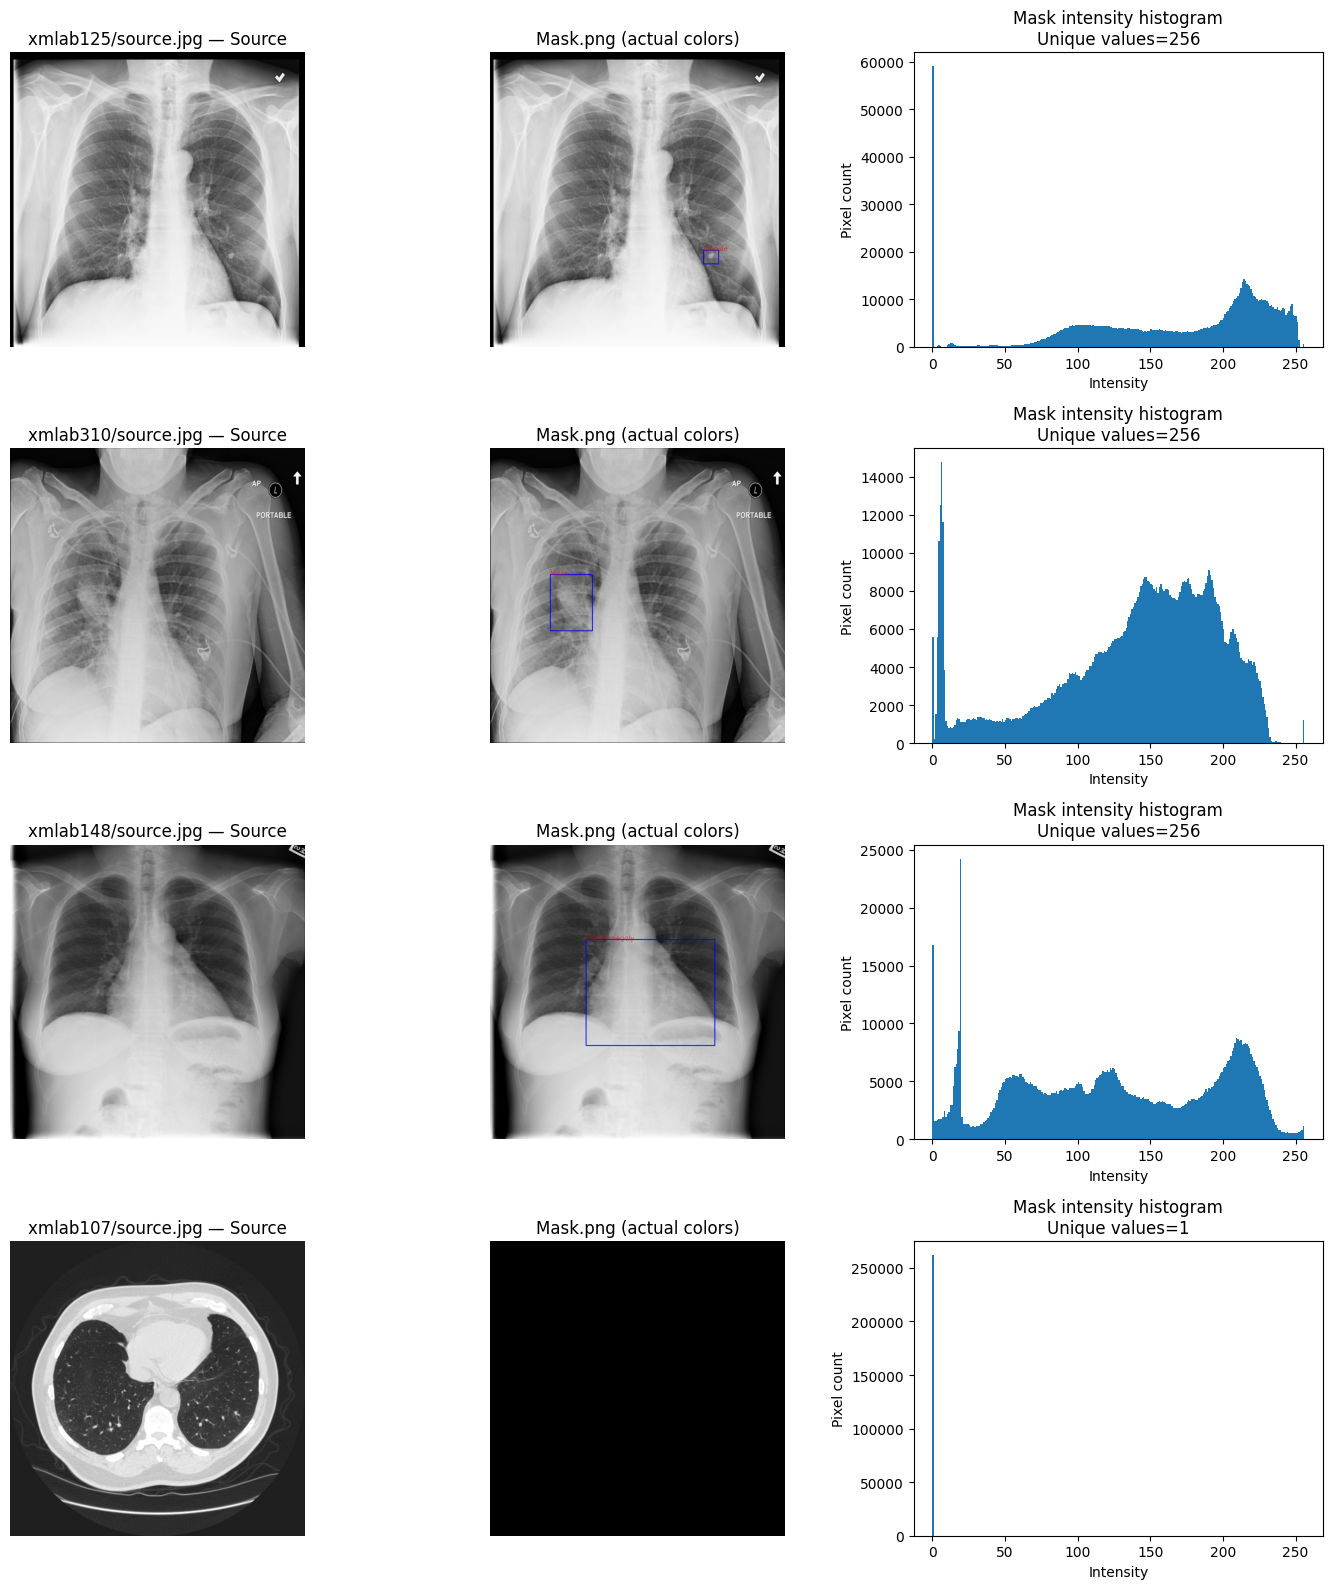

Saved: /kaggle/working/medvqa/evidence_localization/mask_audit/mask_visual_inspection.png


In [58]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(
    "/kaggle/input/datasets/"
    "buiquanghuy2801/slakedataset/Slake1.0"
)

AUDIT = Path(
    "/kaggle/working/medvqa/"
    "evidence_localization/mask_audit"
)

df = pd.read_csv(
    AUDIT / "validation_mask_audit.csv"
)

# 3 masks with many distinct intensities,
# plus one confirmed empty mask.
suspicious = (
    df[df["status"] == "has_exact_codes"]
    .sort_values("unique_gray_values", ascending=False)
    .head(3)["img_name"].tolist()
)

empty = (
    df[df["status"] == "empty"]
    .head(1)["img_name"].tolist()
)

samples = suspicious + empty

fig, axes = plt.subplots(
    len(samples), 3,
    figsize=(14, 4 * len(samples))
)

for i, name in enumerate(samples):
    folder = (ROOT / "imgs" / name).parent

    with Image.open(folder / "source.jpg") as im:
        source = np.asarray(im.convert("RGB"))

    with Image.open(folder / "mask.png") as im:
        mask = np.asarray(im.convert("RGB"))

    gray = mask[:, :, 0]

    axes[i, 0].imshow(source)
    axes[i, 0].set_title(f"{name} — Source")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask)
    axes[i, 1].set_title("Mask.png (actual colors)")
    axes[i, 1].axis("off")

    axes[i, 2].hist(
        gray.ravel(),
        bins=256,
        range=(0, 256)
    )
    axes[i, 2].set_title(
        f"Mask intensity histogram\n"
        f"Unique values={np.unique(gray).size}"
    )
    axes[i, 2].set_xlabel("Intensity")
    axes[i, 2].set_ylabel("Pixel count")

plt.tight_layout()

save_path = AUDIT / "mask_visual_inspection.png"
plt.savefig(
    save_path, dpi=140, bbox_inches="tight"
)
plt.show()

print("Saved:", save_path)


In [59]:

from pathlib import Path
import pandas as pd
import json
from collections import Counter

ROOT = Path(
    "/kaggle/input/datasets/"
    "buiquanghuy2801/slakedataset/Slake1.0"
)

VAL_PATH = Path(
    "/kaggle/input/notebooks/"
    "buiquanghuy2801/01-medvqa-baseline/"
    "slake_splits/validation.csv"
)

OUT = Path(
    "/kaggle/working/medvqa/"
    "evidence_localization/detection_audit"
)
OUT.mkdir(parents=True, exist_ok=True)

val = pd.read_csv(
    VAL_PATH, keep_default_na=False
)

rows = []
annotations = []
label_counter = Counter()

for img_name in val["img_name"].drop_duplicates():
    folder = (ROOT / "imgs" / img_name).parent
    detection_path = folder / "detection.json"

    if not detection_path.exists():
        rows.append({
            "img_name": img_name,
            "status": "missing",
            "n_boxes": 0
        })
        continue

    try:
        data = json.loads(
            detection_path.read_text(encoding="utf-8")
        )
    except Exception:
        rows.append({
            "img_name": img_name,
            "status": "invalid_json",
            "n_boxes": 0
        })
        continue

    valid_boxes = 0

    if isinstance(data, list):
        for item in data:
            if not isinstance(item, dict):
                continue

            for label, box in item.items():
                if (
                    not isinstance(box, list)
                    or len(box) != 4
                ):
                    continue

                try:
                    x, y, w, h = map(float, box)
                except (ValueError, TypeError):
                    continue

                if w <= 0 or h <= 0:
                    continue

                annotations.append({
                    "img_name": img_name,
                    "label": str(label),
                    "x": x,
                    "y": y,
                    "width": w,
                    "height": h
                })

                label_counter[str(label)] += 1
                valid_boxes += 1

    rows.append({
        "img_name": img_name,
        "status": (
            "has_boxes" if valid_boxes
            else "no_boxes"
        ),
        "n_boxes": valid_boxes
    })

audit = pd.DataFrame(rows)
boxes = pd.DataFrame(
    annotations,
    columns=[
        "img_name", "label",
        "x", "y", "width", "height"
    ]
)

audit.to_csv(
    OUT / "val_detection_audit.csv",
    index=False
)

boxes.to_csv(
    OUT / "val_detection_boxes.csv",
    index=False
)

print("=== VALIDATION DETECTION AUDIT ===")
print("Images:", len(audit))
print("Images with boxes:",
      int((audit["n_boxes"] > 0).sum()))
print("Total boxes:", len(boxes))

print("\n=== DETECTION STATUS ===")
print(audit["status"].value_counts().to_string())

print("\n=== PATHOLOGY LABELS ===")
for label, count in label_counter.most_common(20):
    n_images = boxes.loc[
        boxes["label"] == label, "img_name"
    ].nunique()

    print(
        f"{label:22s} "
        f"boxes={count:3d} "
        f"images={n_images:3d}"
    )

print("\n=== QUESTION EXAMPLES ON ANNOTATED IMAGES ===")

annotated_images = set(
    audit.loc[audit["n_boxes"] > 0, "img_name"]
)

examples = val[
    val["img_name"].isin(annotated_images)
][["img_name", "question", "answer"]]

print(examples.head(20).to_string(index=False))

print("\nSaved:", OUT)


=== VALIDATION DETECTION AUDIT ===
Images: 96
Images with boxes: 87
Total boxes: 206

=== DETECTION STATUS ===
status
has_boxes    87
no_boxes      9

=== PATHOLOGY LABELS ===
Brain Edema            boxes= 20 images= 16
Liver                  boxes= 15 images= 15
Colon                  boxes= 14 images=  8
Spinal Cord            boxes= 13 images= 13
Brain Non-enhancing Tumor boxes= 13 images= 12
Brain Enhancing Tumor  boxes= 13 images=  9
Small Bowel            boxes= 13 images= 10
Cardiomegaly           boxes=  8 images=  8
Infiltrate             boxes=  6 images=  6
Pneumonia              boxes=  6 images=  6
Liver Cancer           boxes=  6 images=  3
Atelectasis            boxes=  5 images=  5
Spleen                 boxes=  5 images=  5
Left Temporal Lobe     boxes=  5 images=  5
Right Temporal Lobe    boxes=  5 images=  5
Nodule                 boxes=  4 images=  4
Mass                   boxes=  4 images=  4
Effusion               boxes=  4 images=  4
Left Kidney            boxes=

In [60]:

from pathlib import Path
import re
import json
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path("/kaggle/working/medvqa")
SLAKE = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)

SPLIT = Path(
    "/kaggle/input/notebooks/buiquanghuy2801/"
    "01-medvqa-baseline/slake_splits/validation.csv"
)

BOX_DIR = ROOT / "evidence_localization/detection_audit"
OUT = ROOT / "evidence_localization/bbox_grounding"
OUT.mkdir(parents=True, exist_ok=True)

val = pd.read_csv(SPLIT, keep_default_na=False)
boxes = pd.read_csv(
    BOX_DIR / "val_detection_boxes.csv"
)

assert len(val) == 1078
assert len(boxes) == 206

def norm(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def split_answer(text):
    # Strict matching of answer components.
    # No synonym or semantic matching.
    return {
        norm(part)
        for part in str(text).split(",")
        if norm(part)
    }

boxes["label_key"] = boxes["label"].map(norm)

# Check that XYWH boxes are within source image bounds.
image_sizes = {}

for name in boxes["img_name"].unique():
    with Image.open(SLAKE / "imgs" / name) as im:
        image_sizes[name] = im.size

valid_boxes = []

for _, box in boxes.iterrows():
    name = box["img_name"]
    width, height = image_sizes[name]

    x, y = float(box["x"]), float(box["y"])
    w, h = float(box["width"]), float(box["height"])

    valid = (
        np.isfinite([x, y, w, h]).all()
        and x >= 0 and y >= 0
        and w > 0 and h > 0
        and x + w <= width + 1
        and y + h <= height + 1
    )

    valid_boxes.append(bool(valid))

boxes["valid_geometry"] = valid_boxes
boxes = boxes[boxes["valid_geometry"]].copy()

print("=== BBOX GEOMETRY CHECK ===")
print("Total boxes:", 206)
print("Valid boxes:", len(boxes))
print("Invalid boxes:", 206 - len(boxes))

# QA-level target selection from answer labels.
records = []

for idx, row in val.iterrows():
    matching_boxes = boxes[
        boxes["img_name"] == row["img_name"]
    ]

    if matching_boxes.empty:
        continue

    answer_parts = split_answer(row["answer"])

    selected = matching_boxes[
        matching_boxes["label_key"].isin(answer_parts)
    ]

    if selected.empty:
        continue

    target_labels = sorted(
        selected["label"].unique().tolist()
    )

    bbox_list = selected[
        ["label", "x", "y", "width", "height"]
    ].to_dict("records")

    records.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "question": row["question"],
        "answer": row["answer"],
        "target_labels": json.dumps(
            target_labels, ensure_ascii=False
        ),
        "bounding_boxes": json.dumps(
            bbox_list, ensure_ascii=False
        ),
        "n_target_labels": len(target_labels),
        "n_boxes": len(bbox_list)
    })

benchmark = pd.DataFrame(
    records,
    columns=[
        "sample_idx", "img_name",
        "question", "answer",
        "target_labels", "bounding_boxes",
        "n_target_labels", "n_boxes"
    ]
)

save_path = OUT / "val_bbox_grounding_candidates.csv"
benchmark.to_csv(save_path, index=False)

print("\n=== QA BBOX GROUNDING BENCHMARK ===")
print("Eligible QA:", len(benchmark))
print(
    "Unique images:",
    benchmark["img_name"].nunique()
    if len(benchmark) else 0
)
print(
    "QA with multiple target labels:",
    int((benchmark["n_target_labels"] > 1).sum())
    if len(benchmark) else 0
)

if len(benchmark):
    print("\n=== MATCHED TARGET LABELS ===")
    labels = []

    for entry in benchmark["target_labels"]:
        labels.extend(json.loads(entry))

    print(
        pd.Series(labels)
        .value_counts()
        .head(20)
        .to_string()
    )

    print("\n=== SAMPLE CANDIDATES ===")
    print(
        benchmark[
            [
                "sample_idx", "img_name",
                "question", "answer",
                "target_labels", "n_boxes"
            ]
        ].head(15).to_string(index=False)
    )

print("\nSaved:", save_path)


=== BBOX GEOMETRY CHECK ===
Total boxes: 206
Valid boxes: 206
Invalid boxes: 0

=== QA BBOX GROUNDING BENCHMARK ===
Eligible QA: 81
Unique images: 54
QA with multiple target labels: 6

=== MATCHED TARGET LABELS ===
Liver                        26
Brain Edema                  11
Cardiomegaly                  9
Lung Cancer                   4
Spinal Cord                   4
Atelectasis                   4
Nodule                        3
Brain Non-enhancing Tumor     3
Colon                         3
Liver Cancer                  3
Pneumothorax                  2
Bladder                       2
Small Bowel                   2
Pneumonia                     2
Brain Enhancing Tumor         2
Larynx                        2
Mass                          1
Effusion                      1
Spleen                        1
Esophagus                     1

=== SAMPLE CANDIDATES ===
 sample_idx            img_name                                          question                               answer

=== BBOX QA QUALITY AUDIT ===
Original candidates: 81
Complete answer matches: 75
Incomplete matches: 6

Question categories:
question_type
pathology_identification    38
organ_identification        19
other                       10
spatial                      9
comparison                   5

=== STRICT GROUNDING V1 ===
Eligible QA: 52
Unique images: 44
Multiple-target QA: 5

=== EXCLUDED EXAMPLES ===
 sample_idx                                                question                               answer            question_type unmatched_answers
         36              What diseases are included in the picture? Cardiomegaly, Infiltration, Effusion pathology_identification  ["infiltration"]
        112         Which is bigger in this image, spleen or liver?                                Liver               comparison                []
        113       What is the organ on the left side of this image?                                Liver                  spatial                []
 

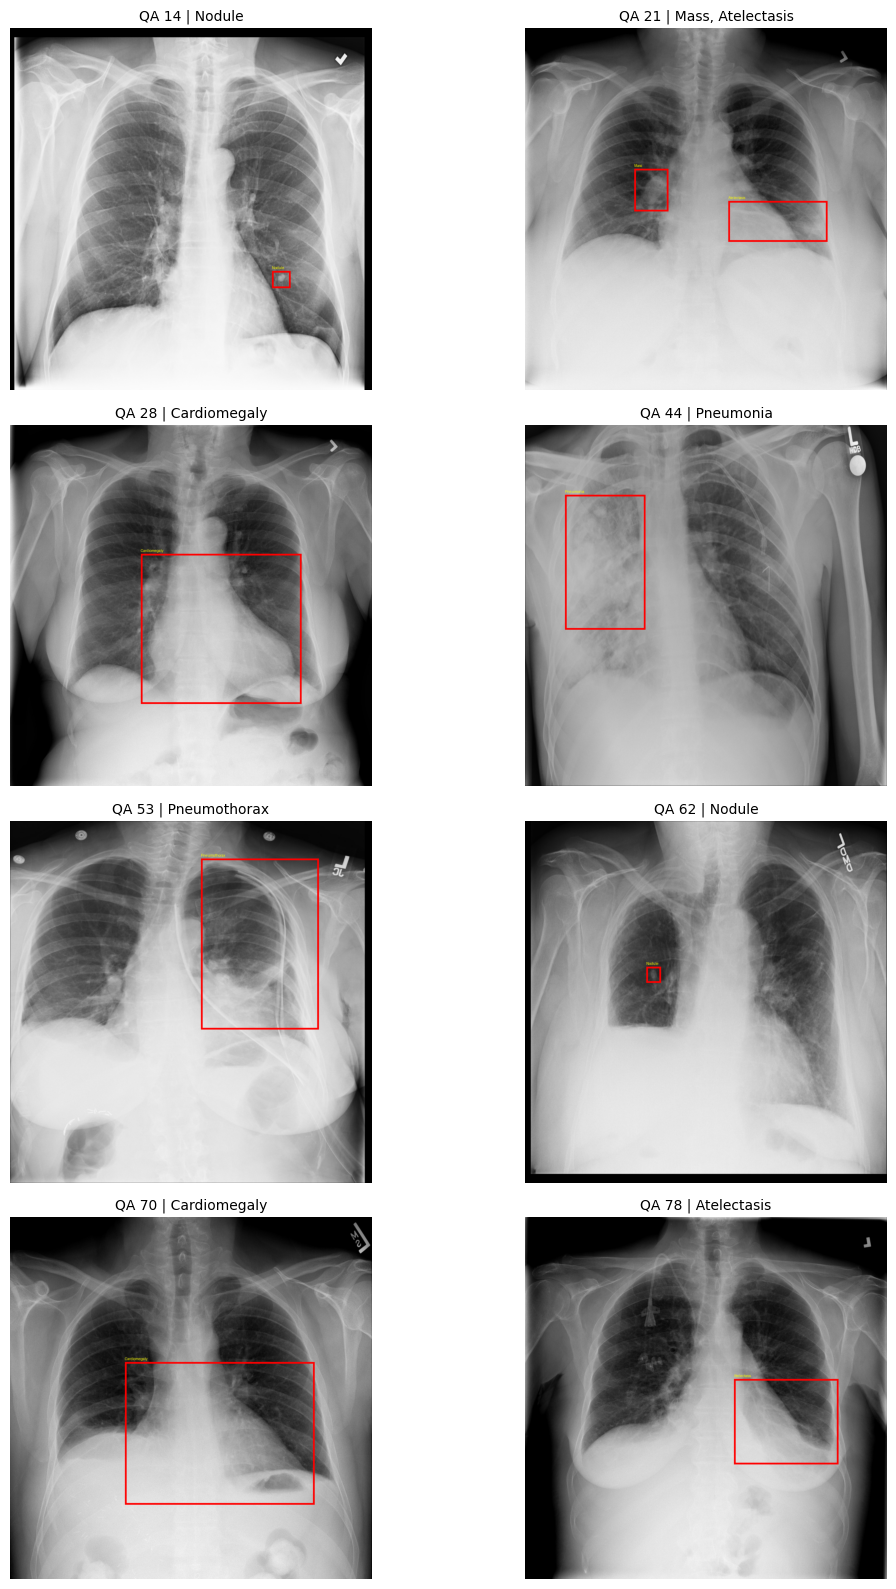


Visual review saved: /kaggle/working/medvqa/evidence_localization/bbox_grounding/strict_bbox_visual_review.png

=== BBOX QA AUDIT COMPLETE ===
Strict CSV: /kaggle/working/medvqa/evidence_localization/bbox_grounding/val_bbox_strict_v1.csv


In [61]:

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import pandas as pd
import numpy as np
import json
import re
import matplotlib.pyplot as plt

ROOT = Path("/kaggle/working/medvqa")
SLAKE = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)

OUT = ROOT / "evidence_localization/bbox_grounding"

df = pd.read_csv(
    OUT / "val_bbox_grounding_candidates.csv"
)

assert len(df) == 81

def normalize(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

# Synonyms are NOT automatically accepted here.
# They must be reviewed before inclusion.
def answer_parts(answer):
    return {
        normalize(x)
        for x in str(answer).split(",")
        if normalize(x)
    }

def classify_question(question):
    q = normalize(question)

    if any(term in q for term in [
        "bigger", "larger than", "smaller than",
        "compared", "compare", "which is larger"
    ]):
        return "comparison"

    if any(term in q for term in [
        "where", "located", "location",
        "left side", "right side"
    ]):
        return "spatial"

    if any(term in q for term in [
        "what diseases", "which diseases",
        "what disease", "which disease",
        "what abnormalities", "which abnormalities",
        "what abnormality"
    ]):
        return "pathology_identification"

    if any(term in q for term in [
        "what organ", "which organ",
        "main organ", "largest organ"
    ]):
        return "organ_identification"

    return "other"

rows = []

for _, row in df.iterrows():
    targets = {
        normalize(x)
        for x in json.loads(row["target_labels"])
    }
    answers = answer_parts(row["answer"])

    unmatched = sorted(answers - targets)
    question_type = classify_question(row["question"])

    complete = answers == targets

    strict = (
        complete
        and question_type in [
            "pathology_identification",
            "organ_identification"
        ]
        and len(targets) > 0
    )

    rows.append({
        "sample_idx": int(row["sample_idx"]),
        "question_type": question_type,
        "complete_answer_match": complete,
        "unmatched_answers": json.dumps(
            unmatched, ensure_ascii=False
        ),
        "strict_eligible": strict
    })

audit = pd.DataFrame(rows)

result = df.merge(
    audit, on="sample_idx",
    validate="one_to_one"
)

strict = result[result["strict_eligible"]].copy()

result.to_csv(
    OUT / "val_bbox_qa_audit.csv",
    index=False
)

strict.to_csv(
    OUT / "val_bbox_strict_v1.csv",
    index=False
)

print("=== BBOX QA QUALITY AUDIT ===")
print("Original candidates:", len(result))
print(
    "Complete answer matches:",
    int(result["complete_answer_match"].sum())
)
print(
    "Incomplete matches:",
    int((~result["complete_answer_match"]).sum())
)

print("\nQuestion categories:")
print(
    result["question_type"]
    .value_counts()
    .to_string()
)

print("\n=== STRICT GROUNDING V1 ===")
print("Eligible QA:", len(strict))
print("Unique images:", strict["img_name"].nunique())
print(
    "Multiple-target QA:",
    int((strict["n_target_labels"] > 1).sum())
)

print("\n=== EXCLUDED EXAMPLES ===")
excluded = result[~result["strict_eligible"]]

print(
    excluded[[
        "sample_idx", "question", "answer",
        "question_type", "unmatched_answers"
    ]].head(12).to_string(index=False)
)

# Visual review: diverse images, not just one label.
review = (
    strict.drop_duplicates("img_name")
    .head(8)
)

if len(review) == 0:
    review = result.drop_duplicates("img_name").head(8)

n = len(review)

if n:
    fig, axes = plt.subplots(
        (n + 1) // 2, 2,
        figsize=(12, 4 * ((n + 1) // 2)),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(axes.flat, review.iterrows()):
        path = SLAKE / "imgs" / row["img_name"]

        with Image.open(path) as im:
            image = im.convert("RGB")

        draw = ImageDraw.Draw(image)

        for box in json.loads(row["bounding_boxes"]):
            x, y = float(box["x"]), float(box["y"])
            w, h = float(box["width"]), float(box["height"])

            draw.rectangle(
                [x, y, x+w, y+h],
                outline="red",
                width=max(2, image.width // 200)
            )

            draw.text(
                (x, max(0, y-15)),
                str(box["label"]),
                fill="yellow"
            )

        ax.imshow(image)
        ax.set_title(
            f"QA {row['sample_idx']} | "
            f"{row['answer']}",
            fontsize=10
        )

    plt.tight_layout()
    visual_path = OUT / "strict_bbox_visual_review.png"
    plt.savefig(
        visual_path, dpi=140,
        bbox_inches="tight"
    )
    plt.show()

    print("\nVisual review saved:", visual_path)

print("\n=== BBOX QA AUDIT COMPLETE ===")
print("Strict CSV:", OUT / "val_bbox_strict_v1.csv")


In [62]:

from pathlib import Path
from PIL import Image, ImageDraw
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/medvqa")
SLAKE = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)
OUT = ROOT / "evidence_localization/bbox_grounding"

df = pd.read_csv(OUT / "val_bbox_strict_v1.csv")
assert len(df) == 52
assert df["sample_idx"].is_unique

# CE-only checkpoint, not a PoE checkpoint.
ckpt = torch.load(
    ROOT / "consistency_training/ce_only_best.pt",
    map_location="cpu", weights_only=True
)
classifier.load_state_dict(ckpt["model_state_dict"])
classifier.to(device).eval()
model.to(device).eval()

# Gradients are needed for the INPUT only.
for p in model.parameters():
    p.requires_grad_(False)
for p in classifier.parameters():
    p.requires_grad_(False)

# Apply identical geometric transforms to bbox mask.
# Do not apply image normalization to masks.


def transform_bbox_mask(mask):
    for tr in preprocess_val.transforms:
        name = type(tr).__name__

        if isinstance(tr, T.Resize):
            mask = TF.resize(
                mask,
                tr.size,
                interpolation=InterpolationMode.NEAREST,
                max_size=tr.max_size
            )

        elif isinstance(tr, T.CenterCrop):
            mask = TF.center_crop(mask, tr.size)

        elif name in {
            "MaybeConvertMode",
            "MaybeToTensor",
            "ToTensor",
            "Normalize",
            "ToImage",
            "ToDtype"
        }:
            # No change in spatial geometry.
            continue

        else:
            raise RuntimeError(
                f"Unsupported transform: {name}"
            )

    return torch.from_numpy(
        np.array(mask, copy=True)
    ).float().unsqueeze(0) / 255.0



records = []
saved_maps = OUT / "val_pixel_grad_maps"
saved_maps.mkdir(exist_ok=True)

for _, row in tqdm(
    df.iterrows(), total=len(df),
    desc="Validation grounding"
):
    idx = int(row["sample_idx"])
    img_path = SLAKE / "imgs" / row["img_name"]

    with Image.open(img_path) as im:
        image = im.convert("RGB")

    w, h = image.size

    # Union of all annotated target boxes.
    mask = Image.new("L", (w, h), 0)
    draw = ImageDraw.Draw(mask)

    for b in json.loads(row["bounding_boxes"]):
        x, y = float(b["x"]), float(b["y"])
        bw, bh = float(b["width"]), float(b["height"])
        draw.rectangle(
            (x, y, x + bw, y + bh),
            fill=255
        )

    x = preprocess_val(image).unsqueeze(0).to(device)
    x = x.detach().requires_grad_(True)
    q = val_q[idx:idx+1].to(device)

    # Fresh forward pass with autograd.
    with torch.enable_grad():
        image_embedding = model.encode_image(x)
        logits = classifier(image_embedding, q)
        pred = int(logits.argmax(dim=-1).item())
        score = logits[0, pred]

        grad = torch.autograd.grad(
            score, x,
            retain_graph=False,
            create_graph=False
        )[0]

    # Explicitly defined pixel Input x Gradient:
    # positive signed attribution, pooled to 7x7.
    pixel_attr = torch.relu(
        (x.detach() * grad.detach()).sum(
            dim=1, keepdim=True
        )
    )

    patch_attr = F.adaptive_avg_pool2d(
        pixel_attr, (7, 7)
    ).flatten().cpu().numpy()

    mask_tensor = transform_bbox_mask(mask)

    assert tuple(mask_tensor.shape[-2:]) == tuple(x.shape[-2:]), (
        "Mask geometry does not match model input."
    )

    coverage = F.adaptive_avg_pool2d(
        mask_tensor.unsqueeze(0), (7, 7)
    ).flatten().numpy()

    # A patch is eligible when >=25% overlaps the bbox.
    eligible = coverage >= 0.25
    positive_patches = int(eligible.sum())

    # Empty or fully positive masks are uninformative.
    if not (0 < positive_patches < 49):
        continue

    if not np.isfinite(patch_attr).all():
        raise ValueError(f"Nonfinite attribution at QA {idx}")

    # Zero maps cannot meaningfully rank patches.
    if float(patch_attr.sum()) <= 0:
        top1_hit = np.nan
        top5_hits = np.nan
        zero_map = True
    else:
        top5 = np.argsort(
            -patch_attr, kind="stable"
        )[:5]

        top1_hit = int(eligible[top5[0]])
        top5_hits = int(eligible[top5].sum())
        zero_map = False

    records.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "question": row["question"],
        "answer": row["answer"],
        "pred_id": pred,
        "top1_hit": top1_hit,
        "top5_hits": top5_hits,
        "chance_hit1": positive_patches / 49,
        "chance_hits5": 5 * positive_patches / 49,
        "positive_patches": positive_patches,
        "zero_map": zero_map
    })

    np.save(
        saved_maps / f"pixelgrad_{idx}.npy",
        patch_attr.reshape(7, 7)
    )

results = pd.DataFrame(records)
results.to_csv(
    OUT / "val_pixelgrad_grounding_v1.csv",
    index=False
)

print("=== VALIDATION GROUNDING ===")
print("Strict QA:", len(df))
print("Evaluable QA:", len(results))
print("Unique images:", results["img_name"].nunique())
print("Zero attribution maps:", int(results["zero_map"].sum()))

usable = results.dropna(
    subset=["top1_hit", "top5_hits"]
).copy()

assert len(usable) > 0, "No usable attribution maps."

print("\n=== GROUNDING VS RANDOM ===")
print(
    "Hit@1:",
    round(usable["top1_hit"].mean(), 4)
)
print(
    "Random expected Hit@1:",
    round(usable["chance_hit1"].mean(), 4)
)
print(
    "Mean HitCount@5:",
    round(usable["top5_hits"].mean(), 4)
)
print(
    "Random expected HitCount@5:",
    round(usable["chance_hits5"].mean(), 4)
)

# Cluster bootstrap: resample IMAGES, not QA rows.
image_groups = [
    g for _, g in usable.groupby("img_name")
]

rng = np.random.default_rng(2026)
boot1, boot5 = [], []

for _ in range(5000):
    chosen = rng.integers(
        0, len(image_groups),
        size=len(image_groups)
    )
    sampled = pd.concat(
        [image_groups[i] for i in chosen],
        ignore_index=True
    )

    boot1.append(
        (
            sampled["top1_hit"]
            - sampled["chance_hit1"]
        ).mean()
    )

    boot5.append(
        (
            sampled["top5_hits"]
            - sampled["chance_hits5"]
        ).mean()
    )

print("\n=== IMAGE BOOTSTRAP ===")
print(
    "Hit@1 advantage CI:",
    np.round(np.quantile(boot1, [0.025, 0.975]), 4)
)
print(
    "HitCount@5 advantage CI:",
    np.round(np.quantile(boot5, [0.025, 0.975]), 4)
)

print("\nSaved:", OUT / "val_pixelgrad_grounding_v1.csv")


Validation grounding:   0%|          | 0/52 [00:00<?, ?it/s]

=== VALIDATION GROUNDING ===
Strict QA: 52
Evaluable QA: 35
Unique images: 32
Zero attribution maps: 0

=== GROUNDING VS RANDOM ===
Hit@1: 0.4
Random expected Hit@1: 0.1534
Mean HitCount@5: 1.9429
Random expected HitCount@5: 0.7668

=== IMAGE BOOTSTRAP ===
Hit@1 advantage CI: [0.0878 0.414 ]
HitCount@5 advantage CI: [0.8157 1.525 ]

Saved: /kaggle/working/medvqa/evidence_localization/bbox_grounding/val_pixelgrad_grounding_v1.csv


In [63]:

from pathlib import Path
import pandas as pd
import json

ROOT = Path("/kaggle/working/medvqa")
OUT = ROOT / "evidence_localization/bbox_grounding"

strict = pd.read_csv(
    OUT / "val_bbox_strict_v1.csv"
)

evaluated = pd.read_csv(
    OUT / "val_pixelgrad_grounding_v1.csv"
)

excluded = strict[
    ~strict["sample_idx"].isin(evaluated["sample_idx"])
].copy()

excluded["n_target_boxes"] = excluded[
    "bounding_boxes"
].apply(lambda x: len(json.loads(x)))

print("=== GROUNDING COVERAGE AUDIT ===")
print("Strict QA:", len(strict))
print("Evaluated QA:", len(evaluated))
print("Excluded QA:", len(excluded))
print("Evaluated images:",
      evaluated["img_name"].nunique())
print("Excluded images:",
      excluded["img_name"].nunique())

print("\n=== EXCLUDED QA ===")

print(
    excluded[[
        "sample_idx", "img_name",
        "question", "answer",
        "n_target_boxes"
    ]].to_string(index=False)
)

print("\n=== BBOX SIZE COMPARISON ===")

def total_bbox_area(row):
    boxes = json.loads(row["bounding_boxes"])
    return sum(
        float(b["width"]) * float(b["height"])
        for b in boxes
    )

strict["bbox_area"] = strict.apply(
    total_bbox_area, axis=1
)

strict["evaluated"] = strict["sample_idx"].isin(
    evaluated["sample_idx"]
)

print(
    strict.groupby("evaluated")["bbox_area"]
    .describe()
    .round(1)
    .to_string()
)

excluded.to_csv(
    OUT / "val_grounding_excluded_qa.csv",
    index=False
)

print("\nSaved:", OUT / "val_grounding_excluded_qa.csv")


=== GROUNDING COVERAGE AUDIT ===
Strict QA: 52
Evaluated QA: 35
Excluded QA: 17
Evaluated images: 32
Excluded images: 14

=== EXCLUDED QA ===
 sample_idx            img_name                                                          question       answer  n_target_boxes
         14 xmlab125/source.jpg                        What diseases are included in the picture?       Nodule               1
         62 xmlab168/source.jpg                        What diseases are included in the picture?       Nodule               1
        185 xmlab261/source.jpg                        What diseases are included in the picture? Liver Cancer               1
        227 xmlab289/source.jpg                        What diseases are included in the picture? Liver Cancer               4
        474 xmlab422/source.jpg                         What organ is on the bottom of the image?  Spinal Cord               1
        475 xmlab422/source.jpg             What organ is the black hole on the top of the image

In [64]:

from pathlib import Path
from PIL import Image, ImageDraw
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/medvqa")
SLAKE = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)

OUT = ROOT / "evidence_localization/bbox_grounding"
MAP_DIR = OUT / "val_pixel_grad_maps"
MAP_DIR.mkdir(exist_ok=True)

strict = pd.read_csv(
    OUT / "val_bbox_strict_v1.csv"
)

assert len(strict) == 52

ckpt = torch.load(
    ROOT / "consistency_training/ce_only_best.pt",
    map_location="cpu",
    weights_only=True
)

classifier.load_state_dict(
    ckpt["model_state_dict"]
)
classifier.to(device).eval()
model.to(device).eval()

for p in model.parameters():
    p.requires_grad_(False)

for p in classifier.parameters():
    p.requires_grad_(False)


def transform_mask(mask):
    for tr in preprocess_val.transforms:
        name = type(tr).__name__

        if isinstance(tr, T.Resize):
            mask = TF.resize(
                mask,
                tr.size,
                interpolation=InterpolationMode.NEAREST,
                max_size=tr.max_size
            )
        elif isinstance(tr, T.CenterCrop):
            mask = TF.center_crop(mask, tr.size)
        elif name in {
            "MaybeConvertMode",
            "MaybeToTensor",
            "ToTensor",
            "Normalize",
            "ToImage",
            "ToDtype"
        }:
            continue
        else:
            raise RuntimeError(
                f"Unknown transform: {name}"
            )

    return (
        torch.from_numpy(
            np.array(mask, copy=True)
        ).float().unsqueeze(0) / 255.0
    )


@torch.enable_grad()
def compute_pixel_gradient(image, q):
    x = preprocess_val(image).unsqueeze(0).to(device)
    x.requires_grad_(True)

    image_emb = model.encode_image(x)
    logits = classifier(
        image_emb, q.to(device)
    )

    pred = logits.argmax(dim=-1)
    score = logits.gather(
        1, pred.unsqueeze(1)
    ).sum()

    grad = torch.autograd.grad(
        score, x
    )[0]

    attribution = torch.relu(
        (x.detach() * grad.detach()).sum(
            dim=1, keepdim=True
        )
    )

    patch_map = F.adaptive_avg_pool2d(
        attribution, (7, 7)
    ).reshape(49).cpu().numpy()

    return patch_map


rows = []
computed = 0

for _, row in tqdm(
    strict.iterrows(),
    total=len(strict),
    desc="Coverage-weighted grounding"
):
    idx = int(row["sample_idx"])
    img_path = SLAKE / "imgs" / row["img_name"]

    with Image.open(img_path) as im:
        image = im.convert("RGB")

    w, h = image.size

    binary = Image.new("L", (w, h), 0)
    draw = ImageDraw.Draw(binary)

    for box in json.loads(row["bounding_boxes"]):
        x = float(box["x"])
        y = float(box["y"])
        bw = float(box["width"])
        bh = float(box["height"])

        draw.rectangle(
            (x, y, x + bw, y + bh),
            fill=255
        )

    mask_tensor = transform_mask(binary)

    coverage = F.adaptive_avg_pool2d(
        mask_tensor.unsqueeze(0),
        (7, 7)
    ).reshape(49).numpy()

    map_path = MAP_DIR / f"pixelgrad_{idx}.npy"

    if map_path.exists():
        patch_map = np.load(
            map_path
        ).reshape(49)
    else:
        patch_map = compute_pixel_gradient(
            image,
            val_q[idx:idx+1]
        )
        np.save(
            map_path,
            patch_map.reshape(7, 7)
        )
        computed += 1

    assert np.isfinite(patch_map).all()

    if patch_map.sum() <= 0:
        continue

    top5 = np.argsort(
        -patch_map, kind="stable"
    )[:5]

    # Continuous overlap fraction per patch.
    top1_coverage = float(
        coverage[top5[0]]
    )

    top5_coverage = float(
        coverage[top5].sum()
    )

    random_coverage_1 = float(
        coverage.mean()
    )

    random_coverage_5 = float(
        5 * coverage.mean()
    )

    rows.append({
        "sample_idx": idx,
        "img_name": row["img_name"],
        "answer": row["answer"],
        "bbox_area": sum(
            float(b["width"]) * float(b["height"])
            for b in json.loads(row["bounding_boxes"])
        ),
        "coverage_top1": top1_coverage,
        "coverage_top5": top5_coverage,
        "random_coverage1": random_coverage_1,
        "random_coverage5": random_coverage_5,
        "advantage_top1": (
            top1_coverage - random_coverage_1
        ),
        "advantage_top5": (
            top5_coverage - random_coverage_5
        )
    })

results = pd.DataFrame(rows)

results.to_csv(
    OUT / "val_coverage_weighted_grounding.csv",
    index=False
)

print("=== COVERAGE-WEIGHTED GROUNDING ===")
print("Strict QA:", len(strict))
print("Evaluated QA:", len(results))
print("New heatmaps computed:", computed)
print("Unique images:", results["img_name"].nunique())

print("\n=== COVERAGE VS RANDOM ===")

for metric in ["top1", "top5"]:
    print(
        f"Coverage@{metric}:",
        round(
            results[f"coverage_{metric}"].mean(), 6
        )
    )
    print(
        f"Random@{metric}:",
        round(
            results[
                f"random_coverage{1 if metric == 'top1' else 5}"
            ].mean(),
            6
        )
    )
    print(
        f"Advantage@{metric}:",
        round(
            results[f"advantage_{metric}"].mean(), 6
        )
    )

print("\nSaved:", OUT / "val_coverage_weighted_grounding.csv")


Coverage-weighted grounding:   0%|          | 0/52 [00:00<?, ?it/s]

=== COVERAGE-WEIGHTED GROUNDING ===
Strict QA: 52
Evaluated QA: 52
New heatmaps computed: 17
Unique images: 44

=== COVERAGE VS RANDOM ===
Coverage@top1: 0.250263
Random@top1: 0.074888
Advantage@top1: 0.175375
Coverage@top5: 1.059063
Random@top5: 0.374438
Advantage@top5: 0.684626

Saved: /kaggle/working/medvqa/evidence_localization/bbox_grounding/val_coverage_weighted_grounding.csv


In [65]:

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working/medvqa")
OUT = ROOT / "evidence_localization/bbox_grounding"

df = pd.read_csv(
    OUT / "val_coverage_weighted_grounding.csv"
)

assert len(df) == 52
assert df["sample_idx"].is_unique

# Equal number of QA is not equal number of independent images.
groups = [
    group for _, group in df.groupby("img_name")
]

rng = np.random.default_rng(2026)
N_BOOT = 5000

bootstrap = {
    "top1": np.empty(N_BOOT),
    "top5": np.empty(N_BOOT)
}

for i in range(N_BOOT):
    selected = rng.integers(
        0, len(groups), size=len(groups)
    )

    sample = pd.concat(
        [groups[j] for j in selected],
        ignore_index=True
    )

    bootstrap["top1"][i] = sample[
        "advantage_top1"
    ].mean()

    bootstrap["top5"][i] = sample[
        "advantage_top5"
    ].mean()

print("=== COVERAGE BOOTSTRAP ===")
print("QA:", len(df))
print("Images:", df["img_name"].nunique())

for metric in ["top1", "top5"]:
    values = bootstrap[metric]
    ci = np.quantile(values, [0.025, 0.975])

    print(
        f"{metric}: "
        f"advantage={df[f'advantage_{metric}'].mean():+.6f} "
        f"95% CI [{ci[0]:+.6f}, {ci[1]:+.6f}]"
    )

# Predefined descriptive split by median bbox area.
median_area = df["bbox_area"].median()

df["bbox_group"] = np.where(
    df["bbox_area"] <= median_area,
    "smaller_half",
    "larger_half"
)

print("\n=== COVERAGE BY BBOX SIZE ===")
print("Median bbox area:", round(median_area, 2))

print(
    df.groupby("bbox_group").agg(
        qa=("sample_idx", "size"),
        images=("img_name", "nunique"),
        bbox_area=("bbox_area", "median"),
        top1_advantage=("advantage_top1", "mean"),
        top5_advantage=("advantage_top5", "mean")
    ).round(6).to_string()
)

summary = pd.DataFrame([
    {
        "metric": metric,
        "mean_advantage": df[
            f"advantage_{metric}"
        ].mean(),
        "ci_lower": np.quantile(
            bootstrap[metric], 0.025
        ),
        "ci_upper": np.quantile(
            bootstrap[metric], 0.975
        )
    }
    for metric in ["top1", "top5"]
])

summary.to_csv(
    OUT / "val_coverage_bootstrap_summary.csv",
    index=False
)

df.to_csv(
    OUT / "val_coverage_bbox_groups.csv",
    index=False
)

print("\n=== COVERAGE ANALYSIS COMPLETE ===")
print("Saved:", OUT)


=== COVERAGE BOOTSTRAP ===
QA: 52
Images: 44
top1: advantage=+0.175375 95% CI [+0.078087, +0.278562]
top5: advantage=+0.684626 95% CI [+0.441058, +0.943786]

=== COVERAGE BY BBOX SIZE ===
Median bbox area: 9622.5
              qa  images  bbox_area  top1_advantage  top5_advantage
bbox_group                                                         
larger_half   26      24    61162.0        0.220775        1.122656
smaller_half  26      23     1360.5        0.129976        0.246595

=== COVERAGE ANALYSIS COMPLETE ===
Saved: /kaggle/working/medvqa/evidence_localization/bbox_grounding


In [66]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import json
import re

ROOT = Path("/kaggle/working/medvqa")

SLAKE = Path(
    "/kaggle/input/datasets/"
    "buiquanghuy2801/slakedataset/Slake1.0"
)

TRAIN_PATH = Path(
    "/kaggle/input/notebooks/"
    "buiquanghuy2801/01-medvqa-baseline/"
    "slake_splits/train.csv"
)

OUT = ROOT / "evidence_guided_poe"
OUT.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(
    TRAIN_PATH,
    keep_default_na=False
)

assert len(train) == 4927

def normalize(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def answer_parts(text):
    return {
        normalize(part)
        for part in str(text).split(",")
        if normalize(part)
    }

def question_type(question):
    q = normalize(question)

    if any(t in q for t in [
        "bigger", "larger than", "smaller than",
        "compared", "compare", "which is larger"
    ]):
        return "comparison"

    if any(t in q for t in [
        "where", "located", "location",
        "left side", "right side"
    ]):
        return "spatial"

    if any(t in q for t in [
        "what diseases", "which diseases",
        "what disease", "which disease",
        "what abnormalities", "which abnormalities",
        "what abnormality"
    ]):
        return "pathology_identification"

    if any(t in q for t in [
        "what organ", "which organ",
        "main organ", "largest organ"
    ]):
        return "organ_identification"

    return "other"

# Read each image's annotation only once.
box_cache = {}
annotation_stats = {
    "missing_json": 0,
    "invalid_json": 0,
    "invalid_boxes": 0,
    "valid_boxes": 0
}

for img_name in train["img_name"].astype(str).unique():
    folder = (SLAKE / "imgs" / img_name).parent
    annotation_file = folder / "detection.json"

    if not annotation_file.exists():
        annotation_stats["missing_json"] += 1
        box_cache[img_name] = []
        continue

    try:
        data = json.loads(
            annotation_file.read_text(encoding="utf-8")
        )
    except (ValueError, UnicodeError):
        annotation_stats["invalid_json"] += 1
        box_cache[img_name] = []
        continue

    with Image.open(SLAKE / "imgs" / img_name) as image:
        width, height = image.size

    valid = []

    if isinstance(data, list):
        for item in data:
            if not isinstance(item, dict):
                continue

            for label, coords in item.items():
                try:
                    if len(coords) != 4:
                        raise ValueError("Invalid dimensions")

                    x, y, w, h = map(float, coords)

                    geometry_ok = (
                        np.isfinite([x, y, w, h]).all()
                        and x >= 0
                        and y >= 0
                        and w > 0
                        and h > 0
                        and x + w <= width + 1
                        and y + h <= height + 1
                    )
                except (TypeError, ValueError):
                    geometry_ok = False

                if not geometry_ok:
                    annotation_stats["invalid_boxes"] += 1
                    continue

                valid.append({
                    "label": str(label),
                    "label_key": normalize(label),
                    "x": x,
                    "y": y,
                    "width": w,
                    "height": h
                })

                annotation_stats["valid_boxes"] += 1

    box_cache[img_name] = valid

records = []

for idx, row in train.iterrows():
    boxes = box_cache.get(str(row["img_name"]), [])

    if not boxes:
        continue

    targets = answer_parts(row["answer"])
    selected = [
        b for b in boxes
        if b["label_key"] in targets
    ]

    if not selected:
        continue

    matched = {
        b["label_key"] for b in selected
    }

    # Require EVERY answer component to match.
    if targets != matched:
        continue

    category = question_type(row["question"])

    # Same conservative rules as validation strict v1.
    if category not in {
        "pathology_identification",
        "organ_identification"
    }:
        continue

    records.append({
        "sample_idx": int(idx),
        "img_name": row["img_name"],
        "question": row["question"],
        "answer": row["answer"],
        "question_type": category,
        "target_labels": json.dumps(
            sorted({b["label"] for b in selected}),
            ensure_ascii=False
        ),
        "bounding_boxes": json.dumps(
            [
                {
                    "label": b["label"],
                    "x": b["x"],
                    "y": b["y"],
                    "width": b["width"],
                    "height": b["height"]
                }
                for b in selected
            ],
            ensure_ascii=False
        ),
        "n_boxes": len(selected),
        "n_targets": len(matched)
    })

columns = [
    "sample_idx", "img_name", "question",
    "answer", "question_type",
    "target_labels", "bounding_boxes",
    "n_boxes", "n_targets"
]

supervision = pd.DataFrame(
    records,
    columns=columns
)

assert supervision["sample_idx"].is_unique
assert supervision["sample_idx"].between(0, 4926).all()

save_path = OUT / "train_bbox_supervision_v1.csv"

supervision.to_csv(
    save_path,
    index=False
)

print("=== TRAIN BBOX SUPERVISION ===")
print("Train QA:", len(train))
print("Train images:", train["img_name"].nunique())
print("Eligible QA:", len(supervision))
print("Eligible images:", supervision["img_name"].nunique())

print("\n=== ANNOTATION QUALITY ===")
for key, value in annotation_stats.items():
    print(f"{key}: {value}")

print("\n=== QUESTION TYPES ===")
print(
    supervision["question_type"]
    .value_counts()
    .to_string()
)

print("\n=== TARGET DISTRIBUTION ===")
labels = []

for value in supervision["target_labels"]:
    labels.extend(json.loads(value))

if labels:
    print(
        pd.Series(labels)
        .value_counts()
        .head(20)
        .to_string()
    )
else:
    print("No eligible labels found.")

print("\n=== TRAIN SUPERVISION COVERAGE ===")
print(
    "QA coverage:",
    round(len(supervision) / len(train), 4)
)
print(
    "Image coverage:",
    round(
        supervision["img_name"].nunique()
        / train["img_name"].nunique(),
        4
    )
)

print("\nSaved:", save_path)


=== TRAIN BBOX SUPERVISION ===
Train QA: 4927
Train images: 449
Eligible QA: 277
Eligible images: 228

=== ANNOTATION QUALITY ===
missing_json: 0
invalid_json: 0
invalid_boxes: 0
valid_boxes: 1170

=== QUESTION TYPES ===
question_type
organ_identification        146
pathology_identification    131

=== TARGET DISTRIBUTION ===
Liver                        69
Brain Edema                  38
Brain Non-enhancing Tumor    25
Small Bowel                  25
Brain Enhancing Tumor        22
Liver Cancer                 20
Spinal Cord                  16
Colon                        16
Atelectasis                  13
Pneumonia                    12
Rectum                       11
Cardiomegaly                 11
Lung Cancer                  11
Nodule                        9
Pneumothorax                  8
Mass                          7
Esophagus                     6
Bladder                       6
Effusion                      4
Larynx                        3

=== TRAIN SUPERVISION COVERAGE 

In [67]:

from pathlib import Path
from PIL import Image, ImageDraw
import json
import numpy as np
import pandas as pd

ROOT = Path("/kaggle/working/medvqa")
SLAKE = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)
OUT = ROOT / "evidence_guided_poe"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    OUT / "train_bbox_supervision_v1.csv"
)
assert len(df) == 277

rng = np.random.default_rng(2026)
SIZE = 224
TARGET = 0.10  # Maximum target/control overlap ratio

def resize_center_crop_mask(mask, size=224):
    # BiomedCLIP standard eval geometry:
    # resize shortest side to 224, then center crop.
    w, h = mask.size
    scale = size / min(w, h)
    new_w = max(size, int(round(w * scale)))
    new_h = max(size, int(round(h * scale)))

    mask = mask.resize(
        (new_w, new_h),
        resample=Image.Resampling.NEAREST
    )

    left = (new_w - size) // 2
    top = (new_h - size) // 2

    return np.asarray(
        mask.crop(
            (left, top, left + size, top + size)
        ),
        dtype=np.uint8
    ) > 0

def translate_without_wrap(mask, dx, dy):
    h, w = mask.shape
    out = np.zeros_like(mask)

    sx0 = max(0, -dx)
    sx1 = min(w, w - dx)
    sy0 = max(0, -dy)
    sy1 = min(h, h - dy)

    if sx1 > sx0 and sy1 > sy0:
        out[
            sy0 + dy:sy1 + dy,
            sx0 + dx:sx1 + dx
        ] = mask[sy0:sy1, sx0:sx1]

    return out

records = []
target_masks = []
control_masks = []

for _, row in df.iterrows():
    img_name = row["img_name"]

    with Image.open(
        SLAKE / "imgs" / img_name
    ) as im:
        w, h = im.size

    mask_image = Image.new("L", (w, h), 0)
    draw = ImageDraw.Draw(mask_image)

    for box in json.loads(row["bounding_boxes"]):
        x = float(box["x"])
        y = float(box["y"])
        bw = float(box["width"])
        bh = float(box["height"])

        draw.rectangle(
            (x, y, x + bw, y + bh),
            fill=255
        )

    target = resize_center_crop_mask(mask_image)
    area = int(target.sum())

    control = np.zeros_like(target)
    valid = False
    overlap = np.nan

    if area > 0:
        ys, xs = np.where(target)

        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())

        dx_min, dx_max = -x0, SIZE - 1 - x1
        dy_min, dy_max = -y0, SIZE - 1 - y1

        for _ in range(250):
            dx = int(rng.integers(
                dx_min, dx_max + 1
            ))
            dy = int(rng.integers(
                dy_min, dy_max + 1
            ))

            candidate = translate_without_wrap(
                target, dx, dy
            )

            # Require exactly identical target/control area.
            if int(candidate.sum()) != area:
                continue

            ratio = (
                np.logical_and(
                    target, candidate
                ).sum() / area
            )

            if ratio <= TARGET:
                control = candidate
                overlap = float(ratio)
                valid = True
                break

    records.append({
        "sample_idx": int(row["sample_idx"]),
        "img_name": img_name,
        "question_type": row["question_type"],
        "target_area_px": area,
        "target_fraction": area / (SIZE * SIZE),
        "valid_control": valid,
        "control_overlap_ratio": overlap
    })

    target_masks.append(target.astype(np.uint8))
    control_masks.append(control.astype(np.uint8))

audit = pd.DataFrame(records)

np.savez_compressed(
    OUT / "train_evidence_intervention_masks_v1.npz",
    sample_idx=audit["sample_idx"].to_numpy(),
    target=np.stack(target_masks),
    control=np.stack(control_masks),
    valid_control=audit["valid_control"].to_numpy()
)

audit.to_csv(
    OUT / "train_evidence_intervention_audit_v1.csv",
    index=False
)

print("=== TRAIN EVIDENCE INTERVENTION ===")
print("Total QA:", len(audit))
print(
    "QA with nonempty target:",
    int((audit["target_area_px"] > 0).sum())
)
print(
    "QA with valid matched control:",
    int(audit["valid_control"].sum())
)
print(
    "Unique images with matched control:",
    audit.loc[
        audit["valid_control"], "img_name"
    ].nunique()
)

print("\n=== TARGET SIZE ===")
print(
    audit["target_fraction"]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(6)
    .to_string()
)

print("\n=== BY QUESTION TYPE ===")
print(
    audit.groupby("question_type").agg(
        qa=("sample_idx", "size"),
        valid_controls=("valid_control", "sum"),
        median_target_fraction=(
            "target_fraction", "median"
        )
    ).round(6).to_string()
)

print("\nSaved masks and audit to:", OUT)


=== TRAIN EVIDENCE INTERVENTION ===
Total QA: 277
QA with nonempty target: 277
QA with valid matched control: 265
Unique images with matched control: 222

=== TARGET SIZE ===
count    277.000000
mean       0.068527
std        0.076852
min        0.000399
25%        0.007514
50%        0.045480
75%        0.104213
max        0.559630

=== BY QUESTION TYPE ===
                           qa  valid_controls  median_target_fraction
question_type                                                        
organ_identification      146             136                0.052695
pathology_identification  131             129                0.032366

Saved masks and audit to: /kaggle/working/medvqa/evidence_guided_poe


In [68]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/medvqa")
SLAKE = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)
OUT = ROOT / "evidence_guided_poe"

TRAIN_CSV = Path(
    "/kaggle/input/notebooks/buiquanghuy2801/"
    "01-medvqa-baseline/slake_splits/train.csv"
)

# Ensure the original model and question representations
# are present; never silently substitute another pipeline.
for name in [
    "model", "classifier",
    "preprocess_val", "device", "train_q"
]:
    if name not in globals():
        raise RuntimeError(
            f"Missing {name}. Restore the original "
            "BiomedCLIP training pipeline first."
        )

train = pd.read_csv(
    TRAIN_CSV, keep_default_na=False
)
audit = pd.read_csv(
    OUT / "train_evidence_intervention_audit_v1.csv"
)
data = np.load(
    OUT / "train_evidence_intervention_masks_v1.npz"
)

assert len(train) == 4927
assert len(audit) == 277
assert len(data["sample_idx"]) == 277
assert len(train_q) == len(train)

assert np.array_equal(
    data["sample_idx"],
    audit["sample_idx"].to_numpy()
), "Mask and audit row order mismatch."

# Reload CE-only baseline.
ckpt = torch.load(
    ROOT / "consistency_training/ce_only_best.pt",
    map_location="cpu",
    weights_only=True
)

classifier.load_state_dict(
    ckpt["model_state_dict"]
)

model.to(device).eval()
classifier.to(device).eval()

for p in model.parameters():
    p.requires_grad_(False)

for p in classifier.parameters():
    p.requires_grad_(False)

rows = []

with torch.inference_mode():
    for j, entry in tqdm(
        audit.iterrows(),
        total=len(audit),
        desc="Evidence intervention"
    ):
        if not bool(entry["valid_control"]):
            continue

        idx = int(entry["sample_idx"])
        img_name = str(entry["img_name"])

        target = torch.from_numpy(
            data["target"][j].astype(np.float32)
        ).to(device)[None, None]

        control = torch.from_numpy(
            data["control"][j].astype(np.float32)
        ).to(device)[None, None]

        # Check equal size and limited overlap.
        target_area = target.sum().item()
        control_area = control.sum().item()

        assert target_area > 0
        assert target_area == control_area
        assert (
            (target * control).sum().item()
            / target_area
        ) <= 0.10001

        with Image.open(
            SLAKE / "imgs" / img_name
        ) as im:
            x = preprocess_val(
                im.convert("RGB")
            ).unsqueeze(0).to(device)

        assert x.shape[-2:] == target.shape[-2:]

        q = train_q[idx:idx+1].to(device)

        # Same Gaussian smoothing for target/control.
        # Both masks are in preprocessed 224x224 coordinates.
        smooth = torch.nn.functional.gaussian_blur if hasattr(
            torch.nn.functional, "gaussian_blur"
        ) else None

        if smooth is None:
            import torchvision.transforms.functional as TF
            blurred = TF.gaussian_blur(
                x, kernel_size=[17, 17],
                sigma=[5.0, 5.0]
            )
        else:
            blurred = smooth(
                x, kernel_size=[17, 17],
                sigma=[5.0, 5.0]
            )

        x_target = x * (1-target) + blurred * target
        x_control = x * (1-control) + blurred * control

        images = torch.cat(
            [x, x_target, x_control], dim=0
        )

        image_emb = model.encode_image(images)
        q_batch = q.expand(3, -1)

        logits = classifier(
            image_emb, q_batch
        ).float()

        assert logits.shape[0] == 3

        logp = F.log_softmax(logits, dim=-1)
        p = logp.exp()

        # Original prediction as reference distribution.
        reference = p[0:1].expand(2, -1)

        kl_target = F.kl_div(
            logp[1:2], reference[0:1],
            reduction="batchmean"
        ).item()

        kl_control = F.kl_div(
            logp[2:3], reference[1:2],
            reduction="batchmean"
        ).item()

        pred_original = int(
            logits[0].argmax().item()
        )

        original_prob = float(
            p[0, pred_original].item()
        )

        target_prob = float(
            p[1, pred_original].item()
        )

        control_prob = float(
            p[2, pred_original].item()
        )

        rows.append({
            "sample_idx": idx,
            "img_name": img_name,
            "question_type": entry["question_type"],
            "target_fraction": float(
                entry["target_fraction"]
            ),
            "pred_id": pred_original,
            "original_confidence": original_prob,
            "kl_target": kl_target,
            "kl_control": kl_control,
            "delta_kl": kl_target - kl_control,
            "prob_drop_target": (
                original_prob - target_prob
            ),
            "prob_drop_control": (
                original_prob - control_prob
            ),
            "delta_prob_drop": (
                control_prob - target_prob
            ),
            "target_pred_changed": int(
                logits[1].argmax().item()
                != pred_original
            ),
            "control_pred_changed": int(
                logits[2].argmax().item()
                != pred_original
            )
        })

results = pd.DataFrame(rows)

assert len(results) == 265, (
    f"Expected 265 matched QA, got {len(results)}"
)

results.to_csv(
    OUT / "train_bbox_intervention_results_v1.csv",
    index=False
)

print("=== TRAIN BBOX INTERVENTION ===")
print("QA:", len(results))
print("Images:", results["img_name"].nunique())

print("\n=== TARGET VS CONTROL ===")
for key in [
    "kl_target", "kl_control", "delta_kl",
    "prob_drop_target", "prob_drop_control",
    "delta_prob_drop",
    "target_pred_changed",
    "control_pred_changed"
]:
    print(
        f"{key:24s}: "
        f"{results[key].mean():+.6f}"
    )

print("\n=== BY QUESTION TYPE ===")
print(
    results.groupby("question_type").agg(
        qa=("sample_idx", "size"),
        images=("img_name", "nunique"),
        delta_kl=("delta_kl", "mean"),
        delta_prob_drop=(
            "delta_prob_drop", "mean"
        )
    ).round(6).to_string()
)

# Image-cluster bootstrap.
groups = [
    group for _, group in results.groupby("img_name")
]

rng = np.random.default_rng(2026)
boot_kl = []
boot_prob = []

for _ in range(5000):
    indices = rng.integers(
        0, len(groups), size=len(groups)
    )

    sample = pd.concat(
        [groups[i] for i in indices],
        ignore_index=True
    )

    boot_kl.append(
        sample["delta_kl"].mean()
    )
    boot_prob.append(
        sample["delta_prob_drop"].mean()
    )

print("\n=== IMAGE BOOTSTRAP ===")
for name, arr in [
    ("Delta KL", boot_kl),
    ("Delta probability drop", boot_prob)
]:
    low, high = np.quantile(
        arr, [0.025, 0.975]
    )
    print(
        f"{name}: "
        f"95% CI [{low:+.6f}, {high:+.6f}]"
    )

print(
    "\nSaved:",
    OUT / "train_bbox_intervention_results_v1.csv"
)


Evidence intervention:   0%|          | 0/277 [00:00<?, ?it/s]

=== TRAIN BBOX INTERVENTION ===
QA: 265
Images: 222

=== TARGET VS CONTROL ===
kl_target               : +0.013292
kl_control              : +0.002910
delta_kl                : +0.010382
prob_drop_target        : +0.011838
prob_drop_control       : +0.003329
delta_prob_drop         : +0.008509
target_pred_changed     : +0.071698
control_pred_changed    : +0.022642

=== BY QUESTION TYPE ===
                           qa  images  delta_kl  delta_prob_drop
question_type                                                   
organ_identification      136     106  0.015902         0.012441
pathology_identification  129     128  0.004562         0.004364

=== IMAGE BOOTSTRAP ===
Delta KL: 95% CI [+0.006890, +0.014667]
Delta probability drop: 95% CI [+0.002063, +0.015459]

Saved: /kaggle/working/medvqa/evidence_guided_poe/train_bbox_intervention_results_v1.csv


In [69]:

from pathlib import Path
import numpy as np
import pandas as pd

path = Path(
    "/kaggle/working/medvqa/evidence_guided_poe/"
    "train_bbox_intervention_results_v1.csv"
)

df = pd.read_csv(path)

assert len(df) == 265
assert df["sample_idx"].is_unique
assert df["img_name"].nunique() == 222

rng = np.random.default_rng(2026)
B = 10000

metrics = [
    "delta_kl",
    "delta_prob_drop"
]

# Cluster bootstrap: sample images, retain all QA per image.
groups = [
    g for _, g in df.groupby("img_name", sort=True)
]

boot = np.zeros((B, len(metrics)))

for b in range(B):
    ids = rng.integers(
        len(groups), size=len(groups)
    )
    sample = pd.concat(
        [groups[i] for i in ids],
        ignore_index=True
    )
    boot[b] = sample[metrics].mean().to_numpy()

print("=== IMAGE BOOTSTRAP ===")
for j, metric in enumerate(metrics):
    lo, hi = np.quantile(
        boot[:, j], [0.025, 0.975]
    )
    print(
        f"{metric}: mean={df[metric].mean():+.6f}, "
        f"95% CI [{lo:+.6f}, {hi:+.6f}]"
    )

print("\n=== EFFECT DIRECTION ===")
print(
    "Fraction delta KL > 0:",
    round((df["delta_kl"] > 0).mean(), 4)
)
print(
    "Median delta KL:",
    round(df["delta_kl"].median(), 6)
)

print("\n=== BY QUESTION TYPE ===")
print(
    df.groupby("question_type").agg(
        qa=("sample_idx", "size"),
        images=("img_name", "nunique"),
        mean_delta_kl=("delta_kl", "mean"),
        median_delta_kl=("delta_kl", "median"),
        positive_fraction=(
            "delta_kl",
            lambda s: (s > 0).mean()
        )
    ).round(6).to_string()
)

summary = pd.DataFrame({
    "metric": metrics,
    "mean": df[metrics].mean().to_numpy(),
    "ci_lower": np.quantile(
        boot, 0.025, axis=0
    ),
    "ci_upper": np.quantile(
        boot, 0.975, axis=0
    )
})

out = path.parent / "train_bbox_intervention_bootstrap_v1.csv"
summary.to_csv(out, index=False)

print("\nSaved:", out)


=== IMAGE BOOTSTRAP ===
delta_kl: mean=+0.010382, 95% CI [+0.006888, +0.014587]
delta_prob_drop: mean=+0.008509, 95% CI [+0.002213, +0.015339]

=== EFFECT DIRECTION ===
Fraction delta KL > 0: 0.8566
Median delta KL: 0.002311

=== BY QUESTION TYPE ===
                           qa  images  mean_delta_kl  median_delta_kl  positive_fraction
question_type                                                                           
organ_identification      136     106       0.015902         0.003281           0.860294
pathology_identification  129     128       0.004562         0.001610           0.852713

Saved: /kaggle/working/medvqa/evidence_guided_poe/train_bbox_intervention_bootstrap_v1.csv


In [70]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

ROOT = Path("/kaggle/working/medvqa")

df = pd.read_csv(
    ROOT / "evidence_guided_poe/"
    "train_bbox_intervention_results_v1.csv"
)

oof = np.load(
    ROOT / "adaptive_prior/oof/"
    "question_oof_probs.npy"
)

assert len(df) == 265
assert oof.shape == (4927, 205)
assert df["sample_idx"].is_unique

idx = df["sample_idx"].to_numpy(dtype=int)

df["prior_pred_id"] = oof[idx].argmax(axis=1)
df["prior_confidence"] = oof[idx].max(axis=1)

df["disagreement"] = (
    df["pred_id"] != df["prior_pred_id"]
)

df["positive_delta"] = df["delta_kl"] > 0

print("=== EVIDENCE RELIABILITY AUDIT ===")
print("QA:", len(df))
print("Images:", df["img_name"].nunique())
print("CE vs OOF disagreement:",
      int(df["disagreement"].sum()))

print("\n=== INTERVENTION BY AGREEMENT ===")
print(
    df.groupby("disagreement").agg(
        qa=("sample_idx", "size"),
        images=("img_name", "nunique"),
        mean_delta_kl=("delta_kl", "mean"),
        median_delta_kl=("delta_kl", "median"),
        positive_fraction=("positive_delta", "mean"),
        mean_ce_conf=("original_confidence", "mean"),
        mean_prior_conf=("prior_confidence", "mean")
    ).round(6).to_string()
)

print("\n=== POTENTIAL CONFOUNDING ===")

for name in [
    "target_fraction",
    "original_confidence",
    "prior_confidence"
]:
    rho, p = spearmanr(
        df["delta_kl"], df[name]
    )
    print(
        f"Delta KL vs {name:22s}: "
        f"Spearman={rho:+.4f}, p={p:.4g}"
    )

# Use existing aligned train labels when available.
# Do not reconstruct class IDs using a new vocabulary.
labels = None

if "train_y" in globals():
    candidate = train_y

    if hasattr(candidate, "detach"):
        candidate = candidate.detach().cpu().numpy()

    candidate = np.asarray(candidate)

    if candidate.ndim == 2 and candidate.shape[1] == 205:
        candidate = candidate.argmax(axis=1)

    if (
        candidate.ndim == 1
        and len(candidate) == 4927
        and np.issubdtype(candidate.dtype, np.integer)
    ):
        labels = candidate.astype(int)

if labels is not None:
    df["correct"] = (
        df["pred_id"].to_numpy()
        == labels[idx]
    )

    df["prior_correct"] = (
        df["prior_pred_id"].to_numpy()
        == labels[idx]
    )

    print("\n=== CORRECTNESS RELIABILITY TEST ===")
    print("CE accuracy on subset:",
          round(df["correct"].mean(), 4))
    print("OOF prior accuracy on subset:",
          round(df["prior_correct"].mean(), 4))

    print(
        df.groupby("correct").agg(
            qa=("sample_idx", "size"),
            mean_delta_kl=("delta_kl", "mean"),
            median_delta_kl=("delta_kl", "median"),
            mean_ce_conf=(
                "original_confidence", "mean"
            )
        ).round(6).to_string()
    )

    for title, subset in [
        ("All eligible QA", df),
        ("CE/OOF disagreement",
         df[df["disagreement"]])
    ]:
        print(f"\n=== {title.upper()} ===")
        print("QA:", len(subset))
        print("CE correct:", int(subset["correct"].sum()))
        print("CE wrong:", int((~subset["correct"]).sum()))

        if subset["correct"].nunique() == 2:
            y = subset["correct"].astype(int)

            print(
                "AUC Delta KL -> CE correct:",
                round(
                    roc_auc_score(y, subset["delta_kl"]),
                    4
                )
            )

            print(
                "AUC CE confidence -> CE correct:",
                round(
                    roc_auc_score(
                        y, subset["original_confidence"]
                    ),
                    4
                )
            )
        else:
            print("AUC unavailable: one correctness class.")

else:
    print("\n=== CORRECTNESS TEST UNAVAILABLE ===")
    print(
        "No verified 4927-element integer train_y "
        "was found. Agreement and confounding "
        "results above remain valid."
    )

save_path = (
    ROOT / "evidence_guided_poe/"
    "train_evidence_reliability_audit_v1.csv"
)
df.to_csv(save_path, index=False)

print("\nSaved:", save_path)


=== EVIDENCE RELIABILITY AUDIT ===
QA: 265
Images: 222
CE vs OOF disagreement: 172

=== INTERVENTION BY AGREEMENT ===
               qa  images  mean_delta_kl  median_delta_kl  positive_fraction  mean_ce_conf  mean_prior_conf
disagreement                                                                                               
False          93      85       0.010267         0.002867           0.881720      0.333666         0.228108
True          172     165       0.010443         0.001733           0.843023      0.234750         0.202095

=== POTENTIAL CONFOUNDING ===
Delta KL vs target_fraction       : Spearman=+0.2202, p=0.0003042
Delta KL vs original_confidence   : Spearman=+0.2136, p=0.0004624
Delta KL vs prior_confidence      : Spearman=+0.0954, p=0.1214

=== CORRECTNESS RELIABILITY TEST ===
CE accuracy on subset: 0.4604
OOF prior accuracy on subset: 0.2113
          qa  mean_delta_kl  median_delta_kl  mean_ce_conf
correct                                                   
F

In [71]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss

ROOT = Path("/kaggle/working/medvqa")
PATH = ROOT / "evidence_guided_poe/train_evidence_reliability_audit_v1.csv"

df = pd.read_csv(PATH)

assert len(df) == 265
assert df["img_name"].nunique() == 222
assert "correct" in df.columns, (
    "The previous audit must include verified CE correctness."
)

# Derived entirely from TRAIN evidence examples.
# The evaluation folds are disjoint by image.
df["log_bbox_area"] = np.log1p(
    df["target_fraction"].clip(lower=0)
)

df["log_delta_kl"] = np.sign(
    df["delta_kl"]
) * np.log1p(
    1000 * np.abs(df["delta_kl"])
)

BASE = [
    "original_confidence",
    "prior_confidence",
    "log_bbox_area",
    "disagreement"
]

WITH_EVIDENCE = BASE + ["log_delta_kl"]

y = df["correct"].astype(int).to_numpy()
groups = df["img_name"].to_numpy()

cv = GroupKFold(n_splits=5)

def oof_predict(features):
    X = df[features].astype(float).to_numpy()
    pred = np.full(len(y), np.nan)

    for tr, va in cv.split(X, y, groups):
        clf = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(
                C=1.0,
                max_iter=2000,
                random_state=2026
            )
        )

        clf.fit(X[tr], y[tr])

        pred[va] = clf.predict_proba(
            X[va]
        )[:, 1]

    assert np.isfinite(pred).all()
    return pred

p_base = oof_predict(BASE)
p_evidence = oof_predict(WITH_EVIDENCE)

def metrics(y_true, pred):
    return {
        "auc": roc_auc_score(y_true, pred),
        "logloss": log_loss(
            y_true, pred,
            labels=[0, 1]
        ),
        "brier": np.mean(
            (pred - y_true) ** 2
        )
    }

base = metrics(y, p_base)
evidence = metrics(y, p_evidence)

print("=== INCREMENTAL EVIDENCE VALUE ===")
print("QA:", len(df))
print("Images:", len(np.unique(groups)))

print("\nMetric            Base       +DeltaKL       Difference")
for key in ["auc", "logloss", "brier"]:
    print(
        f"{key:10s} "
        f"{base[key]:10.6f} "
        f"{evidence[key]:12.6f} "
        f"{evidence[key]-base[key]:+12.6f}"
    )

# Bootstrap paired OOF predictions by IMAGE.
unique_images = np.unique(groups)
image_indices = [
    np.flatnonzero(groups == name)
    for name in unique_images
]

rng = np.random.default_rng(2026)

boot = []
for _ in range(5000):
    sampled = rng.integers(
        0, len(image_indices),
        size=len(image_indices)
    )

    ids = np.concatenate(
        [image_indices[i] for i in sampled]
    )

    if np.unique(y[ids]).size < 2:
        continue

    boot.append([
        roc_auc_score(
            y[ids], p_evidence[ids]
        ) - roc_auc_score(
            y[ids], p_base[ids]
        ),
        log_loss(
            y[ids], p_evidence[ids],
            labels=[0, 1]
        ) - log_loss(
            y[ids], p_base[ids],
            labels=[0, 1]
        )
    ])

boot = np.asarray(boot)

print("\n=== IMAGE BOOTSTRAP: EVIDENCE - BASE ===")
for j, metric in enumerate(["AUC", "LogLoss"]):
    lo, hi = np.quantile(
        boot[:, j], [0.025, 0.975]
    )
    print(
        f"{metric}: "
        f"95% CI [{lo:+.6f}, {hi:+.6f}]"
    )

result = df[[
    "sample_idx", "img_name",
    "correct", "disagreement"
]].copy()

result["p_correct_base"] = p_base
result["p_correct_evidence"] = p_evidence

save_path = (
    ROOT / "evidence_guided_poe/"
    "train_evidence_incremental_oof_v1.csv"
)

result.to_csv(save_path, index=False)

print("\nSaved:", save_path)


=== INCREMENTAL EVIDENCE VALUE ===
QA: 265
Images: 222

Metric            Base       +DeltaKL       Difference
auc          0.825576     0.825633    +0.000057
logloss      0.463335     0.465187    +0.001852
brier        0.153982     0.153920    -0.000062

=== IMAGE BOOTSTRAP: EVIDENCE - BASE ===
AUC: 95% CI [-0.014686, +0.015058]
LogLoss: 95% CI [-0.010655, +0.014574]

Saved: /kaggle/working/medvqa/evidence_guided_poe/train_evidence_incremental_oof_v1.csv


In [72]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss

ROOT = Path("/kaggle/working/medvqa")
PATH = ROOT / "evidence_guided_poe/train_evidence_reliability_audit_v1.csv"

df = pd.read_csv(PATH)

assert len(df) == 265
assert df["img_name"].nunique() == 222
assert "correct" in df.columns, (
    "The previous audit must include verified CE correctness."
)

# Derived entirely from TRAIN evidence examples.
# The evaluation folds are disjoint by image.
df["log_bbox_area"] = np.log1p(
    df["target_fraction"].clip(lower=0)
)

df["log_delta_kl"] = np.sign(
    df["delta_kl"]
) * np.log1p(
    1000 * np.abs(df["delta_kl"])
)

BASE = [
    "original_confidence",
    "prior_confidence",
    "log_bbox_area",
    "disagreement"
]

WITH_EVIDENCE = BASE + ["log_delta_kl"]

y = df["correct"].astype(int).to_numpy()
groups = df["img_name"].to_numpy()

cv = GroupKFold(n_splits=5)

def oof_predict(features):
    X = df[features].astype(float).to_numpy()
    pred = np.full(len(y), np.nan)

    for tr, va in cv.split(X, y, groups):
        clf = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(
                C=1.0,
                max_iter=2000,
                random_state=2026
            )
        )

        clf.fit(X[tr], y[tr])

        pred[va] = clf.predict_proba(
            X[va]
        )[:, 1]

    assert np.isfinite(pred).all()
    return pred

p_base = oof_predict(BASE)
p_evidence = oof_predict(WITH_EVIDENCE)

def metrics(y_true, pred):
    return {
        "auc": roc_auc_score(y_true, pred),
        "logloss": log_loss(
            y_true, pred,
            labels=[0, 1]
        ),
        "brier": np.mean(
            (pred - y_true) ** 2
        )
    }

base = metrics(y, p_base)
evidence = metrics(y, p_evidence)

print("=== INCREMENTAL EVIDENCE VALUE ===")
print("QA:", len(df))
print("Images:", len(np.unique(groups)))

print("\nMetric            Base       +DeltaKL       Difference")
for key in ["auc", "logloss", "brier"]:
    print(
        f"{key:10s} "
        f"{base[key]:10.6f} "
        f"{evidence[key]:12.6f} "
        f"{evidence[key]-base[key]:+12.6f}"
    )

# Bootstrap paired OOF predictions by IMAGE.
unique_images = np.unique(groups)
image_indices = [
    np.flatnonzero(groups == name)
    for name in unique_images
]

rng = np.random.default_rng(2026)

boot = []
for _ in range(5000):
    sampled = rng.integers(
        0, len(image_indices),
        size=len(image_indices)
    )

    ids = np.concatenate(
        [image_indices[i] for i in sampled]
    )

    if np.unique(y[ids]).size < 2:
        continue

    boot.append([
        roc_auc_score(
            y[ids], p_evidence[ids]
        ) - roc_auc_score(
            y[ids], p_base[ids]
        ),
        log_loss(
            y[ids], p_evidence[ids],
            labels=[0, 1]
        ) - log_loss(
            y[ids], p_base[ids],
            labels=[0, 1]
        )
    ])

boot = np.asarray(boot)

print("\n=== IMAGE BOOTSTRAP: EVIDENCE - BASE ===")
for j, metric in enumerate(["AUC", "LogLoss"]):
    lo, hi = np.quantile(
        boot[:, j], [0.025, 0.975]
    )
    print(
        f"{metric}: "
        f"95% CI [{lo:+.6f}, {hi:+.6f}]"
    )

result = df[[
    "sample_idx", "img_name",
    "correct", "disagreement"
]].copy()

result["p_correct_base"] = p_base
result["p_correct_evidence"] = p_evidence

save_path = (
    ROOT / "evidence_guided_poe/"
    "train_evidence_incremental_oof_v1.csv"
)

result.to_csv(save_path, index=False)

print("\nSaved:", save_path)


=== INCREMENTAL EVIDENCE VALUE ===
QA: 265
Images: 222

Metric            Base       +DeltaKL       Difference
auc          0.825576     0.825633    +0.000057
logloss      0.463335     0.465187    +0.001852
brier        0.153982     0.153920    -0.000062

=== IMAGE BOOTSTRAP: EVIDENCE - BASE ===
AUC: 95% CI [-0.014686, +0.015058]
LogLoss: 95% CI [-0.010655, +0.014574]

Saved: /kaggle/working/medvqa/evidence_guided_poe/train_evidence_incremental_oof_v1.csv


Checkpoint: CE-only
Strict validation QA: 52
Independent images: 44


Held-out evidence reliability:   0%|          | 0/52 [00:00<?, ?it/s]


=== HELD-OUT INTERVENTION ===
Strict QA: 52
QA with matched control: 52
Images: 44
Excluded: 0
CE accuracy: 0.4808
Mean target KL: 0.01106
Mean control KL: 0.004242
Mean Delta KL: 0.006819
Fraction Delta KL > 0: 0.8462

=== HELD-OUT RELIABILITY ===
Correct: 25
Incorrect: 27
AUC CE confidence: 0.764444
AUC Delta KL: 0.562963
AURC CE confidence: 0.292361
AURC Delta KL: 0.446964
Delta AURC (evidence - confidence): 0.154602

=== IMAGE BOOTSTRAP ===
delta_auc: 95% CI [-0.398644, +0.004182]
delta_aurc: 95% CI [+0.010606, +0.288696]
delta_kl_mean: 95% CI [+0.003263, +0.011281]


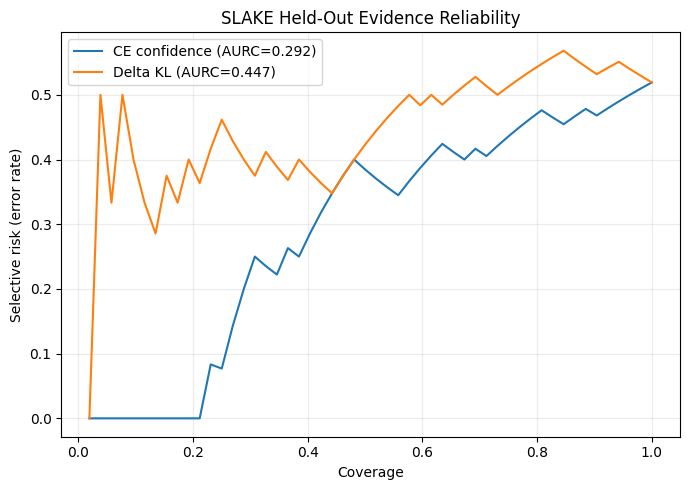


=== FILES SAVED ===
/kaggle/working/medvqa/evidence_localization/heldout_reliability_v1/heldout_reliability_results.csv
/kaggle/working/medvqa/evidence_localization/heldout_reliability_v1/heldout_reliability_summary.csv
/kaggle/working/medvqa/evidence_localization/heldout_reliability_v1/heldout_reliability_bootstrap.csv
/kaggle/working/medvqa/evidence_localization/heldout_reliability_v1/risk_coverage_heldout.png


In [73]:

from pathlib import Path
from PIL import Image, ImageDraw
import json
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# =====================================================
# 1. CONFIGURATION AND CHECKS
# =====================================================
ROOT = Path("/kaggle/working/medvqa")
SLAKE = Path(
    "/kaggle/input/datasets/buiquanghuy2801/"
    "slakedataset/Slake1.0"
)
OUT = ROOT / "evidence_localization/heldout_reliability_v1"
OUT.mkdir(parents=True, exist_ok=True)

STRICT_CSV = (
    ROOT / "evidence_localization/bbox_grounding/"
    "val_bbox_strict_v1.csv"
)
CKPT = (
    ROOT / "consistency_training/ce_only_best.pt"
)

required = [
    "model", "classifier", "preprocess_val",
    "val_q", "val_y", "device"
]
missing = [k for k in required if k not in globals()]
if missing:
    raise RuntimeError(
        "Missing original notebook objects: "
        + ", ".join(missing)
        + ". Restore the original aligned validation "
          "embeddings and labels before evaluating."
    )

df = pd.read_csv(STRICT_CSV)
assert len(df) == 52
assert df["sample_idx"].is_unique
assert df["img_name"].nunique() == 44

# Labels must use the SAME 205-class answer vocabulary
# as the checkpoint. Do not refit a new LabelEncoder.
if torch.is_tensor(val_y):
    labels = val_y.detach().cpu().numpy()
else:
    labels = np.asarray(val_y)

if labels.ndim == 2 and labels.shape[1] == 205:
    labels = labels.argmax(axis=1)

assert labels.ndim == 1 and len(labels) == 1078
assert np.issubdtype(labels.dtype, np.integer)
assert len(val_q) == 1078

# Restore CE-only, not CE continuation or PoE.
checkpoint = torch.load(
    CKPT, map_location="cpu", weights_only=True
)
classifier.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device).eval()
classifier.to(device).eval()

for net in [model, classifier]:
    for param in net.parameters():
        param.requires_grad_(False)

print("Checkpoint: CE-only")
print("Strict validation QA:", len(df))
print("Independent images:", df["img_name"].nunique())

# =====================================================
# 2. MASK GEOMETRY: MATCH IMAGE PREPROCESSING
# =====================================================
def transform_mask(mask):
    for tr in preprocess_val.transforms:
        name = type(tr).__name__

        if isinstance(tr, T.Resize):
            mask = TF.resize(
                mask, tr.size,
                interpolation=InterpolationMode.NEAREST,
                max_size=tr.max_size
            )

        elif isinstance(tr, T.CenterCrop):
            mask = TF.center_crop(mask, tr.size)

        elif name in {
            "MaybeConvertMode",
            "MaybeToTensor",
            "ToTensor",
            "Normalize",
            "ToImage",
            "ToDtype"
        }:
            continue

        else:
            raise RuntimeError(
                f"Unverified preprocessing transform: {name}"
            )

    array = np.array(mask, copy=True) > 0
    assert array.shape == (224, 224)
    return array


def translate_mask(mask, dx, dy):
    h, w = mask.shape
    output = np.zeros_like(mask)

    sx0 = max(0, -dx)
    sx1 = min(w, w - dx)
    sy0 = max(0, -dy)
    sy1 = min(h, h - dy)

    if sx0 < sx1 and sy0 < sy1:
        output[
            sy0 + dy:sy1 + dy,
            sx0 + dx:sx1 + dx
        ] = mask[sy0:sy1, sx0:sx1]

    return output


def matched_control(target, sample_idx):
    rng = np.random.default_rng(
        2026 + int(sample_idx)
    )

    ys, xs = np.where(target)
    if len(xs) == 0:
        return None

    h, w = target.shape
    area = int(target.sum())

    dx_min = -int(xs.min())
    dx_max = w - 1 - int(xs.max())
    dy_min = -int(ys.min())
    dy_max = h - 1 - int(ys.max())

    for _ in range(250):
        dx = int(rng.integers(dx_min, dx_max + 1))
        dy = int(rng.integers(dy_min, dy_max + 1))

        control = translate_mask(target, dx, dy)

        if int(control.sum()) != area:
            continue

        overlap = np.logical_and(
            target, control
        ).sum() / area

        if overlap <= 0.10:
            return control

    return None


def calculate_kl(reference, modified):
    # D_KL(reference || modified)
    eps = 1e-12
    reference = reference.clamp_min(eps)
    modified = modified.clamp_min(eps)

    return float(
        (
            reference *
            (reference.log() - modified.log())
        ).sum().item()
    )


# =====================================================
# 3. HELD-OUT INTERVENTIONS
# =====================================================
records = []
excluded = []

with torch.inference_mode():
    for _, row in tqdm(
        df.iterrows(),
        total=len(df),
        desc="Held-out evidence reliability"
    ):
        idx = int(row["sample_idx"])
        path = SLAKE / "imgs" / row["img_name"]

        with Image.open(path) as im:
            image = im.convert("RGB")

        w, h = image.size

        mask_image = Image.new("L", (w, h), 0)
        draw = ImageDraw.Draw(mask_image)

        for b in json.loads(row["bounding_boxes"]):
            x = float(b["x"])
            y = float(b["y"])
            bw = float(b["width"])
            bh = float(b["height"])

            draw.rectangle(
                (x, y, x + bw, y + bh),
                fill=255
            )

        target_np = transform_mask(mask_image)
        control_np = matched_control(target_np, idx)

        if control_np is None:
            excluded.append(idx)
            continue

        x = preprocess_val(image).unsqueeze(0).to(device)
        assert x.shape == (1, 3, 224, 224)

        target = torch.from_numpy(
            target_np.astype(np.float32)
        ).to(device)[None, None]

        control = torch.from_numpy(
            control_np.astype(np.float32)
        ).to(device)[None, None]

        assert target.sum().item() == control.sum().item()

        blurred = TF.gaussian_blur(
            x,
            kernel_size=[17, 17],
            sigma=[5.0, 5.0]
        )

        x_target = x * (1 - target) + blurred * target
        x_control = x * (1 - control) + blurred * control

        images = torch.cat(
            [x, x_target, x_control], dim=0
        )

        q = val_q[idx:idx + 1].to(device)
        q_batch = q.expand(3, -1)

        image_emb = model.encode_image(images)
        logits = classifier(image_emb, q_batch).float()

        assert logits.shape == (3, 205)

        probs = torch.softmax(logits, dim=-1)

        p0 = probs[0]
        pt = probs[1]
        pc = probs[2]

        pred_id = int(p0.argmax().item())
        true_id = int(labels[idx])

        confidence = float(p0.max().item())

        kl_target = calculate_kl(p0, pt)
        kl_control = calculate_kl(p0, pc)

        records.append({
            "sample_idx": idx,
            "img_name": row["img_name"],
            "question_type": row.get(
                "question_type", "unknown"
            ),
            "true_id": true_id,
            "pred_id": pred_id,
            "correct": int(pred_id == true_id),
            "ce_confidence": confidence,
            "target_fraction": float(
                target_np.mean()
            ),
            "kl_target": kl_target,
            "kl_control": kl_control,
            "delta_kl": kl_target - kl_control,
            "target_pred_changed": int(
                int(pt.argmax().item()) != pred_id
            ),
            "control_pred_changed": int(
                int(pc.argmax().item()) != pred_id
            )
        })

results = pd.DataFrame(records)

if len(results) == 0:
    raise RuntimeError("No valid matched controls.")

results.to_csv(
    OUT / "heldout_reliability_results.csv",
    index=False
)

pd.DataFrame({
    "excluded_sample_idx": excluded
}).to_csv(
    OUT / "excluded_no_control.csv",
    index=False
)

print("\n=== HELD-OUT INTERVENTION ===")
print("Strict QA:", len(df))
print("QA with matched control:", len(results))
print("Images:", results["img_name"].nunique())
print("Excluded:", len(excluded))
print("CE accuracy:", round(results["correct"].mean(), 4))
print("Mean target KL:", round(results["kl_target"].mean(), 6))
print("Mean control KL:", round(results["kl_control"].mean(), 6))
print("Mean Delta KL:", round(results["delta_kl"].mean(), 6))
print(
    "Fraction Delta KL > 0:",
    round((results["delta_kl"] > 0).mean(), 4)
)

# =====================================================
# 4. FAILURE PREDICTION: AUC AND AURC
# =====================================================
def aurc(y_correct, reliability):
    # Higher reliability = more likely correct.
    order = np.argsort(
        -np.asarray(reliability), kind="stable"
    )
    errors = 1 - np.asarray(y_correct)[order]
    coverage = (
        np.arange(1, len(errors) + 1) / len(errors)
    )
    risk = np.cumsum(errors) / np.arange(
        1, len(errors) + 1
    )

    return float(risk.mean()), coverage, risk


def auc_or_nan(y, score):
    if np.unique(y).size < 2:
        return np.nan
    return float(roc_auc_score(y, score))


y = results["correct"].to_numpy(dtype=int)
conf = results["ce_confidence"].to_numpy()
evidence = results["delta_kl"].to_numpy()

auc_conf = auc_or_nan(y, conf)
auc_evidence = auc_or_nan(y, evidence)

aurc_conf, coverage, risk_conf = aurc(y, conf)
aurc_evidence, _, risk_evidence = aurc(y, evidence)

print("\n=== HELD-OUT RELIABILITY ===")
print("Correct:", int(y.sum()))
print("Incorrect:", int((1-y).sum()))
print("AUC CE confidence:", round(auc_conf, 6))
print("AUC Delta KL:", round(auc_evidence, 6))
print("AURC CE confidence:", round(aurc_conf, 6))
print("AURC Delta KL:", round(aurc_evidence, 6))
print(
    "Delta AURC (evidence - confidence):",
    round(aurc_evidence - aurc_conf, 6)
)

# =====================================================
# 5. IMAGE-CLUSTER PAIRED BOOTSTRAP
# =====================================================
image_groups = [
    group for _, group in results.groupby("img_name")
]

rng = np.random.default_rng(2026)
bootstrap = []

for _ in range(5000):
    selected = rng.integers(
        0, len(image_groups),
        size=len(image_groups)
    )

    sample = pd.concat(
        [image_groups[j] for j in selected],
        ignore_index=True
    )

    yy = sample["correct"].to_numpy(dtype=int)
    cc = sample["ce_confidence"].to_numpy()
    ee = sample["delta_kl"].to_numpy()

    if np.unique(yy).size < 2:
        continue

    auc_delta = (
        roc_auc_score(yy, ee)
        - roc_auc_score(yy, cc)
    )

    aurc_delta = (
        aurc(yy, ee)[0] - aurc(yy, cc)[0]
    )

    bootstrap.append({
        "delta_auc": auc_delta,
        "delta_aurc": aurc_delta,
        "delta_kl_mean": sample["delta_kl"].mean()
    })

boot = pd.DataFrame(bootstrap)

print("\n=== IMAGE BOOTSTRAP ===")

for metric in [
    "delta_auc", "delta_aurc", "delta_kl_mean"
]:
    lo, hi = boot[metric].quantile(
        [0.025, 0.975]
    )

    print(
        f"{metric}: 95% CI "
        f"[{lo:+.6f}, {hi:+.6f}]"
    )

# =====================================================
# 6. RISK-COVERAGE CURVE
# =====================================================
plt.figure(figsize=(7, 5))

plt.plot(
    coverage, risk_conf,
    label=f"CE confidence (AURC={aurc_conf:.3f})"
)
plt.plot(
    coverage, risk_evidence,
    label=f"Delta KL (AURC={aurc_evidence:.3f})"
)

plt.xlabel("Coverage")
plt.ylabel("Selective risk (error rate)")
plt.title("SLAKE Held-Out Evidence Reliability")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plot_path = OUT / "risk_coverage_heldout.png"
plt.savefig(plot_path, dpi=180)
plt.show()

# =====================================================
# 7. SAVE SUMMARY FOR IEEE PAPER
# =====================================================
summary = pd.DataFrame([{
    "qa": len(results),
    "images": results["img_name"].nunique(),
    "ce_accuracy": results["correct"].mean(),
    "mean_delta_kl": results["delta_kl"].mean(),
    "auc_confidence": auc_conf,
    "auc_delta_kl": auc_evidence,
    "aurc_confidence": aurc_conf,
    "aurc_delta_kl": aurc_evidence,
    "delta_auc": auc_evidence - auc_conf,
    "delta_aurc": aurc_evidence - aurc_conf
}])

summary.to_csv(
    OUT / "heldout_reliability_summary.csv",
    index=False
)

boot.to_csv(
    OUT / "heldout_reliability_bootstrap.csv",
    index=False
)

print("\n=== FILES SAVED ===")
print(OUT / "heldout_reliability_results.csv")
print(OUT / "heldout_reliability_summary.csv")
print(OUT / "heldout_reliability_bootstrap.csv")
print(plot_path)


In [74]:

from pathlib import Path
import torch
import pandas as pd

ROOT = Path("/kaggle/working/medvqa")

print("=== CHECKPOINT ===")

ckpt_path = (
    ROOT / "consistency_training/ce_only_best.pt"
)

print("Exists:", ckpt_path.exists())

if ckpt_path.exists():
    ckpt = torch.load(
        ckpt_path,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint keys:", list(ckpt.keys()))

    for key, value in ckpt.items():
        if isinstance(value, dict):
            print(f"\n{key}:")
            for name, tensor in list(value.items())[:18]:
                if hasattr(tensor, "shape"):
                    print(" ", name, tuple(tensor.shape))
                else:
                    print(" ", name, type(tensor).__name__)

print("\n=== CACHED EMBEDDINGS ===")

if ROOT.exists():
    for path in ROOT.rglob("*"):
        if not path.is_file():
            continue

        name = path.name.lower()

        if (
            path.suffix in {".pt", ".pth", ".npy", ".npz"}
            and any(
                term in name
                for term in [
                    "val", "embed", "label",
                    "feature", "cache"
                ]
            )
        ):
            print(path)

print("\n=== VALIDATION CSV ===")

val_csv = Path(
    "/kaggle/input/notebooks/"
    "buiquanghuy2801/01-medvqa-baseline/"
    "slake_splits/validation.csv"
)

print("Exists:", val_csv.exists())

if val_csv.exists():
    val = pd.read_csv(
        val_csv, keep_default_na=False
    )
    print("Rows:", len(val))
    print("Columns:", val.columns.tolist())

print("\n=== STRICT BBOX ===")

bbox_csv = (
    ROOT / "evidence_localization/"
    "bbox_grounding/val_bbox_strict_v1.csv"
)

print("Exists:", bbox_csv.exists())

if bbox_csv.exists():
    bbox = pd.read_csv(bbox_csv)
    print("QA:", len(bbox))
    print("Images:", bbox["img_name"].nunique())

print("\n=== ENVIRONMENT ===")

print("CUDA available:", torch.cuda.is_available())

try:
    import open_clip
    print("open_clip: installed")
except ImportError:
    print("open_clip: missing")

print("\nDIAGNOSTIC COMPLETE")


=== CHECKPOINT ===
Exists: True
Checkpoint keys: ['model_state_dict', 'experiment', 'best_epoch', 'best_val_accuracy', 'lambda_kl']

model_state_dict:
  classifier.0.weight (512, 1536)
  classifier.0.bias (512,)
  classifier.3.weight (256, 512)
  classifier.3.bias (256,)
  classifier.6.weight (205, 256)
  classifier.6.bias (205,)

=== CACHED EMBEDDINGS ===
/kaggle/working/medvqa/biomedclip_embeddings.pt
/kaggle/working/medvqa/test_evaluation/test_embeddings.pt
/kaggle/working/medvqa/vgcl/train_counterfactual_cache.pt
/kaggle/working/medvqa/consistency_cache/validation_questions.pt
/kaggle/working/medvqa/consistency_cache/validation_images.pt

=== VALIDATION CSV ===
Exists: True
Rows: 1078
Columns: ['img_id', 'img_name', 'question', 'answer', 'q_lang', 'location', 'modality', 'answer_type', 'base_type', 'content_type', 'triple', 'qid', 'original_split']

=== STRICT BBOX ===
Exists: True
QA: 52
Images: 44

=== ENVIRONMENT ===
CUDA available: True
open_clip: installed

DIAGNOSTIC COMPLETE

In [75]:

from pathlib import Path

roots = [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]

patterns = {
    "CE checkpoint": "ce_only_best.pt",
    "Strict bbox validation": "val_bbox_strict_v1.csv",
    "Validation embedding cache": "val_embeddings.pt",
    "Test embedding cache": "test_embeddings.pt",
    "PoE checkpoint": "poe_best.pt",
}

found = {}

print("=== SEARCH RESTORED KAGGLE ARTIFACTS ===")

for label, filename in patterns.items():
    matches = []

    for root in roots:
        if root.exists():
            matches.extend(
                str(path)
                for path in root.rglob(filename)
                if path.is_file()
            )

    found[label] = matches

    print(f"\n{label}:")
    if matches:
        for path in matches[:10]:
            print(" FOUND:", path)
    else:
        print(" NOT FOUND")

print("\n=== RECOVERY SUMMARY ===")
print(
    "CE checkpoint available:",
    bool(found["CE checkpoint"])
)
print(
    "Grounding benchmark available:",
    bool(found["Strict bbox validation"])
)

if (
    found["CE checkpoint"]
    and found["Strict bbox validation"]
):
    print("\nREADY TO RESTORE MODEL AND RUN VALIDATION")
else:
    print("\nREQUIRED ARTIFACTS STILL MISSING")
    print("Attach the saved notebook output or dataset.")


=== SEARCH RESTORED KAGGLE ARTIFACTS ===

CE checkpoint:
 FOUND: /kaggle/working/medvqa/consistency_training/ce_only_best.pt

Strict bbox validation:
 FOUND: /kaggle/working/medvqa/evidence_localization/bbox_grounding/val_bbox_strict_v1.csv

Validation embedding cache:
 NOT FOUND

Test embedding cache:
 FOUND: /kaggle/working/medvqa/test_evaluation/test_embeddings.pt

PoE checkpoint:
 FOUND: /kaggle/working/medvqa/poe_baseline/poe_best.pt

=== RECOVERY SUMMARY ===
CE checkpoint available: True
Grounding benchmark available: True

READY TO RESTORE MODEL AND RUN VALIDATION


In [76]:

from pathlib import Path

names = [
    "ce_only_best.pt",
    "poe_best.pt",
    "val_bbox_strict_v1.csv",
    "train_bbox_intervention_results_v1.csv",
]

print("=== KAGGLE ARTIFACT RECOVERY CHECK ===")

for name in names:
    matches = []

    for root in [Path("/kaggle/input"),
                 Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob(name))

    print(f"\n{name}:")
    if matches:
        for p in matches:
            print(" FOUND:", p)
            print(" SIZE:", round(p.stat().st_size / 1024**2, 2), "MB")
    else:
        print(" NOT FOUND")


=== KAGGLE ARTIFACT RECOVERY CHECK ===

ce_only_best.pt:
 FOUND: /kaggle/working/medvqa/consistency_training/ce_only_best.pt
 SIZE: 3.71 MB

poe_best.pt:
 FOUND: /kaggle/working/medvqa/poe_baseline/poe_best.pt
 SIZE: 3.71 MB

val_bbox_strict_v1.csv:
 FOUND: /kaggle/working/medvqa/evidence_localization/bbox_grounding/val_bbox_strict_v1.csv
 SIZE: 0.01 MB

train_bbox_intervention_results_v1.csv:
 FOUND: /kaggle/working/medvqa/evidence_guided_poe/train_bbox_intervention_results_v1.csv
 SIZE: 0.06 MB


In [77]:

from pathlib import Path
import shutil

root = Path("/kaggle/working/medvqa")
backup = Path("/kaggle/working/medvqa_full_backup")

assert root.exists(), "Missing medvqa output folder"

archive = shutil.make_archive(
    str(backup),
    "zip",
    root_dir="/kaggle/working",
    base_dir="medvqa"
)

print("Backup created:", archive)
print(
    "Backup size:",
    round(Path(archive).stat().st_size / 1024**2, 2),
    "MB"
)

print("\n=== IMPORTANT ARTIFACTS ===")
for name in [
    "ce_only_best.pt",
    "biomedclip_embeddings.pt",
    "val_bbox_strict_v1.csv",
    "train_bbox_intervention_results_v1.csv"
]:
    matches = list(root.rglob(name))
    print(
        name,
        "FOUND" if matches else "MISSING"
    )


Backup created: /kaggle/working/medvqa_full_backup.zip
Backup size: 76.3 MB

=== IMPORTANT ARTIFACTS ===
ce_only_best.pt FOUND
biomedclip_embeddings.pt FOUND
val_bbox_strict_v1.csv FOUND
train_bbox_intervention_results_v1.csv FOUND
